# Notebook 15: An Index Book, Deals, and a Factor That Trends

**References:** MacKinlay, A. C. and Ramaswamy, K. (1988). Index-futures arbitrage and the behavior of stock index futures prices. *Review of Financial Studies* 1(2), 137-158. Stoll, H. R. and Whaley, R. E. (1990). The dynamics of stock index and stock index futures returns. *Journal of Financial and Quantitative Analysis* 25(4), 441-468. Mitchell, M. and Pulvino, T. (2001). Characteristics of risk and return in risk arbitrage. *Journal of Finance* 56(6), 2135-2175. Jegadeesh, N. and Titman, S. (1993). Returns to buying winners and selling losers: implications for stock market efficiency. *Journal of Finance* 48(1), 65-91. Moskowitz, T. J. and Grinblatt, M. (1999). Do industries explain momentum? *Journal of Finance* 54(4), 1249-1290. Moskowitz, T. J., Ooi, Y. H. and Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics* 104(2), 228-250.

Notebooks 12 and 13 traded what the market of `lob/statarb.py` has: gaps between books that close, baskets that revert, scores that rank the books. That market lacks three things that real ones have, and each is a reason to trade that these books do not give. This notebook adds them one at a time, each **off by default** (with it off, notebooks 10 to 14 give the same numbers as before, to the tick), and never two together:

1. **An index book** (section 1). A thirteenth book whose fair value is the other books' fair values added up, with weights, and a premium of its own. The index and its books make one relation that the factors are not in, so a trader that buys the index and sells the books when the index is cheap, and the other way when it is dear, bets that the premium closes (index arbitrage: MacKinlay and Ramaswamy 1988; Stoll and Whaley 1990). The dial is the premium's volatility, `index_volatility`.
2. **Stock deals** (section 2). An acquirer offers shares for a target's. While the deal is on, the target's price moves from where the announcement put it toward the offer's worth, and the deal may break, when the target falls back with a jump. A trader long the target and short the acquirer collects the gap closing in many small gains and loses the jump when a deal breaks (Mitchell and Pulvino 2001). The market prices a chance `priced` that a deal breaks. The dial is the true chance, `breaks`, and when it is the priced one there is nothing to earn from the drift on average.
3. **A factor that trends** (section 3). The factors of notebooks 12 and 13 are random walks and the books' own parts revert, so nothing continues, and notebook 13's momentum trader was a control that did not pay. Here the factors have a drift, in ticks a unit of time, that wanders around 0 with a half-life of 500 units: what rose tends to go on rising for a while. Momentum (Jegadeesh and Titman 1993; Moskowitz and Grinblatt 1999 for industries; Moskowitz, Ooi and Pedersen 2012 for trends) can pay here only by holding a factor. The dial is the drift's standard deviation, `trend`.

**Each section asks the same two things.** How far must the dial be turned before the trade pays its costs? And what does its P&L look like when it does: steady, skewed, riding a factor? The dial starts where there is nothing to find, which is the control. For the index that takes care: the order flow's own market orders in the index book make a premium even at `index_volatility` 0, so the section labels its axis by the premium it measures, in ticks of a basket, and has a strict control with the books' impact off as well. The three dials are in three units (ticks of a basket, a probability, ticks of drift a unit of time), so their break-evens are not on one scale, and each belongs to its trader's size and costs.

**The market** is notebook 12's: twelve books whose fair values share common factors through a table of loadings, each with a part of its own that mean-reverts and is moved by order flow, and traders around each fair value whose orders the mids follow. The tables are the same, *sectors* (a market factor and three sector factors) and *mixed* (three factors, with loadings in no order). The index book is a thirteenth, the last; a deal is between two of the twelve; a trend is a drift in the factors. Every trader is alone in its market, with market orders, and pays what crossing the spreads costs in the books.

**How to read it.**

- *Seeds.* Every setting (a trader's, the dial's values, the burn) was chosen on seeds 1 to 8 and then held fixed along the dial. The tables report seeds 101 to 112 (101 to 108 where a table varies one thing), which no setting was chosen on. Notebook 13 reports on the same seeds, so where a row here is a row there (the same trader, market, seeds and burn) it is the same runs and gives the same number: that is not a replication.
- *Paired by seed.* Two rows of one table are on the same seeds, and in one seed they share the market's factors and shocks, though not its order flow once a trader's orders move it. A difference between rows is taken seed by seed, and a table says how many seeds it was positive on. A standard error is the standard deviation across seeds (its variance with one fewer than the number of seeds in the denominator) over the square root of how many there are.
- *P&L* is after costs, in ticks times lots, over a span of 20,000 units of time (unless a section says otherwise) after a burn that is the same for every row of a table. Rows of different sections are not comparable: a lot of the sum index is twelve books' worth, a basket of the full replication holds thirteen legs, the deal trader holds two legs a deal and several deals at once, the momentum trader holds all twelve books. So no level of P&L in one section belongs beside another's, nor does a cost a lot. The index rows quote what an entry or a basket costs, never a lot.
- *Before costs* is P&L with what crossing the spreads cost added back. It is not an edge in any section: it holds what the mids' bounce around their fair values pays a trader that enters when a mid is off, and its own impact on the mid it is marked at.
- *Two risk figures.* `risk_adjusted` is the mean change of P&L in a unit of time over the standard deviation of those changes. `risk_adjusted_long` is the same mean over the standard deviation of the changes over stretches of 100 units, over the square root of 100. They differ when a position continues, as a factor's drift does: the one-unit figure does not see the risk of holding it for long, and flatters the holder. Neither shows a skew; the deals section does that from the deals themselves. `factor_part` is what the factors made of the P&L (what it held of each, a unit ago, times that factor's move since); the rest is P&L less that, and is not named for its parts.
- *The backtest.* Each section has the scorecard and signal chart of one trader on seed 101, which no setting was chosen on, and then says what the section cannot show.

**In short.** The figures below are means over eight or twelve seeds (101 and up) of one simulated market, or break-evens found from such means, with the traders' settings chosen beforehand on seeds 1 to 8. A bracket gives the standard error over seeds and the number of seeds on which the figure was positive.

**Index.** The sum index breaks even at the lowest point of the dial, where the premium's standard deviation is 14.7 ticks of a basket (+7, se 24, 5 of 8 seeds positive), and is positive on every seed from 20.2 (+467, se 42). The same position through the 1/12 index, an entry of which costs 69.6 to 83.6 against 40.5 to 45.2, crosses 0 at 32.5 ticks (31.6 to 33.4, 5% to 95%); at the top of the dial it made 791 (se 259) less before costs than the sum on the dial's eight seeds and makes 243 (se 246) more on eight others, so that is not a finding, though its gap after costs is in all sixteen seeds (-1,525, se 169). The twelve books' legs cost about 930 (se 107) at the chosen point and cut the risk over 100 units from 6.91 to 1.92, and a hedge of three books beats the twelve by +567 (se 77, 8 of 8 seeds) after costs, from +740 (se 147) before costs on as many entries, and not with the own parts' shocks off (-90, se 50, 3 of 8 seeds); in fair values with no trader the sample's spread has a standard deviation of 44.1 ticks of a basket against the full replication's 32.0 with the shocks on, and 32.1 against 31.8 with them off.

**Deals.** At a fair price, a true chance of a break of 0.40, the deal trader makes -2,379 (se 348, 0 of 12 seeds positive); it breaks even at a true chance of about 0.31 (0.310 from a line through the seven means, 95% 0.290 to 0.331; 0.316 from the same line against the counted share of deals broken, 0.307 to 0.324, a share that leans 0.003 to 0.004 toward the broken from 0.40 to 0.20 against the deals with a kept record, and 0.312 against the share among those deals, 0.304 to 0.320; 0.311 and 0.308 from the deals' own lot pairs). At 0.20 it makes +2,747 (se 346, 12 of 12 seeds) in gains of +18.57 a lot pair and, in 19.6% of deals, losses of 41.72. At a fair price deals cost a pairs trader 3,659 (se 344, 8 of 8 seeds), and a reader that keeps out of the target until the step has left its window makes 692 less than the blind trader (se 164); the reader that keeps out for the deal's life is not separated from the blind trader on each trader's own pairs (+429, se 256, at 0.20) and is ahead of it on every seed on one set of pairs, those of the world of 0.40 held in the market of 0.20 (+617, se 193, 8 of 8 seeds), where its lead in the targets' books while the deals are on is +885 (se 316) against a bet of 873 by arithmetic on the lots the blind trader holds on those pairs, and everywhere else it is 268 behind (se 257, not separated from 0), so that the lead in the targets' books is how reading the news pays in this market; those pairs are another world's and a trader's own do not separate it (+429, se 256, of which +693, se 295, is in the targets' books against a bet of 694), so it is a lead and not a finding that reading the news pays a trader.

**Trend.** Momentum with the dollar alone taken out breaks even at a drift of 0.0269 ticks a unit of time in the sectors market (0.0251 to 0.0289, 5% to 95%), a drift that is 22.5% of the variance of a factor's move over the look back, and at 0.0364 in the mixed market (0.0352 to 0.0374). It makes -4,094 (se 309) with no trend and +7,359 (se 516) at 0.05, nearly all of it the factor part; with three estimated factors taken out it loses on every seed (-4,574, se 230), and reversal makes -11,289 (se 1,250).

**What the three have in common.** Each trade loses where the dial says there is nothing to find and pays only once the dial is turned some way from there, and how far depends in part on what the trade costs: through the 1/12 book, where an entry costs 71.4 and not 40.6 at the chosen point and the trader's own orders push the premium twelve times as far (by arithmetic from the settings), the index needs 32.5 ticks of premium and not about 14.7; 5.00 of the deal trader's edge of 5.3 ticks a lot pair at its break-even (60 x (0.40 - 0.311), at the deals' own figure) is the cost of the lot pair, and the rest, about 0.3, is what a lot pair loses before costs at a fair price; and 2,105 of the rest of -4,070 that momentum makes apart from its factor part with no trend is costs. The three dials are in three units, so the three break-evens are not on one scale.

In [1]:
import json
import math
import re
import sys
import time
from typing import NamedTuple

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from IPython.display import display
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.statarb import (
    BookMarket,
    FactorValues,
    RelationTrader,
    mixed_loadings,
    pairs_by_distance,
    score_holdings,
    sector_loadings,
)

set_style()
plt.close(plt.figure())  # starts the inline backend, so that a scorecard (a plain Figure) shows even before any chart
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

# Every seed and every length of time below comes from a name defined in this cell, so that a smoke copy can shrink
# them in one place (smoke.py rewrites the five lines that say SEEDS, FEW, MORE, SMOKE and SMOKE_SHARE).
SEEDS = range(101, 113)  # none of the settings was chosen on these: they report
FEW = range(101, 109)  # for the tables that vary one thing
MORE = range(113, 137)  # more seeds for the trend section's route that has no books and so costs next to nothing
CARD_SEED = SEEDS[0]
EVERY = 5.0  # a trader decides this often, in units of time, unless it says otherwise
SMOKE = False  # True in the smoke copy, which runs on seeds 1 and 2 and a share of each length of time
SMOKE_SHARE = 1.0

LENGTHS = {}  # name -> (the length used, the length of the real run), filled by length() as the cells run


def length(name, full, least=0.0):
    # A span, a burn or a long run, in units of time, under a name. `full` here; in the smoke copy SMOKE_SHARE of it,
    # but not under `least`, which is what the section needs for its trader to trade at all (see burn_for).
    assert full >= least, f'{name}: {full:,.0f} units is under the least it declares, {least:,.0f}'
    used = max(least, round(full * SMOKE_SHARE)) if SMOKE else full
    LENGTHS[name] = (used, full)
    return float(used)


def burn_for(name, full, *makers, margin=20.0):
    # A burn that is `full` here and, in the smoke copy, no less than the longest warm-up of these traders (each given
    # as the function that makes it) and `margin` more: so that a trader chosen from a long formation still trades.
    return length(name, full, max(getattr(make(), 'warm_up', 0.0) for make in makers) + margin)


SPAN = length('span', 20_000.0, least=2_000.0)  # what every table counts, after its burn

# Each market's loadings: twelve books in three sectors (a market factor and three sector factors), or in no order.
LOADINGS = {'sectors': sector_loadings(3, 4), 'mixed': mixed_loadings(12, 3, seed=3)}


def market_of(name, **settings):
    # A function that makes the fair values of one of the markets, with the settings of this section's dial: a
    # partial, so that a joblib worker can make its own. Index, deals and trend are settings (index=, deals=, trend=).
    return partial(FactorValues, LOADINGS[name], **settings)


def pairs_by(kind=RelationTrader, **settings):
    # Notebook 13's pairs by distance (eight pairs, 2.5 lots of each, a window of 400 decisions, entering at a z-score
    # of 2, choosing from the last 2,000 decisions), as a function that makes one, with some settings changed. `kind`
    # may be NewsAwareTrader or any other RelationTrader.
    made = dict(size=2.5, window=400, entry=2.0, interval=EVERY, formation=2_000)
    return partial(kind, choose=partial(pairs_by_distance, count=8), **{**made, **settings})


# Notebook 13's burn for every trader of its first table: the longest warm-up there, which is the pairs' (a formation of
# 2,000 decisions of 5 units, and a little), and 400 units more. A row of this notebook that is a row of notebook 13
# (its pairs trader in its market, on its seeds) is the same run only from exactly this burn: a literal 10,465 would be
# another window by 0.03 units.
PAIRS_BURN = burn_for('pairs burn', pairs_by()().warm_up + 400.0, pairs_by())


def notebook_13_row(label, market='sectors'):
    # What notebook 13's saved output printed for a row of its first table, the line that holds `label` in the block of
    # `market`: P&L, standard error, seeds positive and seeds, in whole ticks. None if the notebook is not there (the
    # kernel starts in notebooks/), has no saved output or has no such row.
    try:
        notebook = json.load(open('13_more_long_short_strategies.ipynb'))
    except FileNotFoundError:
        return None
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            current = None
            for line in ''.join(out.get('text', '')).splitlines():
                if line.split(' ', 1)[0] in LOADINGS:  # a line that starts a market's block of the table
                    current = line.split(' ', 1)[0]
                if current == market and label in line:
                    found = re.search(r'\s(-?[\d.]+)\s+([\d.]+)\s+(\d+) of (\d+)\s', line.split(label, 1)[1] + ' ')
                    if found:
                        return float(found.group(1)), float(found.group(2)), int(found.group(3)), int(found.group(4))
    return None


def run_one(make_fair, make_trader, seed, burn, span, extra=None):
    # One trader alone in one market on one seed, scored over `span` after `burn`. `extra(market, trader)` may return
    # more columns, read after the run.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    trader = make_trader()
    market = BookMarket(make_fair(), seed=seed, traders=(trader,))
    started = time.time()
    score = score_holdings(market, trader, burn, span)
    score['rest'] = score['pnl'] - score['factor_part']  # everything but the factors; not named for its parts
    score.update(pushed=float(market.fair.pushed), warm_up=float(getattr(trader, 'warm_up', 0.0)))
    score['secs'] = time.time() - started
    if extra is not None:
        score.update(extra(market, trader))
    return {'seed': seed, **score}


def run_rows(rows, seeds, burn, span=SPAN, extra=None):
    # rows: {name: (make_fair, make_trader)}, two functions with no arguments (partials, for the workers). Every row
    # on every seed, the same span after the same burn: one line a run, with the name in the column 'row'.
    jobs = [(name, seed) for name in rows for seed in seeds]
    runs = Parallel(n_jobs=-1)(delayed(run_one)(*rows[name], seed, burn, span, extra) for name, seed in jobs)
    frame = pd.DataFrame([{'row': name, **run} for (name, _), run in zip(jobs, runs, strict=True)])
    cut = frame[frame.warm_up > burn].row.unique()
    assert not len(cut), f'the burn of {burn:,.0f} cuts into the warm-up of {list(cut)}'
    return frame


MEANS = (
    'before_costs',
    'costs',
    'lots',
    'entries',
    'gross',
    'exposure',
    'deviation',
    'deviation_long',
    'risk_adjusted',
    'risk_adjusted_long',
    'factor_part',
    'rest',
)
COLUMNS = ['pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'lots', 'cost_a_lot', 'cost_an_entry']
COLUMNS += ['gross', 'exposure', 'deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']
COLUMNS += ['factor_part', 'rest']
FORMATS = {  # by column, without any '_se' or '_positive' on it
    'pnl': '+,.0f',
    'se': ',.0f',
    'before_costs': ',.0f',
    'costs': ',.0f',
    'entries': ',.1f',
    'lots': ',.0f',
    'cost_a_lot': '.2f',
    'cost_an_entry': '.1f',
    'gross': '.1f',
    'exposure': '.2f',
    'deviation': '.2f',
    'deviation_long': '.2f',
    'risk_adjusted': '.3f',
    'risk_adjusted_long': '.3f',
    'factor_part': '+,.0f',
    'rest': '+,.0f',
}


def se_of(x):
    return x.std() / math.sqrt(len(x))  # the standard deviation over the seeds (ddof 1), over their root


def table_of(frame, by='row', also=()):
    # The mean of every column over the seeds, a line for each row (or each of `by`, a list for market and row), with
    # the standard error of its P&L, how many seeds it made money on, and what a lot and an entry cost.
    columns = [*MEANS, *(c for c in also if c not in MEANS)]
    table = frame.groupby(by, sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', se_of),
        positive=('pnl', lambda p: int((p > 0).sum())),
        seeds=('pnl', 'size'),
        **{c: (c, 'mean') for c in columns},
    )
    table['cost_a_lot'] = table.costs / table.lots.replace(0, np.nan)
    table['cost_an_entry'] = table.costs / table.entries.replace(0, np.nan)
    return table


def formatter(spec):
    return lambda x: format(x, spec)


def shown(table, *drop, keep=None, add=(), **formats):
    # A table of table_of (or paired_table) as text: the columns of COLUMNS, less `drop`, and those of `add`; or only
    # the list `keep`. Each in its own format (`formats` adds or changes one, by column, as a format spec); positive
    # as 'k of n'.
    keep = [c for c in (COLUMNS if keep is None else keep) + list(add) if c in table.columns and c not in drop]
    spec = {**FORMATS, **formats}
    out = table[keep].copy()
    cells = {}
    for column in keep:
        if column.endswith('positive'):
            out[column] = [f'{k} of {n}' for k, n in zip(table[column], table.seeds, strict=True)]
        else:
            cells[column] = formatter(spec.get(column.removesuffix('_se'), ',.2f'))
    return out.to_string(formatters=cells)


class Paired(NamedTuple):
    mean: float
    se: float
    positive: int
    seeds: int


def said(r):
    # '+1,234 (se 56, 8 of 8 seeds positive)' for a line of table_of or paired_table, or for a Paired.
    mean = r.mean if isinstance(r, Paired) else r.pnl
    return f'{mean:+,.0f} (se {r.se:.0f}, {int(r.positive)} of {int(r.seeds)} seeds positive)'


def paired(frame, one, other, column='pnl', by='row'):
    # One row less another, seed by seed: (mean, se, positive, seeds), the mean, its standard error over the seeds,
    # the seeds above 0 and how many seeds. Refuses two rows that are not on the same seeds: then it is not paired.
    a = frame[frame[by] == one].set_index('seed')[column]
    b = frame[frame[by] == other].set_index('seed')[column]
    if a.empty or b.empty or not (a.index.is_unique and b.index.is_unique) or set(a.index) != set(b.index):
        raise ValueError(f'{one!r} and {other!r} are not on the same seeds: {sorted(a.index)} and {sorted(b.index)}')
    d = a - b.loc[a.index]
    return Paired(float(d.mean()), float(se_of(d)), int((d > 0).sum()), len(d))


def paired_table(frame, pairs, *also, by='row'):
    # pairs: {label: (one, other)}. A line a label: the P&L of one less the other (pnl, se, positive), and for each
    # column of `also` its difference (c, c_se, c_positive).
    lines = {}
    for label, (one, other) in pairs.items():
        got = paired(frame, one, other, 'pnl', by)
        line = {'pnl': got.mean, 'se': got.se, 'positive': got.positive, 'seeds': got.seeds}
        for column in also:
            more = paired(frame, one, other, column, by)
            line.update({column: more.mean, f'{column}_se': more.se, f'{column}_positive': more.positive})
        lines[label] = line
    return pd.DataFrame.from_dict(lines, orient='index')


def shown_paired(table, *columns, lead=('pnl', 'se', 'positive'), **formats):
    # A table of paired_table as text: P&L, its standard error and the seeds positive, then each of `columns` (those
    # given to paired_table as `also`) and its standard error, each in the format of its column.
    return shown(table, keep=[*lead, *(x for c in columns for x in (c, f'{c}_se'))], **formats)


def ran(*frames, label=''):
    # How many runs the frames hold (frames of run_rows, or any with a column of seconds a run) and the core-minutes
    # they took.
    print(f'{label}{sum(len(f) for f in frames)} runs, {sum(f.secs.sum() for f in frames) / 60:.1f} core-minutes.')


def first_rise(ys):
    # Where the line through `ys`, point to point, first goes from 0 or below to above 0: the index of the point before
    # it and how far along the way to the next it crosses (0 to 1, by linear interpolation); (-1, nan) if it never does.
    for i in range(len(ys) - 1):
        if ys[i] <= 0 < ys[i + 1]:
            return i, -ys[i] / (ys[i + 1] - ys[i])
    return -1, np.nan


FIGSIZE, FIGSIZE_WIDE = (10.0, 5.0), (12.5, 4.5)  # a figure of one panel, and of two side by side


# Ticks x lots: more than the cards of the index and trend sections hold at their most (each prints its peak as a
# multiple of it). A card of the deals section holds more at once, with several deals on: it takes CAPITAL_DEALS.
CAPITAL = 150_000.0
CAPITAL_DEALS = 200_000.0


class Record(NamedTuple):
    backtest: Backtest
    prices: pd.DataFrame  # the mids at each decision, a column a book
    weights: pd.DataFrame  # what the trader held after each decision, valued at those mids, over the capital
    signals: list  # trader.signal() at each decision: None before it has one
    days: pd.DatetimeIndex  # a card day is a decision
    cost_bp: float
    times: tuple  # the time of each decision


def record_of(trader, capital=CAPITAL):
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / capital, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * capital
    cost_bp = trader.spread_paid / turnover * 1e4
    backtest = Backtest(weights, returns, cost_bp=cost_bp)
    return Record(backtest, prices, weights, signals[first:], days, cost_bp, times[first:])


def recorded(make_fair, make_trader, burn, span=SPAN, seed=None):
    # One run of a trader that keeps a record of its decisions, to burn + span: the trader, what its fills made, and
    # the market (its fair.ended and fair.deals say what the deals did). The seed is the card's unless given.
    seed = CARD_SEED if seed is None else seed
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    trader = make_trader()
    trader.record = True
    market = BookMarket(make_fair(), seed=seed, traders=(trader,))
    while market.time < burn + span:
        market.step()
    return trader, trader.value(market.marks()), market


def most_changed(trader):
    held = np.array([step[2] for step in trader.history])
    return int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often


def around(trader):
    # Lines at the level it enters at on either side of 0, and at the level it leaves at.
    enter, leave = trader.levels
    return [(enter, 'C3', 'short it'), (-enter, 'C2', 'long it'), (leave, 'C7', 'exit')]


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    book,
    *,
    relation=0,
    signal=None,
    capital=CAPITAL,
    asset='one of the twelve books it trades',
    per_unit=5,
    span=SPAN,
    start=200,
    end=900,
):
    # The scorecard and the signal chart of one recorded run (see recorded). `book` is the one the chart shows, given
    # by the caller: the index card's is 12, the index book. The signal on the chart is the trader's own, its
    # `relation`-th entry, unless `signal` is given: an array with a value for each decision of the record, or a
    # function of the Record that returns one (a deals card rebuilds one deal's gap from the record's mids and times).
    rec = record_of(trader, capital)
    bt, prices, weights, signals, days, cost_bp, times = rec
    note = (
        f'Simulated: {setting}. A card day is one decision of the trader, {per_unit} unit'
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with market "
        f'orders in the books it changes. The record holds what it held after each decision, valued at the mids just '
        f"before its orders, on capital of {capital:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the record's "
        f'turnover, add up to what crossing the spreads cost. Its fills '
        f"made {fills:+,.0f}, this record {bt.net.sum() * capital:+,.0f}. The record runs from the trader's first "
        f'order, at time {times[0]:,.0f}, to the end of the run, at {times[-1]:,.0f}; the tables count only the last '
        f'{span:,.0f} units, so their figure for this trader differs.'
    )
    # The library's note on the circles, which follows this footnote, is for a backtest that fills after it decides.
    chart_note = (
        f'The position is what the trader held after each decision, in ticks x lots: the weight times {capital:,.0f} '
        f"of capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        f"are not marked. The note on the circles that follows is the library's, for a backtest that fills after it "
        f"decides; here the record holds the position after each decision's own orders, so a circle sits on the step "
        f'it caused.'
    )
    display(scorecard(bt, strategy, detail=detail, capital=capital, title=title, footnote=note))
    name = f'book {book}'
    if callable(signal):
        signal = signal(rec)
    if signal is None:
        signal = [np.nan if s is None or len(s) <= relation else s[relation] for s in signals]
    signal = pd.Series(np.asarray(signal, dtype=float), index=days)
    held = weights[name]
    side, before = np.sign(held), np.sign(held).shift(fill_value=0)
    end = min(end, len(days) - 1)  # a smoke copy has fewer decisions than the card's window
    start = min(start, max(end - 100, 0))
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=capital,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[start],
        end=days[end],
        footnote=chart_note,
        asset_name=asset,
    )
    plt.show()
    gross = weights.abs().sum(axis=1)  # what it holds, as a multiple of the capital
    got = {'fills': fills, 'record': bt.net.sum() * capital, 'peak': gross.max(), 'above_one': (gross > 1).mean()}
    print(
        f"{title}: its fills made {got['fills']:+,.0f} and the record {got['record']:+,.0f}; it holds at most "
        f"{got['peak']:.2f} times the capital of {capital:,.0f}, and more than it on {got['above_one']:.1%} of days."
    )
    return got

## 1. An Index Book

**Does a premium that closes pay for the trade that bets on it?** The market gets a thirteenth book, book 12, an index of the other twelve. Its fair value is theirs added up with weights, plus a *premium* of its own: a mean-reverting part, with the books' half-life of 50 units, whose volatility is the dial, `index_volatility`. The index carries the factors the books carry, in the proportions of its weights, so the index against its twelve books is a relation that the factors are not in. Its spread is the premium and the books' own parts, weighted, and a trader that buys the index and sells the books when the spread is low, and does the opposite when it is high, bets that the premium closes (index arbitrage: MacKinlay and Ramaswamy 1988; Stoll and Whaley 1990).

**Two conventions for the index.** Both are a book like the others, only larger by the sum of its weights.

- *The sum.* The weights are 1. A *basket* is one lot of the index against one lot of each of the twelve books.
- *The 1/12.* The weights are 1/12, the books' average. A basket is twelve lots of the index against one of each book.

At one basket the two traders hold the same position in the same fair values. They differ in the book the index leg is traded in, and so in what it costs to trade it and in what the trader's own orders do to the premium it trades. "Ticks of a basket" is the unit of both conventions: a tick of the sum index is a tick of a basket, and a tick of the 1/12 index is twelve.

**The trader.** `IndexTrader` is notebook 13's relation trader on the one relation of the index against its books, with every book at its weight (a full replication: the hedge is exact at every size). It takes the z-score of the spread over its last 400 decisions, goes short the spread above 2 and long below -2, and goes flat at 0, with a rate of 1 (all at once), deciding every 5 units, with market orders, alone in its market. It starts after a burn of 2,100 units, just over its warm-up, and each row is scored over 20,000 units on the eight seeds of `FEW`.

**The dial, and what a control is here.** The dial's points are `index_volatility` 0, 0.2, 0.4, 0.5, 0.8 and 1.6. The first is not "nothing to find": with the books' impact on, the order flow's own market orders in the index book make a premium too. So the section labels its axis by the premium it measures, the standard deviation of the premium in ticks of a basket (the first table, in bare markets with no trader). A *strict control* also turns the books' impact off (`impact=0`), which makes the premium exactly 0. It changes more than the premium, since the books' own parts then stop answering to orders too, so it is a point apart and not the left end of the line.

**The settings were chosen on seeds 1 to 8, once, and held fixed.** A window of 400, entry at 2, exit at 0, a rate of 1 and one basket were chosen on seeds 1 to 8 at `index_volatility` 0.4 in the sum convention and the sectors market, from grids of windows (100, 200, 400) against entries (1, 1.5, 2) and then of rates (1, 0.5, 0.25), at one basket and at more. Every table here holds them fixed along the dial and between conventions. They are the library's defaults but for the size, and they sit on a ridge, not a peak: on those seeds the chosen cell was not the best of the grid. Selection could account for some of the edge it showed there: on seeds 1 to 8 the best cell of the grid looked about 30 to 50 ticks better than its neighbors by selection alone, 6 to 9% of the P&L over 10,000 units, and the setting used is the default and not that best, so at most 20 to 50 ticks of its P&L over 10,000 units (30 to 70 over 20,000) can be expected to go on fresh seeds. That moves the 1/12 index's break-even by under a tick of premium.

**What is run.** Every table here is in the sectors market (the mixed market gave the sectors market's numbers to within noise on seeds 1 to 8, so it would add runs and nothing to learn) and on the eight seeds of `FEW`, one thing varied at a time. Rows of one table are paired by seed.

1. *The premium, measured.* Bare markets, with no trader: what the dial turns, in ticks of a basket, and the spread the rule reads.
2. *The dial, both conventions.* The same trader in both conventions along the dial, with the strict control, and where the line crosses 0. The two conventions at one basket hold the same position in the same fair values, so their difference is what trading the index leg in the 1/12's book costs and does. The 1/12 less the sum at the top of the dial is then run again on eight other seeds.
3. *Is the hedge worth its legs?* The trader that holds the index alone against the one that holds the index and its twelve books.
4. *A sampled hedge.* A hedge from the three, two or one books that best explain the index's level in the last 2,000 decisions (10,000 units), instead of all twelve, and the three-book sample again with the own parts' shocks off, with the sizes of the own parts and of the spreads measured in bare markets.
5. *More baskets, and trading less.* Three baskets of the sum index, with and without a rate of 0.25, three baskets of the 1/12 index, and one basket at notebook 13's pairs setting of entry at 1 with a rate of 0.25, with the arithmetic of what an entry's own orders move the premium by.

It ends with the scorecard and signal chart of one trader on seed 101, and with what the section cannot show.

**What the section finds.** On eight seeds of one simulated market, with settings chosen beforehand, the sum index breaks even at the lowest point of the dial, a premium of 14.7 ticks of a basket (+7, se 24, on 5 of 8 seeds), and on every seed from 20.2 ticks up (+467, se 42, at 20.2; +6,186, se 223, at 113.0). The 1/12 index, the same position bought through a dearer book, needs 32.5 ticks (31.6 to 33.4, 5 to 95%, bootstrap over seeds), more than twice as many, and the strict controls, with no premium, lose on every seed (-2,100 and -6,395) though both make over 4,000 before costs, which is the bounce of the index book's mid and not an edge. At the top of the dial the 1/12 made 791 (se 259) less before costs than the sum on the dial's eight seeds, and on eight other seeds, run after the first run showed it, it makes 243 (se 246) more, so that is not a finding (-274, se 218, on the sixteen); the gap after costs is in all sixteen (-1,525, se 169, 0 of 16 seeds positive). The twelve books' legs cost about 930 (se 107) over 20,000 units, add nothing before costs that eight seeds can see, and buy a risk over 100 units 3.6 times smaller (1.92 against 6.91); a hedge of three books beats the twelve by +567 (se 77, 8 of 8 seeds), and the gain is made before costs (+740, se 147, with costs 173 higher) and goes when the own parts' shocks are taken out (-90, se 50, 3 of 8 seeds), while a sample of two books or of one leaves a factor in and does about 1,300 worse. Three baskets of the sum index make 2.2 times one basket's P&L (+2,693 against +1,214), a rate of 0.25 and an entry of 1 do not help, and three baskets of the 1/12 index are a different trade, not a dearer one, that loses 6,318 (se 513), and whose own orders would move the premium by 0.70 of its standard deviation, by arithmetic from the settings.

In [2]:
from lob.indexarb import IndexTrader

BOOKS = 12  # the books the index is made of; the index is the thirteenth, book 12
# The index book's two conventions: the sum of the books (weights of 1: a basket is one lot of the index against one lot
# of each book) and their average (weights of 1/12: a basket is twelve lots of the index against one of each).
WEIGHTS = {'sum': True, '1/12': np.full(BOOKS, 1 / BOOKS)}
# Lots of the index in a basket, which is also what a tick of the index is in ticks of a basket.
BASKET = {'sum': 1, '1/12': BOOKS}
# The dial: the premium's own volatility. Every point has the books' impact on (the market's default) but the strict
# control, which has it off, so that nothing makes a premium and it is exactly 0.
DIAL = {
    'strict': dict(index_volatility=0.0, impact=0.0),
    '0': dict(index_volatility=0.0),
    '0.2': dict(index_volatility=0.2),
    '0.4': dict(index_volatility=0.4),
    '0.5': dict(index_volatility=0.5),
    '0.8': dict(index_volatility=0.8),
    '1.6': dict(index_volatility=1.6),
}
CHOSEN = '0.4'  # the dial value the trader's settings were chosen at, on seeds 1 to 8


def row_name(convention, point):
    return f'{convention}, {point}'


ROW = {row_name(c, p): (c, p) for c in WEIGHTS for p in DIAL}  # row -> (convention, dial point)


def index_market(convention, point):
    # The sectors market with an index book of this convention, at this point of the dial.
    return market_of('sectors', index=WEIGHTS[convention], **DIAL[point])


def index_trader(convention='sum', baskets=1, **settings):
    # The trader of every row, as a function that makes one: notebook 13's z-score of the spread over 400 decisions,
    # entering at 2 and leaving at 0, all at once, deciding every 5 units. `size` is lots of the relation's largest leg,
    # a basket's worth by default, so it is `baskets` of the sum index's or twelve times that of the 1/12's.
    made = dict(size=BASKET[convention] * baskets, interval=EVERY, window=400, entry=2.0, exit=0.0, rate=1.0)
    return partial(IndexTrader, **{**made, **settings})


BARE_BURN = length('premium burn', 300.0)
BARE_SPAN = length('premium span', 6_000.0, least=1_000.0)
INDEX_BURN = burn_for('index burn', 2_100.0, index_trader())  # the warm-up of a window of 400 decisions, and a little

### The Premium, Measured

Before any trading, measure what the dial turns. Each market below is run with no trader for 6,000 units after a burn of 300, sampled once a unit, on the eight seeds, with the books' impact on at every point but the strict control. Two things are measured, both in ticks of a basket:

- the standard deviation of the index's *premium*, its own part, which is the axis of everything that follows;
- the standard deviation of the *spread* the rule reads, the index's mid less the books' weighted mids, with its autocorrelation at 1, 5 and 20 units. The spread is the premium plus the books' own parts, weighted, plus the mids' bounce around their fair values, and it is all the trader sees.

**Ticks of a basket.** The sum index's premium is already in ticks of a basket. The 1/12 index's is in ticks of the index, and a basket holds twelve lots of it, so the code multiplies both of its figures by the lots of the index in a basket. The premium's draws are the same in the two conventions, and its own volatility is `index_volatility` times the index's scale, so in ticks of a basket the two conventions' dial values agree by construction. What can differ is the premium the order flow adds, and the table shows how much. The table has every dial point in both conventions, so the dial's figure below is plotted at a measured premium for each point and not at one carried across by that identity.

In [3]:
def premium_of(make_fair, basket, seed):
    # One bare market (no trader), sampled once a unit for BARE_SPAN units after BARE_BURN: the standard deviation of
    # the index's premium and of the spread the rule reads (the index's mid less the books' weighted mids), in ticks of
    # a basket, and the spread's autocorrelation at 1, 5 and 20 units.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    fair = make_fair()
    market = BookMarket(fair, seed=seed)
    weights, books = fair.index_weights, fair.m
    started, premium, spread, next_at = time.time(), [], [], BARE_BURN
    while market.time < BARE_BURN + BARE_SPAN:
        market.step()
        if market.time >= next_at:
            next_at += 1.0
            mids = market.marks()
            # In ticks of a basket: a tick of the 1/12 index is twelve of them, since a basket holds twelve lots of it.
            premium.append(fair.premium * basket)
            spread.append((mids[books] - weights @ mids[:books]) * basket)
    premium, spread = np.array(premium), np.array(spread)
    autocorrelation = {f'ac{k}': float(np.corrcoef(spread[:-k], spread[k:])[0, 1]) for k in (1, 5, 20)}
    sds = dict(premium_sd=float(premium.std()), spread_sd=float(spread.std()))
    return {**sds, **autocorrelation, 'secs': time.time() - started}


bare_jobs = [(convention, point, seed) for convention in WEIGHTS for point in DIAL for seed in FEW]
bare_runs = Parallel(n_jobs=-1)(
    delayed(premium_of)(index_market(convention, point), BASKET[convention], seed)
    for convention, point, seed in bare_jobs
)
index_i1_frame = pd.DataFrame(
    [
        {'row': row_name(convention, point), 'convention': convention, 'point': point, 'seed': seed, **run}
        for (convention, point, seed), run in zip(bare_jobs, bare_runs, strict=True)
    ]
)
index_i1_table = index_i1_frame.groupby('row', sort=False).agg(
    premium=('premium_sd', 'mean'),
    premium_se=('premium_sd', se_of),
    spread=('spread_sd', 'mean'),
    spread_se=('spread_sd', se_of),
    ac1=('ac1', 'mean'),
    ac5=('ac5', 'mean'),
    ac20=('ac20', 'mean'),
)
assert (index_i1_frame[index_i1_frame.point == 'strict'].premium_sd == 0).all(), 'the strict control has a premium'
print(
    f'Bare markets, no trader, mean over {len(FEW)} seeds of {BARE_SPAN:,.0f} units after a burn of {BARE_BURN:,.0f}, '
    f"sampled once a unit. Ticks of a basket: the 1/12 index's figures are its own times {BASKET['1/12']}. "
    "premium and spread are standard deviations (se over the seeds); ac is the spread's autocorrelation at that many "
    'units.'
)
print(
    index_i1_table.to_string(
        formatters={
            'premium': formatter('.1f'),
            'premium_se': formatter('.1f'),
            'spread': formatter('.1f'),
            'spread_se': formatter('.1f'),
            'ac1': formatter('.2f'),
            'ac5': formatter('.2f'),
            'ac20': formatter('.2f'),
        }
    )
)
ran(index_i1_frame)

Bare markets, no trader, mean over 8 seeds of 6,000 units after a burn of 300, sampled once a unit. Ticks of a basket: the 1/12 index's figures are its own times 12. premium and spread are standard deviations (se over the seeds); ac is the spread's autocorrelation at that many units.
             premium premium_se spread spread_se  ac1  ac5 ac20
row                                                            
sum, strict      0.0        0.0    9.7       0.1 0.72 0.33 0.02
sum, 0          14.7        0.5   17.7       0.5 0.92 0.79 0.62
sum, 0.2        20.2        0.7   22.0       0.7 0.94 0.85 0.68
sum, 0.4        32.0        0.7   32.0       0.7 0.97 0.92 0.77
sum, 0.5        37.5        0.7   37.0       0.7 0.98 0.93 0.77
sum, 0.8        58.1        0.6   56.2       0.7 0.99 0.96 0.80
sum, 1.6       113.0        1.4  108.3       1.5 0.99 0.96 0.80
1/12, strict     0.0        0.0    9.9       0.2 0.71 0.31 0.03
1/12, 0         14.7        0.6   17.7       0.5 0.91 0.78 0.61
1/12, 0.2  

**The dial does not start at nothing.** At `index_volatility` 0 the premium's standard deviation is 14.7 ticks of a basket (se 0.5) for the sum index and 14.7 (se 0.6) for the 1/12: the order flow's own market orders in the index book make a premium of that size with the dial at 0, so 0 is not a control. The strict control's premium is exactly 0, and it is the only row of the table where the trader has no premium to trade. Above 0 the premium grows with the dial (for the sum index 20.2, se 0.7, at 0.2; 32.0, se 0.7, at 0.4; 113.0, se 1.4, at 1.6), and each figure is a mean of eight seeds, so a row's place on the axis is a measurement with a standard error and not a constant. That is why the section's axis is the measured premium and not `index_volatility`.

**One axis for both conventions.** In ticks of a basket the two conventions' premiums agree to within 1.1 at every dial value they share: 20.2 against 19.6 at 0.2, 32.0 (se 0.7) against 30.9 (se 0.8) at 0.4, 37.5 against 38.4 at 0.5, 58.1 against 57.7 at 0.8 and 113.0 against 112.6 at 1.6. The largest difference, 1.1 at 0.4, is a plain difference of two printed means, against standard errors of 0.7 and 0.8 on the two rows. The 1/12's figures are the index's own times twelve. So the next table can put the two conventions on one axis. This is a statement about the premium with no trader in the market. What a trader's own orders do to it can differ between the conventions, since a basket is one lot of the sum index and twelve of the 1/12, and the table of sizes below shows that it does.

**What the rule reads.** With nothing making a premium the spread is not nothing either. The strict control's spread has a standard deviation of 9.7 (se 0.1) ticks of a basket in the sum convention and 9.9 (se 0.2) in the 1/12, which is the books' own parts and the mids' bounce around their fair values, and it reverts fast: its autocorrelation is 0.33 (sum) and 0.31 (1/12) at 5 units and 0.02 and 0.03 at 20. A trader reading it still finds something to enter on: the next table has the strict control entering 142.4 times in 20,000 units in the sum convention. As the dial rises the spread becomes the premium: its standard deviation is 17.7 at 0 (a premium of 14.7), 32.0 at 0.4 (a premium of 32.0) and 108.3 at 1.6 (113.0), and its autocorrelation at 20 units rises from 0.62 at 0 to 0.77 at 0.4 and 0.80 at 0.8 and 1.6, in the sum convention. At the top of the dial the trader reads mostly premium, which is slow. The strict control's spread is a bounce, not a premium, which is why its before-cost P&L in the next table is not an edge. The table has no trader, so it does not say how often the rule's z-score crosses its line at any point.

### The Dial, Both Conventions

**How large must the premium's swings be before the trade pays its costs?** The same trader (window 400, entry 2, rate 1, one basket) in both conventions at every dial point and at the strict control, 14 rows, over 20,000 units after a burn of 2,100 on the eight seeds. `premium` is the figure of the table above, the standard deviation of the premium in ticks of a basket, so a row's place on the axis is measured and not the dial's setting. The tables quote what an entry costs and never what a lot does: a lot of the sum index is twelve books' worth and a lot of the 1/12 index is one book's, so a cost a lot compares nothing across conventions (and not with the other sections' cost a lot either). `entries` counts the times the trader's state entered a position, and `cost_an_entry` is the spread paid over them.

**The two conventions at one basket are the same position.** Both hold one lot of each book against the index's worth of them, in the same fair values, so the full replications' exposure to the factors is 0 in every row (the cell asserts it), and the paired difference of the 1/12 less the sum is what the index leg costs to trade in the 1/12's book, and what its twelve lots push the premium they trade. They are not the same run: the index book's order flow and the trader's own orders differ between conventions, so two rows of one seed share the market's factors and shocks and not its path.

**The break-even.** The 1/12 index's is found by interpolating linearly between the two dial points that bracket the zero of its mean P&L, with a bootstrap over seeds (the eight seeds drawn again, with replacement, 2,000 times, each draw giving a crossing from its own means of premium and P&L). The sum index's is not interpolated. The only dial point below its lowest one with the books' impact on is the strict control, which is not that market with a smaller premium but one with no impact at all, so the line is not bracketed from below on one dial; the cell states the sum's P&L at its lowest point instead, with the strict control beside it.

Sectors market, one basket, mean over 8 seeds of 20,000 units after a burn of 2,100; premium: the standard deviation of the premium in ticks of a basket, measured above.

sum index, size 1
            premium    pnl  se positive before_costs costs entries cost_an_entry exposure deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                                
sum, strict     0.0 -2,100  47   0 of 8        4,333 6,433   142.4          45.2     0.00      3.88           1.64        -0.027             -0.064
sum, 0         14.7     +7  24   5 of 8        2,690 2,684    61.2          43.8     0.00      3.96           1.19         0.000              0.000
sum, 0.2       20.2   +467  42   8 of 8        2,623 2,156    50.1          43.0     0.00      4.03           1.49         0.006              0.016
sum, 0.4       32.0 +1,214  48   8 of 8        2,860 1,646    40.5     

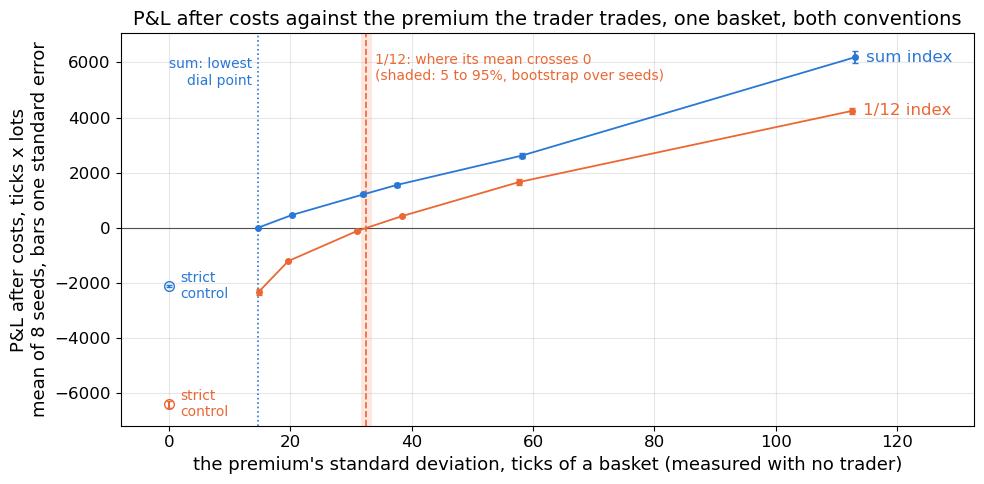

In [4]:
index_i2_rows = {row_name(c, p): (index_market(c, p), index_trader(c)) for c in WEIGHTS for p in DIAL}
index_i2_frame = run_rows(index_i2_rows, FEW, INDEX_BURN)
index_i2_frame['convention'] = index_i2_frame.row.map(lambda row: ROW[row][0])
index_i2_frame['point'] = index_i2_frame.row.map(lambda row: ROW[row][1])
assert (index_i2_frame.exposure.abs() < 1e-9).all(), 'a full replication holds some of a factor'

index_i2_table = table_of(index_i2_frame)
index_i2_table['premium'] = index_i1_table.premium  # where the row stands on the axis: measured, in ticks of a basket
DIAL_COLUMNS = ['premium', 'pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'cost_an_entry', 'exposure']
DIAL_COLUMNS += ['deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']
print(
    f'Sectors market, one basket, mean over {len(FEW)} seeds of {SPAN:,.0f} units after a burn of {INDEX_BURN:,.0f}; '
    'premium: the standard deviation of the premium in ticks of a basket, measured above.'
)
for convention in WEIGHTS:
    print(f'\n{convention} index, size {BASKET[convention]}')
    mine = index_i2_table[[ROW[row][0] == convention for row in index_i2_table.index]]
    print(shown(mine, keep=DIAL_COLUMNS, premium='.1f'))

index_i2_paired = paired_table(
    index_i2_frame,
    {f'1/12 less sum, {p}': (row_name('1/12', p), row_name('sum', p)) for p in DIAL},
    'before_costs',
    'costs',
    'entries',
)
print('\n1/12 less sum at each dial point, seed by seed (the same position in the same fair values at one basket)')
print(shown_paired(index_i2_paired, 'before_costs', 'costs', 'entries'))
ran(index_i2_frame)

# Where the line crosses 0. The points with the books' impact on make the line; the strict control stands apart.
LINE = [p for p in DIAL if p != 'strict']
VOL = [DIAL[p]['index_volatility'] for p in LINE]


def crossing(premium, pnl):
    # The first place the line through (premium, pnl), point to point in the dial's order, goes from 0 or below to above
    # 0: its premium and its index_volatility there, interpolated linearly between the two points that bracket it, and
    # the index of the lower of them. NaN if it never does.
    i, share = first_rise(pnl)
    if i < 0:
        return np.nan, np.nan, -1
    return premium[i] + share * (premium[i + 1] - premium[i]), VOL[i] + share * (VOL[i + 1] - VOL[i]), i


def by_seed(frame, convention, column):
    # seeds by points of the line, for one convention
    got = frame[frame.convention == convention].pivot(index='seed', columns='point', values=column)
    return got[LINE].to_numpy(), list(got.index)


def break_even(convention, draws=2_000):
    # The crossing of the means, and the crossings of `draws` resamples of the seeds: each draws the seeds again with
    # replacement and takes its own means of the measured premium and of the P&L, seed by seed.
    premium, seeds_1 = by_seed(index_i1_frame, convention, 'premium_sd')
    pnl, seeds_2 = by_seed(index_i2_frame, convention, 'pnl')
    assert seeds_1 == seeds_2, 'the premium and the P&L are not on the same seeds'
    at = crossing(premium.mean(axis=0), pnl.mean(axis=0))
    picks = np.random.default_rng(15).integers(0, len(pnl), (draws, len(pnl)))
    found = np.array([crossing(premium[pick].mean(axis=0), pnl[pick].mean(axis=0))[:2] for pick in picks])
    return at, found


print()
index_break_even = {}
for convention in WEIGHTS:
    lowest = index_i2_table.loc[row_name(convention, LINE[0])]
    strict = index_i2_table.loc[row_name(convention, 'strict')]
    print(
        f"{convention} index, at index_volatility {VOL[0]:g}, the lowest point with the books' impact on (premium sd "
        f'{lowest.premium:.1f}): {said(lowest)}. The strict control (premium 0, no impact): {said(strict)}.'
    )
    paying = [p for p in LINE if index_i2_table.loc[row_name(convention, p)].positive == len(FEW)]
    from_then = [p for i, p in enumerate(LINE) if set(LINE[i:]) <= set(paying)]
    if from_then:
        first = index_i2_table.loc[row_name(convention, from_then[0])]
        print(
            f'  positive on every seed from index_volatility {VOL[LINE.index(from_then[0])]:g} on '
            f'(premium sd {first.premium:.1f}).'
        )
    else:
        print('  positive on every seed at no dial point from which it stays so.')
(x, v, below), found = break_even('1/12')
if np.isnan(x):
    print('1/12 index: the mean P&L does not cross 0 on the dial.')
else:
    low, high = np.nanpercentile(found[:, 0], [5, 95])
    v_low, v_high = np.nanpercentile(found[:, 1], [5, 95])
    lost = int(np.isnan(found[:, 0]).sum())
    print(
        f'1/12 index: its mean P&L crosses 0 at a premium sd of {x:.1f} ticks of a basket, index_volatility {v:.2f}, '
        f'between the dial points {LINE[below]} ({said(index_i2_table.loc[row_name("1/12", LINE[below])])}) and '
        f'{LINE[below + 1]} ({said(index_i2_table.loc[row_name("1/12", LINE[below + 1])])}). Bootstrap over the seeds, '
        f'5 to 95%: {low:.1f} to {high:.1f} (index_volatility {v_low:.2f} to {v_high:.2f}); '
        f'{lost} of {len(found):,} draws had no crossing.'
    )
    index_break_even = dict(premium=x, volatility=v, low=low, high=high, between=(LINE[below], LINE[below + 1]))

fig, ax = plt.subplots(figsize=FIGSIZE)
for convention, color in (('sum', BLUE), ('1/12', ORANGE)):
    along = index_i2_table.loc[[row_name(convention, p) for p in LINE]]
    ax.errorbar(along.premium, along.pnl, yerr=along.se, color=color, marker='o', ms=4, lw=1.3, capsize=2)
    ax.annotate(
        f'{convention} index',
        (along.premium.iloc[-1], along.pnl.iloc[-1]),
        xytext=(8, 0),
        textcoords='offset points',
        va='center',
        color=color,
    )
    alone = index_i2_table.loc[row_name(convention, 'strict')]  # the strict control: a different market, not joined up
    ax.errorbar([alone.premium], [alone.pnl], yerr=[alone.se], color=color, marker='o', ms=7, mfc='none', capsize=2)
    # Two short lines to the right of the marker: on one line the label reaches the dotted line at the sum index's
    # lowest point and runs into the 1/12 index's first point beside it.
    ax.annotate(
        'strict\ncontrol',
        (alone.premium, alone.pnl),
        xytext=(8, 0),
        textcoords='offset points',
        va='center',
        color=color,
        fontsize=10,
    )
    lowest = index_i2_table.loc[row_name(convention, LINE[0])]
    if convention == 'sum':  # not interpolated: its lowest dial point with impact on
        ax.axvline(lowest.premium, color=color, ls=':', lw=1.2)
        # The label goes at the top, to the left of the line: the 1/12's crossing and its band run down the right.
        ax.annotate(
            'sum: lowest\ndial point',
            (lowest.premium, 0.9),
            xycoords=ax.get_xaxis_transform(),  # x in data, y as a share of the axis
            xytext=(-4, 0),
            textcoords='offset points',
            ha='right',
            va='center',
            color=color,
            fontsize=10,
        )
if not np.isnan(x):
    ax.axvspan(low, high, color=ORANGE, alpha=0.15, lw=0)
    ax.axvline(x, color=ORANGE, ls='--', lw=1.2)
    ax.annotate(
        '1/12: where its mean crosses 0\n(shaded: 5 to 95%, bootstrap over seeds)',
        (x, 1.0),
        xycoords=ax.get_xaxis_transform(),
        xytext=(6, -14),
        textcoords='offset points',
        va='top',
        color=ORANGE,
        fontsize=10,
    )
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlim(-8, ax.get_xlim()[1] + 14)  # room for the strict control's marker, and for the labels at the right
ax.set_xlabel("the premium's standard deviation, ticks of a basket (measured with no trader)")
ax.set_ylabel(f'P&L after costs, ticks x lots\nmean of {len(FEW)} seeds, bars one standard error')
ax.set_title('P&L after costs against the premium the trader trades, one basket, both conventions')
fig.tight_layout()
plt.show()

**The strict control loses on every seed, though it makes money before costs.** With the books' impact off and no premium, the sum index makes -2,100 (se 47, 0 of 8 seeds positive): 4,333 before costs and 6,433 in costs, on 142.4 entries at 45.2 each. The 1/12 makes -6,395 (se 130, 0 of 8): 4,708 before costs and 11,102 in costs, on 152.2 entries at 72.9 each. These are the most entries of any row of the table. The spread the rule reads reverts within a few units (the first table's autocorrelation at 20 units is 0.02 and 0.03), so it crosses the entry line often, and the mids' bounce around their fair values pays before costs, though not what crossing the spreads costs back. The sum's 4,333 before costs is more than the same trader makes before costs at any dial point up to 0.8 (4,012), where it makes +2,620 after them. So "before costs" is not an edge here: it is the bounce of the index book's own mid, and a trade that is positive before costs can lose after them.

**The sum index breaks even at the bottom of the dial.** At `index_volatility` 0, the lowest point with the books' impact on (premium sd 14.7), it makes +7 (se 24, 5 of 8 seeds positive), with costs of 2,684 against 2,690 before them: the premium the order flow makes by itself pays the sum index's costs, to within the standard error. This is the edge of the dial and not a crossing found between two points. The only point below it is the strict control, -2,100 (se 47, 0 of 8), which is a market with no impact at all and not this market with a smaller premium, so it does not bracket the break-even from below. The notebook cannot say how far below a premium of 14.7 the sum index would still pay, since the dial has no such point. From `index_volatility` 0.2 on (premium sd 20.2, +467, se 42) every seed is positive.

**What the sum index makes at the chosen point, and beyond it.** At 0.4, where the settings were chosen, it makes +1,214 (se 48), positive on 8 of 8 seeds, on 40.5 entries at 40.6 each and 1,646 in costs. The introduction allowed for selection to account for at most 30 to 70 of the P&L over 20,000 units, under 6% of this row's. On seeds 1 to 8, which the settings were chosen on, the row was +1,145 (se 38); the fresh seeds' mean is 69 higher, within what the two rows' standard errors (38 and 48) allow, so the fresh seeds show no sign of a loss to selection. P&L rises with the dial: +1,556 (se 65) at 0.5, +2,620 (se 98) at 0.8 and +6,186 (se 223) at 1.6, with 3,167, 4,012 and 7,597 before costs. Entries fall as it does, from 40.5 at 0.4 to 33.8 at 1.6, and an entry costs about the same (40.6 and 41.8), so costs fall, from 1,646 to 1,411, while P&L rises: a larger premium pays each entry more. These are means of eight seeds of one simulated market, with the trader's settings chosen beforehand.

**The 1/12 index needs a larger premium.** At `index_volatility` 0 it makes -2,322 (se 105, 0 of 8), at 0.4 -118 (se 42, 1 of 8), and from 0.5 on it is positive on every seed (+427, se 44, at 0.5). An entry costs 69.6 to 83.6 at every 1/12 row and 40.5 to 45.2 at every sum row. The paired 1/12 less sum is the same position in the same fair values at one basket, with the twelve books' legs the same lots in both, so the difference is the index leg: -2,329 (se 113, 0 of 8) at 0 and -1,331 (se 80, 0 of 8) at 0.4, with 3,294 (se 212) and 1,533 (se 79) more in costs. It is positive on no seed at any dial point. It narrows to -956 (se 153) at 0.8 and widens to -1,940 (se 200) at 1.6, where the 1/12 also makes 791 (se 259), about three standard errors, less before costs. Seeds 1 to 8 had the two making about the same before costs at 1.6, so this is a gap they did not lead one to expect. The cell after this prose runs the two rows at 1.6 on eight other seeds, and the gap before costs is not there: +243 (se 246) on those and -274 (se 218) on the sixteen together, so it is not a finding. The gap after costs is in all sixteen (-1,525, se 169, 0 of 16 seeds positive). At the low end the paired before-cost difference is not 0 either at 0 (+965, se 136, on 24.1, se 3.5, more entries), and at 0.4 (+202, se 97) it is about two standard errors above it. That is not a cost of the leg and not "the 1/12 finds more". The likely reason is that the 1/12 trader's own twelve lots push the premium it trades. The table of sizes below puts the push's arithmetic beside the premium at the chosen point: from the settings, a full entry of one basket of the 1/12 index moves the premium by 7.2 ticks of a basket, twelve times the sum's 0.6, which is 0.23 of the premium's standard deviation of 30.9 there (0.02 of the sum's 32.0). The same 7.2 is about half of the standard deviation at the bottom of the dial, 14.7, and under a tenth of it at the top, 112.6 (plain ratios of printed figures), so by this arithmetic the push is large against the premium at the low end, where the 1/12 makes the most more before costs (+965), and small at the top. That is arithmetic and not a measurement of the push's share of the P&L. The strict row has no impact and shows +375 (se 77), but it is another market in other ways too (it has no premium), so the table does not say how much of the 965 is the push.

**The 1/12's break-even, and the sum's, in the figure.** The 1/12's mean P&L crosses 0 at a premium sd of 32.5 ticks of a basket, `index_volatility` 0.42, between the points 0.4 (-118, se 42, 1 of 8 positive) and 0.5 (+427, se 44, 8 of 8). The bootstrap over the seeds gives 31.6 to 33.4 (5 to 95%; `index_volatility` 0.41 to 0.43), and every one of its 2,000 draws had a crossing. That is close to where seeds 1 to 8 put it. On the figure's one axis the sum index's lowest point is 14.7 and the 1/12's crossing is 32.5: the 1/12 needs a premium more than twice as large, by about 17.8 ticks of a basket (32.5 less 14.7, a plain difference). The sum's P&L at its lowest point is +7 (se 24), within a third of a standard error of 0, so its crossing is about 14.7: at the 84 ticks of P&L a tick of premium that its first two points give (below), two standard errors are about 0.6 of a tick of premium (2 x 24 over 84, plain arithmetic), so the figure is 14.7 give or take about that on a straight line, and how the line runs below the dial's lowest point is not shown. The rule, the position and the fair values are the same, so the break-even is a property of the book the index leg is traded in, what it costs to cross and what the trader's own orders do to the premium, and not a number for a real index. The interval holds the seeds' spread and the premium's measurement error, since each draw takes its own means of both. It does not hold how far the line bends between two points 7.5 ticks of premium apart (30.9 and 38.4), which is straight by construction, nor the selection of the settings, which the introduction puts at under a tick. In the figure the sum's line starts on the dotted line at 14.7, at +7; the 1/12's crosses 0 at the dashed line, with its interval a thin band; and the strict controls stand apart at 0, at -2,100 and -6,395, because they are other markets and not points of the line.

**The line is not straight.** Take two neighboring rows' difference in `pnl` over their difference in `premium`, a plain ratio of two differences of the table's rounded figures. The sum's is 84 ticks of P&L a tick of premium between 14.7 and 20.2, 63 and 62 over the next two steps, 52 between 37.5 and 58.1 and 65 between 58.1 and 113.0. The 1/12's keeps flattening: 229 between 14.7 and 19.6, 96 to 30.9, 73 to 38.4, 64 to 57.7 and 47 to 112.6. So P&L is not proportional to the premium, and a break-even from straight lines between points far apart is only as good as the line. Here the bracketing points are close, and the three slopes around the 1/12's crossing fall from 96 to 73 to 64, so the line is concave there and lies above its chord: a crossing found on the chord is, if anything, a little high.

**Risk.** With the hedge exact, `exposure` is 0.00 in every row (the cell asserts it), so the risk is not a factor's. The sum's `deviation_long` is 1.19 at `index_volatility` 0, 1.92 at 0.4 and 7.03 at 1.6, and its `risk_adjusted_long` 0.000, 0.032 and 0.044: P&L per unit of risk over 100 units rises slowly (0.035 at 0.5, 0.038 at 0.8) while the risk keeps growing. The one-unit `deviation` is 3.96 at 0 and 6.22 at 1.6. At the bottom it is more than three times the long-run figure, because it is the noise of thirteen mids around their fair values, which reverts; at the top the two are close (6.22 and 7.03), because the premium's own swings, which are slow, dominate. The 1/12's `deviation_long` is 1.94 at 0, 1.95 at 0.4 and 6.31 at 1.6, and its `risk_adjusted_long` -0.060, -0.003 and 0.034, behind the sum's at every dial point by these unpaired means.

### One Surprise, on Other Seeds

This cell was added after the first run of the notebook showed a difference that the settings' seeds had not led one to expect. At `index_volatility` 1.6, the top of the dial, the 1/12 index made less before costs than the sum index, by about three standard errors of the paired difference (the dial table above), where on the seeds the settings were chosen on (1 to 8) the two had made about the same before costs. It was not planned with the dial. It is added to see whether other seeds show the difference too, or whether it was a feature of the eight seeds of the dial.

The cell runs the same two rows at 1.6: the sum index and the 1/12 index, one basket, the dial's trader, market and burn, on eight seeds that no market run of this notebook has used. They are the first eight of `MORE`, which the trend section uses only for a route that runs no books and no trader, so no market in this notebook has been run on them. It prints the two rows on the new seeds; the 1/12 less the sum paired by seed on the new seeds (P&L, before costs, costs and entries); the same difference from the dial table's eight seeds, which is a line of the table above; and the two together, over sixteen seeds. It is 16 runs.

A difference that was noticed because it was large is likely to be smaller on other seeds, whatever its cause, and the new seeds say that and nothing else: they do not say why the 1/12's before-cost P&L is lower at the top of the dial. The paired differences on the dial's seeds and on the new seeds are separate samples of one simulated market, and the cell shows both and does not choose between them.

In [5]:
# One surprise, on other seeds. The new seeds are the first eight of MORE, which no market run of this notebook has
# used: the trend section runs on MORE too, but in fair values alone, with no market and no trader.
SURPRISE = '1.6'  # the dial's top
assert DIAL[SURPRISE]['index_volatility'] == 1.6, 'the dial point of the surprise'
SURPRISE_SEEDS = list(MORE)[:8]
assert SMOKE or not set(SURPRISE_SEEDS) & (set(SEEDS) | set(FEW)), 'the new seeds are seeds of the dial'
assert len(SURPRISE_SEEDS) == len(FEW), 'as many new seeds as the dial has'
index_i8_rows = {row_name(c, SURPRISE): (index_market(c, SURPRISE), index_trader(c)) for c in WEIGHTS}
index_i8_frame = run_rows(index_i8_rows, SURPRISE_SEEDS, INDEX_BURN)
assert (index_i8_frame.exposure.abs() < 1e-9).all(), 'a full replication holds some of a factor'

SURPRISE_COLUMNS = ['pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'cost_an_entry', 'deviation_long']
SURPRISE_COLUMNS += ['risk_adjusted_long']
print(
    f'Sectors market, index_volatility {DIAL[SURPRISE]["index_volatility"]:g}, one basket, mean over '
    f'{len(SURPRISE_SEEDS)} seeds that no other market run of the notebook has used, {SPAN:,.0f} units after a burn '
    f'of {INDEX_BURN:,.0f}:'
)
print(shown(table_of(index_i8_frame), keep=SURPRISE_COLUMNS))
print(f"\nThe same two rows on the dial's {len(FEW)} seeds (the dial table above):")
print(shown(index_i2_table.loc[list(index_i8_rows)], keep=SURPRISE_COLUMNS))

ONE_TWELFTH, SUM = row_name('1/12', SURPRISE), row_name('sum', SURPRISE)


def less_by_seed(frames, column):
    # The 1/12 row less the sum row at the top of the dial, seed by seed in each frame (each on its own seeds), as one
    # Series of differences: what paired() takes the mean of, for frames on different seeds put together.
    out = []
    for frame in frames:
        a = frame[frame.row == ONE_TWELFTH].set_index('seed')[column]
        b = frame[frame.row == SUM].set_index('seed')[column]
        assert a.index.is_unique and set(a.index) == set(b.index), 'the two rows are not on the same seeds'
        out.append(a - b.loc[a.index])
    return pd.concat(out)


def surprise_line(frames):
    # A line of paired_table, for these frames: the difference's mean, se over the seeds, seeds positive and seeds, and
    # the same for before costs, costs and entries.
    pnl = less_by_seed(frames, 'pnl')
    line = {'pnl': pnl.mean(), 'se': se_of(pnl), 'positive': int((pnl > 0).sum()), 'seeds': len(pnl)}
    for column in ('before_costs', 'costs', 'entries'):
        d = less_by_seed(frames, column)
        line.update({column: d.mean(), f'{column}_se': se_of(d), f'{column}_positive': int((d > 0).sum())})
    return line


index_i8_dial = index_i2_frame[index_i2_frame.row.isin([ONE_TWELFTH, SUM])]
index_i8_paired = pd.DataFrame.from_dict(
    {
        f'1/12 less sum, the {len(SURPRISE_SEEDS)} new seeds': surprise_line([index_i8_frame]),
        f"1/12 less sum, the dial's {len(FEW)} seeds": surprise_line([index_i8_dial]),
        f'1/12 less sum, both ({len(SURPRISE_SEEDS) + len(FEW)} seeds)': surprise_line([index_i8_dial, index_i8_frame]),
    },
    orient='index',
)
# The dial's line is the dial table's own paired line.
for column in ('pnl', 'before_costs', 'costs', 'entries'):
    own, in_table = index_i8_paired.iloc[1][column], index_i2_paired.loc[f'1/12 less sum, {SURPRISE}', column]
    assert abs(own - in_table) < 1e-6, f"the dial seeds' {column} is not the dial table's"
print(f'\n1/12 less sum at index_volatility {DIAL[SURPRISE]["index_volatility"]:g}, seed by seed:')
print(shown_paired(index_i8_paired, 'before_costs', 'costs', 'entries'))
ran(index_i8_frame)

Sectors market, index_volatility 1.6, one basket, mean over 8 seeds that no other market run of the notebook has used, 20,000 units after a burn of 2,100:
             pnl  se positive before_costs costs entries cost_an_entry deviation_long risk_adjusted_long
row                                                                                                     
sum, 1.6  +5,740 191   8 of 8        7,030 1,290    30.8          41.9           6.98              0.041
1/12, 1.6 +4,630 194   8 of 8        7,273 2,643    32.1          82.3           6.53              0.036

The same two rows on the dial's 8 seeds (the dial table above):
             pnl  se positive before_costs costs entries cost_an_entry deviation_long risk_adjusted_long
row                                                                                                     
sum, 1.6  +6,186 223   8 of 8        7,597 1,411    33.8          41.8           7.03              0.044
1/12, 1.6 +4,246 102   8 of 8        6,807 2,

**Eight other seeds do not show the 1/12 behind before costs.** At `index_volatility` 1.6 the 1/12 less the sum is +243 (se 246) before costs on the eight new seeds, about one standard error above 0 (0.99, a plain ratio), where the dial's eight seeds gave -791 (se 259), about three below it (3.05, a plain ratio). The two figures are 1,034 apart (a plain difference), 2.9 times the standard error of their difference, 357 (the root of the sum of the two squared standard errors, the eights being different seeds; plain arithmetic). The larger single standard error, 259, would make it four times, which overstates it. This cell was added after the first run showed the difference, as the cell above says: the dial's eight are the seeds that raised the question, noticed because the figure was large, and the new eight are the test of it. A figure noticed for being large shrinks on new seeds, and this one did. Over the sixteen seeds together the difference is -274 (se 218), 1.3 times its standard error (a plain ratio), so the 1/12's lower P&L before costs at the top of the dial is not a finding. The new eight alone are the figure to weigh, since the sixteen include the eight that were looked at because they were large and so lean toward the gap. A gap of a few hundred before costs is not excluded by sixteen seeds.

**The gap after costs is in every one of the sixteen, and it is mostly the dearer book's costs.** The paired P&L is -1,110 (se 184, 0 of 8 seeds positive) on the new seeds, -1,940 (se 200, 0 of 8) on the dial's and -1,525 (se 169, 0 of 16) on the sixteen, 9.0 times its standard error (a plain ratio). Costs are 1,354 (se 101), 1,149 (se 84) and 1,251 (se 69) higher in the 1/12, an entry costing 82.3 against 41.9 on the new seeds and 83.6 against 41.8 on the dial's. On the new seeds the costs more than account for the gap, since before costs the 1/12 is ahead by 243. On the sixteen they are 82% of it (1,251 over 1,525, a plain ratio), and the rest is the before-cost difference that is not a finding. The entries show the same disagreement between the two eights: the 1/12 enters 3.1 fewer times a run (se 1.2) than the sum on the dial's and 1.4 more times (se 1.0) on the new seeds, 0.9 fewer (se 1.0) on the sixteen. So what holds at the top of the dial is what holds at the other points of the dial table, that an entry costs more through the 1/12's book: 1.6 to 1.8 times as much at the strict control and the five other points, and 2.0 times as much at the top (plain ratios of `cost_an_entry`).

**What this does not say.** The cell does not say why the dial's eight showed a gap before costs. With none shown on eight other seeds and -274 (se 218) on the sixteen there is little left to explain, and the reason the dial prose gives for the differences at the low end of the dial, the 1/12 trader's own orders pushing the premium it trades, is not tested here. It is one comparison out of the many the notebook makes and corrects none for, chosen for being large and tried once on new seeds, in one simulated market.

### Is the Hedge Worth Its Legs?

The trader above holds thirteen legs: the index against each of its twelve books, so that the factors cancel and only the premium and the books' own parts are left. Each book's leg costs what crossing its spread costs, and the index's leg alone is the premium trade. So what does the hedge buy? A trader with `hedged=False` reads the same spread and the same z-score, so it follows the same rule and enters about as often, and holds the index alone: the lots it asks for are the hedged trader's lots of the index, and none of any book. It then holds what the index holds of the factors, and carries that risk too.

The rows are the sum index, one basket, at two dial values: 0.4, the value the settings were chosen at, and 1.6, where the premium's own swings dominate. The hedged rows are the dial table's, the same market, seeds and burn, so each hedged row is paired with an unhedged one by seed; the unhedged rows are new runs. The unhedged rows' `lots` are not shown: they are the index's lots alone, so a cost a lot is not comparable with the hedged one's. The table prints `factor_part`, the part of the P&L the factors made (what the trader held of each factor a unit ago times that factor's move), and `rest`, everything else, which is not named for its parts. It prints the risk figures of both kinds: `deviation` is the standard deviation of the change in P&L a unit, and `deviation_long` the same over stretches of 100 units, which sees what holding a factor for long adds. A trader that holds a factor looks safer by the first figure than by the second.

In [6]:
UNHEDGED_POINTS = (CHOSEN, '1.6')
index_i4_rows = {f'unhedged, {p}': (index_market('sum', p), index_trader('sum', hedged=False)) for p in UNHEDGED_POINTS}
index_i4_new = run_rows(index_i4_rows, FEW, INDEX_BURN)
# The hedged rows are the dial table's runs, the same market, seeds and burn: one frame to pair them by seed.
index_i4_hedged = index_i2_frame[index_i2_frame.row.isin([row_name('sum', p) for p in UNHEDGED_POINTS])]
index_i4_frame = pd.concat(
    [index_i4_hedged.assign(row=index_i4_hedged.row.str.replace('sum', 'hedged')), index_i4_new], ignore_index=True
)
ORDER_I4 = [f'{kind}, {p}' for p in UNHEDGED_POINTS for kind in ('hedged', 'unhedged')]
index_i4_table = table_of(index_i4_frame).loc[ORDER_I4]
unhedged_rows = index_i4_table.loc[[r for r in ORDER_I4 if r.startswith('unhedged')]]
hedged_rows = index_i4_table.loc[[r for r in ORDER_I4 if r.startswith('hedged')]]
assert (unhedged_rows.exposure.to_numpy() > 0).all(), 'an unhedged trader holds no factor'
assert (unhedged_rows.lots.to_numpy() < hedged_rows.lots.to_numpy()).all(), 'an unhedged trader holds the hedge too'

HEDGE_COLUMNS = ['pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'cost_an_entry', 'exposure', 'deviation']
HEDGE_COLUMNS += ['deviation_long', 'risk_adjusted', 'risk_adjusted_long', 'factor_part', 'rest']
print(
    f'Sum index, sectors market, one basket, mean over {len(FEW)} seeds of {SPAN:,.0f} units after a burn of '
    f'{INDEX_BURN:,.0f}.'
)
print(shown(index_i4_table, keep=HEDGE_COLUMNS))

index_i4_paired = paired_table(
    index_i4_frame,
    {f'unhedged less hedged, {p}': (f'unhedged, {p}', f'hedged, {p}') for p in UNHEDGED_POINTS},
    'before_costs',
    'costs',
    'entries',
    'deviation_long',
    'risk_adjusted_long',
    'factor_part',
)
print('\nUnhedged less hedged, seed by seed')
print(shown_paired(index_i4_paired, 'before_costs', 'costs', 'entries'))
print(shown_paired(index_i4_paired, 'deviation_long', 'risk_adjusted_long', 'factor_part', lead=(), factor_part=',.0f'))
ran(index_i4_new)

Sum index, sectors market, one basket, mean over 8 seeds of 20,000 units after a burn of 2,100.
                 pnl  se positive before_costs costs entries cost_an_entry exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest
row                                                                                                                                                             
hedged, 0.4   +1,214  48   8 of 8        2,860 1,646    40.5          40.6     0.00      4.01           1.92         0.015              0.032          +0 +1,214
unhedged, 0.4 +2,323 205   8 of 8        3,040   717    41.4          17.3     7.01      4.13           6.91         0.028              0.017        +233 +2,090
hedged, 1.6   +6,186 223   8 of 8        7,597 1,411    33.8          41.8     0.00      6.22           7.03         0.050              0.044          +0 +6,186
unhedged, 1.6 +7,370 461   8 of 8        7,940   570    32.1          17.7     6.71      6.16      

**The legs cost about what the unhedged trader saves, and add nothing that eight seeds can see before costs.** The unhedged trader makes +1,109 (se 196, 8 of 8 seeds positive) more than the hedged one at `index_volatility` 0.4 and +1,184 (se 435, 6 of 8) more at 1.6. Its costs are 930 (se 107) and 842 (se 56) lower: that is what the twelve legs cost. Before costs the two differ by +180 (se 210) and +342 (se 444), within one standard error of 0 at both points, and in the unhedged trader's favor if anywhere. The two traders enter on the same spreads, so "a leg costs more than it adds" can be seen directly here: the legs bring no P&L before costs that these seeds show, and they cost what the table says. These are paired differences of means of eight seeds of one simulated market.

**The same entries, on average.** The paired `entries` are +0.9 (se 2.2) at 0.4 and -1.6 (se 1.1) at 1.6, against means of 41.4 and 40.5 at 0.4 and 32.1 and 33.8 at 1.6 for the unhedged and hedged traders. The two read the same spread and the same z-score, so their entries agree on average, but not seed by seed: two traders in one seed share the market's shocks and not its order flow. "The same entries" is a statement about the mean.

**What the hedge buys is risk, and per unit of risk over 100 units it is the better trade.** The unhedged trader's `exposure` is 7.01 at 0.4 and 6.71 at 1.6 against 0.00. Its `deviation_long` is 6.91 against the hedged trader's 1.92 at 0.4, 3.6 times as much (paired +4.99, se 0.16), and 10.15 against 7.03 at 1.6, 1.4 times as much (paired +3.12, se 0.26): a smaller multiple at 1.6, where the premium's own swings dominate both. At 0.4 its P&L is 1.9 times the hedged trader's (2,323 against 1,214) with 3.6 times the risk, so its `risk_adjusted_long` is lower, 0.017 against 0.032, a paired difference of -0.015 (se 0.002) for unhedged less hedged; at 1.6 it is 0.036 against 0.044, -0.008 (se 0.002). The two are not "about equal" in this market: the unhedged trader's extra P&L is the legs' cost, and its risk has grown by more than its P&L has. The factors have no drift in this section's market, so the exposure is risk with nothing expected to be earned by it: the unhedged `factor_part` is +233 at 0.4 and +711 at 1.6 (paired +233, se 214, and +711, se 344, about one and two standard errors from 0), a gain that a factor with no expected gain can show over eight seeds, and the table gives no reason to read more into it.

**The one-unit risk says the opposite.** At 0.4 the one-unit `deviation` is 4.01 for the hedged trader and 4.13 for the unhedged: by it the two have about the same risk. The hedged trader's is the noise of thirteen mids and not exposure, and it reverts, so its `deviation_long`, 1.92, is under half its one-unit figure; the unhedged trader's, 6.91, is above its 4.13, because what it holds of the factors is persistent. By `risk_adjusted` the unhedged trader looks the better of the two, 0.028 against 0.015 at 0.4 and 0.060 against 0.050 at 1.6, and by `risk_adjusted_long` the hedged one does. This is notebook 13's trap, that the one-unit figure flatters a trader that holds a factor, shown by a row with a known factor.

**Eight seeds separate the hedged mean much better than the unhedged one.** The unhedged row's standard error is 205 against the hedged row's 48 at 0.4, four times as large, and 461 against 223 at 1.6, twice as large, since it carries the factors. The paired difference's standard error at 0.4, 196, is smaller than seeds 1 to 8 led one to expect, and the difference is positive on more seeds than they showed, 8 of 8. At 0.4 the paired difference, +1,109, is 5.7 times its standard error, so it is not noise; at 1.6, +1,184 on 6 of 8 seeds is 2.7 times its standard error. What eight seeds do not separate is that difference from the legs' cost: the before-cost differences are within one standard error of 0, but their standard errors, 210 and 444, are not small against the 930 and 842 that the legs cost, so a small gain from the legs before costs is not ruled out. The sentence the table supports is that the hedge buys a risk over 100 units 3.6 times smaller at 0.4 and a standard error about a quarter the size, for about the cost of its legs. The P&L it gives up is that cost, and no missing edge shows in these seeds.

### A Sampled Hedge

Twelve legs are many. A trader can hedge the index with a sample of the books, chosen by `index_basket`: forward selection of the `legs` books whose levels, in the last 2,000 decisions (10,000 units), best explain the index's level in a regression with a constant, and each book's lots are its coefficient times the index's. The sample is chosen once, when the trader's formation ends, and not again. The books load on four factors, a market factor and three sector factors, but the market factor is the sum of the sectors', so their loadings have rank 3, and the index loads on them as the sum of its books does. A sample of three books, one in each sector, with coefficients of about 4 each (a third of the 12 that the index's weights add up to) cancels all of them; fewer books leave a factor in the spread.

**Sizes.** `size` is lots of the relation's largest leg, and for a sample that is a book and not the index. The sizes, 4 for three legs, 5 for two and 6 for one, are the ones that round the index's leg to one lot on every seed of the calibration, seeds 1 to 8, so that every row trades one index lot. The cell below prints, for every row and seed, the index lots and the book lots the trader holds when it is in, and stops if the full replication's or the three-book sample's index lot is not 1: with the index lot fixed, the rows trade the same number of baskets, and the sizes compare. The two-book and one-book samples' sizes were calibrated on seeds 1 to 8 and round to one index lot only for a range of largest coefficients that a fresh seed can leave: on a seed where one does not, the cell says so and leaves that seed out of that row's table line and pairing, since a row with another index lot is another trade. The `seeds` column of the table says how many seeds each line is over.

**What the true factors leave.** The cell also prints what the true factors leave in each row, the lots held times the market's own loadings (`fair.mean_loadings`, the four factors a column), and its norm: 0 for a full replication, and for a sample whatever its rounding and its books leave in the spread. It prints the same for the row before rounding to lots. It ends with a table by seed of each row's P&L and factor part, and, for the two rows that hold a factor, the correlation across seeds of the one with the other.

**Burn.** The sample is fitted from 2,000 decisions, so every row of this table, the full replication's included, starts after a burn of 10,100 units, which is just over the formation's warm-up, so that every row is the same market time. The full replication is the dial table's trader in another window, so its P&L is not the dial table's. The rows are the sum index, one basket, at `index_volatility` 0.4, on the eight seeds.

In [7]:
FORMATION = 2_000  # decisions: the history a sample is chosen from
SAMPLES = {'legs 3': dict(legs=3, size=4), 'legs 2': dict(legs=2, size=5), 'legs 1': dict(legs=1, size=6)}
FULL = 'full replication'
sampled_makers = {FULL: index_trader('sum')} | {
    name: index_trader('sum', formation=FORMATION, **sample) for name, sample in SAMPLES.items()
}
SAMPLED_BURN = burn_for('sampled burn', 10_100.0, *sampled_makers.values())  # the same for every row, the full one too


def held_when_in(market, trader):
    # What the trader holds when it is in: its row's lots (size times the row, rounded to whole lots as the trader
    # rounds them) and what the market's true factors leave in them, and in the row before rounding. A row is fixed once
    # chosen (a sample is not refitted), so the end of the run says what it held throughout.
    row = trader.size * trader.weights[0]
    lots = np.rint(row)
    loadings = market.fair.mean_loadings
    books = [int(lot) for lot in lots[:-1] if lot]
    return {
        'index_lot': int(lots[-1]),
        'book_lots': f'{len(books)} x {books[0]}' if len(set(books)) == 1 else ', '.join(map(str, books)),
        'left': '(' + ', '.join(f'{x + 0.0:+.0f}' for x in lots @ loadings) + ')',  # + 0.0: no -0
        'left_norm': float(np.linalg.norm(lots @ loadings)),
        'left_norm_unrounded': float(np.linalg.norm(row @ loadings)),
    }


index_i5_rows = {name: (index_market('sum', CHOSEN), make) for name, make in sampled_makers.items()}
index_i5_frame = run_rows(index_i5_rows, FEW, SAMPLED_BURN, extra=held_when_in)
print(
    f'Sum index, sectors market, index_volatility {CHOSEN}, one index lot; a sample is chosen from the last '
    f"{FORMATION:,} decisions. What each trader holds when it is in, a seed: the index's lots, the books' lots "
    "(n x lots, or each book's), what the true factors leave of it (the market factor and the three sectors', in "
    'lots) and the norm of that, and of the row before rounding to lots.'
)
print(
    index_i5_frame[['row', 'seed', 'index_lot', 'book_lots', 'left', 'left_norm', 'left_norm_unrounded']].to_string(
        index=False, formatters={'left_norm': formatter('.2f'), 'left_norm_unrounded': formatter('.2f')}
    )
)
# The full replication and the three-leg sample (size 4, which rounds to one index lot for any largest coefficient from
# 2.7 to 8) must hold one index lot on every seed. The sizes of the two-leg and one-leg samples (5 and 6) were
# calibrated on seeds 1 to 8 and round to one lot only for a largest coefficient from 3.3 to 10 and from 4 to 12: on a
# seed where one does not, that row is another trade, and the seed is left out of that row's table and pairing, with a
# note.
off = index_i5_frame[index_i5_frame.index_lot != 1]
hard = off[off.row.isin([FULL, 'legs 3'])]
assert hard.empty, f'a row does not hold one index lot:\n{hard[["row", "seed", "index_lot"]].to_string(index=False)}'
assert (index_i5_frame[index_i5_frame.row == FULL].left_norm < 1e-9).all(), 'the full replication leaves a factor'
if off.empty:
    print('\nEvery row holds one index lot on every seed.')
else:
    print("\nNot one index lot (those seeds are left out of that row's table and pairing):")
    print(off[['row', 'seed', 'index_lot']].to_string(index=False))

# A row's table line is over the seeds on which it holds one index lot, so that it is the trade the paired lines below
# compare (`seeds` is how many that is, for each row); a seed that holds another number of lots is in the frame only.
index_i5_one = index_i5_frame[index_i5_frame.index_lot == 1]
index_i5_table = table_of(index_i5_one, also=('left_norm',))
SAMPLED_COLUMNS = ['seeds', 'pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'cost_an_entry', 'exposure']
SAMPLED_COLUMNS += ['left_norm', 'deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']
SAMPLED_COLUMNS += ['factor_part', 'rest']
print(f'\nBurn {SAMPLED_BURN:,.0f}, then {SPAN:,.0f} units; mean over the seeds of the `seeds` column')
print(shown(index_i5_table, keep=SAMPLED_COLUMNS, left_norm='.2f', seeds='d'))
# The seeds on which a row holds one index lot.
ONE_LOT = index_i5_one.groupby('row').seed.agg(set)


def less_full(name):
    # A sample less the full replication, on the seeds where the sample holds one index lot.
    part = index_i5_frame[index_i5_frame.row.isin([name, FULL]) & index_i5_frame.seed.isin(ONE_LOT.get(name, set()))]
    pair = {f'{name} less {FULL}': (name, FULL)}
    return paired_table(part, pair, 'before_costs', 'costs', 'entries', 'deviation_long', 'risk_adjusted_long')


index_i5_paired = pd.concat([less_full(name) for name in SAMPLES])
print('\nEach sample less the full replication, seed by seed')
print(shown_paired(index_i5_paired, 'before_costs', 'costs', 'entries'))
print(shown_paired(index_i5_paired, 'deviation_long', 'risk_adjusted_long', lead=()))

# By seed, what each row made and what the true factors made of it (over the seeds on which a row holds one index lot,
# as its table line is), and for the samples that leave a factor in, whether a seed's factor part tracks its P&L.
index_i5_by_seed = pd.DataFrame(
    {
        (name, column): index_i5_one[index_i5_one.row == name].set_index('seed')[column]
        for name in (FULL, *SAMPLES)
        for column in ('pnl', 'factor_part')
    }
)
print('\nBy seed: P&L and the part the factors made of it, after costs, ticks x lots')
print(index_i5_by_seed.to_string(float_format='{:+,.0f}'.format))
for name in ('legs 2', 'legs 1'):
    part = index_i5_one[index_i5_one.row == name]
    print(
        f'{name}: correlation across its {len(part)} seeds of P&L with the factor part '
        f'{part.pnl.corr(part.factor_part):+.2f}.'
    )
ran(index_i5_frame)

Sum index, sectors market, index_volatility 0.4, one index lot; a sample is chosen from the last 2,000 decisions. What each trader holds when it is in, a seed: the index's lots, the books' lots (n x lots, or each book's), what the true factors leave of it (the market factor and the three sectors', in lots) and the norm of that, and of the row before rounding to lots.
             row  seed  index_lot  book_lots             left left_norm left_norm_unrounded
full replication   101          1    12 x -1 (+0, +0, +0, +0)      0.00                0.00
full replication   102          1    12 x -1 (+0, +0, +0, +0)      0.00                0.00
full replication   103          1    12 x -1 (+0, +0, +0, +0)      0.00                0.00
full replication   104          1    12 x -1 (+0, +0, +0, +0)      0.00                0.00
full replication   105          1    12 x -1 (+0, +0, +0, +0)      0.00                0.00
full replication   106          1    12 x -1 (+0, +0, +0, +0)      0.00       

**What each row holds.** The full replication holds one index lot and one lot of each of the twelve books on every seed, and the true factors leave 0.00 of it. The three-book sample holds one index lot on every seed (the cell asserts it), and four lots of each of three books, `3 x -4`, on seven seeds, where the true factors leave 0.00: one book in each sector at four lots cancels what the index lot carries of the market factor and of the three sectors'. On seed 101 it holds 3, 4 and 4 lots, which leaves a lot of the market factor and a lot of one sector's, a norm of 1.41. That is rounding and not the choice of books: before rounding to lots the norm is 0.14 to 0.64 on the eight seeds. The two-book sample holds one book at 5 lots and another at 1 to 5, and the true factors leave a norm of 4.69 to 7.87 (3.66 to 8.69 before rounding); the one-book sample holds 6 lots of one book on every seed, and leaves 8.49 on every seed, though the row before rounding leaves 4.95 to 14.51. Three books can cancel four factors of rank 3 (the market factor is the sum of the sectors') and two or one cannot, however the lots round. Every row holds one index lot on every seed, so no seed was left out of any row or pairing.

**Three books against twelve.** The three-book sample makes +1,762 (se 82, 8 of 8 seeds positive) and the full replication +1,196 (se 44, 8 of 8). Paired by seed the sample is ahead by +567 (se 77, 8 of 8), and the gap is before costs: +740 (se 147) before costs, with the sample's costs 173 (se 82) higher and not lower, on the same entries (-0.2, se 1.6; 39.4 against 39.6), each costing 46.1 against 41.4. So the sample's edge is not a cheaper hedge but a different trade, which makes more before costs on as many entries. That is what seeds 1 to 8 led one to expect: positive, a few hundred, before costs. It is not a better hedge. Its exposure is 0.09 against 0.00, and its risk over 100 units is higher, 2.66 against 2.00 (paired +0.66, se 0.08); the cell on the books' own parts below has the paired risk at +0.15 (se 0.08) with them off, so most of it goes with the own parts. Per unit of risk over 100 units the two are 0.033 and 0.030, paired +0.003 (se 0.002), a difference these seeds do not show.

**Why, if it is before costs: the books' own parts.** The sample's spread holds four lots of each of three books' own parts where the full replication's holds one lot of each of twelve, so the trade is the index trade plus a pairs trade inside the sample's books, in a market whose own parts revert with a half-life of 50 units. That is a property of this market's own parts and not a result about sampling. On seeds 1 to 8 the edge went when the own parts' shocks were turned off (`own_volatility=0`, which leaves the own part that the order flow makes, a standard deviation of 1.2 ticks of a lot against 4.8 with the shocks on, in the next cell's bare markets), and the next cell reruns that on these seeds: with them off the sample is 90 behind the full replication (se 50, 1.8 standard errors, so not separated from 0; 3 of 8 seeds positive), where with them on it is ahead by 567. So the reason rests on that check on two sets of seeds, and the edge is before costs and at one point of the dial (0.4).

**Two books and one book.** The two-book sample makes -95 (se 427, 4 of 8 seeds positive) and the one-book sample -144 (se 474, 3 of 8), each over all eight seeds. They hold a factor: `exposure` 4.67 and 6.57 against 0.00, and mean `factor_part` -559 and -233. Paired against the full replication they are -1,291 (se 403, 1 of 8) and -1,340 (se 476, 1 of 8), with a risk over 100 units higher by 4.05 (se 0.31) and 5.22 (se 0.23), so `risk_adjusted_long` is lower by 0.030 (se 0.003) for each. The loss is before costs, -2,436 (se 426) and -2,582 (se 523), while costs are 1,144 (se 39) and 1,242 (se 58) lower on 25.9 (se 1.1) and 27.4 (se 1.5) fewer entries: they enter 13.8 and 12.2 times against 39.6, and the table does not say why a spread with a factor left in is crossed so much less. A factor left in shows in the P&L, which is down by about 1,300; in the spread across seeds, since the standard errors are 427 and 474 against the full replication's 44, about ten times as large, so that means of -95 and -144 are 0.22 and 0.30 of a standard error from 0 (plain ratios) and eight seeds say little of what these rows make; and in the risk. The by-seed table below says what the factor part does to a seed: across the eight seeds the P&L of the two-book and one-book samples follows the factor part, with a correlation of +0.95 and +0.98, and the worst seed, 106, loses 2,552 and 2,483 where the factor part is -2,479 and -2,552. It does not settle every sign: on seeds 102 and 107 the two-book sample makes +556 and +137 with a factor part of -2 and -136.

**What the table does not show.** Its full replication makes +1,196 (se 44) against the dial table's +1,214 (se 48) at the same dial value: the same trader, market and seeds in another window, a burn of 10,100 here and 2,100 there, so the two are different runs with means that happen to be close, and the tables are not compared. Each sample is compared with this table's own full replication. The sizes, 4, 5 and 6 lots of the largest book, were set so that the index leg rounds to one lot, so a sample's size is not a number of baskets that can be varied freely. The table is of one point of the dial, on eight seeds of one simulated market.

### Where the Sample's Edge Comes From

The table above has the sample of three books ahead of the full replication, before costs, on as many entries. The reason it gives is the books' own parts: the sample's spread holds four lots of each of three books' own parts where the full replication's holds one lot of each of twelve, so the trade is the index trade plus a pairs trade inside the sample's books, in a market whose own parts revert. That reason rests on a check made on other seeds and in another window, and this cell makes it here.

It runs the two rows again, the full replication and the sample of three books: the same traders, with the same sizes, formation of 2,000 decisions and burn as the table above, on the same eight seeds, and asserts as it does that each holds one index lot on every seed and that the full replication leaves no factor in what it holds. The market has one thing changed: `own_volatility` is 0, which turns off the shocks of the books' own parts. It does not remove the own parts: the order flow's own market orders still move each book's own part by the impact, and it still reverts, as the index's premium is made by the same orders at `index_volatility` 0, so each book keeps an own part that only the order flow makes, which the cell's last table measures in bare markets with no trader: a book's own part has a standard deviation of 1.2 ticks of a lot with the shocks off and 4.8 with them on, a quarter as large (a plain ratio). The rows below are named for it, "own shocks on" and "own shocks off". The factors, the index and its premium at the chosen dial point (`index_volatility` 0.4), the impact and the order flow's rule are as before. So any difference between the two rows here is one that the own parts' shocks do not make.

It prints both rows, and the sample less the full replication paired by seed (P&L, before costs, costs, entries and the risk over 100 units), beside the same difference from the table above, where the books have their own parts. It is 16 runs, and it ends with 16 bare markets with no trader (eight seeds with the shocks on and eight off, 6,000 units after a burn of 300, sampled once a unit, in fair values): the standard deviation of a book's own part, of the premium, of the full replication's spread (the index less the twelve books at their weights) and of the sample's (four lots each of books 0, 4 and 8, one from each sector). The bare markets were added to the cell after the first run. Taking the own parts' shocks out changes the market's order flow as well as its fair values, so the two differences are on different markets and the same seeds, and each is paired inside its own market. The cell does not say that the own parts are the whole reason for the edge, only what the edge is without their shocks.

In [8]:
# The two rows of the sampled-hedge table that matter, the full replication and the sample of three books (the same
# traders, burn and seeds), in the same market with the shocks of the books' own parts turned off (`own_volatility` 0;
# the order flow still moves each book's own part by the impact): everything else as at CHOSEN.
OFF = 'own shocks off'
index_off = market_of('sectors', index=WEIGHTS['sum'], own_volatility=0.0, **DIAL[CHOSEN])
index_i7_rows = {f'{name}, {OFF}': (index_off, sampled_makers[name]) for name in (FULL, 'legs 3')}
index_i7_frame = run_rows(index_i7_rows, FEW, SAMPLED_BURN, extra=held_when_in)
# As in the table above: the full replication and the three-leg sample must hold one index lot on every seed, and the
# full replication must leave no factor in what it holds.
off = index_i7_frame[index_i7_frame.index_lot != 1]
assert off.empty, f'a row does not hold one index lot:\n{off[["row", "seed", "index_lot"]].to_string(index=False)}'
full_off = index_i7_frame[index_i7_frame.row == f'{FULL}, {OFF}']
assert (full_off.left_norm < 1e-9).all(), 'the full replication leaves a factor'

index_i7_table = table_of(index_i7_frame, also=('left_norm',))
print(
    f'Sum index, sectors market, index_volatility {CHOSEN}, one index lot, own_volatility 0 (the own parts of the '
    f'books have no shocks of their own; the order flow still moves them), burn {SAMPLED_BURN:,.0f}, then '
    f'{SPAN:,.0f} units; mean over {len(FEW)} seeds, a sample chosen from the last {FORMATION:,} decisions.'
)
print(shown(index_i7_table, keep=SAMPLED_COLUMNS, left_norm='.2f', seeds='d'))

# The sample less the full replication in each market, seed by seed, each pair inside one market: the table above's own
# line (the books' own parts on) and this cell's (off).
index_i7_paired = paired_table(
    index_i7_frame,
    {f'legs 3 less {FULL}, {OFF}': (f'legs 3, {OFF}', f'{FULL}, {OFF}')},
    'before_costs',
    'costs',
    'entries',
    'deviation_long',
    'risk_adjusted_long',
)
index_i7_on = index_i5_paired.loc[[f'legs 3 less {FULL}']].rename(index=lambda label: f'{label}, own shocks on')
index_i7_both = pd.concat([index_i7_on, index_i7_paired])
print("\nThe sample of three books less the full replication, seed by seed, with the own parts' shocks on and off")
print(shown_paired(index_i7_both, 'before_costs', 'costs', 'entries'))
print(shown_paired(index_i7_both, 'deviation_long', 'risk_adjusted_long', lead=()))


def own_spreads(make_fair, seed):
    # A bare market with no trader, sampled once a unit for BARE_SPAN units after BARE_BURN, as the premium's table is:
    # the standard deviation of a book's own part (in ticks of a lot of the book; the mean over the twelve books), and,
    # in fair values and in ticks of a basket, of the premium and of the spread of the full replication (the index less
    # the books at their weights) and of the sample's (the index less the same lots of one book from each sector: books
    # 0, 4 and 8, whose sectors the loadings give; another book from each sector gives the same spread in law, since a
    # sector's books share their loadings and the own parts have one law, and not on the same path).
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    started = time.time()
    fair = make_fair()
    market = BookMarket(fair, seed=seed)
    books, weights = fair.m, fair.index_weights
    sampled = [0, 4, 8]
    lots = weights.sum() / len(sampled)  # four lots of each, as the sample trades
    own, premium, full, sample, next_at = [], [], [], [], BARE_BURN
    while market.time < BARE_BURN + BARE_SPAN:
        market.step()
        if market.time >= next_at:
            next_at += 1.0
            fairs = np.array(fair.fairs)
            own.append(np.array(fair.own[:books]))
            premium.append(fair.premium)
            full.append(fairs[books] - weights @ fairs[:books])
            sample.append(fairs[books] - lots * fairs[sampled].sum())
    return {
        'own_part_sd': float(np.array(own).std(axis=0).mean()),
        'premium_sd': float(np.std(premium)),
        'full_spread_sd': float(np.std(full)),
        'sample_spread_sd': float(np.std(sample)),
        'secs': time.time() - started,
    }


own_markets = {'own shocks on': index_market('sum', CHOSEN), OFF: index_off}
own_jobs = [(name, seed) for name in own_markets for seed in FEW]
own_runs = Parallel(n_jobs=-1)(delayed(own_spreads)(own_markets[name], seed) for name, seed in own_jobs)
own_frame = pd.DataFrame(
    [{'row': name, 'seed': seed, **run} for (name, seed), run in zip(own_jobs, own_runs, strict=True)]
)
print(
    f'\nBare markets, no trader, at index_volatility {CHOSEN}, mean over {len(FEW)} seeds of {BARE_SPAN:,.0f} units '
    f"after a burn of {BARE_BURN:,.0f}, sampled once a unit, in fair values: the standard deviation of a book's own "
    f"part (the mean over the {BOOKS} books, in ticks of a lot of the book), and, in ticks of a basket (a lot of the "
    "index against a lot of each book), of the premium, of the full replication's spread and of the sample's (four "
    'lots each of books 0, 4 and 8, one from each sector).'
)
print(
    own_frame.groupby('row', sort=False)[['own_part_sd', 'premium_sd', 'full_spread_sd', 'sample_spread_sd']]
    .mean()
    .to_string(float_format='{:.1f}'.format)
)
ran(own_frame)
ran(index_i7_frame)

Sum index, sectors market, index_volatility 0.4, one index lot, own_volatility 0 (the own parts of the books have no shocks of their own; the order flow still moves them), burn 10,100, then 20,000 units; mean over 8 seeds, a sample chosen from the last 2,000 decisions.
                                 seeds    pnl se positive before_costs costs entries cost_an_entry exposure left_norm deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest
row                                                                                                                                                                                               
full replication, own shocks off     8 +1,219 22   8 of 8        2,838 1,619    40.9          39.6     0.00      0.00      3.99           1.95         0.015              0.031          +0 +1,219
legs 3, own shocks off               8 +1,130 42   8 of 8        3,155 2,026    43.2          46.8     0.09      0.18      4.43           2.10   


Bare markets, no trader, at index_volatility 0.4, mean over 8 seeds of 6,000 units after a burn of 300, sampled once a unit, in fair values: the standard deviation of a book's own part (the mean over the 12 books, in ticks of a lot of the book), and, in ticks of a basket (a lot of the index against a lot of each book), of the premium, of the full replication's spread and of the sample's (four lots each of books 0, 4 and 8, one from each sector).
                own_part_sd  premium_sd  full_spread_sd  sample_spread_sd
row                                                                      
own shocks on           4.8        32.0            32.0              44.1
own shocks off          1.2        31.8            31.8              32.1
16 runs, 2.6 core-minutes.
16 runs, 13.6 core-minutes.


**With the books' own-part shocks off, the sample's edge is gone.** The sample of three books less the full replication is -90 (se 50, 3 of 8 seeds positive) with the own parts' shocks off (the rows "own shocks off"; `own_volatility` 0, so the order flow still makes an own part in each book, a standard deviation of 1.2 ticks of a lot against 4.8 with the shocks on in the bare markets at the end of the cell), against +567 (se 77, 8 of 8) with them on, which is the sampled-hedge table's line. The sample is 90 behind, 1.8 times its standard error (a plain ratio), which eight seeds do not tell from 0, and it is not 567 ahead. This cell repeats on the notebook's seeds a check made on seeds 1 to 8 before the first run, where the edge also went; it was not added because of anything the first run showed. Both paired lines are inside their own market, so the two differences are compared and the rows of the two markets are not.

**The change is in both columns.** Before costs the sample is +318 (se 153) ahead of the full replication with the shocks off, against +740 (se 147) with them on, and its costs are 407 (se 152) higher, against 173 (se 82). The before-cost gain is 422 smaller and the cost excess 234 larger (plain differences of the printed figures). The entries are still about the same, +2.4 (se 2.4) against -0.2 (se 1.6). The +318 before costs is 2.1 times its standard error (a plain ratio) and holds the bounce of the mids, which is not an edge, and it does not pay the costs.

**The sample's extra risk goes with the parts.** The paired risk over 100 units is +0.15 (se 0.08) with the own shocks off against +0.66 (se 0.08) with them on, so in this market most of the sample's extra risk over 100 units goes with them. `risk_adjusted_long` is -0.004 (se 0.001) against +0.003 (se 0.002): the sample is no better per unit of that risk without the parts, and a little worse.

**Neither row loses without the parts, at this dial point.** The full replication makes +1,219 (se 22, 8 of 8 seeds positive) and the sample +1,130 (se 42, 8 of 8): the premium's trade pays at 0.4 on every seed in a market whose books' own parts have no shocks of their own. These rows are in another market from the sampled-hedge table's, with other order flow, so they are not set beside its rows.

**Where the edge comes from.** The sample's spread holds four lots of each of three books' own parts where the full replication's holds one lot of each of twelve, so in a market whose own parts revert the sample is the index trade plus a pairs trade inside its three books. Take the parts' shocks away and the pairs trade has nothing to earn that eight seeds can see (the sample is 90 behind, se 50), and the sample's edge after costs goes with it. That is a property of this simulator's books and not a result about sampling an index: nothing here says that a sample of an index's books beats its full replication in a market whose books' own parts have no shocks. The cell shows that the edge goes with the own parts' shocks, which is what the reason expects. It does not show that the parts are the whole of it, since the order flow still makes each book an own part with the shocks off (a standard deviation of 1.2 against 4.8), and taking the shocks out changes the order flow as well as the fair values, and it is one point of the dial, eight seeds and one simulated market. The bare markets at the end of the cell, with no trader and in fair values, measure the spreads. With the shocks on the standard deviation of the premium is 32.0 ticks of a basket and the full replication's spread is the same, 32.0, since its twelve lots take the books' own parts out of the index's exactly, so its spread is the premium alone; the sample's spread is larger, 44.1, since its lots leave the books' own parts in it. With the shocks off the premium is 31.8, the full replication's spread 31.8 and the sample's 32.1: the sample's spread is 0.3 above the full replication's, where with the shocks on it is 12.1 above (plain differences). The dial table says what a larger spread is worth, if it is read as a premium: the sum index makes +1,214 at a premium of 32.0, +1,556 at 37.5 and +2,620 at 58.1, so a premium of 44.1, linearly between the last two rows, would make about +1,897, 683 more than at 32.0 (a plain interpolation inside the dial table, in its window). The sample's edge is +567 over the full replication, in this cell's window, so the two are of the same order; that is a reading of the spread's size and not a decomposition of the +567, since the sample's costs are 173 higher and before costs holds the mids' bounce. It agrees with what the cell finds, and with the dial table, where a larger premium pays more.

### More Baskets, and Trading Less

Two questions about size, at `index_volatility` 0.4 on the eight seeds. **Does more size pay more?** Three baskets of the sum index (size 3), against the one basket of the dial table. Orders walk the book, so each basket should cost more at three baskets than at one, and a larger position carries more risk over 100 units. **Does trading less help?** In notebook 13 a rate of 0.25, going a quarter of the way to the target at each decision, added a little to a trader of pairs that entered at 1. A basket is one lot of each leg, so a rate of 0.25 cannot split an order: the aim only rounds up two or three decisions later. The rows are three baskets at a rate of 0.25, to see whether a rate helps once there is something to split, and one basket at notebook 13's pairs setting, entry at 1 with a rate of 0.25, against the chosen entry of 2 and rate of 1.

There is also a 1/12 row at three baskets (size 36). Three baskets of the 1/12 index are thirty-six lots of the index against three of each book, and a trader of that size moves the index book's premium by its own orders: the row may be **a different trade and not only a dearer leg**, and the table says which by its entries and its before-cost P&L. The cell also prints, for each row, what an entry's own orders move the premium by, as arithmetic from the settings and not a measurement. It is paired with the sum index's row of the same three baskets, and not with its one basket, which the dial table has.

Each row is paired with the row of the same trader at one basket where it exists, the dial table's runs at 0.4 (the same market, seeds and burn). The tables quote what an entry costs, and what an entry of one basket costs (the cost an entry over the baskets): never a lot. Every hedge is a full replication, so the factors are not in the trader's position, which the cell asserts.

In [9]:
BASKETS = {  # row: (convention, baskets in it, what the trader changes)
    'sum, 3 baskets': ('sum', 3, {}),
    'sum, 3 baskets, rate 0.25': ('sum', 3, dict(rate=0.25)),
    '1/12, 3 baskets': ('1/12', 3, {}),
    'sum, 1 basket, entry 1, rate 0.25': ('sum', 1, dict(entry=1.0, rate=0.25)),
}
index_i6_rows = {
    row: (index_market(convention, CHOSEN), index_trader(convention, baskets, **changed))
    for row, (convention, baskets, changed) in BASKETS.items()
}
index_i6_new = run_rows(index_i6_rows, FEW, INDEX_BURN)
assert (index_i6_new.exposure.abs() < 1e-9).all(), 'a full replication holds some of a factor'
# The one-basket rows at the same trader and point are the dial table's runs: one frame to pair them by seed.
ONE_BASKET = {row_name('sum', CHOSEN): 'sum, 1 basket', row_name('1/12', CHOSEN): '1/12, 1 basket'}
index_i6_one = index_i2_frame[index_i2_frame.row.isin(ONE_BASKET)].assign(row=lambda f: f.row.map(ONE_BASKET))
index_i6_frame = pd.concat([index_i6_one, index_i6_new], ignore_index=True)
BASKETS_IN = {'sum, 1 basket': 1, '1/12, 1 basket': 1, **{row: baskets for row, (_, baskets, _) in BASKETS.items()}}
ORDER_I6 = ['sum, 1 basket', *list(BASKETS)[:2], 'sum, 1 basket, entry 1, rate 0.25']
ORDER_I6 += ['1/12, 1 basket', '1/12, 3 baskets']
index_i6_table = table_of(index_i6_frame).loc[ORDER_I6]
index_i6_table['baskets'] = [BASKETS_IN[row] for row in index_i6_table.index]
# What an entry of one basket costs: the cost an entry over the baskets in it.
index_i6_table['cost_a_basket'] = index_i6_table.cost_an_entry / index_i6_table.baskets

SIZE_COLUMNS = ['baskets', 'pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'cost_an_entry']
SIZE_COLUMNS += ['cost_a_basket', 'exposure', 'deviation_long', 'risk_adjusted_long']
print(
    f'Sectors market, index_volatility {CHOSEN}, mean over {len(FEW)} seeds of {SPAN:,.0f} units after a burn of '
    f'{INDEX_BURN:,.0f}. cost_a_basket: the cost of an entry over the baskets in it.'
)
print(shown(index_i6_table, keep=SIZE_COLUMNS, baskets=',.0f', cost_a_basket='.1f'))

# What a full entry's own orders move the premium by. Arithmetic from the market's settings, not a measurement: a lot
# taken in the index book moves its premium by the book's scale times the impact (in ticks of the index); an entry takes
# the index lots of its row; and the premium is in ticks of a basket as the dial's axis is (see the premium cell): a
# tick of the index is BASKET[convention] ticks of a basket. All of an entry's orders at once, before the premium's
# half-life of 50 units has taken any of it back, and a rate below 1 spreads them over several decisions.
CONVENTION_I6 = {label: ROW[key][0] for key, label in ONE_BASKET.items()}
CONVENTION_I6.update({row: convention for row, (convention, _, _) in BASKETS.items()})
push = {}
for row in index_i6_table.index:
    convention = CONVENTION_I6[row]
    fair_i6 = index_market(convention, CHOSEN)()
    entry_lots = index_trader(convention, BASKETS_IN[row])().size  # the index lots of an entry: its size
    push[row] = dict(
        index_lots=entry_lots,
        impact=fair_i6.impact,
        scale=fair_i6.scales[-1],
        push=fair_i6.impact * fair_i6.scales[-1] * entry_lots * BASKET[convention],
        premium_sd=index_i1_table.loc[row_name(convention, CHOSEN), 'premium'],
    )
index_i6_push = pd.DataFrame(push).T
index_i6_push['push_over_sd'] = index_i6_push.push / index_i6_push.premium_sd
print(
    f"\nWhat a full entry's own orders move the premium by, in ticks of a basket: impact x the index book's scale x "
    f"the index lots of an entry x {BASKET['1/12']} for the 1/12 index and 1 for the sum (the lots of the index in a "
    'basket), all at once (a rate below 1 spreads an entry over several decisions, so that less is felt at once). '
    'Arithmetic from the settings, not a measurement. premium_sd is the measured standard deviation of the premium '
    f'at index_volatility {DIAL[CHOSEN]["index_volatility"]:g}, as above.'
)
print(
    index_i6_push.to_string(
        formatters={
            'index_lots': '{:.0f}'.format,
            'impact': '{:.3f}'.format,
            'scale': '{:.0f}'.format,
            'push': '{:.1f}'.format,
            'premium_sd': '{:.1f}'.format,
            'push_over_sd': '{:.2f}'.format,
        }
    )
)
index_i6_paired = paired_table(
    index_i6_frame,
    {
        'sum: 3 baskets less 1': ('sum, 3 baskets', 'sum, 1 basket'),
        'sum, 3 baskets: rate 0.25 less rate 1': ('sum, 3 baskets, rate 0.25', 'sum, 3 baskets'),
        'sum: entry 1, rate 0.25 less entry 2, rate 1': ('sum, 1 basket, entry 1, rate 0.25', 'sum, 1 basket'),
        '1/12 less sum, 3 baskets': ('1/12, 3 baskets', 'sum, 3 baskets'),
    },
    'before_costs',
    'costs',
    'entries',
    'deviation_long',
)
print('\nPaired by seed')
print(shown_paired(index_i6_paired, 'before_costs', 'costs', 'entries'))
print(shown_paired(index_i6_paired, 'deviation_long', lead=()))
ran(index_i6_new)

Sectors market, index_volatility 0.4, mean over 8 seeds of 20,000 units after a burn of 2,100. cost_a_basket: the cost of an entry over the baskets in it.
                                  baskets    pnl  se positive before_costs  costs entries cost_an_entry cost_a_basket exposure deviation_long risk_adjusted_long
row                                                                                                                                                             
sum, 1 basket                           1 +1,214  48   8 of 8        2,860  1,646    40.5          40.6          40.6     0.00           1.92              0.032
sum, 3 baskets                          3 +2,693 101   8 of 8        8,576  5,883    41.1         143.1          47.7     0.00           5.48              0.025
sum, 3 baskets, rate 0.25               3 +2,092 214   8 of 8        6,792  4,700    40.5         116.0          38.7     0.00           5.28              0.020
sum, 1 basket, entry 1, rate 0.25       

**More baskets pay more, and less a basket.** Three baskets of the sum index make +2,693 (se 101, 8 of 8 seeds positive) against +1,214 (se 48) for one: 2.2 times the P&L for three times the size, or 898 a basket (2,693 over 3) against 1,214. Paired by seed the difference is +1,480 (se 93, 8 of 8), on 0.6 (se 1.6) more entries: +5,716 (se 146) more before costs, less +4,237 (se 98) more in costs. Before costs three baskets make 8,576 against 2,860, 3.0 times as much; costs are 3.6 times as large (5,883 against 1,646). Orders walk the book: a basket costs 47.7 at three baskets and 40.6 at one (`cost_a_basket`), 7.1 more. So size does not scale, and what it loses is cost.

**The risk over 100 units rises nearly as fast as the baskets, and P&L does not.** `deviation_long` is 5.48 at three baskets against 1.92 at one (paired +3.55, se 0.17), 2.85 times as much, a little under the 3 of the baskets, while P&L rose 2.2 times. So P&L per unit of risk over 100 units falls: `risk_adjusted_long` is 0.025 against 0.032. With the hedge exact (the cell asserts `exposure` 0) the factors are not in the risk. What grows is the premium's and the books' own parts', and the impact of the trader's own orders on the premium it trades; the table does not say how it divides.

**Trading less does not help one basket.** One basket at notebook 13's pairs setting, entry 1 with a rate of 0.25, makes -199 (se 114, 1 of 8), against +1,214 at the chosen entry of 2 and rate of 1: paired -1,413 (se 114, 0 of 8). It enters 127.9 times against 40.5, 87.4 (se 4.5) more, and the extra entries make +1,605 (se 146) more before costs and cost 3,018 (se 145) more. An entry costs 36.5 against 40.6, 4.1 less: a basket is one lot a leg, so a rate of 0.25 has no order to split, and what it saves on an entry is small beside the number of entries. In notebook 13 a rate of 0.25 added a little to pairs that entered at 1, at 2.5 lots a leg; for a position of one lot a leg this setting loses. The row changes the entry and the rate together, so the table does not separate them.

**A rate at three baskets lowers the cost and gives up more.** With three lots a leg there is something to split, and the rate does cheapen the order: a basket costs 38.7 against 47.7 (116.0 an entry against 143.1), and costs are 1,183 (se 280) lower. But it gives up 1,785 (se 461) before costs, on the same entries (-0.6, se 2.2), so the paired P&L of a rate of 0.25 less a rate of 1 is -602 (se 225, 2 of 8 seeds positive), 2.7 times its standard error. The risk over 100 units is no different, 5.28 against 5.48 (paired -0.19, se 0.20). Only a rate of 0.25 was run, so the table says that this rate does not help at three baskets and not that no rate does.

**The 1/12 at three baskets is a different trade.** Three baskets of the 1/12 index make -6,318 (se 513, 0 of 8), against -118 (se 42, 1 of 8) for one basket. Paired with the sum index at the same three baskets, the 1/12 is -9,012 (se 532, 0 of 8): +2,988 (se 471) before costs, +12,000 (se 941) in costs and 16.0 (se 2.4) more entries. At one basket the same paired figures, in the dial table, are -1,331 (se 80), +202 (se 97), +1,533 (se 79) and 4.0 (se 1.4) more entries. Three times the one-basket difference would be -3,993; it is -9,012. The 1/12 trader makes more entries than the sum index at three baskets, 57.1 against 41.1, where at one basket it made 44.5 against 40.5; its basket costs 104.3 against 71.4 at one basket; and its risk over 100 units is 8.22 against the sum's 5.48 (paired +2.74, se 0.51). That is what a trader whose own thirty-six lots of the index move the premium it trades would show, and not what a dearer leg alone would. The table that follows the sizes gives the push's arithmetic from the settings: an entry's own orders move the premium by 21.6 ticks of a basket at three baskets of the 1/12 index, 0.70 of the premium's standard deviation of 30.9 at this point of the dial, and by 7.2 (0.23) at one basket, against 1.8 (0.06) and 0.6 (0.02) for the sum index at three baskets and at one. It is arithmetic for an entry made all at once, and not a measurement, so it shows that the 1/12's own orders are large against the premium they trade at three baskets, and not how much of the P&L they take. Larger sizes of the 1/12 are not the same trade as one basket of it, and its +2,988 before costs is not "the 1/12 finds more".

### In a Backtest's Terms

The scorecard and signal chart of the sum index at one basket, at `index_volatility` 0.4, in the sectors market, on seed 101, which played no part in choosing any setting. As in notebooks 10 to 14, the record has one row per decision: what the trader held after it, valued at the mids just before its orders, with costs that add up to what crossing the spreads cost. The record has thirteen columns, the twelve books and the index. The card runs from the trader's first order to the end of the run, and the tables count only the last 20,000 units after the burn, so the two figures for one run differ when the trader's first order comes before the burn ends.

**The chart is of the index's leg alone.** The signal chart shows one book. Notebook 13's cards chose the largest leg of the first relation, which for the sum index is the first book (every leg is 1), so this card says which book it charts: book 12, the index book, whose leg is the premium trade. The position panel shows that leg only, in ticks times lots, and the scorecard holds all thirteen legs. The signal on the chart is the z-score of the spread, with lines at 2 and -2 where the trader enters and at 0 where it leaves. The capital is 150,000, as in notebook 13. A basket is long the index and short its twelve books or the other way, so a position in several baskets can hold more than the capital: the cell prints the most this card holds as a multiple of it, and above 1 its figure is leveraged.

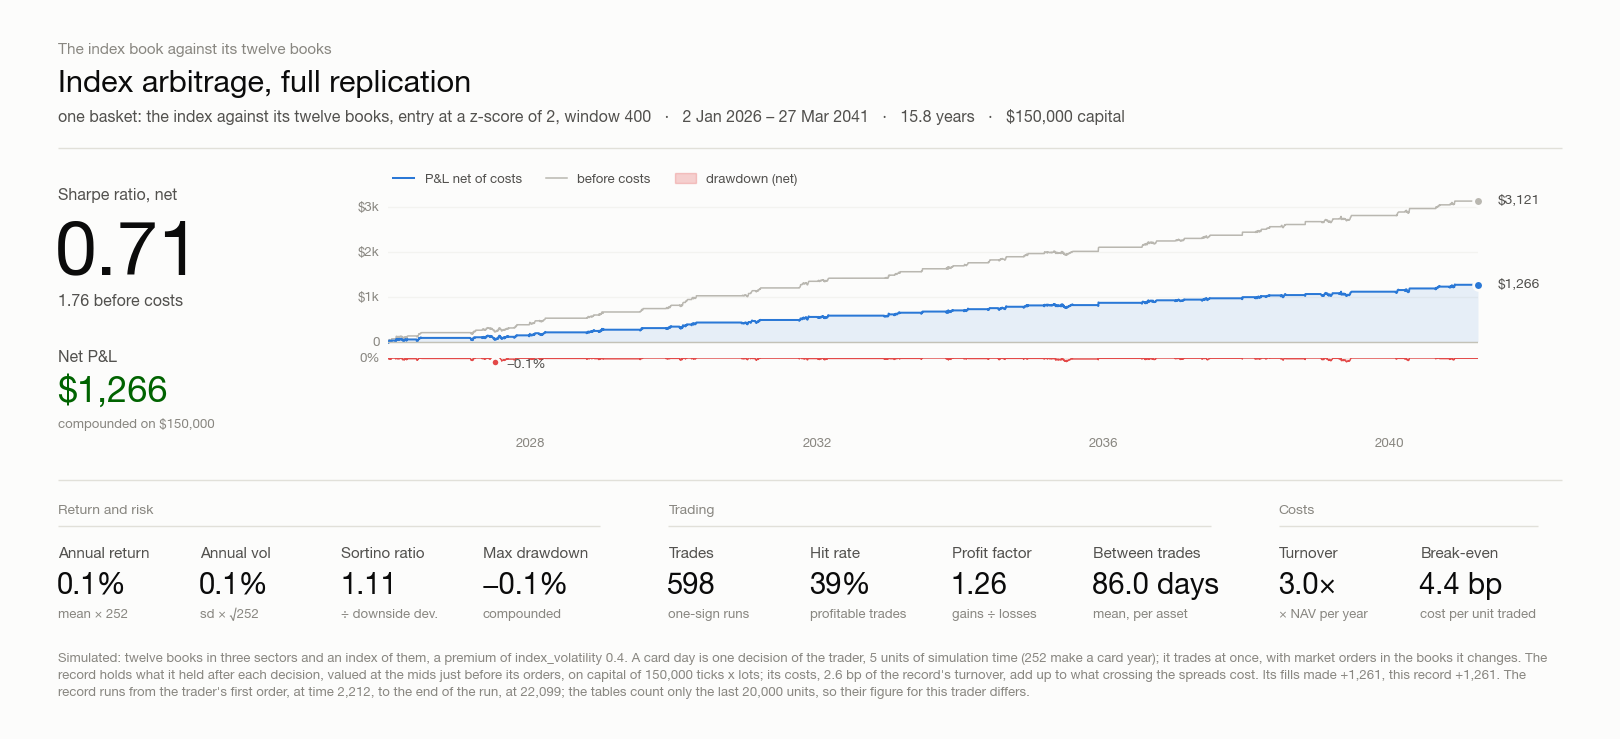

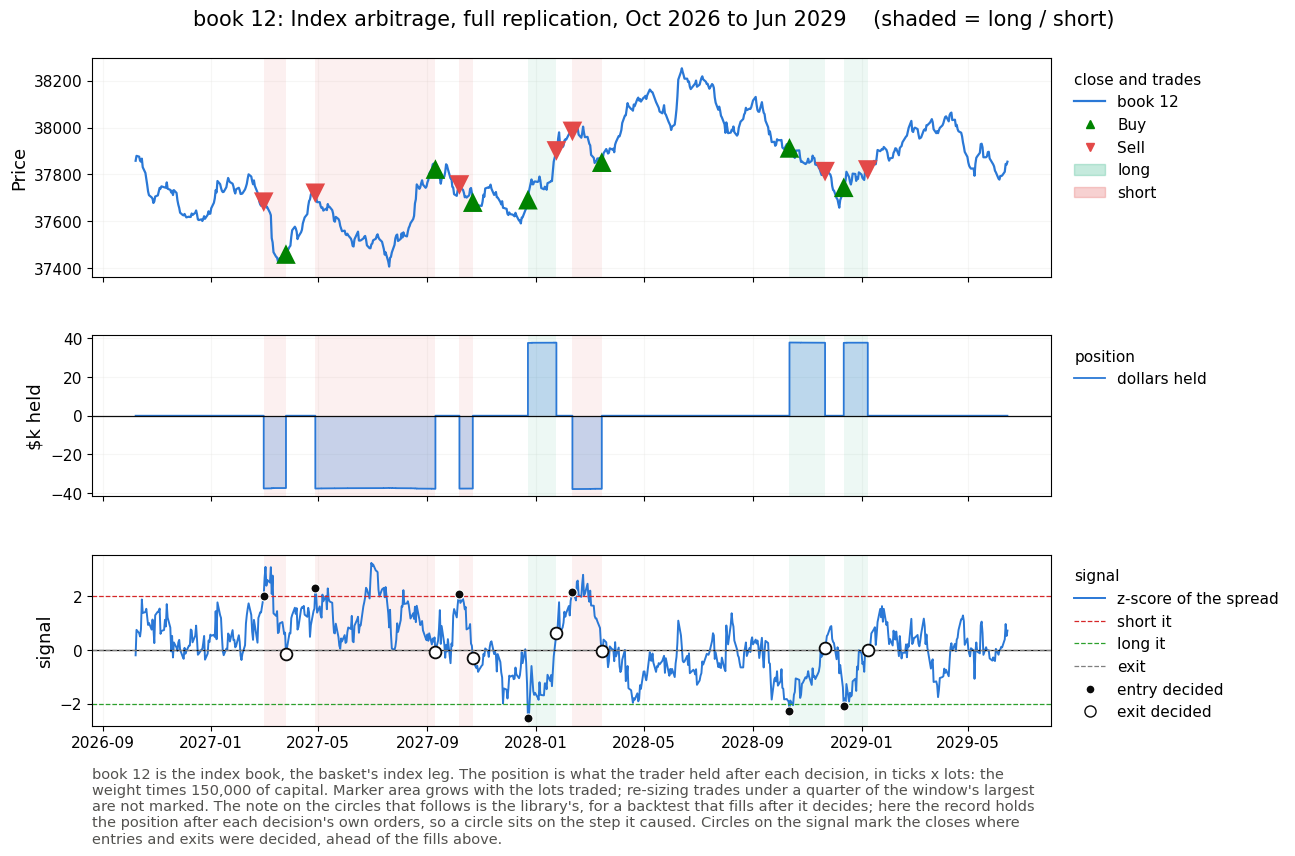

The index book against its twelve books: its fills made +1,261 and the record +1,261; it holds at most 0.53 times the capital of 150,000, and more than it on 0.0% of days.
The dial table's figure for this run, the last 20,000 units only: +1,261
The card does not hold more than the capital of 150,000.


In [10]:
trader, fills, market = recorded(index_market('sum', CHOSEN), index_trader('sum'), INDEX_BURN)
index_card = card(
    trader,
    fills,
    'Index arbitrage, full replication',
    'one basket: the index against its twelve books, entry at a z-score of 2, window 400',
    'The index book against its twelve books',
    f'twelve books in three sectors and an index of them, a premium of index_volatility {CHOSEN}',
    'z-score of the spread',
    around(trader),
    12,  # the index book: notebook 13's largest leg would be book 0, since every leg of the sum index is 1
    relation=0,
    capital=CAPITAL,
    asset="the index book, the basket's index leg",
)
assert abs(index_card['record'] - index_card['fills']) <= max(25.0, 0.02 * abs(index_card['fills'])), (
    f"the record makes {index_card['record']:+,.0f} and the fills {index_card['fills']:+,.0f}"
)
index_card_counted = index_i2_frame[
    (index_i2_frame.row == row_name('sum', CHOSEN)) & (index_i2_frame.seed == CARD_SEED)
].pnl.item()
print(f"The dial table's figure for this run, the last {SPAN:,.0f} units only: {index_card_counted:+,.0f}")
if index_card['peak'] > 1:
    print(f"The capital of {CAPITAL:,.0f} is meant to be more than a card holds at its most: this holds more.")
else:
    print(f'The card does not hold more than the capital of {CAPITAL:,.0f}.')

**The record agrees with the fills.** The card prints +1,261 for its fills and +1,261 for its record: they agree to the tick, well inside the tolerance the cell asserts. The dial table's figure for the same run, the last 20,000 units only, is also +1,261, where notebook 13's cards differed from their tables: the card counts from the trader's first order, at time 2,212, and the table from the end of the burn, at 2,100, so here the two windows hold the same orders. The scorecard's headline is $1,266, the same record compounded on the capital and not summed (the dollar is ticks x lots). Seed 101 made 47 more than the mean of the eight seeds at this point, +1,214 (se 48), which is within one standard error of the mean.

**What the scorecard shows.** Over the 15.8 card years of this one run the net Sharpe ratio is 0.71 and the one before costs 1.76, and the chart's end labels are $1,266 after costs and $3,121 before them. The annual return and volatility are both 0.1% and the maximum drawdown is -0.1%: a basket of one lot is small against a capital of 150,000, so the Sharpe ratio, not the percentages, is the figure to read. It makes 598 trades, a hit rate of 39% and a profit factor of 1.26. The card counts a trade as a one-sign run in one book, so a position of the trader is thirteen of them, and the 39% is of those runs and not of positions. Its costs are 2.6 bp of its turnover, against a break-even of 4.4 bp. The before-cost figure holds the bounce of the mids, as it does at the strict control, and is not an edge. This is one seed of one simulated market.

**The card does not hold more than its capital.** It holds at most 0.53 times the capital of 150,000, and more than it on 0.0% of days, so its figure is not leveraged. A card of three baskets would hold about three times as much, which is more than the capital, so the cell's capital is for this card only.

**In the chart, the position is one lot of the index, long or short, held in runs.** The window is decisions 200 to 900 of the record, October 2026 to June 2029 on the card's calendar. The index leg goes short where the z-score is above its line at 2 and long where it is below -2, and it leaves when the z-score crosses 0: seven entries, four short and three long, and seven exits. A position is one lot, so there is no building up in steps, as there was in notebook 13's cards. The z-score goes further above its line than below the other: to a little over 3 at the highest, and to about -2.5 at the lowest. One short is held much longer than the rest, from the second entry until the z-score comes back to 0, with the z-score above 2 for part of it. The chart shows the index leg only; the twelve books' legs, the other side of the trade, are in the scorecard and not in the chart.

### What This Section Cannot Show

- **That index arbitrage pays in any real market.** The premium is an exogenous Ornstein-Uhlenbeck process with a half-life of 50 units and a mean of 0, drawn from a stream of its own. The rule knows that the spread reverts and has no model of why. There is no creation and redemption, no funding or borrowing cost, no dividends, roll or index reconstitution, and no one else arbitrages the premium, so what the trader does to it is its own impact alone.
- **Where the break-even is in a real market.** The dial's break-even is the cost structure of this simulator's books (their depth, their spread and what a lot moves) and of one convention for the index book's liquidity, which was chosen and not measured. The same rule, in the same fair values, with the same position at one basket, breaks even at a premium of about 14.7 ticks of a basket in one convention and 32.5 in the other, so the break-even is a property of the convention and of what it costs to cross its index book against the size of the premium's swings, not a number for an index.
- **A bracketed break-even for the sum index.** The only dial point below its lowest one with the books' impact on is the strict control, which is not that market with a smaller premium but one with no impact at all, so its break-even is stated at its lowest point and not interpolated. The run did not change that: +7 (se 24) at the lowest point is within a third of a standard error of 0, and no point has a smaller premium with the impact on, so the sum index's break-even is about 14.7, give or take about 0.6 of a tick of premium at two standard errors on a straight line at the 84 ticks of P&L a tick that its first two points give, and how the line runs below its lowest point is not shown. The 1/12 index's is interpolated between two dial points, and its interval comes from the eight seeds and the measured premium's own error; it does not include how far the true line bends between the two points.
- **That the premium is what the rule trades.** The spread holds the books' own parts too, each reverting at the same half-life, and the index book's own noise. The mids' bounce around their fair values is in every figure before costs, so "before costs" is not the premium's share and not an edge, and the run showed two sizes of it: the strict control, with no premium, makes 4,333 before costs, more than the sum index makes before costs at any dial point up to 0.8; and the 1/12 trader, in the same position as the sum trader, makes +965 (se 136) more before costs at `index_volatility` 0, which is not the premium and which the dial table cannot divide between the bounce and the trader's own push (the table of sizes gives that push's arithmetic, 7.2 ticks of a basket for an entry of one basket, and not its share of the P&L).
- **That a sampled hedge is as good in general.** A sample is fitted once, to the levels of the last 2,000 decisions, with no refit; the loadings are fixed here (they do not wander), so no hedge ratio is estimated out of sample against moving loadings. The sizes were calibrated on seeds 1 to 8 so that one index lot is held, and every row held one index lot on every seed here, so no seed was left out of any row. The three-book sample does better than the full replication, by +567 (se 77) after costs, from +740 (se 147) before costs on as many entries, at one point of the dial (0.4) and with a larger risk over 100 units (2.66 against 2.00): a property of this market's own parts, which the sample's spread holds more of for each book. On seeds 1 to 8 it was gone when the own parts' shocks were turned off, and it is gone here too: -90 (se 50, 3 of 8 seeds) with them off against +567 (se 77) with them on, in a market whose order flow changes when they go as well and where the order flow still makes an own part in each book (a standard deviation of 1.2 ticks of a lot against 4.8 with the shocks on). The two-book and one-book samples were not traded at this formation before this notebook; they leave a factor in, make -95 (se 427) and -144 (se 474), which eight seeds do not separate from 0, and across their seeds their P&L follows the factor part (correlations +0.95 and +0.98) though not every seed's sign.
- **That the hedge's worth is settled by eight seeds.** The unhedged row carries the index's exposure to the factors, so its mean has a larger standard error than the hedged row's, and a difference of the size of the legs' cost may not be separated from that noise by eight seeds, whatever the risk over 100 units and the standard errors say of what the hedge buys. The paired before-cost differences, +180 (se 210) and +342 (se 444), are within one standard error of 0 but not small beside the 930 and 842 that the legs cost, so a gain from the legs of a few hundred is not ruled out. The factors have no drift in this section, so the exposure the unhedged trader carries is risk with nothing expected to be earned by it; where a factor drifted it could earn or lose, and no such market is run here.
- **That more size does not pay, or that no rate helps.** Three baskets of the sum index made more than one, +2,693 against +1,214, and less a basket, with a risk over 100 units 2.85 times as large. A size above three baskets is not run. A rate was run at 0.25 only: at three baskets, where it lowered costs by less than it lowered the P&L before them, and with an entry of 1 at one basket, where the table does not separate the rate from the entry.
- **What one convention's larger sizes mean for the other.** Three baskets of the 1/12 index are a different trade and not only a dearer leg: 57.1 entries against the sum index's 41.1 at the same size, and a paired loss of 9,012 (se 532) where three times the one-basket loss would be 3,993. The size table gives the push's arithmetic from the settings (21.6 ticks of a basket at three baskets of the 1/12 index, 0.70 of the premium's standard deviation) and does not measure the premium the trader's orders push, so what the difference is made of is not shown, and the section's size table compares the 1/12 only with the sum at the same number of baskets.
- **Why the 1/12 index looked further behind at the top of the dial.** At 1.6 the 1/12 trader made 791 (se 259) less before costs than the sum trader in the same position on the dial's eight seeds, a gap that seeds 1 to 8 did not show. On eight other seeds it makes 243 (se 246) more, and on the sixteen together 274 (se 218) less, so there is no gap before costs here to explain, and one of a few hundred is not excluded. What holds on all sixteen is the gap after costs (-1,525, se 169, 0 of 16 seeds positive), of which the dearer book's costs are most (1,251, se 69, 82% of it, a plain ratio). The cell was added after the first run showed the gap, so the dial's eight are the seeds that raised the question and the new eight are the test of it.
- **That the settings are the best ones.** They were chosen once, at one point of the dial (0.4), in one convention (the sum) and one market (sectors), and held fixed. They sit on a ridge, and the sum index's row at that point made 69 more on the fresh seeds than on those they were chosen on, but one row is not a test of selection, and they may be better or worse at the other points and in the 1/12 convention.
- **Anything about a trend, a regime change, another window or another half-life of the premium,** or a size above three baskets. Windows of 100, 200 and 400 were tried on seeds 1 to 8 and 400 was the longest, with no window beyond it tried.
- **The mixed market.** It was the sectors market to within noise on seeds 1 to 8 and is not run here.
- **Whether notebook 13's choosers find the index relation themselves,** and what a trader that chose it would make. On seeds 1 to 8, with nothing trading, no sparse chooser's pick contained the index (they take within-sector baskets, the books' own parts, first), and the picks were not traded. The traders here are given the relation.
- **That the market is thirteen books against twelve.** The index market's seed is not the twelve-book market's seed beyond the shocks, since the index book's order flow draws from the stream the books' do and so changes theirs, and so a row here is not a row of notebook 12 or 13 with an index added.
- **Passive orders.** Every trader uses market orders only, as everywhere in these notebooks. The break-even is set by what crossing the spreads costs, and passive orders could move it.

## 2. Deals

**Can a trader make money from the price of a deal's risk, and what does it look like when it does?** An acquirer offers shares of its own for a target's. At the announcement the target's fair value jumps up by a part of the offer's premium; while the deal is on it drifts toward what the offer is worth, as the end draws near and the chance of a break shrinks; if the deal breaks, it falls back at once to what the target is worth alone. The market prices a chance `priced` of that break. `DealTrader` buys the target and sells the acquirer, in the ratio of the offer, at the first decision after an announcement, and holds both until the deal is over. It collects the gap closing in the many deals that complete, and loses it, and more, in those that break (Mitchell and Pulvino 2001: the small gains and large losses of a merger arbitrageur).

**The dial is the true chance of a break, `breaks`, with `priced` held at 0.4.** At `breaks` 0.40 the market's price is fair: the target's fair value has no drift from the announcement on average, and a trader that holds the position pays its costs for nothing, so the row is the control. Below it the price is too high, and the trade is paid for taking the risk: down to `breaks` 0.00, where no deal breaks. The dial runs over 0.40, 0.35, 0.30, 0.25, 0.20, 0.10 and 0.00. At each value the same seed has the same deals, the same two books announced at the same times, and a deal that breaks at one value breaks at every higher one: the dial changes how a deal ends and nothing else, and the section asserts it.

**Each table asks the section's two questions.** How low must `breaks` be before the trade pays its costs, and what does its P&L look like when it does? Then a last question, of a different trader in the same kind of market: what do deals do to a pairs trader, and does reading the news help?

**What is run, in order.**

1. *The deals the market makes, in fair values alone,* with no books and no trader: how many a seed, how often an announcement finds fewer than two books free (crowding), and how the hedge rounds to whole lots. This says what the rest of the section trades, and why the announcement rate is what it is.
2. *The path of one deal that completes and one that breaks,* from the recorded run that the card at the end uses.
3. *The dial.* Seven values of `breaks`, twelve seeds. The table shows the share of deals that actually broke beside the nominal `breaks`, the P&L, its difference from the control seed by seed, before costs and costs, and, from the deals themselves, what a lot pair made. The break-even is found two ways: from a line through the seven means, with a bootstrap over seeds beside what the dial's own arithmetic says its spread should be, and from the mean completed and mean broken lot pair at `breaks` 0.25 and 0.30. The line is read against the nominal `breaks`, against the counted share, and against the share among the deals with a kept record.
4. *The settings,* one thing changed at a time at `breaks` 0.20: the announcement rate, the size, the trader's own rate.
5. *The mixed market,* at `breaks` 0.40, 0.20 and 0.00.
6. *The distribution of what a deal makes* at `breaks` 0.20, from the dial's records: a histogram of the completed and the broken, and the figures a scorecard would show beside it.
7. *The records' bias at a run's end,* and the cut that removes it, which every per-deal figure above uses.
8. *Late entry* in the control: a trader that waits for a wider gap than the first decision's.
9. *Pairs and deals:* notebook 12's pairs trader in a market with deals, at two values of the dial, with and without reading the news, and then the same traders on one set of pairs, the pairs of one world traded in the other, with the differences of P&L split by where it was made.

**What a deal trader has to be told, and the settings.** It enters a deal when the gap in the books' mids, the offer's worth less the target's, is at least `entry` ticks, buys `size` lots of the target and sells the acquirer's in the offer's ratio, rounded to whole lots, and stays in until the deal is over, when it closes both at once. None of the settings was chosen for its P&L, and all were chosen on seeds 1 to 8 at `breaks` 0.20, then held fixed along the dial:

- *Announcements 0.004 a unit of time* over the twelve books, double the library's default, for the count of deals: more of them to average over in the same span, for a few announcements lost to crowding.
- *Entry 0.* On seeds 1 to 8 an entry of 0, 8 and 16 ticks gave the same trader to the last digit, because the first decision's gap was wider than 16 on every one of the deals; 0 is the plain statement of "every deal at the first decision", true by construction and not by margin. An entry at the opening gap, 24, selects on the mids' noise, and the late-entry table shows what that earns.
- *Size 5 lots of the target.* The middle of three: on seeds 1 to 8 size 2 made more a lot, because a smaller order walks the book less, so the size is if anything the conservative choice, and the break-even is stated with it.
- *The trader's own rate 1,* enter all at once, although on seeds 1 to 8 a rate of 0.5 saved a little: two looks at a small effect, so not chosen.

So there is no selected edge to shrink here, as there is for a setting chosen as the best cell of a grid. What fresh seeds can change is not the settings' edge but the seeds' spread: on seeds 1 to 8 the deals' shares broken lay closer together than chance, and the dial's table prints the standard errors that twelve fresh seeds give beside what the dial's own arithmetic says they should be.

**Two markets, not one.** The deal trader's tables are at an announcement rate of 0.004. The pairs table is at 0.002: the pairs trader quarantines books for a window of its own after a deal, and at the higher rate a book is in or just out of a deal most of the time and few pairs are free. So what the deal trader makes where the pairs lose is not a comparison, since the two are in different markets.

**How to read the tables.**

- *The share broken is counted, not nominal.* The same draws serve the whole dial, and a deal breaks at a value if its draw is below it, so each row's counted share is that of its own nested set of draws and differs from the nominal by an amount that changes along the dial; a table keyed on the nominal `breaks` alone puts the rows in the wrong places. The tables count the share from the market's own list of ended deals, beside the nominal.
- *A lot pair* is one lot of the target and the acquirer's lots in the offer's ratio, held from the first decision to the first decision at which both books are flat after the deal ends. Its figure is a record's profit over its lots, in ticks, costs included, and is the trade's own; the P&L column is the run's, over the span after the burn.
- *Counts differ by what they count.* Deals ended, completed, broken and still on come from the market after each run. A deal has a record only if the trader decided at least once while it was on and held it, and a record only counts at a run's end once its books are flat, so the per-deal figures use deals announced at least a deal's length and two decisions before the run's end: the cut of the bias table. The deal counts and the records cover the burn as well as the span; the P&L covers the span alone.
- *Everything before costs* holds what the mids' bounce pays, as in the sections above, so it is not an edge.

**What the section finds.** On twelve seeds of one simulated market, with settings chosen beforehand, the deal trader makes -2,379 (se 348, 0 of 12 seeds positive) where the price of a break is the true chance, and pays its costs once the true chance is about 0.31 against the price of 0.40: a line through the seven means crosses 0 at 0.310 (95% 0.290 to 0.331 over seeds), the same line against the counted share of deals that broke puts it at 0.316 (0.307 to 0.324), and against the share among the deals with a kept record, the deals' own unit, at 0.312 (0.304 to 0.320), the counted share leaning 0.003 to 0.004 toward the broken from 0.40 to 0.20 (counted less kept, +0.0030 to +0.0041), and the deals themselves put it at 0.311 and 0.308 (bootstrap sd 0.003); it makes +2,747 (se 346, 12 of 12 seeds) at 0.20 and +7,370 (se 214) where no deal breaks. A deal is many small gains and a few larger losses: at 0.20 a completed deal makes +18.57 a lot pair and a broken one loses 41.72, 2.2 completed deals' worth (skew -1.57, worst deal -346 ticks x lots), and a seed's total runs from +892 to +4,562, so no seed lost. Entering late in the control makes 744 more than entering at the first decision (se 137, 8 of 8 seeds; -1,380 against -2,124), but only in the mids: at fair values alone the same entries earn 0.28 a lot pair less (se 0.11). A pairs trader in a market with deals makes +2,044 (se 272) at a fair price against +5,703 (se 118) with none; a reader that stays out of a deal's target until the step has left its window makes 692 less than the blind trader there (se 164, 0 of 8 seeds), and one that stays out for the deal's life is not separated from it at either price of the risk on its own pairs (-119, se 217, and +429, se 256), where seeds 1 to 8 had put it ahead of the blind trader where there is a risk premium. On one set of pairs, those of 0.40 held in the market of 0.20, it is ahead of the blind trader there on every seed (+617, se 193, 8 of 8), and the blind trader's fall across the dial is 761 (se 186), 112 less than the bet's arithmetic on the 72.8 net short lots it holds on those pairs (873), the targets' books while the deals are on making 880 less (se 193) and everywhere else 119 more (se 185), where on each trader's own pairs the fall was 1,207 (se 178), of which 686 (se 194) is in the targets' books. The reader's lead is in the targets' books while the deals are on, +885 (se 316) on the pairs held and +693 (se 295) on its own pairs, about the bet it does not hold, and everywhere else it is 268 behind (se 257) and 264 behind (se 201), neither separated from 0, so that the lead in the targets' books is how reading the news pays in this market; on a trader's own pairs the lead, +429 (se 256), is not separated from 0, so whether reading the news pays a trader at this premium is not shown.

In [11]:
from scipy import stats

from lob.deal_traders import DealTrader, NewsAwareTrader
from lob.deals import Deals

# What a deal is in every market of this section (lob.deals): it is worth `premium` ticks more than the target at the
# announcement, lasts `length` units unless it breaks, and its two books stay out of a new deal for `cool` units after.
# `priced` is the chance of a break the market gives, held along the dial; the dial is the true chance, `breaks`.
DEALS = dict(premium=60.0, length=500.0, priced=0.4, cool=100.0, within=True)
DEAL_PREMIUM, DEAL_PRICED = DEALS['premium'], DEALS['priced']
DEAL_RATE = 0.004  # announcements a unit of time over the twelve books: the deal trader's tables
PAIRS_DEAL_RATE = 0.002  # the pairs table's, with books free often enough for pairs to trade
DEAL_SIZE = 5  # lots of the target a deal trader buys
DEAL_DIAL = (0.40, 0.35, 0.30, 0.25, 0.20, 0.10, 0.00)  # `breaks`: the first, which is DEAL_PRICED, is the control
DEAL_CHOSEN = 0.20  # the dial value the settings were chosen at, on seeds 1 to 8
DEAL_ROW = {b: f'breaks {b:.2f}' for b in DEAL_DIAL}
DEAL_BREAKS = {row: b for b, row in DEAL_ROW.items()}
DEAL_CONTROL = DEAL_ROW[DEAL_PRICED]
DEAL_LEVELS = sorted(DEAL_DIAL)  # the dial from the one that never breaks to the control


def dealing(breaks, rate=DEAL_RATE, market='sectors'):
    # The fair values of one of the markets with deals announced at `rate` that break with probability `breaks`: a
    # function with no arguments, so that a joblib worker makes its own.
    return market_of(market, deals=Deals(rate=rate, breaks=breaks, **DEALS))


def dealer(kind=DealTrader, **settings):
    # A deal trader: DEAL_SIZE lots of the target, entering at the first decision (an entry of 0 ticks of gap).
    return partial(kind, **{**dict(size=DEAL_SIZE, interval=EVERY, entry=0.0), **settings})


DEAL_BURN = burn_for('deal burn', 600.0, dealer())
DEAL_FIRST = dealer()().taking(1)  # the longest a trader waits to decide after an announcement
DEAL_CUT = DEALS['length'] + dealer()().taking(2)  # a deal announced this long before a run's end is over by then


def deal_extra(market, trader):
    # What a run of a deal trader leaves to read, in the worker: the deals the market made, how they ended, and what the
    # trader made of each it held (a DealRecord, as a tuple), from the market and trader after the run.
    ended, on = market.fair.ended, market.fair.deals
    return dict(
        completed=sum(d.outcome == 'completed' for d in ended),
        broken=sum(d.outcome == 'broken' for d in ended),
        on=len(on),
        not_flat=trader.not_flat_at_entry,
        end=market.time,
        deals=tuple((d.target, d.acquirer, round(d.announced, 3), d.outcome) for d in (*ended, *on)),
        records=tuple(
            (r.target, r.acquirer, round(r.announced, 3), r.entered, r.ended, r.outcome, r.lots, r.pnl, r.flat)
            for r in trader.outcomes
        ),
    )


def deal_records(frame):
    # A line a deal that a trader held, from every run of a frame of deal_extra's: the run's row and seed, the fields of
    # the DealRecord, `pair`, the lot pair it made (its profit over its lots), and `kept`: announced early enough before
    # the run's end (by DEAL_CUT) to be over, and its books flat, whatever its outcome.
    fields = ('target', 'acquirer', 'announced', 'entered', 'ended', 'outcome', 'lots', 'pnl', 'flat')
    lines = [
        {'row': run.row, 'seed': run.seed, 'end': run.end, **dict(zip(fields, record, strict=True))}
        for run in frame.itertuples()
        for record in run.records
    ]
    out = pd.DataFrame(lines, columns=['row', 'seed', 'end', *fields])
    out['pair'] = out.pnl / out.lots.clip(lower=1)
    out['kept'] = out.announced <= out.end - DEAL_CUT
    return out


def lot_pairs(records, by='row'):
    # A line a row, from the records that are kept: how many, a lot pair's mean and its standard error over the deals,
    # the mean and sd of the completed ones and of the broken ones, and c / (c - b): the share of deals broken at which
    # a lot pair makes nothing, for the completed ones' mean c and the broken ones' b.
    kept = records[records.kept]
    done, broke = kept[kept.outcome == 'completed'], kept[kept.outcome == 'broken']
    group = lambda part: part.groupby(by, sort=False).pair  # noqa: E731
    out = pd.DataFrame(
        {
            'records': group(kept).size(),
            'pair': group(kept).mean(),
            'pair_se': group(kept).apply(se_of),
            'comp': group(done).mean(),
            'comp_sd': group(done).std(),
            'brk': group(broke).mean(),
            'brk_sd': group(broke).std(),
        }
    )
    out['be'] = out.comp / (out.comp - out.brk)
    return out


def check_deals(frame, rows):
    # `rows` go by rising `breaks`. On every seed every row has the same deals (target, acquirer and time announced), as
    # far as the shortest of its runs goes, and what is broken at one value is broken at the next. The dial changes how
    # a deal ends and nothing else. Returns the number of deals compared, summed over the seeds.
    compared = 0
    for seed, runs in frame[frame.row.isin(rows)].groupby('seed'):
        horizon = runs.end.min()
        deals = {run.row: [d for d in run.deals if d[2] <= horizon] for run in runs.itertuples()}
        every = {row: {d[:3] for d in deals[row]} for row in rows}
        broken = {row: {d[:3] for d in deals[row] if d[3] == 'broken'} for row in rows}
        assert all(every[row] == every[rows[0]] for row in rows), f'seed {seed}: the rows have different deals'
        for lower, higher in zip(rows[:-1], rows[1:], strict=True):
            assert broken[lower] <= broken[higher], f'seed {seed}: a deal broke at {lower} and not at {higher}'
        compared += len(every[rows[0]])
    return compared


deals_rng = np.random.default_rng([2026, 11, 12])  # for the bootstraps and the dial's arithmetic: not a market's seed

### What the Market Makes

Before any trader, the tables below count what the deals themselves do, on seeds 101 to 108 in fair values alone (no books, no traders), so that what comes after is read against it. An announcement is drawn at each step of the fair values' grid with probability the rate times the step; it makes a deal only if two books are free, a book being free when it is in no deal and its last deal's planned end and cooling time are past. The same draws serve every `breaks`, and the table's `breaks` is 0.20 only because a deal has to have some value: the deals do not depend on it.

In [12]:
class Counted(FactorValues):
    # Fair values that count the announcements they are asked to make, how many found fewer than two free books and so
    # made no deal, and how many books were free at each.
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.tried, self.lost, self.free = 0, 0, []

    def _announce(self, values, t, pick_target, pick_acquirer, wait):
        busy = {book for deal in self.deals for book in (deal.target, deal.acquirer)}
        self.free.append(sum(book not in busy and self._steps >= self._free_at[book] for book in range(self.m)))
        on = len(self.deals)
        super()._announce(values, t, pick_target, pick_acquirer, wait)
        self.tried += 1
        self.lost += len(self.deals) == on


def deal_counts_of(rate, seed, until):
    # The deals one seed's fair values make to time `until`, with no books and no trader: how many were tried, lost to
    # crowding and made, how many were on at once (sampled every decision), and what each one's ratio r was.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    fair = Counted(LOADINGS['sectors'], deals=Deals(rate=rate, breaks=DEAL_CHOSEN, **DEALS))
    fair.reseed(seed)
    on = []
    for t in np.arange(EVERY, until + EVERY / 2, EVERY):
        fair.advance_to(float(t))
        on.append(len(fair.deals))
    made = [*fair.ended, *fair.deals]
    unit = LOADINGS['sectors'] / np.linalg.norm(LOADINGS['sectors'], axis=1, keepdims=True)
    return dict(
        rate=rate,
        seed=seed,
        tried=fair.tried,
        lost=fair.lost,
        made=len(made),
        free=float(np.mean(fair.free)),
        on=float(np.mean(on)),
        busy=float(np.mean(np.array(on) >= 3)),
        most=max(on),
        crossed=sum(not np.allclose(unit[d.target], unit[d.acquirer]) for d in made),
        ratios=tuple(d.ratio for d in made),
    )


COUNT_RATES = (PAIRS_DEAL_RATE, DEAL_RATE, 2 * DEAL_RATE)
counts = pd.DataFrame(
    Parallel(n_jobs=-1)(delayed(deal_counts_of)(rate, seed, DEAL_BURN + SPAN) for rate in COUNT_RATES for seed in FEW)
)
assert (counts.made == counts.ratios.map(len)).all(), 'a run has a ratio for each deal made, and not more'
assert counts.crossed.sum() == 0, 'an acquirer came from another sector: its sector had an odd number of free books'

crowding = counts.groupby('rate').agg(
    tried=('tried', 'sum'),
    lost=('lost', 'sum'),
    made=('made', 'mean'),
    free=('free', 'mean'),
    on=('on', 'mean'),
    busy=('busy', 'mean'),
    most=('most', 'max'),
    crossed=('crossed', 'sum'),
)
crowding.insert(2, 'share_lost', crowding.lost / crowding.tried)
crowding.index.name = 'announcements a unit'
print(f'Fair values alone, {len(FEW)} seeds of {DEAL_BURN + SPAN:,.0f} units each, no trader:\n')
print(
    crowding.rename(
        columns={
            'tried': 'tried',
            'lost': 'no 2 free books',
            'share_lost': 'share lost',
            'made': 'deals a seed',
            'free': 'free books at one',
            'on': 'on at once',
            'busy': 'share of time 3+ on',
            'most': 'most on',
            'crossed': 'acquirer from another sector',
        }
    ).to_string(float_format=lambda x: f'{x:.3f}' if x < 1 else f'{x:,.1f}')
)

ratios = {rate: np.array([r for rs in group.ratios for r in rs]) for rate, group in counts.groupby('rate')}
rounding = []
for rate, r in ratios.items():
    for size in (1, 2, 5, 10, 20):
        lots = size * r
        off = np.abs(lots - np.rint(lots))
        rounding.append(
            dict(
                rate=rate,
                size=size,
                ratio=r.mean(),
                ratio_sd=r.std(),
                off=off.mean(),
                off_share=off.mean() / size,
                not_one_for_one=(np.rint(lots) != size).mean(),
                acquirer_lots=np.rint(lots).mean(),
            )
        )
print(
    '\nThe hedge in whole lots: the acquirer lots a deal trader sells for `size` lots of the target, rint(size x r):\n'
)
print(
    pd.DataFrame(rounding)
    .set_index(['rate', 'size'])
    .to_string(
        formatters={
            'ratio': '{:.4f}'.format,
            'ratio_sd': '{:.4f}'.format,
            'off': '{:.3f}'.format,
            'off_share': '{:.1%}'.format,
            'not_one_for_one': '{:.1%}'.format,
            'acquirer_lots': '{:.2f}'.format,
        }
    )
)
print(
    '\nratio is the mean of r, the acquirer shares offered a target share, over the deals made; off is the mean of '
    '|size x r - rint(size x r)|, the lots the hedge is out by.'
)

Fair values alone, 8 seeds of 20,600 units each, no trader:

                      tried  no 2 free books  share lost  deals a seed  free books at one  on at once  share of time 3+ on  most on  acquirer from another sector
announcements a unit                                                                                                                                             
0.002                   339                0       0.000          42.4                9.7       0.923                0.066        5                             0
0.004                   656               11       0.017          80.6                7.4         1.8                0.266        6                             0
0.008                  1335              234       0.175         137.6                4.2         3.0                0.626        6                             0

The hedge in whole lots: the acquirer lots a deal trader sells for `size` lots of the target, rint(size x r):

            ratio

**Crowding is why the rate is 0.004 and not higher.** More announcements make more deals to average over, until books run short: an announcement that finds fewer than two free books makes none. At 0.002 a unit none of the 339 announcements is lost and a seed makes 42.4 deals; at 0.004, 11 of 656 are lost (a share of 0.017) and a seed makes 80.6; at 0.008, 234 of 1,335 are lost (0.175) and a seed makes 137.6. So doubling the rate from 0.002 to 0.004 nearly doubles the deals for a small loss, while doubling it again adds a factor of 1.7 (137.6 against 80.6, a ratio of the two printed means) and 0.175 of the announcements find no two free books. That is why the dial's tables use 0.004. The counts are eight seeds of fair values alone, over the burn and the span.

**Several deals are on at once.** At 0.004 the mean number of deals on at once is 1.8, three or more are on for 0.266 of the time, and the most on at once is 6; at 0.002 the figures are 0.923, 0.066 and 5. A deal trader at 0.004 therefore holds several deals together, so its gross position, and the capital its card needs, are several deals' worth (the card takes 200,000 and prints how much it holds at its most). At 0.008 the mean is 3.0 and three or more are on for 0.626 of the time.

**No acquirer comes from another sector.** The last column is 0 at every rate, and the cell asserts it. A sector has four books, and a deal takes two books of one sector and frees them together, so a sector's free books are always an even number and a free target always has a free kin: `within` never has to fall back to another sector. With sectors of three or five books it would.

**The hedge is in whole lots.** A deal trader sells `rint(size x r)` lots of the acquirer for `size` lots of the target, where `r` is the number of the acquirer's shares the offer gives for one of the target's, a little above 1 at a level of 3,000 ticks. The table counts how far the whole-lot hedge is from the exact one. At 0.004 the mean of `r` is 1.0200 and its sd 0.0383. At size 5 the hedge is five lots of the acquirer for five of the target in all but 2.6% of deals; it sells 5.03 lots on average and is out by 0.163 lots, 3.3% of the size, in absolute value. At size 10, 23.1% of deals are not ten for ten (off by 0.231 lots, 2.3% of the size), and at size 20, 48.7% are not (0.262 lots, 1.3%). So at the dial's size the hedge is almost always one for one, and at larger sizes a growing share of deals leaves the trader a lot or so off the exact hedge, in a smaller share of a larger position. That is why the size is a setting worth stating.

### A Deal's Path

One recorded run, on the card's seed, at `breaks` 0.20: the deal trader alone with the twelve books, to the end of its run. The figure takes the first deal that the trader held, in the card's window, that completed, and the first that broke, and draws the target's mid, the target's fair value and the offer's worth in mids (the ratio `r` times the acquirer's mid), from a little before the announcement to a little after the end. The fair value is what no trader sees: it is kept at each decision by a subclass of the deal trader that trades as it does. The shaded stretch is what the trader held. The mids follow the fair values, with the noise of the books around them, and the fair value of a target is the mix of the offer's worth and its own, which is why it jumps at the announcement and falls back at a break.

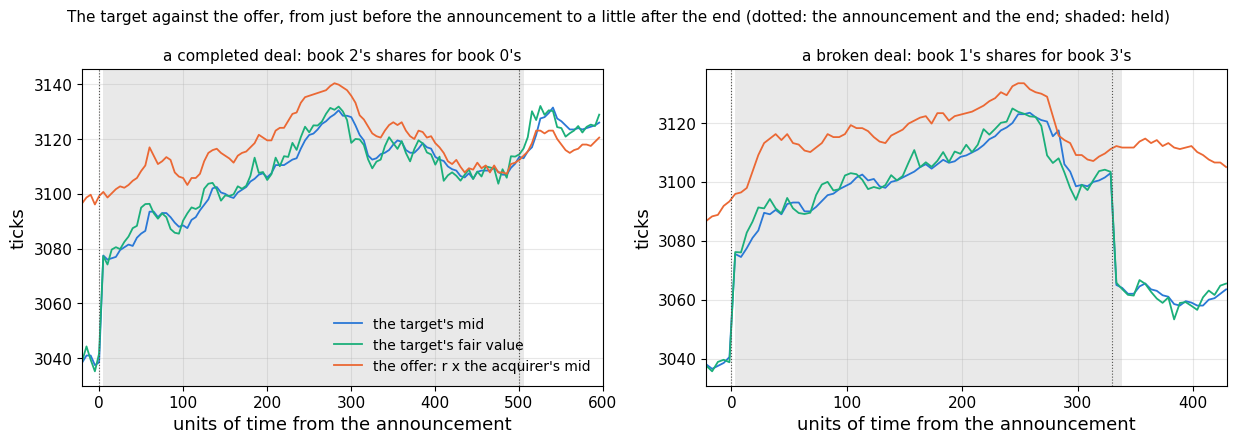

completed: book 2 for book 0, r = 1.0171, announced at 1,286.2, over at 1,786.2 (planned end 1,786.2); held 1,291.2 to 1,791.7, 5 lots, made +110 ticks x lots, +22.0 a lot pair
   broken: book 1 for book 3, r = 1.0162, announced at 1,313.0, over at 1,642.4 (planned end 1,813.0); held 1,316.2 to 1,651.6, 5 lots, made -168 ticks x lots, -33.6 a lot pair


In [13]:
class Witness(DealTrader):
    # A deal trader that also keeps the books' fair values at each decision, which no trader sees: for the figure of a
    # deal's path. It trades exactly as a DealTrader does.
    def attach(self, n):
        super().attach(n)
        self.fairs = []

    def observe(self, market):
        super().observe(market)
        self.fairs.append(market.fair.values())


# One recorded run, on the card's seed, at the value the settings were chosen at. The card at the end of the section
# uses it, and so does the figure of two deals below.
deals_card_trader, deals_card_fills, deals_card_market = recorded(dealing(DEAL_CHOSEN), dealer(Witness), DEAL_BURN)
deals_card_record = record_of(deals_card_trader, CAPITAL_DEALS)
deals_card_end = min(900, len(deals_card_record.days) - 1)  # the card's window, as card() clamps it
deals_card_start = min(200, max(deals_card_end - 100, 0))
deals_card_window = (deals_card_record.times[deals_card_start], deals_card_record.times[deals_card_end])

history = deals_card_trader.history
decided = np.array([h[0] for h in history])
mids = np.array([h[1] for h in history])
fairs = np.array(deals_card_trader.fairs)
assert len(fairs) == len(decided), 'the fair values kept are not one for each decision'
held = {(r.target, r.acquirer, round(r.announced, 3)): r for r in deals_card_trader.outcomes}


def a_deal(outcome):
    # The first deal of this outcome that the trader held and that lies in the card's window; failing that (a smoke
    # run is short, or a window of a few thousand units has none that broke) the first it held in the run, and a note.
    ours = [d for d in deals_card_market.fair.ended if d.outcome == outcome]
    ours = [d for d in ours if (d.target, d.acquirer, round(d.announced, 3)) in held]
    assert ours, f'no deal that {outcome} was held in the run, on the card seed'
    inside = [d for d in ours if deals_card_window[0] <= d.announced and d.ended_at <= deals_card_window[1]]
    if not inside:
        print(f"No deal that {outcome} lies in the card's window on the card seed: the first one held is drawn.")
    return (inside or ours)[0]


deals_completed, deals_broken = a_deal('completed'), a_deal('broken')

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
for ax, deal in zip(axes, (deals_completed, deals_broken), strict=True):
    shown_at = (decided >= deal.announced - 25.0) & (decided <= deal.ended_at + 100.0)
    x = decided[shown_at] - deal.announced
    record = held[(deal.target, deal.acquirer, round(deal.announced, 3))]
    ax.axvspan(record.entered - deal.announced, record.flat - deal.announced, color=GRAY, alpha=0.12, lw=0)
    ax.plot(x, mids[shown_at, deal.target], color=BLUE, lw=1.3, label="the target's mid")
    ax.plot(x, fairs[shown_at, deal.target], color=AQUA, lw=1.3, label="the target's fair value")
    ax.plot(
        x, deal.ratio * mids[shown_at, deal.acquirer], color=ORANGE, lw=1.3, label="the offer: r x the acquirer's mid"
    )
    ax.axvline(0.0, color=GRAY, lw=0.8, ls=':')
    ax.axvline(deal.ended_at - deal.announced, color=GRAY, lw=0.8, ls=':')
    ax.set_xlim(x[0], deal.ended_at - deal.announced + 100.0)
    ax.set_title(f"a {deal.outcome} deal: book {deal.target}'s shares for book {deal.acquirer}'s", fontsize=11)
    ax.set_xlabel('units of time from the announcement')
    ax.set_ylabel('ticks')
axes[0].legend(frameon=False, fontsize=10, loc='lower right')
fig.suptitle(
    'The target against the offer, from just before the announcement to a little after the end '
    '(dotted: the announcement and the end; shaded: held)',
    fontsize=11,
)
fig.tight_layout()
plt.show()

for deal in (deals_completed, deals_broken):
    record = held[(deal.target, deal.acquirer, round(deal.announced, 3))]
    print(
        f'{deal.outcome:>9}: book {deal.target} for book {deal.acquirer}, r = {deal.ratio:.4f}, announced at '
        f'{deal.announced:,.1f}, over at {deal.ended_at:,.1f} (planned end {deal.ends:,.1f}); held '
        f'{record.entered:,.1f} to {record.flat:,.1f}, {record.lots} lots, made {record.pnl:+,.0f} ticks x lots, '
        f'{record.pnl / record.lots:+.1f} '
        'a lot pair'
    )

**A deal that completes pays its gap, less costs.** In the left panel the target's mid and its fair value jump together at the announcement to a level below the offer's worth, and climb through the deal toward it; by the end the two have met, and the fair value goes on without a jump. The trader entered at the first decision, 5.0 units after the announcement (1,291.2 against 1,286.2), held five lots for the 500 units of the deal and made +110 ticks x lots, +22.0 a lot pair: the gap that closed, less what crossing the spreads cost. The target's fair value starts below the offer's worth because the market prices a chance of a break, and it ends at it because this deal did not break.

**A deal that breaks loses the jump and the gap not yet earned.** In the right panel the target's fair value falls back at the break to what the target is worth alone, 329.4 units after the announcement (1,642.4 less 1,313.0) and 170.6 before the planned end (1,813.0 less 1,642.4), while the offer's worth, which is the acquirer's, does not move with it. The trader holds until the deal is over, since a break time is hidden from it, closes both books at the first decisions after the break (flat at 1,651.6) and makes -168 ticks x lots, -33.6 a lot pair: a loss 1.5 times the gain of the completed deal beside it (a ratio of the two printed lot pairs). The break is taken by the whole position at once. These are one deal of each kind, the first the trader held in the card's window, drawn for the mechanism; how often each happens and what each makes on average are in the tables below.

### The Dial

The deal trader alone in each market, on every one of the twelve seeds, at the settings of the opening, scored over the span after a short burn (it has no warm-up: it trades from its first decision, and the burn only skips the first deals). Seven values of `breaks`; the control, 0.40, is where the market's price for a break is the true chance. The first table is the run's own: the share of deals that broke, counted from the market, against the nominal; what the deals did and what they were worth to a trader before costs, by arithmetic; and the P&L. The second takes each row less the control, seed by seed (the control and the row share the market's factors and, deal for deal, its announcements, though not what happens to a deal after a trader's orders). The third is from the deals themselves.

**The break-even is found two ways, because each answers a different question.** A line through the seven means of the P&L, with a bootstrap over the seeds, is the direct evidence: where the trade as run pays its costs, noisy, because which deals happen to break is common to every row and moves the whole line. The same line is also read against the counted share of ended deals that broke, in which each resample of the seeds counts its own share. The share of broken deals at which the mean completed lot pair pays for the mean broken one, `c / (c - b)`, is the location, with the noise of which deals broke taken out; it is a share of the deals the trader held that broke, which in the long run is the nominal `breaks` less the deals that break before the trader's first decision. Beside the bootstrap, the dial's own arithmetic says how far the line's root should be from the truth over fresh seeds, from the lot pairs the table measured and nothing else; a bootstrap of the seeds cannot see a spread that the seeds happen to be too close together to show.

In [14]:
deals_dial_rows = {DEAL_ROW[b]: (dealing(b), dealer()) for b in DEAL_DIAL}
deals_dial_frame = run_rows(deals_dial_rows, SEEDS, DEAL_BURN, extra=deal_extra)
deals_dial_frame['breaks'] = deals_dial_frame.row.map(DEAL_BREAKS)
deals_dial_records = deal_records(deals_dial_frame)

# What must hold for the table to mean anything.
assert (deals_dial_frame.not_flat == 0).all(), 'a deal was entered with a book of its that was not flat'
compared = check_deals(deals_dial_frame, [DEAL_ROW[b] for b in DEAL_LEVELS])
print(
    f'{compared:,} deals compared over {len(SEEDS)} seeds: the same two books announced at the same time at every '
    'value of breaks, and what breaks at one value breaks at every higher one.'
)
ended = deals_dial_frame.completed + deals_dial_frame.broken
a_run = deals_dial_records.groupby(['row', 'seed']).size()
print(
    f'Deals ended a run: {ended.min():.0f} to {ended.max():.0f}; still on at the end: '
    f'{deals_dial_frame.on.min():.0f} to {deals_dial_frame.on.max():.0f}; records a run '
    f'{a_run.min()} to {a_run.max()}; '
    f'not flat at entry: {deals_dial_frame.not_flat.sum()}.\n'
)

deals_dial_table = table_of(deals_dial_frame, also=('completed', 'broken', 'on'))
done = deals_dial_frame.groupby('row', sort=False)[['completed', 'broken']].sum()
deals_dial_table['share'] = done.broken / (done.completed + done.broken)  # the share that broke, counted
deals_dial_table['edge'] = [DEAL_PREMIUM * (DEAL_PRICED - DEAL_BREAKS[row]) for row in deals_dial_table.index]
print('The dial, one trader alone: P&L over the span, in ticks x lots, mean over the seeds.\n')
print(
    shown(
        deals_dial_table,
        keep=[
            'share',
            'edge',
            'completed',
            'broken',
            'on',
            'pnl',
            'se',
            'positive',
            'before_costs',
            'costs',
            'cost_a_lot',
        ],
        share='.3f',
        edge='.1f',
        completed='.1f',
        broken='.1f',
        on='.1f',
    )
)
print(
    '\nshare is the share of ended deals that broke, counted from the market; edge is 60 x (priced - breaks), the '
    'ticks a lot pair gains before costs if the nominal share is the share;\ncompleted, broken and on are deals a run: '
    'ended, and still on at the end.'
)

deals_dial_against = paired_table(
    deals_dial_frame,
    {f'{row} less the control': (row, DEAL_CONTROL) for row in deals_dial_table.index[1:]},
    'before_costs',
    'costs',
    'risk_adjusted_long',
)
print('\nEach row less the control, seed by seed:\n')
print(shown_paired(deals_dial_against, 'before_costs', 'costs', 'risk_adjusted_long'))

deals_dial_pairs = lot_pairs(deals_dial_records)
print(
    '\nWhat a deal made, from the records (deals announced early enough to be over by the end of the run), '
    'and the risks:\n'
)
print(
    shown(
        deals_dial_table.join(deals_dial_pairs),
        keep=[
            'records',
            'pair',
            'pair_se',
            'comp',
            'comp_sd',
            'brk',
            'brk_sd',
            'be',
            'deviation',
            'deviation_long',
            'risk_adjusted',
            'risk_adjusted_long',
            'exposure',
            'factor_part',
        ],
        records=',.0f',
        be='.3f',
    )
)
print(
    "\npair is a lot pair: a record's profit over its lots, in ticks, mean over the deals with its standard error over "
    "them; comp and brk are the completed and the broken deals' means and sds;\nbe is c / (c - b), the share broken at "
    'which a lot pair makes nothing.'
)

# The share broken, counted over every deal the market ended (the table's `share`) and over the deals with a kept
# record, which are the deals the lot pairs above are made of (the unit that c / (c - b) is a break-even in); and the
# ended deals that have no kept record, with how many of them broke.
held_records = deals_dial_records[deals_dial_records.kept]
held_broken = (held_records.outcome == 'broken').groupby(held_records.row, sort=False).sum()
ended_all = done.completed + done.broken
share_kept = pd.DataFrame(
    {
        'counted': deals_dial_table.share,
        'kept records': held_broken / deals_dial_pairs.records,
        'ended': ended_all,
        'records': deals_dial_pairs.records,
        'ended, no record': ended_all - deals_dial_pairs.records,
        'of them broken': done.broken - held_broken,
    },
    index=deals_dial_table.index,  # the table's order; the records' index is sorted, and a union of two orders sorts
)
share_kept['counted less kept'] = share_kept.counted - share_kept['kept records']
print(
    '\nThe share of deals that broke, counted over every deal the market ended and over the deals with a kept record, '
    'and the ended deals that have no kept record (all the seeds together):\n'
)
print(
    share_kept.to_string(
        formatters={
            'counted': '{:.4f}'.format,
            'kept records': '{:.4f}'.format,
            'counted less kept': '{:+.4f}'.format,
            **{c: '{:,.0f}'.format for c in ('ended', 'records', 'ended, no record', 'of them broken')},
        }
    )
)
ran(deals_dial_frame)

983 deals compared over 12 seeds: the same two books announced at the same time at every value of breaks, and what breaks at one value breaks at every higher one.
Deals ended a run: 67 to 90; still on at the end: 0 to 3; records a run 66 to 90; not flat at entry: 0.

The dial, one trader alone: P&L over the span, in ticks x lots, mean over the seeds.

            share edge completed broken  on    pnl  se  positive before_costs costs cost_a_lot
row                                                                                           
breaks 0.40 0.415  0.0      47.3   33.6 1.0 -2,379 348   0 of 12         -395 1,984       1.25
breaks 0.35 0.363  3.0      51.6   29.3 1.0 -1,094 284   2 of 12          915 2,009       1.26
breaks 0.30 0.305  6.0      56.2   24.7 1.0   +271 275   7 of 12        2,289 2,017       1.26
breaks 0.25 0.246  9.0      61.0   19.9 1.0 +1,652 329  12 of 12        3,679 2,027       1.27
breaks 0.20 0.200 12.0      64.8   16.2 1.0 +2,747 346  12 of 12        4,75

**The control loses what it costs, and a little more.** At `breaks` 0.40 the trader makes -2,379 (se 348, 0 of 12 seeds positive): costs of 1,984 (1.25 a lot) and -395 before costs. The share that broke is 0.415 against the nominal 0.40, which on its own takes the before-costs figure below 0: an edge of 60 x (0.40 - 0.415) is -0.9 ticks a lot pair. A lot pair makes -6.24, of which four spreads at 1.25 are 5.00, and the share's excess accounts for 0.9 of the remaining 1.24. So at a fair price the trade loses its costs and has nothing to collect, and what the dial finds below this row is what the premium for the risk is worth and nothing else.

**The P&L crosses 0 close to 0.30, and from 0.25 on every seed pays.** At 0.35 it is -1,094 (se 284, 2 of 12 seeds positive) and at 0.30 +271 (se 275, 7 of 12), one standard error from 0; at 0.25 it is +1,652 (se 329) and at 0.20 +2,747 (se 346), each on 12 of 12 seeds. At 0.10 it is +5,520 (se 333) and at 0.00, where no deal breaks and the trader collects in each of the 80.8 deals a run that complete, +7,370 (se 214), both on 12 of 12; costs are 2,047 there and the P&L before them +9,417. These are means of twelve seeds of one simulated market, at settings chosen beforehand: the trade pays its costs once the true chance of a break is some way below the price, the crossing lies between 0.35 and 0.30, nearer 0.30, and what it makes at 0.00 is the premium net of costs.

**The share that broke is not the nominal, and the excess is not the same at each row.** Counted from the market the shares are 0.415, 0.363, 0.305, 0.246, 0.200, 0.080 and 0.000 against the nominal 0.40, 0.35, 0.30, 0.25, 0.20, 0.10 and 0.00: above it by 0.015, 0.013 and 0.005 at the three highest, 0.004 below it at 0.25, equal at 0.20 and 0.00, and 0.020 below it at 0.10. The P&L follows the counted share and not the nominal: in each of the six steps of the dial it rises by between 23,100 and 24,700 ticks x lots for each unit of share (plain ratios of printed differences), while the steps in the nominal are 0.05 or 0.10. So the dial's steps in P&L are uneven in the nominal and even in the counted share, and a break-even read from the nominal alone inherits the sample's excess of breaks, which is why the section also reads it from the deals.

**Against the control, the dial moves what a deal is worth and not what the trade costs.** The paired P&L less the control, from 0.35 down, is +1,285 (se 265, 11 of 12 seeds), +2,650 (se 360), +4,031 (se 330), +5,126 (se 387), +7,899 (se 344) and +9,749 (se 398), the last five on 12 of 12. Before costs less the control is within 63 of each of those (1,310, 2,684, 4,074, 5,153, 7,916 and 9,812), because costs less the control are small: 25 (se 21), 33 (se 10), 43 (se 17), 26 (se 20), 17 (se 24) and 63 (se 23), 1% to 3% of the 2,000 that the control costs. They are positive at every row but separated from 0 only at 0.30, 0.25 and 0.00 (3.3, 2.5 and 2.7 standard errors, plain ratios; the others are 0.7 to 1.3). Against `edge`, 3.0 to 24.0 ticks a lot pair, before costs less the control is between 409 and 453 for each tick of edge (ratios of printed numbers), about the number of lot pairs a run: 5 lots in each of the 80.9 deals ended at the control (47.3 and 33.6), 404.5. So a row gains from the control about what the arithmetic of `edge` says, at the counted share's steps.

**What a deal makes is the same at every row; the rows weight it differently.** A completed lot pair is +18.42 to +18.65 at every row, and a broken one -41.26 to -41.81 from 0.40 to 0.20 (-39.79 at 0.10, where the fewest broken deals are left to average; none at 0.00). `c / (c - b)`, the share broken at which a lot pair makes nothing, is 0.308 to 0.311 from 0.40 to 0.20 and 0.317 at 0.10. So every row is the same two outcomes weighted by the share that broke: the mean lot pair runs from -6.24 (se 0.97) to +18.42 (se 0.11), its standard error falling as the broken deals drop out, and that is why the break-even can be read from the deals.

**The risks: the risk over 100 units is the lower, and neither shows the skew.** At every row `deviation_long` is below `deviation`: 10.14 against 11.72 at the control, 7.42 against 9.81 at 0.20 and 3.72 against 7.46 at 0.00. The one-unit changes of this trader's P&L partly reverse, as the mids' bounce would make them, so the one-unit figure overstates what holding it for a hundred units risks, and `risk_adjusted_long` is the larger in size at every row (0.019 against 0.014 at 0.20, 0.099 against 0.049 at 0.00): the other way from a trader that holds a factor, whose risk grows with the horizon. Neither figure shows the skew of a few large losses, which the distribution table does. The trade is not a factor bet: it holds 0.31 to 0.39 lots of factor exposure (`exposure`) and the factor part of its P&L is between -27 and +7, against P&L in the thousands.

Break-even from the line through the seven means, in nominal breaks: 0.310 (bootstrap over the 12 seeds: sd 0.010, 95% 0.290 to 0.331).
Break-even from the line through the seven means against the counted share of ended deals that broke: 0.316 (bootstrap over the same 12 seeds and draws: sd 0.004, 95% 0.307 to 0.324).


Break-even from the line through the seven means against the share broken among the deals with a kept record: 0.312 (bootstrap over the same 12 seeds and draws: sd 0.004, 95% 0.304 to 0.320).


The dial's own arithmetic, with this table's lot pairs (+18.6 completed, -41.7 broken, 81.9 deals a run of 20,600 units) and no market: the line's root has sd 0.014 over 12 fresh seeds (mean 0.309).
Its expected standard error of a row, at each dial value 0.00, 0.10, 0.20, 0.25, 0.30, 0.35, 0.40: 241, 286, 325, 343, 361, 377, 390; the table's: 214, 333, 346, 329, 275, 284, 348.
Break-even from the records at breaks 0.30: c / (c - b) = 0.311 (bootstrap sd 0.003).
Break-even from the records at breaks 0.25: c / (c - b) = 0.308 (bootstrap sd 0.003).
The arithmetic line, which assumes a lot pair makes nothing before costs at a fair price, crosses 0 at breaks 0.315 (5.07 a lot pair at the control).


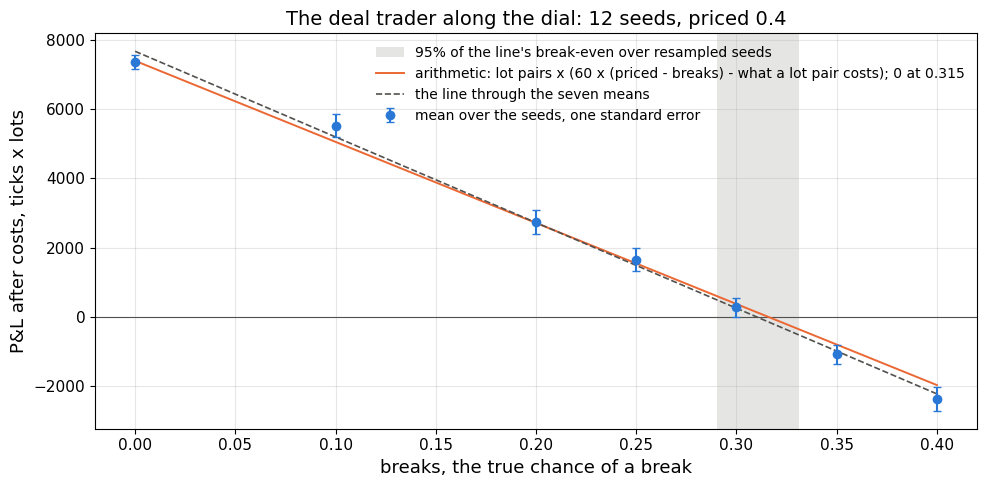

In [15]:
def deal_crossing(matrix):
    # Where the line through the mean of each row of `matrix` (a row a dial value, from DEAL_LEVELS up; a column a seed)
    # reaches 0: the nominal `breaks` at which the trade pays its costs.
    slope, intercept = np.polyfit(DEAL_LEVELS, matrix.mean(axis=1), 1)
    return -intercept / slope


def spread_of_the_dial(comp, comp_sd, brk, brk_sd, per_run, seeds, reps=2_000):
    # What the dial's own arithmetic says of how far its break-even and its rows' standard errors should be from the
    # truth over fresh seeds, with no market and no trader. A seed has a Poisson number of deals (mean `per_run`), each
    # with one exponential that is the same at every dial value: it breaks at `breaks` if that is below
    # -ln(1 - breaks), so the broken ones are nested, as the market's are. A completed deal makes a lot pair of mean
    # `comp` and sd `comp_sd`, a broken one `brk` and `brk_sd`; a seed's P&L at a dial value is DEAL_SIZE lots of their
    # sum.
    cut = -np.log1p(-np.minimum(DEAL_LEVELS, 0.999999))
    roots, errors = np.empty(reps), np.empty((reps, len(DEAL_LEVELS)))
    for rep in range(reps):
        pnl = np.empty((len(DEAL_LEVELS), seeds))
        for j in range(seeds):
            n = deals_rng.poisson(per_run)
            waits = deals_rng.standard_exponential(n)
            done = comp + comp_sd * deals_rng.standard_normal(n)
            lost = brk + brk_sd * deals_rng.standard_normal(n)
            pnl[:, j] = DEAL_SIZE * np.where(waits[None, :] <= cut[:, None], lost, done).sum(axis=1)
        roots[rep], errors[rep] = deal_crossing(pnl), pnl.std(axis=1, ddof=1) / math.sqrt(seeds)
    return roots.mean(), roots.std(), errors.mean(axis=0)


def ratio_of_the_means(records, row, seeds, draws):
    # c / (c - b) for a row's kept records, with its standard deviation over bootstrap draws of the seeds (`draws`, a
    # row of seed positions for each draw): the share of deals broken at which a lot pair makes nothing.
    kept = records[(records.row == row) & records.kept]
    by_outcome = {
        outcome: kept[kept.outcome == outcome]
        .groupby('seed')
        .pair.agg(['count', 'sum'])
        .reindex(list(seeds), fill_value=0)
        for outcome in ('completed', 'broken')
    }

    def ratio(chosen):
        c, b = (
            by_outcome[o]['sum'].to_numpy()[chosen].sum(-1) / by_outcome[o]['count'].to_numpy()[chosen].sum(-1)
            for o in by_outcome
        )
        return c / (c - b)

    return ratio(np.arange(len(seeds))), ratio(draws).std()


# The break-even from a line through the seven means, resampling the seeds.
matrix = (
    deals_dial_frame.pivot(index='row', columns='seed', values='pnl').loc[[DEAL_ROW[b] for b in DEAL_LEVELS]].to_numpy()
)
draws = deals_rng.integers(0, matrix.shape[1], (4_000, matrix.shape[1]))
line = deal_crossing(matrix)
roots = np.array([deal_crossing(matrix[:, d]) for d in draws])
low, high = np.percentile(roots, [2.5, 97.5])
print(
    f'Break-even from the line through the seven means, in nominal breaks: {line:.3f} (bootstrap over the '
    f'{matrix.shape[1]} seeds: sd {roots.std():.3f}, 95% {low:.3f} to {high:.3f}).'
)

# The same line against the share of ended deals that broke, as counted in the market, in place of the nominal `breaks`:
# a row's share is its broken over its completed and broken deals, summed over the seeds, and a resample of the seeds
# (the draws above, the same ones) counts its own.
ended_by_seed = {
    outcome: deals_dial_frame.pivot(index='row', columns='seed', values=outcome)
    .loc[[DEAL_ROW[b] for b in DEAL_LEVELS]]
    .to_numpy()
    for outcome in ('broken', 'completed')
}


def share_crossing(matrix, broken, completed):
    # Where the line through the mean of each row of `matrix` against the share of its ended deals that broke reaches
    # 0: the counted share at which the trade pays its costs. `broken` and `completed` are counts, laid out as `matrix`.
    share = broken.sum(axis=1) / (broken.sum(axis=1) + completed.sum(axis=1))
    slope, intercept = np.polyfit(share, matrix.mean(axis=1), 1)
    return -intercept / slope


by_share = share_crossing(matrix, **ended_by_seed)
by_share_roots = np.array(
    [
        share_crossing(matrix[:, d], **{outcome: counts[:, d] for outcome, counts in ended_by_seed.items()})
        for d in draws
    ]
)
share_low, share_high = np.percentile(by_share_roots, [2.5, 97.5])
deals_share_line = dict(line=by_share, sd=by_share_roots.std(), low=share_low, high=share_high)
print(
    f'Break-even from the line through the seven means against the counted share of ended deals that broke: '
    f'{by_share:.3f} (bootstrap over the same {matrix.shape[1]} seeds and draws: sd {by_share_roots.std():.3f}, 95% '
    f'{share_low:.3f} to {share_high:.3f}).'
)

# The same line against the share broken among the deals with a kept record, the deals' unit (the unit of c / (c - b)),
# on the same draws of the seeds (no new random numbers are drawn).
kept_records = deals_dial_records[deals_dial_records.kept]
kept_by_seed = {
    outcome: kept_records[kept_records.outcome == outcome]
    .groupby(['row', 'seed'])
    .size()
    .unstack('seed', fill_value=0)
    .reindex(index=[DEAL_ROW[b] for b in DEAL_LEVELS], columns=sorted(deals_dial_frame.seed.unique()), fill_value=0)
    .to_numpy()
    for outcome in ('broken', 'completed')
}
by_kept = share_crossing(matrix, **kept_by_seed)
by_kept_roots = np.array(
    [share_crossing(matrix[:, d], **{outcome: counts[:, d] for outcome, counts in kept_by_seed.items()}) for d in draws]
)
kept_low, kept_high = np.percentile(by_kept_roots, [2.5, 97.5])
print(
    f'Break-even from the line through the seven means against the share broken among the deals with a kept record: '
    f'{by_kept:.3f} (bootstrap over the same {matrix.shape[1]} seeds and draws: sd {by_kept_roots.std():.3f}, 95% '
    f'{kept_low:.3f} to {kept_high:.3f}).'
)

# What the dial's own arithmetic says of that spread, from this table's lot pairs and deals.
chosen = deals_dial_pairs.loc[DEAL_ROW[DEAL_CHOSEN]]
# The deals are counted over a whole run, the burn and the span, and the P&L over the span: a few percent more deals
# than the P&L's window holds, so the arithmetic's standard errors are a little wide.
per_run = (deals_dial_frame.completed + deals_dial_frame.broken + deals_dial_frame.on).mean()
mean, sd, errors = spread_of_the_dial(chosen.comp, chosen.comp_sd, chosen.brk, chosen.brk_sd, per_run, matrix.shape[1])
print(
    f"The dial's own arithmetic, with this table's lot pairs ({chosen.comp:+.1f} completed, {chosen.brk:+.1f} broken, "
    f"{per_run:.1f} deals a run of {DEAL_BURN + SPAN:,.0f} units) and no market: the line's root has sd "
    f'{sd:.3f} over {matrix.shape[1]} fresh seeds (mean {mean:.3f}).'
)
print(
    'Its expected standard error of a row, at each dial value '
    + ', '.join(f'{b:.2f}' for b in DEAL_LEVELS)
    + ': '
    + ', '.join(f'{e:,.0f}' for e in errors)
    + '; the table\'s: '
    + ', '.join(f'{deals_dial_table.loc[DEAL_ROW[b], "se"]:,.0f}' for b in DEAL_LEVELS)
    + '.'
)

# The break-even from the records: the share broken at which the mean completed lot pair pays for the broken ones.
seeds_of_dial = sorted(deals_dial_frame.seed.unique())
resampled = deals_rng.integers(0, len(seeds_of_dial), (4_000, len(seeds_of_dial)))
deals_break_even = dict(line=line, line_sd=roots.std(), low=low, high=high, arithmetic_sd=sd, records={})
for b in (0.30, 0.25):
    estimate, spread = ratio_of_the_means(deals_dial_records, DEAL_ROW[b], seeds_of_dial, resampled)
    deals_break_even['records'][b] = (estimate, spread)
    print(f'Break-even from the records at breaks {b:.2f}: c / (c - b) = {estimate:.3f} (bootstrap sd {spread:.3f}).')

# The figure: the P&L along the dial, the line through the means, and the arithmetic.
control_pairs = deals_dial_records[(deals_dial_records.row == DEAL_CONTROL) & (deals_dial_records.entered >= DEAL_BURN)]
lot_pairs_a_run = DEAL_SIZE * len(control_pairs) / len(seeds_of_dial)
cost_of_a_lot_pair = deals_dial_table.loc[DEAL_CONTROL, 'costs'] / lot_pairs_a_run
arithmetic_root = DEAL_PRICED - cost_of_a_lot_pair / DEAL_PREMIUM  # where 60 x (priced - breaks) is a lot pair's cost
print(
    f'The arithmetic line, which assumes a lot pair makes nothing before costs at a fair price, crosses 0 at breaks '
    f'{arithmetic_root:.3f} ({cost_of_a_lot_pair:.2f} a lot pair at the control).'
)
x = np.linspace(0.0, DEAL_PRICED, 50)
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.axvspan(low, high, color=GRAY, alpha=0.15, lw=0, label="95% of the line's break-even over resampled seeds")
ax.axhline(0.0, color=GRAY, lw=0.8)
ax.plot(
    x,
    lot_pairs_a_run * (DEAL_PREMIUM * (DEAL_PRICED - x) - cost_of_a_lot_pair),
    color=ORANGE,
    lw=1.4,
    label=f'arithmetic: lot pairs x (60 x (priced - breaks) - what a lot pair costs); 0 at {arithmetic_root:.3f}',
)
slope, intercept = np.polyfit(DEAL_LEVELS, matrix.mean(axis=1), 1)
ax.plot(x, slope * x + intercept, color=GRAY, lw=1.2, ls='--', label='the line through the seven means')
ax.errorbar(
    DEAL_LEVELS,
    matrix.mean(axis=1),
    yerr=matrix.std(axis=1, ddof=1) / math.sqrt(matrix.shape[1]),
    fmt='o',
    color=BLUE,
    capsize=3,
    label='mean over the seeds, one standard error',
)
ax.set_xlabel('breaks, the true chance of a break')
ax.set_ylabel('P&L after costs, ticks x lots')
ax.set_title(f'The deal trader along the dial: {matrix.shape[1]} seeds, priced {DEAL_PRICED}')
ax.legend(frameon=False, fontsize=10, loc='upper right')
fig.tight_layout()
plt.show()

**The break-even, two ways, and the line in three units.** The line's root in nominal `breaks` is where the means of the seven rows cross 0 as a straight line; its bootstrap interval is over the twelve seeds; the arithmetic's sd is what twelve fresh seeds should show, from the lot pairs alone. The same line against the counted share of ended deals that broke has its root in the share, with a bootstrap over the same seeds and draws in which each resample counts its own share, and it is read a third time against the share broken among the deals with a kept record, the same way. `c / (c - b)` from the deals at 0.30 and at 0.25 is the share of deals broken at which a lot pair makes nothing.

**The two ways agree: the trade breaks even at a true chance of a break of about 0.31, against the price of 0.40.** The line through the seven means crosses 0 at 0.310 (bootstrap over the twelve seeds: sd 0.010, 95% 0.290 to 0.331, the 2.5th to the 97.5th percentile of the resampled roots, which is wider for the same spread than the 5th to the 95th percentile that sections 1 and 3 give). The deals say 0.311 at 0.30 and 0.308 at 0.25, each with a bootstrap sd of 0.003. The line's root differs from each by 0.002 or less, well inside its own spread. Against the counted share the line's root is 0.316 (bootstrap sd 0.004, 95% 0.307 to 0.324), which is 0.006 above its root in the nominal `breaks` and 0.005 and 0.008 above the deals' two figures (plain differences), and its interval holds both of them. Against the share among the deals with a kept record it is 0.312 (bootstrap sd 0.004, 95% 0.304 to 0.320), 0.004 below its root against the counted share, 0.001 above the deals' 0.311 and 0.004 above their 0.308 (plain differences), and its interval holds both of them.

**The counted share is not quite the deals' own unit.** It is the share of every deal the market ended that broke, and the lot pairs are those of the deals with a kept record. The table printed after the records' table gives both shares and the deals between them, all the seeds together: at each row from 0.40 to 0.20 there are 971 ended deals and 966 with a record, and the 5 ended deals without one all broke; at 0.10 and 0.00 there are 969 and 968, and the 1 without a record is not a broken one. The deals left out lean toward the broken. The records' cut leaves out the deals announced within about a deal's length of a run's end, and of those the broken ones are over, and so counted, while the completed ones are still on and not counted (the section on the records at a run's end shows the same lean in the records of a short window); and a deal that breaks before the trader's first decision is never held; the table does not say how many of the five are of each kind. The share broken among the kept records is 0.4120, 0.3592, 0.3012, 0.2422 and 0.1957 from 0.40 to 0.20, against the counted 0.4150, 0.3625, 0.3048, 0.2461 and 0.1998, which is 0.0030, 0.0033, 0.0036, 0.0039 and 0.0041 below the counted share (the table's last column); at 0.10 the kept records' 0.0806 and the counted 0.0805 are 0.0001 apart, the other way. So near the break-even the counted share runs about 0.004 above the share among the deals the trader held, which is the one `c / (c - b)` is a break-even in, and the line's root against that share, 0.312, is 0.004 below its root against the counted share, 0.316. The three ways, the line's 0.310, the line against the kept records' share, 0.312, and the deals' 0.311 and 0.308, are within 0.004 of one another.

**What the edge at the break-even is made of.** At a true chance of 0.311, the deals' figure at the 0.30 row, the edge is 60 x (0.40 - 0.311) = 5.3 ticks a lot pair (a product of printed numbers; 5.4 at the line's root of 0.310 in the nominal `breaks`, 5.3 at 0.312 against the kept records' share, and 5.5 at the deals' 0.308). Of it 5.00 is the cost of a lot pair, four spreads at 1.25. What is left, about 0.3, is what a lot pair loses before costs at a fair price: the 0.30 row's completed and broken lot pairs, +18.60 and -41.26, at a share of 0.40 average 18.60 - 0.40 x (18.60 + 41.26) = -5.34, which is -5.00 of cost and -0.34 before costs (plain arithmetic of printed figures). So the break-even is where the price gap pays the cost of the lot pair and that small loss.

**The deals' way is the tighter, and the line's spread is no better than the arithmetic says.** The deals' bootstrap sd of 0.003 is about a fifth of the arithmetic's 0.014 and a third of the line's 0.010. The reason is that `c / (c - b)` is a ratio of the completed lot pair to the completed less the broken one, so which deals happened to break, and how many, drops out of it; what is left is the error in the two means (the completed lot pair of +18.6 and the broken one of -41.7), and the line is noisy because every row has the same deals breaking and the seeds' own run of breaks moves all seven means together. The counted share shows that this is most of its spread: against it the line's root has a bootstrap sd of 0.004 (and 0.004 against the kept records' share), about the deals' 0.003 and under half the 0.010 it has in the nominal `breaks`. The arithmetic, which is the lot pairs the table measured, 81.9 deals a run and no market, puts the root's sd over twelve fresh seeds at 0.014 (mean 0.309), larger than the bootstrap's 0.010. So the line's interval of 0.290 to 0.331 is better read with the arithmetic's spread, and the two units differ too: the line's root of 0.310 and its bootstrap are in the nominal `breaks`, the deals' in the share that broke, which are 0.30 and 0.305 (0.301 among the kept records) at the 0.30 row, the one next to the break-even. The line against the share among the kept records, 0.312, is in the deals' unit, and the one against the counted share, 0.316, in nearly it, as above. So the 0.004 is the spread of a crossing in the share of deals that broke, from which the luck of which deals broke has been taken out, and the arithmetic's 0.014 is the spread of the line's root in the nominal `breaks`, which keeps that luck: the two answer different questions. A reader who wants the break-even in the nominal `breaks` should lean on the 0.014, and one who wants it in the share of deals that broke on the 0.004 or the deals' 0.003.

**The rows' standard errors are about what the arithmetic expects.** At 0.00, 0.10, 0.20, 0.25, 0.30, 0.35 and 0.40 the arithmetic expects 241, 286, 325, 343, 361, 377 and 390; the table's are 214, 333, 346, 329, 275, 284 and 348. The table's are within about a quarter of the arithmetic's at every row: a little above at 0.10 and 0.20 (333 against 286, 346 against 325), below at the others, by the most at 0.30 and 0.35 (275 against 361, 284 against 377). A standard error over twelve seeds is itself uncertain by about that much, so a row's departure from the arithmetic is within what twelve seeds allow. The arithmetic knows only the deals' counts and the two kinds of lot pair, so a row's spread over seeds is, to that size, the deals that happen to break and their lot pairs' own noise, and not something the trader or the market adds. On seeds 1 to 8 the standard errors lay below what the arithmetic expects, because those seeds' shares broken were closer together than chance; these twelve are above it at 0.10 and 0.20, a little below at 0.00, 0.25 and 0.40 (by 11%, 4% and 11%) and about a quarter below at 0.30 and 0.35, which is not a departure from it that twelve seeds can show.

**The figure shows the same.** The seven means lie close to both the line and the arithmetic's line (60 x (priced - breaks) a lot pair less what a lot pair costs, times the lot pairs a run). The arithmetic's line crosses 0 at 0.315, which the cell prints and the legend gives: where 60 x (0.40 - breaks) is the 5.07 a lot pair that the control's costs come to over its lot pairs (the settings table's cost of a lot pair at this rate, 5.00, would put it at 0.317, a plain calculation). That is not a fourth break-even: it assumes a lot pair makes nothing before costs at a fair price, where the printed means make about -0.3. The control lies below the arithmetic's line, as the counted share's excess over 0.40 says it should, and the point at 0.10 lies above it, where the counted share is 0.080. The band for the break-even, 0.290 to 0.331, is 0.041 wide, just under one dial step of 0.05. The seven points are not independent: every seed has the same deals at every value of `breaks`, nested, so they share one run of luck, and a bootstrap of the seeds sees only as much of it as these twelve seeds happen to show. The arithmetic's 0.014 is the larger spread.

### The Settings

The dial was run at settings chosen on seeds 1 to 8 at `breaks` 0.20. This table changes one at a time from the dial's own row there (size 5, the trader's rate 1, announcements at 0.004), on the eight seeds of the tables that vary one thing, so what each setting buys can be seen on seeds that chose none of them. The rows of size 2 and 10 hold two and ten lots of the target, and are shown as they are and then scaled to five lots (P&L, before costs and costs times 5 over the size) so that they compare. The deals are the same in every row but the first, whatever the trader does, so a paired difference is of the same deals; the row with announcements at 0.002 has other deals, since fewer are announced and the books that are free then differ, and shares only the market's factors and own parts with the rest, so it is shown as run and not as a difference.

In [16]:
SETTINGS = {  # one thing changed at a time from the dial's row at DEAL_CHOSEN, which is the first
    f'announcements at {PAIRS_DEAL_RATE}': (dealing(DEAL_CHOSEN, rate=PAIRS_DEAL_RATE), dealer()),
    'size 2': (dealing(DEAL_CHOSEN), dealer(size=2)),
    'size 10': (dealing(DEAL_CHOSEN), dealer(size=10)),
    "trader's rate 0.5": (dealing(DEAL_CHOSEN), dealer(rate=0.5)),
}
BASE = f'size {DEAL_SIZE}, rate 1, announcements at {DEAL_RATE}'  # the dial's row at DEAL_CHOSEN, on these seeds
SIZE_OF = {
    BASE: DEAL_SIZE,
    f'announcements at {PAIRS_DEAL_RATE}': DEAL_SIZE,
    'size 2': 2,
    'size 10': 10,
    "trader's rate 0.5": DEAL_SIZE,
}

deals_settings_frame = run_rows(SETTINGS, FEW, DEAL_BURN, extra=deal_extra)
base = deals_dial_frame[(deals_dial_frame.row == DEAL_ROW[DEAL_CHOSEN]) & deals_dial_frame.seed.isin(FEW)]
deals_settings_frame = pd.concat([base.assign(row=BASE), deals_settings_frame], ignore_index=True)
assert (deals_settings_frame.not_flat == 0).all(), 'a deal was entered with a book of its that was not flat'
same = [BASE, 'size 2', 'size 10', "trader's rate 0.5"]
compared = check_deals(deals_settings_frame, same)
print(f'{compared:,} deals compared: the rows but the first have the same deals whatever the trader does.\n')

deals_settings_table = table_of(deals_settings_frame, also=('completed', 'broken', 'on')).join(
    lot_pairs(deal_records(deals_settings_frame))
)
print('One thing changed at a time, at breaks 0.20, as run:\n')
print(
    shown(
        deals_settings_table,
        keep=[
            'pnl',
            'se',
            'positive',
            'before_costs',
            'costs',
            'lots',
            'cost_a_lot',
            'pair',
            'pair_se',
            'comp',
            'comp_sd',
            'brk',
            'brk_sd',
        ],
        add=['completed', 'broken', 'deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long'],
        completed='.1f',
        broken='.1f',
    )
)

scaled = deals_settings_frame.copy()
for column in ('pnl', 'before_costs', 'costs'):
    scaled[column] = scaled[column] * DEAL_SIZE / scaled.row.map(SIZE_OF)  # as if it had held five lots
against = paired_table(
    scaled,
    {f"{row} less the dial's": (row, BASE) for row in SETTINGS if not row.startswith('announcements')},  # other deals
    'before_costs',
    'costs',
    'risk_adjusted_long',
)
print(f'\nEach row less the dial\'s, seed by seed, with P&L, before costs and costs scaled to {DEAL_SIZE} lots:\n')
print(shown_paired(against, 'before_costs', 'costs', 'risk_adjusted_long'))
per_pair = ', '.join(f'{row}: {4 * cost:.2f}' for row, cost in deals_settings_table.cost_a_lot.items())
print(f'\nA lot pair crosses four spreads (in and out of two books); its costs, in ticks: {per_pair}.')
ran(deals_settings_frame[deals_settings_frame.row != BASE])  # the dial's own row is not a new run

645 deals compared: the rows but the first have the same deals whatever the trader does.

One thing changed at a time, at breaks 0.20, as run:

                                          pnl  se positive before_costs costs  lots cost_a_lot pair pair_se  comp comp_sd    brk brk_sd completed broken deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                                                                                               
size 5, rate 1, announcements at 0.004 +2,550 505   8 of 8        4,510 1,960 1,568       1.25 6.33    0.98 18.64    3.19 -41.95   7.76      63.2   16.6      9.84           7.51         0.013              0.018
announcements at 0.002                 +1,225 299   7 of 8        2,271 1,046   826       1.27 5.64    1.38 18.44    3.06 -42.11   8.77      33.1    9.1      7.21           5.65         0.009              0.011
size 2      

**Size is a cost setting, and 5 is the middle, not the best.** Scaled to five lots, size 2 makes +177 (se 53, 8 of 8 seeds positive) more than size 5 and size 10 makes -549 (se 75, 0 of 8) less. Costs carry it: costs less the dial's are -286 (se 22) at size 2 and +490 (se 34) at size 10, against before-costs differences of -109 (se 55), a smaller trader earning a little less before costs, and -59 (se 59), not separated from 0. A lot costs 1.07, 1.25 and 1.56 ticks at 2, 5 and 10 lots, and a lot pair makes 6.80, 6.33 and 4.90 (se 0.98 to 0.99, on the same deals at each size): a bigger order walks the book further. Unscaled the P&L rises with the size, +1,091 (se 198), +2,550 (se 505) and +4,002 (se 993), and so does its standard error. As on seeds 1 to 8, size 2 does better a lot, so the dial's size of 5 is, if anything, the conservative choice.

**The break-even moves with the size.** A lot pair crosses four spreads and costs 4.28, 5.00 and 6.22 ticks at 2, 5 and 10 lots. Less the cost at size 5 and over the premium of 60, that is -0.012 at size 2 and +0.020 at size 10 (plain differences of printed costs, over 60). A lot pair has to gain its costs, so by the costs alone a smaller trader breaks even at a true chance of a break 0.012 higher than size 5's and a bigger one at a chance 0.020 lower. The dial's break-even is stated for five lots of the target, and moves with the size by about that much.

**The announcement rate gives more deals, not another market.** At 0.002 the trader makes +1,225 (se 299, 7 of 8 seeds positive) on 826 lots and 1,046 of costs; at 0.004, +2,550 (se 505, 8 of 8) on 1,568 lots and 1,960. A lot costs 1.27 and 1.25 and a lot pair makes 5.64 (se 1.38) and 6.33 (se 0.98), the same to within the standard error of either. The total about doubles with the deals (42.2 and 79.8 ended a run, the sums of 33.1 and 9.1, and 63.2 and 16.6). The row at 0.002 has other deals than the dial's, since fewer are announced and the free books then differ, so the rows are not paired by deal, and eight seeds cannot say whether one rate's per-deal figure is better known than the other's.

**The trader's own rate of 0.5 saves costs and gives up a part of the gap, and the net is not separated from nothing.** Against the dial's row it makes +82 (se 65, 5 of 8 seeds positive): costs are 145 lower (se 22) and before costs 63 lower (se 48), and a lot costs 1.16 against 1.25. The saving in costs is clear (6.6 standard errors), the loss before costs is 1.3 standard errors from 0, and the net, +82, is 1.3 from 0 as well, so eight seeds cannot separate it from nothing. On seeds 1 to 8 it also saved a little. The setting stays at 1.

**None of it was chosen for its P&L.** The dial's settings were chosen on seeds 1 to 8 and are not the best cells of this table: size 2 does better a lot, and a rate of 0.5 does better by a margin that eight seeds do not separate from 0. So there is no selected edge to shrink, and this table says what each setting would have changed on seeds that chose none of them. The dial's own row on these eight seeds is +2,550 (se 505), against +2,747 (se 346) on its twelve.

### The Mixed Market

The same trader and settings in the mixed market, where no two books' loadings are parallel: the deal's acquirer is then any free book, and the target and acquirer share three factors without sharing a sector. At the deal's announcement its ratio `r` makes the offer worth the target's fair value plus the premium, but over the deal's life the offer's worth, `r` times the acquirer's fair value, wanders against the target's own, since the two books no longer move together. The dial is at three values, 0.40, 0.20 and 0.00, on the eight seeds; the sectors rows for the same seeds are the dial's own. The two markets share the seeds and the announcement times but not the targets (the free list depends on which books earlier acquirers took), so a difference between markets is paired by seed and not by deal.

In [17]:
MIXED_DIAL = (0.40, 0.20, 0.00)
deals_mixed_rows = {DEAL_ROW[b]: (dealing(b, market='mixed'), dealer()) for b in MIXED_DIAL}
deals_mixed_frame = run_rows(deals_mixed_rows, FEW, DEAL_BURN, extra=deal_extra)
assert (deals_mixed_frame.not_flat == 0).all(), 'a deal was entered with a book of its that was not flat'
compared = check_deals(deals_mixed_frame, [DEAL_ROW[b] for b in sorted(MIXED_DIAL)])
print(f'{compared:,} deals compared in the mixed market: the same at every value of breaks, and nested.\n')

in_sectors = deals_dial_frame[deals_dial_frame.row.isin(deals_mixed_rows) & deals_dial_frame.seed.isin(FEW)]
both = pd.concat(
    [
        in_sectors.assign(row='sectors ' + in_sectors.row),
        deals_mixed_frame.assign(row='mixed ' + deals_mixed_frame.row),
    ],
    ignore_index=True,
)
both_records = deal_records(both)
deals_mixed_table = table_of(both, also=('completed', 'broken', 'on')).join(lot_pairs(both_records))
losses = both_records[both_records.kept & (both_records.outcome == 'broken')].groupby('row', sort=False).pair
deals_mixed_table['brk_p5'] = losses.quantile(0.05)
deals_mixed_table['brk_min'] = losses.min()
print('The deal trader in the two markets, on the same seeds:\n')
print(
    shown(
        deals_mixed_table,
        keep=['pnl', 'se', 'positive', 'pair', 'pair_se', 'comp', 'comp_sd', 'brk', 'brk_sd', 'brk_p5', 'brk_min'],
        add=['deviation', 'deviation_long', 'exposure', 'factor_part'],
    )
)
against = paired_table(
    both,
    {
        **{
            f'{m} {DEAL_ROW[b]} less the control': (f'{m} {DEAL_ROW[b]}', f'{m} {DEAL_CONTROL}')
            for m in ('sectors', 'mixed')
            for b in MIXED_DIAL[1:]
        },
        **{
            f'mixed less sectors, {DEAL_ROW[b]}': (f'mixed {DEAL_ROW[b]}', f'sectors {DEAL_ROW[b]}') for b in MIXED_DIAL
        },
    },
)
print('\nSeed by seed (the two markets share the seeds, not the deals):\n')
print(shown_paired(against))
ran(deals_mixed_frame)

645 deals compared in the mixed market: the same at every value of breaks, and nested.

The deal trader in the two markets, on the same seeds:

                       pnl  se positive  pair pair_se  comp comp_sd    brk brk_sd brk_p5 brk_min deviation deviation_long exposure factor_part
row                                                                                                                                           
sectors breaks 0.40 -2,124 454   0 of 8 -5.80    1.20 18.59    3.11 -41.45   8.74 -55.80  -66.40     11.46          10.00     0.32         -19
sectors breaks 0.20 +2,550 505   8 of 8  6.33    0.98 18.64    3.19 -41.95   7.76 -54.24  -64.80      9.84           7.51     0.35         +14
sectors breaks 0.00 +7,294 279   8 of 8 18.52    0.13 18.52    3.39    NaN    NaN    NaN     NaN      7.40           3.64     0.38          +6
mixed breaks 0.40   -2,242 589   0 of 8 -6.12    1.27 18.72    3.44 -42.41  17.09 -69.44 -100.00     11.41          10.45     1.55         -2

**The mixed market's dial is the sectors market's, to within the noise of eight seeds.** At 0.40, 0.20 and 0.00 the deal trader makes -2,242 (se 589, 0 of 8 seeds positive), +2,592 (se 630, 8 of 8) and +7,400 (se 271, 8 of 8) in the mixed market, against -2,124 (se 454, 0 of 8), +2,550 (se 505, 8 of 8) and +7,294 (se 279, 8 of 8) in sectors on the same seeds. From the control, 0.20 is +4,834 (se 590, 8 of 8) and 0.00 is +9,642 (se 619, 8 of 8) in the mixed market, against +4,674 (se 416) and +9,418 (se 433) in sectors. Mixed less sectors is -118 (se 283), +42 (se 184) and +107 (se 114) at the three values, each positive on 4 of 8 seeds and within one standard error of 0 (0.4, 0.2 and 0.9 of one). So the dial's shape is not a property of sectors with parallel loadings, as far as eight seeds can say. The two markets share the seeds and the announcement times but not the targets, so these differences are paired by seed and not by deal, and eight seeds do not separate a difference of a few hundred from nothing.

**A broken deal's loss has about the same mean in the mixed market and about twice the spread.** The completed deals are alike in the two markets: +18.59 (sd 3.11) in sectors and +18.72 (sd 3.44) in the mixed market at 0.40, and +18.64 (sd 3.19) and +18.78 (sd 3.54) at 0.20. A broken deal's mean loss is about the same, -41.45 and -42.41 at 0.40 and -41.95 and -42.23 at 0.20, but its sd is 8.74 in sectors and 17.09 in the mixed market at 0.40, and 7.76 and 18.51 at 0.20, 1.96 and 2.39 times as large (ratios of printed numbers). Its 5th percentile is -69.44 and -73.00 in the mixed market against -55.80 and -54.24 in sectors, and its worst is -100.00 and -101.80 against -66.40 and -64.80. What the mixed market changes most is the spread of the loss in the deals that break, and not its mean.

**The deal trader holds little of the factors in either market, and its risk is not a factor holder's.** Its `exposure`, the root mean square of the factor lots it holds, is 0.32, 0.35 and 0.38 in sectors and 1.55, 1.64 and 1.66 in the mixed market, about four to five times as much: the hedge is in the offer's ratio and whole lots, which leaves some factor lots in sectors and more where the loadings are not parallel. The factor part of its P&L is -19, +14 and +6 in sectors and -20, -24 and +9 in the mixed market, against P&L in the thousands: the P&L here is not factor exposure. And the risk over 100 units is below the one-unit risk in both markets (10.00 against 11.46, 7.51 against 9.84 and 3.64 against 7.40 in sectors; 10.45 against 11.41, 7.91 against 9.52 and 3.93 against 6.54 in the mixed market), the other way from a trader that holds a factor.

In [18]:
def wandered(market, seed, deals, until):
    # How far G = r F_A - S_T, the gap between the offer and the target on its own, moves over a deal's life, for each
    # deal of `deals` (target, acquirer and time announced), at fair values with no deals and no trader: a deal changes
    # a target's level by a constant and never its shocks, so the paths of a market without them are the target's and
    # the acquirer's on their own. r is what the deal was announced at, from those paths.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    fair = FactorValues(LOADINGS[market])
    fair.reseed(seed)
    path = np.zeros((int(until) + 1, fair.m))
    path[0] = fair.values()[: fair.m]
    for t in range(1, int(until) + 1):
        fair.advance_to(float(t))
        path[t] = fair.values()[: fair.m]
    moves = []
    for target, acquirer, announced in deals:
        start, end = math.ceil(announced), math.floor(announced + DEALS['length'])
        if end > until:
            continue
        ratio = (path[start, target] + DEAL_PREMIUM) / path[start, acquirer]
        moves.append((ratio * path[end, acquirer] - path[end, target]) - DEAL_PREMIUM)
    return market, moves


control_runs = both[both.row.str.endswith(DEAL_CONTROL)]
jobs = [(row.row.split(' ', 1)[0], row.seed, [d[:3] for d in row.deals], row.end) for row in control_runs.itertuples()]
moved = {market: [] for market in ('sectors', 'mixed')}
for market, moves in Parallel(n_jobs=-1)(
    delayed(wandered)(market, seed, deals, end) for market, seed, deals, end in jobs
):
    moved[market] += moves
deals_wander = pd.DataFrame({market: pd.Series(moves).describe() for market, moves in moved.items()}).loc[
    ['count', 'mean', 'std']
]
print('How far G = r F_A - S_T moves from the announcement to the planned end, in ticks, over the control\'s deals:\n')
print(deals_wander.to_string(float_format=lambda x: f'{x:,.1f}'))
ratio = deals_wander.loc['std', 'mixed'] / deals_wander.loc['std', 'sectors']
print(f"\nThe sd in the mixed market is {ratio:.2f} times the sectors'.")

How far G = r F_A - S_T moves from the announcement to the planned end, in ticks, over the control's deals:

       sectors  mixed
count    638.0  638.0
mean      -0.2    0.5
std        9.5   22.7

The sd in the mixed market is 2.38 times the sectors'.


**Why the broken deal's loss has more spread in the mixed market.** A deal's gap `G`, the offer's worth less the target's, is what the trade holds: it starts at the premium, and the fair values of the two books move it. In a sector the target and acquirer load the same factors, so `G` moves by their own parts and by only a small share (`r` less 1) of the factors. In the mixed market they load different ones, so `G` also moves by the factors, and the longer a deal lasts before it breaks the farther it wanders. The cell above measures how far, in fair values alone with no books, with no deals in the market but the paths those deals would have had: the standard deviation of `G` at the planned end less its value at the announcement, over the control's deals in each market. (A deal changes a target's level by a constant and never its shocks, so the paths of a market without deals are the target's and the acquirer's on their own.)

**The gap wanders 2.38 times as far in the mixed market.** Over the control's 638 deals in each market, the sd of `G` at the planned end less its value at the announcement is 9.5 ticks in sectors and 22.7 in the mixed market, and its mean is -0.2 and +0.5, about 0. That ratio is of the size of the ratios of the broken deals' sds in the table above, 1.96 at the control and 2.39 at 0.20, which is what this reading expects. It also says why only the broken deal's loss spreads. By the way the fair values are built, a completed deal ends at the offer's worth, so a position long the target and short the acquirer in the offer's ratio gains the gap it was entered at whatever `G` did on the way, and the completed deals' sds are close in the two markets (3.11 and 3.44 at 0.40). A broken deal ends at the target's own value, so how far `G` had wandered by then is in the loss, and since the wander has a mean near 0 the mean loss is about the same in the two markets (within 1.0 a lot pair, against sds of 8.74 and 17.09 at 0.40). The notebook does not split a broken deal's spread into the gap's wander and what else; it shows two ratios of the same size.

### What a Deal Makes

The skew that a dial's mean hides: from the dial's own records at `breaks` 0.20, the lot pairs of every deal the twelve seeds held, announced early enough to be over by the run's end. A completed deal makes its gap, less costs; a broken one loses the jump, and the gap it had not yet earned. The histogram has a bin of five ticks for each, completed against broken, and beside it are the figures a scorecard would show, from the deals and from the runs. The scorecard's own figures of the card at the end of the section are those of legs, not of deals: a deal is a target leg and an acquirer leg, two "trades" with their own noise, so its hit rate and profit factor cannot show many small gains and a few large losses. These can.

The deals of breaks 0.20, 12 seeds, announced early enough to be over by the end of the run:

  deals                                             966
  completed                                         777
  broken                                            189
  share broken                                    0.196
  completed, mean                                18.574
  completed, sd                                   3.224
  broken, mean                                  -41.724
  broken, sd                                      8.521
  broken, worst                                 -69.200
  a lot pair, mean                                6.777
  a lot pair, se                                  0.785
  a lot pair, sd                                 24.398
  a lot pair, skew                               -1.571
  hit rate, of deals                              0.804
  profit factor, of deals                         1.830
  worst deal, ticks x lots                         -346
  worst de

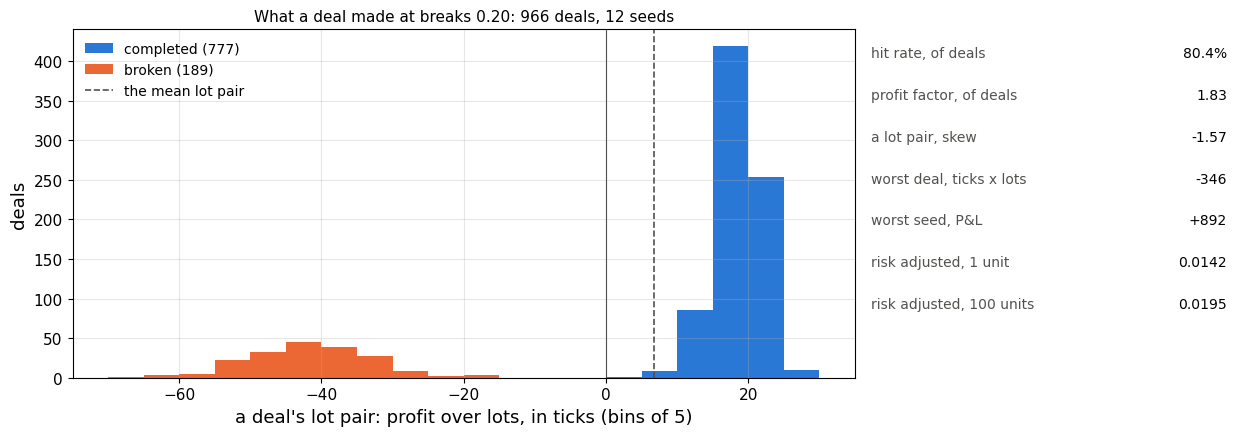

In [19]:
kept = deals_dial_records[(deals_dial_records.row == DEAL_ROW[DEAL_CHOSEN]) & deals_dial_records.kept]
completed, broke = kept[kept.outcome == 'completed'], kept[kept.outcome == 'broken']
at_chosen = deals_dial_frame[deals_dial_frame.row == DEAL_ROW[DEAL_CHOSEN]]
gains, losses = kept.pnl[kept.pnl > 0].sum(), -kept.pnl[kept.pnl < 0].sum()
deals_shape = {
    'deals': len(kept),
    'completed': len(completed),
    'broken': len(broke),
    'share broken': len(broke) / len(kept),
    'completed, mean': completed.pair.mean(),
    'completed, sd': completed.pair.std(),
    'broken, mean': broke.pair.mean(),
    'broken, sd': broke.pair.std(),
    'broken, worst': broke.pair.min(),
    'a lot pair, mean': kept.pair.mean(),
    'a lot pair, se': se_of(kept.pair),
    'a lot pair, sd': kept.pair.std(),
    'a lot pair, skew': stats.skew(kept.pair),
    'hit rate, of deals': (kept.pnl > 0).mean(),
    'profit factor, of deals': gains / losses,
    'worst deal, ticks x lots': kept.pnl.min(),
    "worst deal's loss, in median completed gains": -kept.pnl.min() / completed.pnl.median(),
    'broken deal, in completed deals': -broke.pair.mean() / completed.pair.mean(),
    'worst seed, P&L': at_chosen.pnl.min(),
    'best seed, P&L': at_chosen.pnl.max(),
    'risk adjusted, 1 unit': at_chosen.risk_adjusted.mean(),
    'risk adjusted, 100 units': at_chosen.risk_adjusted_long.mean(),
}
print(
    f'The deals of {DEAL_ROW[DEAL_CHOSEN]}, {len(at_chosen)} seeds, announced early enough to be over by the end of '
    'the run:\n'
)
for name, value in deals_shape.items():
    if isinstance(value, int):  # a count
        print(f'  {name:<40} {value:>12,d}')
    else:
        print(f'  {name:<40} {value:>12,.3f}' if abs(value) < 100 else f'  {name:<40} {value:>12,.0f}')

edges = np.arange(5 * np.floor(kept.pair.min() / 5), 5 * np.ceil(kept.pair.max() / 5) + 5, 5)
fig, (ax, text) = plt.subplots(1, 2, figsize=FIGSIZE_WIDE, gridspec_kw={'width_ratios': [2.2, 1]})
ax.hist(completed.pair, bins=edges, color=BLUE, label=f'completed ({len(completed)})')
ax.hist(broke.pair, bins=edges, color=ORANGE, label=f'broken ({len(broke)})')
ax.axvline(0.0, color=GRAY, lw=0.8)
ax.axvline(kept.pair.mean(), color=GRAY, lw=1.2, ls='--', label='the mean lot pair')
ax.set_xlabel('a deal\'s lot pair: profit over lots, in ticks (bins of 5)')
ax.set_ylabel('deals')
ax.set_title(f'What a deal made at breaks {DEAL_CHOSEN:.2f}: {len(kept)} deals, {len(at_chosen)} seeds', fontsize=11)
ax.legend(frameon=False, fontsize=10, loc='upper left')
shown_in_text = [
    ('hit rate, of deals', '{:.1%}'),
    ('profit factor, of deals', '{:.2f}'),
    ('a lot pair, skew', '{:+.2f}'),
    ('worst deal, ticks x lots', '{:+,.0f}'),
    ('worst seed, P&L', '{:+,.0f}'),
    ('risk adjusted, 1 unit', '{:.4f}'),
    ('risk adjusted, 100 units', '{:.4f}'),
]
text.axis('off')
for place, (name, form) in enumerate(shown_in_text):
    text.text(0.0, 0.92 - 0.12 * place, name, fontsize=10, color=GRAY, transform=text.transAxes)
    text.text(
        1.0, 0.92 - 0.12 * place, form.format(deals_shape[name]), fontsize=10, ha='right', transform=text.transAxes
    )
fig.tight_layout()
plt.show()

**The shape: many small gains and a few larger losses.** Of the 966 deals that the twelve seeds held at 0.20 and that were over by the end of a run, 777 completed and 189 broke, a share of 0.196. A completed deal makes +18.57 a lot pair (sd 3.22) and a broken one loses 41.72 (sd 8.52, worst -69.20): one broken deal wipes out 2.2 completed ones (2.246 as printed), and the broken ones' sd is 2.6 times the completed ones' (a ratio of the printed sds). The two humps do not overlap in the histogram. The mean lot pair, +6.777 (se 0.785), is what the 80% of gains leave after the 20% of losses.

**The skew, the hit rate and the worst deal.** A lot pair's skew is -1.57. The hit rate of deals is 80.4% and their profit factor 1.83: a high hit rate and a modest profit factor, the shape that Mitchell and Pulvino found in merger arbitrage, small gains most of the time and a larger loss at a break. That shape is built into this simulator by the deal's break, so it is not evidence about real mergers. The worst deal lost 346 ticks x lots, 3.64 times the median completed deal's gain.

**A seed's total does not show the loss of its broken deals, and the risk figures do not either.** The worst seed's P&L at this row is +892 and the best is +4,562, around a mean of +2,747 (se 346, in the dial's table), so no seed lost: a seed pools some 81 deals (the 64.8 completed and 16.2 broken a run of the dial's table), and one broken deal's loss is a small part of its total. The notebook prints no skew of a seed's P&L, so it cannot say how nearly symmetric the seeds' totals are, only that none was negative. The risk-adjusted P&L is 0.014 over one unit and 0.019 over 100 units; the 100-unit figure is the larger, as in the dial's table, and neither says anything of the skew. The deals' own figures above are where it shows.

### The Records at a Run's End

A deal's record exists only once both its books are flat after it ends, and a broken deal ends sooner than its planned end, so at a run's end the deals that have a record lean toward the ones that broke: a completed deal announced near the end is still on, with no record, and a broken one of the same age is over. Every per-deal figure above uses the deals announced at least a deal's length and two decisions before the end of the run, which are over whichever way they ended. This table shows what the figure would have been without the cut, on windows of different lengths cut from the dial's own runs at `breaks` 0.20 (records of the deals announced in a window, against those announced early enough to be over by its end), so that the bias a short window has and the one the section's runs have can be read side by side.

In [20]:
WINDOWS = (1_500, 3_000, 5_000, 10_000, 20_000)  # lengths cut from the runs: not what a market is run for
chosen_records = deals_dial_records[deals_dial_records.row == DEAL_ROW[DEAL_CHOSEN]]
lines = []
for window in WINDOWS:
    at_end, cut, bias = [], [], []
    for _, run in chosen_records.groupby('seed'):
        for start in np.arange(0.0, run.end.iloc[0] - window + 1e-9, window):
            here = run[(run.announced >= start) & (run.announced < start + window)]
            over = here[here.flat <= start + window]  # a record that exists when the window ends
            over_by_then = here.announced <= start + window - DEAL_CUT  # whatever happened to the deal
            early = here[over_by_then]
            if len(over) and len(early):
                at_end.append(over)
                cut.append(early)
                bias.append(over.pair.mean() - early.pair.mean())
    if bias:
        over, early = pd.concat(at_end), pd.concat(cut)
        lines.append(
            dict(
                window=window,
                windows=len(bias),
                over=len(over),
                over_broken=(over.outcome == 'broken').mean(),
                over_pair=over.pair.mean(),
                early=len(early),
                early_broken=(early.outcome == 'broken').mean(),
                early_pair=early.pair.mean(),
                bias=over.pair.mean() - early.pair.mean(),
                bias_windows=np.mean(bias),
                bias_se=se_of(pd.Series(bias)),
            )
        )
deals_bias = pd.DataFrame(lines).set_index('window')
print(
    "A lot pair from the records a window ends with, against from the deals announced a deal's length and two "
    'decisions before it ends:\n'
)
print(
    deals_bias.rename(
        columns={
            'over': 'records at end',
            'over_broken': 'broken, at end',
            'over_pair': 'pair, at end',
            'early': 'records cut',
            'early_broken': 'broken, cut',
            'early_pair': 'pair, cut',
            'bias_windows': 'bias, mean of windows',
            'bias_se': 'se',
        }
    ).to_string(float_format=lambda x: f'{x:.3f}' if abs(x) < 10 else f'{x:,.0f}')
)
whole = chosen_records[chosen_records.kept]
print(
    f'\nIn the whole run of {chosen_records.end.mean():,.0f} units the cut drops {len(chosen_records) - len(whole)} of '
    f'{len(chosen_records)} records, and a lot pair is {chosen_records.pair.mean():.2f} without it and '
    f'{whole.pair.mean():.2f} with.'
)

A lot pair from the records a window ends with, against from the deals announced a deal's length and two decisions before it ends:

        windows  records at end  broken, at end  pair, at end  records cut  broken, cut  pair, cut   bias  bias, mean of windows    se
window                                                                                                                                
1500        153             654           0.229         4.839          624        0.194      7.076 -2.237                 -2.224 0.475
3000         72             745           0.205         6.220          729        0.189      7.190 -0.970                 -1.054 0.294
5000         48             887           0.198         6.681          875        0.189      7.279 -0.599                 -0.598 0.179
10000        24             924           0.199         6.592          919        0.195      6.846 -0.255                 -0.254 0.104
20000        12             947           0.196         6.

**The bias is negative at every window length and shrinks as the window lengthens.** The bias is a lot pair from the records at a window's end less one from the cut, so it is negative when the records at the end lean toward the broken deals. It shrinks because the deals near a window's end are a smaller share of a longer window. Averaged over windows, it is -2.224 (se 0.475) at 1,500 units, -1.054 (se 0.294) at 3,000, -0.598 (se 0.179) at 5,000, -0.254 (se 0.104) at 10,000 and -0.139 (se 0.074) at 20,000, over 153, 72, 48, 24 and 12 windows. At 1,500 it is 4.7 standard errors from 0; at 20,000 it is 1.9, which twelve windows do not separate from nothing. The records at a window's end lean toward the broken, by a larger share than the cut's at every length: 0.229 of them broke against 0.194 of the cut's at 1,500 units, 0.205 against 0.189 at 3,000, 0.198 against 0.189 at 5,000, 0.199 against 0.195 at 10,000 and 0.196 against 0.194 at 20,000. At 1,500 units the records at the end give a lot pair of 4.839 against 7.076 from the cut.

**On the section's runs the cut drops 3 of 969 records and moves a lot pair by 0.12.** In the whole run of 20,600 units a lot pair is 6.66 without the cut and 6.78 with it, a difference of 0.12, which is 0.15 of the lot pair's standard error of 0.785 over deals. It costs a few records a run and changes the figure by little, and it is applied anyway; it matters for a short window, where the records that exist at its end are a different set of deals from the ones that are over by then. The line of deals under the card below holds every record of its run, with no cut.

### Late Entry

The control again, `breaks` 0.40, where the trade has no edge, with an entry of 24 ticks of gap instead of 0. The opening gap of a deal is about the premium less what the announcement has already moved the target, 24 ticks, and the mids' noise is a few ticks, so a trader that waits for 24 enters only when the mids' noise puts the gap at or above its opening size: some deals at their first decision, some later after a wait, and some not at all. The table compares it with entry 0 on the same deals: the dial's own control row, restricted to these eight seeds, in which every deal is entered at the first decision (the cell asserts that). Whether the late entries earn more than the same deals entered at the first decision is the question, and then whether that is the deal or the mids: the second route reads the target's and the acquirer's fair values at the exact times, with no books and no trader, so no mid's noise is in it. The cell also prints the two by seed.

In [21]:
LATE = 'entry 24'
deals_late_frame = run_rows({LATE: (dealing(DEAL_PRICED), dealer(entry=24.0))}, FEW, DEAL_BURN, extra=deal_extra)
assert (deals_late_frame.not_flat == 0).all(), 'a deal was entered with a book of its that was not flat'
control = deals_dial_frame[(deals_dial_frame.row == DEAL_CONTROL) & deals_dial_frame.seed.isin(FEW)].assign(
    row='entry 0'
)
late_both = pd.concat([control, deals_late_frame], ignore_index=True)

# Every deal that any dial row's trader held was entered at its first decision: within one decision of the announcement.
# A decision waits for the next event once its interval is up, and the clock's tail runs it a few thousandths of a unit
# past DEAL_FIRST now and then, so the check has a tenth of a unit of slack. A deal that skipped a decision would have
# waited five units more.
CLOCK_SLACK = 0.1  # units of time
waited = deals_dial_records.entered - deals_dial_records.announced
assert waited.max() <= DEAL_FIRST + CLOCK_SLACK, f'a deal was entered {waited.max():.2f} units after its announcement'
print(
    f'At entry 0, the longest a deal waited to be entered, over {len(deals_dial_records):,} records: '
    f'{waited.max():.2f} units (one decision is {DEAL_FIRST:.2f}).\n'
)

late_records = deal_records(late_both)
late_records['wait'] = late_records.entered - late_records.announced
# Late is a wait of more than one decision, with no slack: a deal entered at the second decision after its announcement
# waited a decision (5 units) more than at the first, and slack of a tenth would call one such entry in fifty a first.
late_records['late'] = late_records.wait > DEAL_FIRST + 1e-9
late_records['key'] = list(zip(late_records.seed, late_records.target, late_records.announced, strict=True))
mine = late_records[late_records.kept]
control_deals = mine[mine.row == 'entry 0'].set_index('key')
entered = mine[mine.row == LATE].set_index('key')
deals_late_matched = entered.join(control_deals, rsuffix='_0', how='inner')
deals_late_matched['more'] = deals_late_matched.pair - deals_late_matched.pair_0  # entry 24 less entry 0, same deal
deals_late_ones = deals_late_matched[deals_late_matched.late]

deals_late_table = table_of(late_both, also=('completed', 'broken')).join(lot_pairs(late_records))
deals_late_table['entered'] = mine.groupby('row').size()
deals_late_table['at_first'] = mine[~mine.late].groupby('row').size()
deals_late_table['later'] = mine[mine.late].groupby('row').size().reindex(deals_late_table.index, fill_value=0)
deals_late_table['wait'] = mine[mine.late].groupby('row').wait.mean()
print('The control at entry 0 and at entry 24, on the same seeds and the same deals:\n')
print(
    shown(
        deals_late_table,
        keep=[
            'pnl',
            'se',
            'positive',
            'before_costs',
            'costs',
            'entered',
            'at_first',
            'later',
            'wait',
            'pair',
            'pair_se',
        ],
        entered=',.0f',
        at_first=',.0f',
        later=',.0f',
        wait='.1f',
    )
)
print(f'\nentry 24 less entry 0, P&L: {said(paired(late_both, LATE, "entry 0"))}')
on_both, on_late = deals_late_matched, deals_late_ones
print(
    f'On the {len(on_both)} deals both entered, a lot pair with entry 24 less entry 0: {on_both.more.mean():+.2f} '
    f'(se {se_of(on_both.more):.2f}); on the {len(on_late)} that it entered late: {on_late.more.mean():+.2f} '
    f'(se {se_of(on_late.more):.2f}), positive in {(on_late.more.groupby(on_late.seed).mean() > 0).sum()} of '
    f'{on_late.seed.nunique()} seeds.'
)


def fair_gains(seed, entries):
    # The same late entries at fair values alone (no books, no trader, no mids): for each (time entry 0 entered, time
    # entry 24 did, target, acquirer, time announced), what a lot pair is worth more entered at the second time, from
    # the fair values at those exact times: the pair's move between them, with the sign turned, long the target and
    # short rint(DEAL_SIZE x r) / DEAL_SIZE of the acquirer, to the deal's end.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    fair = FactorValues(LOADINGS['sectors'], deals=Deals(rate=DEAL_RATE, breaks=DEAL_PRICED, **DEALS))
    fair.reseed(seed)
    at, ratio = {}, {}
    for t in sorted({t for entry in entries for t in entry[:2]}):
        fair.advance_to(t)
        at[t] = fair.values()
        for deal in fair.deals:
            ratio[(deal.target, round(deal.announced, 3))] = deal.ratio
    out = []
    for first, later, target, acquirer, announced in entries:
        if (target, announced) in ratio:  # the deal was on at fair values at those times
            hedge = np.rint(DEAL_SIZE * ratio[(target, announced)]) / DEAL_SIZE
            out.append(-((at[later][target] - at[first][target]) - hedge * (at[later][acquirer] - at[first][acquirer])))
    return out


jobs = [
    [
        (row.entered_0, row.entered, row.target, row.acquirer, row.announced)
        for row in deals_late_ones[deals_late_ones.seed == seed].reset_index().itertuples()
    ]
    for seed in sorted(FEW)
]
deals_late_gains = [
    gain
    for part in Parallel(n_jobs=-1)(
        delayed(fair_gains)(seed, entries) for seed, entries in zip(sorted(FEW), jobs, strict=True)
    )
    for gain in part
]
fair_more = pd.Series(deals_late_gains)
print(
    f'The same {len(fair_more)} late entries at fair values alone, with no books and no trader: '
    f'{fair_more.mean():+.2f} (se {se_of(fair_more):.2f}) a lot pair more than entering at the first decision.'
)

# What the mids add to a late entry's gain over the fair values: the same entries in the same order (by seed, then as
# they stand in deals_late_ones, which is the order the jobs above were made in), so the two sit side by side by seed.
late_in_order = pd.concat([deals_late_ones[deals_late_ones.seed == seed] for seed in sorted(FEW)])
if len(late_in_order) != len(fair_more):
    print(f'{len(late_in_order)} late entries at the mids, {len(fair_more)} at fair values: not side by side by seed.')
else:
    late_both_ways = pd.DataFrame(
        {
            'seed': late_in_order.seed.to_numpy(),
            'mids': late_in_order.more.to_numpy(),
            'fair_values': fair_more.to_numpy(),
        }
    )
    late_both_ways['mids_add'] = late_both_ways.mids - late_both_ways.fair_values
    late_by_seed = late_both_ways.groupby('seed').agg(
        entries=('mids', 'size'),
        mids=('mids', 'mean'),
        fair_values=('fair_values', 'mean'),
        mids_add=('mids_add', 'mean'),
    )
    late_formats = {'entries': '{:.0f}'.format, **{c: '{:+.2f}'.format for c in ('mids', 'fair_values', 'mids_add')}}
    print('\nWhat the mids add to a late entry, by seed: a lot pair at the mids less a lot pair at fair values:\n')
    print(late_by_seed.to_string(formatters=late_formats))
    print(
        f"\nWhat the mids add, the mean over the {len(late_by_seed)} seeds of each seed's mean: "
        f'{late_by_seed.mids_add.mean():+.2f} (se {se_of(late_by_seed.mids_add):.2f} over the seeds, '
        f'{int((late_by_seed.mids_add > 0).sum())} of {len(late_by_seed)} seeds positive).'
    )
ran(deals_late_frame)

At entry 0, the longest a deal waited to be entered, over 6,783 records: 5.01 units (one decision is 5.03).

The control at entry 0 and at entry 24, on the same seeds and the same deals:

            pnl  se positive before_costs costs entered at_first later wait  pair pair_se
row                                                                                      
entry 0  -2,124 454   0 of 8         -185 1,940     635      635     0  NaN -5.80    1.20
entry 24 -1,380 487   2 of 8          407 1,787     571      312   259 21.6 -4.33    1.28

entry 24 less entry 0, P&L: +744 (se 137, 8 of 8 seeds positive)
On the 571 deals both entered, a lot pair with entry 24 less entry 0: +0.97 (se 0.15); on the 259 that it entered late: +1.54 (se 0.23), positive in 8 of 8 seeds.


The same 259 late entries at fair values alone, with no books and no trader: -0.28 (se 0.11) a lot pair more than entering at the first decision.

What the mids add to a late entry, by seed: a lot pair at the mids less a lot pair at fair values:

     entries  mids fair_values mids_add
seed                                   
101       32 +1.96       -0.02    +1.97
102       37 +1.59       -0.32    +1.91
103       22 +1.51       -0.27    +1.78
104       33 +1.07       -0.90    +1.97
105       36 +0.77       -0.25    +1.03
106       31 +1.74       -0.17    +1.91
107       39 +2.09       -0.17    +2.26
108       29 +1.54       -0.15    +1.69

What the mids add, the mean over the 8 seeds of each seed's mean: +1.81 (se 0.13 over the seeds, 8 of 8 seeds positive).
8 runs, 3.9 core-minutes.


**Entry 0 is every deal at the first decision.** Over the 6,783 records of the dial's rows the longest a deal waited to be entered was 5.01 units, where one decision is 5.03, and the cell asserts it. So the section's entry of 0 is "every deal at the first decision" by construction, and not a tuned setting.

**The late entry enters fewer deals, some after a wait, and loses less.** With an entry of 24 ticks of gap the trader enters 571 of the 635 deals that entry 0 enters, 64 fewer: 312 of them at the first decision and 259 later, after a mean wait of 21.6 units. Its P&L is -1,380 (se 487, 2 of 8 seeds positive) against -2,124 (se 454, 0 of 8) at entry 0, a paired difference of +744 (se 137, 8 of 8 seeds positive). Before costs it makes +407 against -185, and its costs are 1,787 against 1,940. A lot pair is -4.33 (se 1.28) against -5.80 (se 1.20), over different sets of deals. So waiting for a wider gap loses less and still loses: the control has no premium to collect, and a late entry does not find one.

**The late entries earn more than the same deals entered at the first decision, on every seed.** On the 571 deals both enter, a lot pair with entry 24 is +0.97 (se 0.15) more than with entry 0; on the 259 that it entered late it is +1.54 (se 0.23) more, positive on 8 of 8 seeds. That is less than a third of the 5.00 that a lot pair costs (four spreads at 1.25).

**It is the mids, not the deal.** At fair values alone, with no books and no trader, the same 259 late entries are worth 0.28 less a lot pair than entering at the first decision (-0.28, se 0.11): about 2.5 standard errors below 0, not above it. So the deal's own fair values do not pay a late entry anything extra, and the +1.54 in the mids is 1.82 more than they do (a plain difference over the same entries). By seed it is the same on every one: a seed's late entries make +0.77 to +2.09 a lot pair more than entering at the first decision in the mids and -0.90 to -0.02 at fair values, so what the mids add (the one less the other) is positive on all eight seeds, +1.03 to +2.26, and its mean over the seeds is +1.81 (se 0.13). That is the mean of the eight seeds' own means, which is why it is not the 1.82 of the pooled figures. What is left is the mids' noise around their fair values: a late entry is made when the gap in the mids is wide, which happens when a mid is off its fair value, and what it earns more in the mids is that. This is the sense in which "before costs" is not an edge here, and the +744 is no signal about the deal. One reading of the sign at fair values is that a deal still on at the later time has not broken, and its target's fair value has drifted toward the offer since the first decision, which a late entry misses. By the model's arithmetic that is so (the target's fair value of a deal that has not broken rises toward the offer as the deal's time runs out), so a negative sign at fair values is what the model leads one to expect, and the +0.00 that seeds 1 to 8 gave is the figure that was not expected; the notebook does not measure the drift, so it does not test the reading.

### Pairs and Deals

Notebook 12's pairs trader, in a market with deals. A pair is chosen for a relation between two books that the factors do not enter; a deal moves its target's fair value by tens of ticks for a reason that has nothing to do with that relation, and a completed deal never comes back. So a pair that holds the target of a deal sees its spread jump at the announcement, and a z-score trader that enters on it is short the target (the spread is above its window), which is the same side as the deal trader's counterparty. From the announcement to the deal's end the target's fair value is expected to move by `premium x (priced - breaks)` more than it was priced to: nothing when the price is fair, and the deal trader's edge with its sign turned when `breaks` is below `priced`. So what ignoring the news costs a pairs trader may depend on whether the gap is fairly priced, and the table is run at two values of `breaks`.

**The traders, all notebook 12's pairs by distance** (eight pairs, 2.5 lots of each, a window of 400 decisions, entering at a z-score of 2, choosing from the first 2,000 decisions), in the sectors market with deals announced at 0.002 a unit, alone in the market:

- *blind*: a `RelationTrader`, which does not read the news;
- *a reader out for the deal's life*: a `NewsAwareTrader` with a quarantine of 0, flat in every relation that holds the target of a deal that is on and trading again as soon as the deal is over;
- *a reader out until the step has left its window*: a `NewsAwareTrader` at its default quarantine, one window of decisions, so that when it ends the window holds no decision from before the deal's end.

A reader is flat in a relation that holds a deal's *target* only. A deal moves the target's fair value and not the acquirer's in this simulator, so a pair that holds the acquirer alone is not disturbed by it; `acquirers=True` brings back the rule of a market where acquirers move too, and is not a row here. The no-deals row is the same pairs trader in a market with no deals.

**Seeds and burn.** A trader that chooses its pairs from a formation of 2,000 decisions has a warm-up of about 10,000 units, so the burn is notebook 13's, 10,465, and the span is 20,000. The no-deals row is notebook 13's pairs row, the same trader in the same market over the same window on seeds 101 to 112, and is run on all twelve of them so that the cell can assert that it gives notebook 13's number: those are the same runs and not a replication. The other rows are on seeds 101 to 108.

**What the cell checks.** The three traders of one dial value and seed see the same deals, and the deals that break at 0.20 break at 0.40; they choose the same pairs (a reader reads the news only after choosing them); a reader holds no lots of a deal's target at any decision from the announcement until the deal is over, nor, with a quarantine, until that is over too (a reader with no quarantine may be back in a target's pairs as soon as its deal has broken). It then prints, for the blind trader, how many deals a run it holds the target of and on which side, and the arithmetic of the bet: `premium x (priced - breaks)` ticks a lot, times the net short lots it holds of targets. The deal counts here are over the burn and the span (30,465 units); the P&L is over the span. It then splits the differences of P&L that matter by where the P&L was made, in the targets' books while their deals are on and everywhere else, and the paragraph on the bet says what each part holds. The split was added to the cell after the first run.

In [22]:
DEAL_PAIRS_BURN = PAIRS_BURN  # notebook 13's: the warm-up of its pairs and 400 more
PAIRS_QUARANTINE = pairs_by(NewsAwareTrader)().quarantine  # one window of decisions
BLIND, READER_0, READER_Q = 'blind', 'reader, quarantine 0', f'reader, quarantine {PAIRS_QUARANTINE:,.0f}'
PAIRS_DIAL = (0.40, 0.20)  # `breaks` of the two markets; `priced` is 0.40 in both


def pairs_extra(market, trader, burn):
    # What a run of a pairs trader leaves to read, in the worker: the deals (all of them, with how each ended), the
    # pairs the trader chose (as the books of each, and as whole rows of weights), and for each deal announced in the
    # span two things. `held_on`: the decisions at which the trader held lots of the deal's target from the announcement
    # until the deal was over, and for a reader until its quarantine after that was over too (as the reader itself
    # counts it), which for a reader must be none. And, for a deal over by the run's end, the lots of the target it held
    # two decisions after the announcement (the first decision at or after it, and two more): a blind trader's bet. A
    # deal that broke before then is over by that decision, and a reader with no quarantine may be in its books again.
    # And `target_on`: the P&L of the targets' books from each such deal's announcement to two units after its end, at
    # the decisions' mids and before the spread paid, summed over the deals: where the bet is made.
    ended, on = market.fair.ended, market.fair.deals
    times = np.array([h[0] for h in trader.history])
    held = np.array([h[2] for h in trader.history], dtype=float)
    mids = np.array([h[1] for h in trader.history], dtype=float)  # the books' mids each decision saw, before it
    quarantine = getattr(trader, 'quarantine', 0.0)
    held_on, lots, target_on = 0, [], 0.0
    for deal in (*ended, *on):
        if deal.announced < burn:
            continue
        out = times >= deal.announced
        if deal.ended_at is not None:
            out &= times - deal.ended_at < quarantine
        held_on += int(np.count_nonzero(held[out, deal.target]))
        first = int(np.searchsorted(times, deal.announced))  # the first decision at or after the announcement
        if deal.ended_at is not None and first + 3 < len(times):
            lots.append(held[first + 2, deal.target])
        if deal.ended_at is not None and deal.ended_at + 2.0 < times[-1]:
            # The target's book while the deal is on, to two units after it ends: the lots held after each decision
            # times the move of that book's mid to the next decision. At the decisions' mids, before the spread paid.
            window = np.nonzero((times[:-1] >= deal.announced) & (times[:-1] < deal.ended_at + 2.0))[0]
            move = mids[window + 1, deal.target] - mids[window, deal.target]
            target_on += float(np.sum(held[window, deal.target] * move))
    return dict(
        completed=sum(d.outcome == 'completed' for d in ended),
        broken=sum(d.outcome == 'broken' for d in ended),
        on=len(on),
        end=market.time,
        deals=tuple((d.target, d.acquirer, round(d.announced, 3), d.outcome) for d in (*ended, *on)),
        pairs=tuple(tuple(int(book) for book in np.nonzero(w)[0]) for w in trader.weights),
        weights=tuple(tuple(float(x) for x in w) for w in trader.weights),  # the whole rows, hedges included
        held_on=held_on,
        counted=len(lots),
        held_n=sum(lot != 0 for lot in lots),
        short_n=sum(lot < 0 for lot in lots),
        long_n=sum(lot > 0 for lot in lots),
        net_short=-float(sum(lots)),
        target_on=target_on,
        mean_lots=float(np.mean([abs(lot) for lot in lots if lot != 0])) if any(lot != 0 for lot in lots) else 0.0,
    )


def pairs_row(breaks, kind, **settings):
    # A market (with no deals if `breaks` is None) and a pairs trader that keeps a record of its decisions.
    market = market_of('sectors') if breaks is None else dealing(breaks, rate=PAIRS_DEAL_RATE)
    return market, pairs_by(kind, record=True, **settings)


def three_of(b):
    return [f'{BLIND}, breaks {b:.2f}', f'{READER_0}, breaks {b:.2f}', f'{READER_Q}, breaks {b:.2f}']


deals_pairs_rows = {}
for b in PAIRS_DIAL:
    blind, reader_0, reader_q = three_of(b)
    deals_pairs_rows[blind] = pairs_row(b, RelationTrader)
    deals_pairs_rows[reader_0] = pairs_row(b, NewsAwareTrader, quarantine=0.0)
    deals_pairs_rows[reader_q] = pairs_row(b, NewsAwareTrader)
read_pairs = partial(pairs_extra, burn=DEAL_PAIRS_BURN)
deals_nodeals_frame = run_rows({'no deals': pairs_row(None, RelationTrader)}, SEEDS, DEAL_PAIRS_BURN, extra=read_pairs)
deals_readers_frame = run_rows(deals_pairs_rows, FEW, DEAL_PAIRS_BURN, extra=read_pairs)
deals_nodeals_few = deals_nodeals_frame[deals_nodeals_frame.seed.isin(FEW)]
deals_pairs_frame = pd.concat([deals_nodeals_few, deals_readers_frame], ignore_index=True)

# What must hold for the table to mean anything.
for b in PAIRS_DIAL:
    check_deals(deals_pairs_frame, three_of(b))  # the same deals, and the broken ones, for the three traders ...
    check_deals(deals_pairs_frame, three_of(b)[::-1])  # ... both ways
    for seed, runs in deals_pairs_frame[deals_pairs_frame.row.isin(three_of(b))].groupby('seed'):
        assert runs.pairs.nunique() == 1, f'seed {seed}, breaks {b}: the three traders did not choose the same pairs'
check_deals(deals_pairs_frame, [three_of(b)[0] for b in sorted(PAIRS_DIAL)])  # the same deals at both values, nested
assert (deals_pairs_frame.pairs.map(len) == 8).all(), 'a trader chose other than eight pairs'
reading = deals_pairs_frame[deals_pairs_frame.row.str.startswith('reader')]
caught = reading[reading.held_on > 0]
assert caught.empty, (
    "a reader held lots of a deal's target while the deal was on or in its quarantine (row, seed, decisions): "
    f'{[(row, int(seed), int(n)) for row, seed, n in zip(caught.row, caught.seed, caught.held_on, strict=True)]}'
)
print(
    'Checked: the same deals for the three traders and at both values of breaks (the broken ones nested), the same '
    "pairs for the three traders, and no reader holding a deal's target.\n"
)

# The no-deals row is notebook 13's pairs row.
nodeals = deals_nodeals_frame.pnl
saved = notebook_13_row('pairs by distance, 8 (notebook 12)')
if SMOKE:
    print(
        f'No deals, {len(nodeals)} seeds: {nodeals.mean():+,.0f} (se {se_of(nodeals):.0f}); not compared with '
        "notebook 13 in a smoke copy."
    )
elif saved is None:
    print('Notebook 13 has no saved output with its pairs row: the no-deals row is not compared with it.')
else:
    pnl13, se13, _, seeds13 = saved
    assert len(nodeals) == seeds13 and abs(nodeals.mean() - pnl13) <= 0.5 and abs(se_of(nodeals) - se13) <= 0.5, (
        f"the no-deals row is {nodeals.mean():,.0f} (se {se_of(nodeals):.0f}) and notebook 13's pairs row "
        f'{pnl13:,.0f} (se {se13:.0f}): not the same runs. Is notebook 13 saved from other settings?'
    )
    print(
        f"No deals, {len(nodeals)} seeds: {nodeals.mean():+,.0f} (se {se_of(nodeals):.0f}), which is notebook 13's "
        f'pairs row ({pnl13:+,.0f}, se {se13:.0f}): the same runs, on the same seeds and burn, and not a replication.'
    )

deals_pairs_table = table_of(deals_pairs_frame, also=('completed', 'broken', 'on'))
deals_pairs_table = deals_pairs_table.loc[['no deals', *(row for b in PAIRS_DIAL for row in three_of(b))]]
print(
    f'\nThe pairs trader in a market with deals announced at {PAIRS_DEAL_RATE} a unit, {len(FEW)} seeds, '
    f'burn {DEAL_PAIRS_BURN:,.0f}:\n'
)
print(
    shown(
        deals_pairs_table,
        'cost_an_entry',
        add=['completed', 'broken', 'on'],
        completed='.1f',
        broken='.1f',
        on='.1f',
    )
)
print('\ncompleted, broken and on are deals a run over the burn and the span: ended, and still on at the end.')

less_blind = {}
for b in PAIRS_DIAL:
    blind, reader_0, reader_q = three_of(b)
    less_blind[f'{reader_0} less blind, breaks {b:.2f}'] = (reader_0, blind)
    less_blind[f'{reader_q} less blind, breaks {b:.2f}'] = (reader_q, blind)
less_blind['no deals less blind, breaks 0.40'] = ('no deals', three_of(PAIRS_DIAL[0])[0])
print('\nEach row less the blind trader at the same value of breaks, seed by seed:\n')
print(
    shown_paired(
        paired_table(deals_pairs_frame, less_blind, 'before_costs', 'costs', 'risk_adjusted_long'),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)
print()
ran(deals_nodeals_frame, deals_readers_frame)

Checked: the same deals for the three traders and at both values of breaks (the broken ones nested), the same pairs for the three traders, and no reader holding a deal's target.

No deals, 12 seeds: +5,706 (se 81), which is notebook 13's pairs row (+5,706, se 81): the same runs, on the same seeds and burn, and not a replication.

The pairs trader in a market with deals announced at 0.002 a unit, 8 seeds, burn 10,465:

                                         pnl  se positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                                   
no deals                              +5,703 118   8 of 8        8,544 2,841   272.4 2,397       1.19   8.3     0.92      4.12           3.29       

In [23]:
# The bet a blind pairs trader makes, and what the dial does to it. `fair` is the value of breaks at which the price is
# the true chance, and `cheap` the one at which the market overprices a break.
fair, cheap = PAIRS_DIAL
blind_at = {b: three_of(b)[0] for b in PAIRS_DIAL}
pnl_by = deals_pairs_frame.pivot(index='seed', columns='row', values='pnl')
deals_bet = {}
for b in PAIRS_DIAL:
    runs = deals_pairs_frame[deals_pairs_frame.row == blind_at[b]]
    edge = DEAL_PREMIUM * (DEAL_PRICED - b)
    deals_bet[b] = dict(
        deals=runs.counted.mean(),
        held=runs.held_n.mean(),
        short=runs.short_n.mean(),
        long=runs.long_n.mean(),
        lots=runs.mean_lots.mean(),
        net_short=runs.net_short.mean(),
        edge=edge,
        bet=-edge * runs.net_short.mean(),
    )
print(
    'The blind trader, a run: deals announced in the span and over by its end, how many it holds the target of two '
    'decisions after the announcement, on which side, the lots it holds then (a pair holds a few) and in all (net '
    'short), and the arithmetic of the bet: -edge x net short lots.\n'
)
formats = {name: '{:.1f}'.format for name in ('deals', 'held', 'short', 'long', 'net_short', 'edge')}
print(
    pd.DataFrame(deals_bet)
    .T.rename_axis('breaks')
    .to_string(formatters={**formats, 'lots': '{:.2f}'.format, 'bet': '{:+,.0f}'.format})
)

print(
    f'\nThe blind row at breaks {cheap:.2f} less at {fair:.2f}, seed by seed: '
    f'{said(paired(deals_pairs_frame, blind_at[cheap], blind_at[fair]))}; '
    f'the arithmetic of the bet alone: {deals_bet[cheap]["bet"] - deals_bet[fair]["bet"]:+,.0f}.'
)
for reader in (READER_0, READER_Q):
    one, other = f'{reader}, breaks {cheap:.2f}', f'{reader}, breaks {fair:.2f}'
    print(f'The {reader} row at breaks {cheap:.2f} less at {fair:.2f}: {said(paired(deals_pairs_frame, one, other))}.')
for reader in (READER_0, READER_Q):
    one, other = f'{reader}, breaks {cheap:.2f}', f'{reader}, breaks {fair:.2f}'
    difference = (pnl_by[one] - pnl_by[blind_at[cheap]]) - (pnl_by[other] - pnl_by[blind_at[fair]])
    print(
        f'{reader} less blind, at {cheap:.2f} less at {fair:.2f}: {difference.mean():+,.0f} '
        f'(se {se_of(difference):.0f}, {int((difference > 0).sum())} of {len(difference)} seeds positive).'
    )

# Each trader chooses its pairs from the mids of its own world, and the two values of breaks are two worlds.
deals_in_common = []
for seed in sorted(FEW):
    chose = {
        b: set(
            deals_pairs_frame[(deals_pairs_frame.seed == seed) & (deals_pairs_frame.row == blind_at[b])].pairs.iloc[0]
        )
        for b in PAIRS_DIAL
    }
    deals_in_common.append(len(chose[fair] & chose[cheap]))
print(f"\nPairs in common between the blind trader's eight at the two values of breaks, by seed: {deals_in_common}.")


def said_split(frame, one, other):
    # One row less another, seed by seed, split by where the P&L was made: in the targets' books from a deal's
    # announcement to two units after its end (`target_on`, at the decisions' mids, before the spread paid), and
    # everywhere else (the rest of the P&L, so that the two add to the row's P&L less the other's).
    frame = frame.assign(elsewhere=frame.pnl - frame.target_on)
    inside, outside = paired(frame, one, other, 'target_on'), paired(frame, one, other, 'elsewhere')
    return f"in the targets' books while their deals are on {said(inside)}; everywhere else {said(outside)}"


print(
    "\nThe same differences split by where the P&L was made: in the targets' books while their deals are on (for each "
    'deal announced in the span and over by its end: the lots held after each decision from the announcement to two '
    "units after the end, times the move of the target's mid to the next decision, at the decisions' mids and before "
    'the spread paid), and everywhere else (the P&L, which is after the spread paid, less that: so it holds the '
    "spread paid in those books too, the jump at an announcement on the lots held before it, the deals still on at the "
    'end, and the rest of the books and times):'
)
print(
    f'The blind row at breaks {cheap:.2f} less at {fair:.2f}: '
    f'{said_split(deals_pairs_frame, blind_at[cheap], blind_at[fair])}.'
)
for reader in (READER_0, READER_Q):
    one, other = f'{reader}, breaks {cheap:.2f}', f'{reader}, breaks {fair:.2f}'
    print(f'The {reader} row at breaks {cheap:.2f} less at {fair:.2f}: {said_split(deals_pairs_frame, one, other)}.')
for reader in (READER_0, READER_Q):
    for b in PAIRS_DIAL:
        one, other = f'{reader}, breaks {b:.2f}', blind_at[b]
        print(
            f'The {reader} row less the blind trader, at breaks {b:.2f}: {said_split(deals_pairs_frame, one, other)}.'
        )

The blind trader, a run: deals announced in the span and over by its end, how many it holds the target of two decisions after the announcement, on which side, the lots it holds then (a pair holds a few) and in all (net short), and the arithmetic of the bet: -edge x net short lots.

       deals held short long lots net_short edge  bet
breaks                                               
0.4     37.5 22.6  21.2  1.4 3.80      80.1  0.0   -0
0.2     37.2 24.1  20.4  3.8 2.97      57.9 12.0 -694

The blind row at breaks 0.20 less at 0.40, seed by seed: -1,207 (se 178, 0 of 8 seeds positive); the arithmetic of the bet alone: -694.
The reader, quarantine 0 row at breaks 0.20 less at 0.40: -659 (se 301, 2 of 8 seeds positive).
The reader, quarantine 2,012 row at breaks 0.20 less at 0.40: -427 (se 180, 3 of 8 seeds positive).
reader, quarantine 0 less blind, at 0.20 less at 0.40: +548 (se 367, 5 of 8 seeds positive).
reader, quarantine 2,012 less blind, at 0.20 less at 0.40: +780 (se 278, 6 

**Deals take most of a pairs trader's P&L, at a fair price.** At `breaks` 0.40 the blind trader, which does not read the news, makes +2,044 (se 272, 8 of 8 seeds positive) against +5,703 (se 118, 8 of 8) with no deals, and the paired difference, no deals less blind, is +3,659 (se 344, 8 of 8): before costs +5,093 (se 392) and costs +1,433 (se 68). That is about 64% of the no-deals P&L (3,659 over 5,703). The blind trader makes 138.4 entries a run against 272.4, holds 15.5 lots gross against 8.3, has a `deviation_long` of 7.42 against 3.29, and a `risk_adjusted_long` of 0.014 against 0.087. So deals take much of the P&L and about half of the round trips, and more than double the risk over 100 units, at a price at which there is no bet to lose. What deals take at a fair price is therefore not a premium; the reading is that a jump in a target, which has nothing to do with the pair's relation, disturbs the pairs' own trade, and the notebook shows the loss and not the mechanism. The no-deals row is notebook 13's pairs row, the same runs: +5,706 (se 81) on its twelve seeds, +5,703 (se 118) on these eight.

**The bet: a blind pairs trader holds the deal trader's counterparty side.** Of the 37.5 deals a run announced in the span and over by its end at 0.40 (37.2 at 0.20), the blind trader holds the target two decisions after the announcement in 22.6 (24.1 at 0.20), short in 21.2 (20.4) and long in 1.4 (3.8). A z-score pair that holds a target finds its spread far above its window after the jump, so it is short, the same side as the deal trader's counterparty. The lots it holds then are 3.80 (2.97), a pair holding a few, and 80.1 (57.9) net short in all. At 0.40 the bet is fair, `edge` 0 and a bet of 0. At 0.20 `edge` is 12.0 ticks a lot, and the arithmetic of the bet, 12.0 times 57.9 net short lots, puts it at -694 a run against the trader. That is the model's arithmetic from the lots the cell prints. The lines printed below the pairs in common measure where the P&L was made. Each splits a difference of P&L, seed by seed, into the P&L in the targets' books while their deals are on and everywhere else. The first is made, for each deal announced in the span and over by the run's end, from the lots held after each decision from the announcement to two units after the deal's end, times the move of the target's mid to the next decision, so it is at the decisions' mids and before the spread paid. The rest of the P&L, which is after the spread paid, is everywhere else: it holds the spread paid in those books, the jump at an announcement on the lots held before it, the deals still on at the end, and every other book and time. So the split is measured and the bet's arithmetic is the model's, and the two agree: the blind trader at 0.20 less at 0.40 is -686 (se 194, 0 of 8 seeds positive) in the targets' books while the deals are on, 8 from the arithmetic's -694 (a plain difference), and -521 (se 125, 0 of 8) everywhere else.

**The blind row's fall across the dial is more than the bet, and all three traders fall.** The blind trader at 0.20 less at 0.40 is -1,207 (se 178, 0 of 8 seeds positive), against -694 for the bet alone: the bet is about 57% of the fall (694 over 1,207, a plain ratio), and 513 of it is not the bet. By the split, 686 of the fall is in the targets' books while the deals are on, as the bet is, and 521 is everywhere else. The reader out for the deal falls -659 (se 301, 2 of 8 positive) and the reader at the default quarantine -427 (se 180, 3 of 8), 2.2 and 2.4 standard errors from 0, though a reader holds none of a deal's target while the deal is on and has no bet to lose. By the split their falls are not made in the targets' books while the deals are on, where the two rows change by a few ticks (+12, se 5, 7 of 8 seeds positive, and +0, se 0), but everywhere else (-671, se 298, 2 of 8, and -427, se 180, 3 of 8). The traders at the two values of `breaks` are not one trader on one set of pairs. Each chooses its pairs from the mids of its own world, and the worlds differ by then: the pairs in common between the blind trader's eight at the two values are 4, 5, 6, 6, 4, 6, 3 and 5 by seed, and on no seed are the eight the same. This table does not hold the pairs fixed. It shows that the pairs differ and that the readers fall too. The next cell holds them fixed and splits the fall: with the pairs of 0.40 in the market of 0.20 the blind trader is 761 (se 186) below its row at 0.40. That cell prints the lots it holds on these pairs, 72.8 net short, so that the bet's arithmetic on them is 873; the fall is 112 less than that (a plain difference), 0.6 of its standard error, and by the split the targets' books while the deals are on are 880 lower (se 193, 0 of 8 seeds positive) and everywhere else 119 higher (se 185, 5 of 8 seeds positive). The readers are 24 (se 115) below and 63 (se 40) above theirs, so their falls here were the pairs; the pairs of 0.40 do 446 (se 143) better for the blind trader than the pairs the market of 0.20 chose, and that is made everywhere else (+640, se 158, 7 of 8), the targets' books while the deals are on showing nothing that eight seeds separate from 0 (-194, se 153, 3 of 8). The fall of a row across the dial, on each trader's own pairs, is therefore not the cost of the bet alone: the part of it in the targets' books while the deals are on is about the bet, and the rest is the pairs. Compare traders within one value of `breaks`, and state the bet from its arithmetic, the lots and the split. As on seeds 1 to 8, the fall is larger than the bet and the readers fall.

**Reading the news: where the gap is fairly priced the default quarantine costs, and nothing else is separated from the blind trader.** At 0.40 the reader out for the deal makes -119 (se 217, 4 of 8 seeds positive) less than the blind trader, which is 0.5 standard errors from 0, with costs -124 (se 44), before costs -244 (se 244) and `risk_adjusted_long` +0.005 (se 0.002). The reader at the default quarantine of 2,012 units makes -692 (se 164, 0 of 8), 4.2 standard errors from 0, with costs -591 (se 47), before costs -1,283 (se 159) and `risk_adjusted_long` +0.007 (se 0.003). It makes 85.9 entries a run against the blind trader's 138.4 and holds 4.3 lots gross against 15.5: it gives up trades in the books of deals that are on, and the longer quarantine gives up more. At 0.20 the reader out for the deal is +429 (se 256, 5 of 8) less than the blind trader, 1.7 standard errors from 0, with before costs +255 (se 287) and costs -174 (se 57); the default reader is +88 (se 295, 3 of 8), nothing. By the split the +429 is +693 (se 295, 7 of 8 seeds positive) in the targets' books while the deals are on, 1 less than the bet's arithmetic of 694 (a plain difference), and -264 (se 201, 2 of 8) everywhere else, and the +88 is +689 (se 292, 7 of 8) and -601 (se 329, 3 of 8). So the reader is ahead where the blind trader's bet is and behind elsewhere, by 1.3 standard errors from 0 for the reader out for the deal and 1.8 for the default reader (plain ratios); the two parts are one difference split, and the whole is the comparison a trader would face. Eight seeds do not separate either from the blind trader at 0.20. The table has two values of `breaks`: it gives no break-even and no line.

**What the fresh seeds show against what seeds 1 to 8 led one to expect.** The expectation was that the readers would do worse than the blind trader where the gap is fairly priced and better where there is a risk premium. The first half holds for the default quarantine (4.2 standard errors) and for the reader with no quarantine only in sign. The second half has the right sign for both readers at 0.20 (+429 and +88) and is separated from 0 for neither: on seeds 1 to 8 the reader with no quarantine was ahead of the blind trader there (+732, se 267, 7 of 8 seeds), and on its own pairs on these seeds it is not. With the pairs of 0.40 held in the market of 0.20, in the next cell, it is ahead on every seed (+617, se 193, 8 of 8), and the default reader is not (+132, se 205, 4 of 8). So how far eight seeds carry the claim for the reader with no quarantine depends on whether the pairs are held, and for the default reader they carry it on neither.

**The difference between the two values of `breaks`.** Reader less blind at 0.20 less at 0.40, the difference of the two paired differences, is +548 (se 367, 5 of 8 seeds positive) for the reader out for the deal and +780 (se 278, 6 of 8) for the reader at the default quarantine. The bet's arithmetic is 694, and both lie within one standard error of it. By the split, reader less blind in the targets' books while the deals are on is -5 (se 207, 4 of 8 seeds positive) at 0.40 and +693 (se 295, 7 of 8) at 0.20 for the reader out for the deal, and +3 (se 207, 5 of 8) and +689 (se 292, 7 of 8) for the default reader: nothing where the bet is fair and about the bet where it is not, so the shifts there are +698 and +686 and everywhere else -149 and +94 (plain differences of printed figures, to within rounding). The first is 1.5 standard errors from 0, which eight seeds do not separate from nothing; the second is 2.8, 6 of 8 seeds, about the size of the bet, which a reader does not bear and the blind trader does. So the claim that what ignoring the news costs a pairs trader depends on whether the gap is fairly priced rests here on the long quarantine, and is not separated from nothing for the reader with none, on each trader's own pairs. Each term compares a reader with the blind trader inside one world, where the three traders choose the same pairs and see the same deals, so each is a paired difference on one set of pairs. Their difference is taken across two worlds whose pairs differ, and taking it does not remove that: the next cell takes it on one set of pairs and gets +737 (se 202, 7 of 8 seeds positive) and +824 (se 200, 8 of 8).

**A smaller risk does not make a reader the better trader.** At 0.40 the default reader has a `deviation_long` of 3.15 against the blind trader's 7.42 and a higher `risk_adjusted_long`, 0.021 against 0.014, while it makes 692 less. At 0.20 the default reader does not beat the blind trader at all (+88, se 295). No risk figure shows the skew of the blind trader's bet, a wager on a two-point outcome, a deal that completes or breaks.

### The Same Pairs in the Other World

A pairs trader chooses its eight pairs once, from the mids of its own market, at the end of its formation, and the markets of the two values of `breaks` differ by then: the deals that complete in one break in the other, and the mids follow the fair values. So a trader's row at 0.20 against its row at 0.40 above is not one trader on one set of pairs, and the fall of each row across the dial mixes what the lower chance of a break does with the pairs the trader happened to choose in each world. The table above counts the pairs the two worlds have in common, and cannot separate the two.

This cell holds the pairs fixed. It trades the market of `breaks` 0.20 with the pairs that the trader of the same seed chose in the market of `breaks` 0.40: the whole rows of weights, each pair's hedge included, handed to the trader by a chooser that returns them whatever history it is shown, so that it chooses nothing. The three traders are those above, each on every seed of the dial's eight: the blind trader, the reader with no quarantine and the reader at the default quarantine. The three traders of one seed chose the same rows at 0.40, which the cell asserts, so each is given the same ones. That is 24 runs.

A check that the chooser makes no difference of its own runs the blind trader in the market of `breaks` 0.40 with its own `breaks`-0.40 pairs handed to the same chooser, on the same eight seeds (8 runs), and asserts that its P&L is the table's blind row at 0.40 on every seed, to the last digit. The cell also asserts that each of these runs trades the rows it was given, that the market's deals are those of the table's runs at the same value of `breaks`, and that no reader holds the target of a deal that is on or in its quarantine.

It prints the three rows on the other world's pairs; each less its own row at 0.40 (the pairs held, the chance of a break lower: for the blind trader the bet, for a reader about nothing); each less its own row at 0.20 on the pairs it chose there (what the pairs it chose there were worth, with the sign of the same-pairs row less its own); the readers less the blind trader on the same pairs; and the difference of those two, at 0.20 and at 0.40, which the table above takes across two sets of pairs and this takes across one. It also prints the lots the blind trader holds on these pairs, with the arithmetic of the bet on them, and splits each of these differences by where the P&L was made, in the targets' books while their deals are on and everywhere else, as the cell above does.

In [24]:
# The market of breaks 0.20 traded with the pairs, the whole rows of weights, that the trader of the same seed chose in
# the market of breaks 0.40: the three traders of the table above, on FEW. Each seed's rows are handed to the trader by
# a chooser that returns them whatever the history. The weights are in the table's frame (pairs_extra returns them).
FAIR_B, CHEAP_B = PAIRS_DIAL  # `breaks` 0.40, where the price is the true chance, and 0.20
KINDS = [(RelationTrader, {}), (NewsAwareTrader, dict(quarantine=0.0)), (NewsAwareTrader, {})]


class Fixed:
    # A chooser that returns the rows it was given, whatever history it is shown: the pairs another run chose, whole
    # (each pair's hedge too). A class and not a function, so that a joblib worker can have it and the rows stay.
    def __init__(self, rows):
        self.rows = np.array(rows, dtype=float)

    def __call__(self, history, **kwargs):
        return self.rows.copy()


# What each seed's trader chose at FAIR_B: the three traders of a seed chose the same rows, whole.
chosen_at_fair = {}
for seed, runs in deals_pairs_frame[deals_pairs_frame.row.isin(three_of(FAIR_B))].groupby('seed'):
    assert runs.weights.nunique() == 1, f'seed {seed}: the three traders did not choose the same rows of weights'
    chosen_at_fair[int(seed)] = runs.weights.iloc[0]
assert sorted(chosen_at_fair) == sorted(FEW), 'the table above has not every seed of FEW at the first value of breaks'

SAME = f', pairs of breaks {FAIR_B:.2f}'
CHECK = f'{three_of(FAIR_B)[0]}, its pairs handed over'  # the blind trader at FAIR_B, with its own pairs from a chooser
jobs = []
for (kind, settings), at_cheap in zip(KINDS, three_of(CHEAP_B), strict=True):
    market_cheap, maker = pairs_row(CHEAP_B, kind, **settings)
    jobs += [(f'{at_cheap}{SAME}', market_cheap, partial(maker, choose=Fixed(chosen_at_fair[s])), s) for s in FEW]
market_fair, maker = pairs_row(FAIR_B, RelationTrader)
jobs += [(CHECK, market_fair, partial(maker, choose=Fixed(chosen_at_fair[s])), s) for s in FEW]
runs = Parallel(n_jobs=-1)(
    delayed(run_one)(make_fair, make_trader, seed, DEAL_PAIRS_BURN, SPAN, read_pairs)
    for _, make_fair, make_trader, seed in jobs
)
deals_same_frame = pd.DataFrame([{'row': name, **run} for (name, *_), run in zip(jobs, runs, strict=True)])
assert not (deals_same_frame.warm_up > DEAL_PAIRS_BURN).any(), 'the burn cuts into the warm-up'

# What must hold for the table to mean anything: every run trades the rows it was handed; the deals are those of the
# table above at the same value of breaks; and no reader holds a deal's target.
for run in deals_same_frame.itertuples():
    assert run.weights == chosen_at_fair[run.seed], f'{run.row}, seed {run.seed}: not the rows it was handed'
SAME_THREE = [f'{row}{SAME}' for row in three_of(CHEAP_B)]
check_deals(deals_same_frame, SAME_THREE)
check_deals(deals_same_frame, SAME_THREE[::-1])
both_worlds = pd.concat([deals_pairs_frame, deals_same_frame], ignore_index=True)
check_deals(both_worlds, [three_of(CHEAP_B)[0], SAME_THREE[0]])  # the same deals as the table's blind row at CHEAP_B
check_deals(both_worlds, [three_of(FAIR_B)[0], CHECK])  # and at FAIR_B
reading = deals_same_frame[deals_same_frame.row.str.startswith('reader')]
caught = reading[reading.held_on > 0]
assert caught.empty, (
    "a reader held lots of a deal's target while the deal was on or in its quarantine (row, seed, decisions): "
    f'{[(row, int(seed), int(n)) for row, seed, n in zip(caught.row, caught.seed, caught.held_on, strict=True)]}'
)

# The check: the chooser changes nothing by itself. The blind trader at FAIR_B, with the rows it chose there handed to
# it by the chooser, makes the table's P&L on every seed, to the last digit.
own_row = deals_pairs_frame[deals_pairs_frame.row == three_of(FAIR_B)[0]].set_index('seed')
handed = deals_same_frame[deals_same_frame.row == CHECK].set_index('seed').loc[own_row.index]
unequal = handed[handed.pnl != own_row.pnl]
assert unequal.empty, f'the handed-over pairs do not reproduce the table: {(handed.pnl - own_row.pnl).to_dict()}'
assert (handed.lots == own_row.lots).all() and (handed.entries == own_row.entries).all(), 'lots or entries differ'
print(
    f"Checked: every run trades the rows it was handed, the market's deals are the table's, no reader holds a deal's "
    f'target; and the blind trader at breaks {FAIR_B:.2f} with its own pairs handed to the chooser makes the P&L of '
    f'the table above to the last digit on all {len(handed)} seeds.\n'
)

deals_same_table = table_of(deals_same_frame[deals_same_frame.row.isin(SAME_THREE)], also=('completed', 'broken', 'on'))
deals_same_table = deals_same_table.loc[SAME_THREE]
print(
    f'The market of breaks {CHEAP_B:.2f} traded with the pairs that the trader of the same seed chose at breaks '
    f'{FAIR_B:.2f}, {len(FEW)} seeds, burn {DEAL_PAIRS_BURN:,.0f}:\n'
)
print(
    shown(
        deals_same_table,
        'cost_an_entry',
        add=['completed', 'broken', 'on'],
        completed='.1f',
        broken='.1f',
        on='.1f',
    )
)
# The blind trader's bet on the pairs held, from the lots it holds of the targets, as in the cell above.
blind_same = deals_same_frame[deals_same_frame.row == SAME_THREE[0]]
edge_same = DEAL_PREMIUM * (DEAL_PRICED - CHEAP_B)
print(
    f'\nThe blind trader on the pairs of breaks {FAIR_B:.2f} in the market of breaks {CHEAP_B:.2f}, a run: it holds '
    f'the target of {blind_same.held_n.mean():.1f} of the {blind_same.counted.mean():.1f} deals announced in the span '
    f'and over by its end, two decisions after the announcement ({blind_same.short_n.mean():.1f} short, '
    f'{blind_same.long_n.mean():.1f} long), {blind_same.net_short.mean():.1f} lots net short in all; with an edge of '
    f'{edge_same:.1f} ticks a lot the arithmetic of the bet, -edge x net short lots, is '
    f'{-edge_same * blind_same.net_short.mean():+,.0f}.'
)

# Each trader on the other world's pairs, against the same trader in each of the two tables above.
own_fair, own_cheap, WHO = three_of(FAIR_B), three_of(CHEAP_B), [BLIND, READER_0, READER_Q]
paired_columns = ('before_costs', 'costs', 'risk_adjusted_long')


def print_paired(title, pairs):
    print(title)
    print(shown_paired(paired_table(both_worlds, pairs, *paired_columns), *paired_columns))


print_paired(
    f'\nEach trader on the pairs of breaks {FAIR_B:.2f} in the market of breaks {CHEAP_B:.2f}, less its own row at '
    f'breaks {FAIR_B:.2f}, seed by seed:\n',
    {f'{w}, breaks {CHEAP_B:.2f} less {FAIR_B:.2f}': (s, o) for w, s, o in zip(WHO, SAME_THREE, own_fair, strict=True)},
)
print_paired(
    f'\nEach less its own row at breaks {CHEAP_B:.2f}, on the pairs it chose there (what those pairs were worth):\n',
    {f'{w}, pairs of {FAIR_B:.2f} less its own': (s, o) for w, s, o in zip(WHO, SAME_THREE, own_cheap, strict=True)},
)
print_paired(
    f'\nThe readers less the blind trader, on the same pairs, at breaks {CHEAP_B:.2f}:\n',
    {f'{w} less blind': (s, SAME_THREE[0]) for w, s in zip(WHO[1:], SAME_THREE[1:], strict=True)},
)
# The table above takes this across two sets of pairs: the reader less the blind trader at CHEAP_B, less the same at
# FAIR_B. Here it is across one: the pairs of FAIR_B in both.
pnl_of = both_worlds.pivot(index='seed', columns='row', values='pnl')
for w, s, o in zip(WHO[1:], SAME_THREE[1:], own_fair[1:], strict=True):
    difference = (pnl_of[s] - pnl_of[SAME_THREE[0]]) - (pnl_of[o] - pnl_of[own_fair[0]])
    print(
        f'{w} less blind, at {CHEAP_B:.2f} less at {FAIR_B:.2f}, on the pairs of {FAIR_B:.2f}: '
        f'{difference.mean():+,.0f} (se {se_of(difference):.0f}, {int((difference > 0).sum())} of {len(difference)} '
        'seeds positive).'
    )

# The same comparisons split by where the P&L was made (said_split is defined in the bet cell above): the targets' books
# while their deals are on, and everywhere else.
print(
    "\nThe same comparisons split by where the P&L was made: in the targets' books while their deals are on (for each "
    'deal announced in the span and over by its end: the lots held after each decision from the announcement to two '
    "units after the end, times the move of the target's mid to the next decision, at the decisions' mids and before "
    'the spread paid), and everywhere else (the P&L, which is after the spread paid, less that: so it holds the '
    "spread paid in those books too, the jump at an announcement on the lots held before it, the deals still on at the "
    'end, and the rest of the books and times):'
)
for w, s, o in zip(WHO, SAME_THREE, own_fair, strict=True):
    print(f'{w}, pairs of {FAIR_B:.2f}, breaks {CHEAP_B:.2f} less {FAIR_B:.2f}: {said_split(both_worlds, s, o)}.')
for w, s, o in zip(WHO, SAME_THREE, own_cheap, strict=True):
    print(f'{w}, pairs of {FAIR_B:.2f} less its own pairs at breaks {CHEAP_B:.2f}: {said_split(both_worlds, s, o)}.')
for w, s in zip(WHO[1:], SAME_THREE[1:], strict=True):
    print(
        f'{w} less blind, on the pairs of {FAIR_B:.2f} at breaks {CHEAP_B:.2f}: '
        f'{said_split(both_worlds, s, SAME_THREE[0])}.'
    )
print()
ran(deals_same_frame)

Checked: every run trades the rows it was handed, the market's deals are the table's, no reader holds a deal's target; and the blind trader at breaks 0.40 with its own pairs handed to the chooser makes the P&L of the table above to the last digit on all 8 seeds.

The market of breaks 0.20 traded with the pairs that the trader of the same seed chose at breaks 0.40, 8 seeds, burn 10,465:

                                                               pnl  se positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                                                         
blind, breaks 0.20, pairs of breaks 0.40                    +1,283 348   6 of 8        2,711 1,428   137.0 1,200       1.19  16.2     3.

**The chooser changes nothing but the pairs.** The blind trader in the market of `breaks` 0.40 with its own pairs handed to the chooser makes the table's P&L to the last digit on all 8 seeds (the check printed above the tables), and the cell asserts the rest: each run trades the rows it was handed, the deals are the table's, and no reader holds a deal's target. So a row on the other world's pairs differs from the table's row at 0.20 by the pairs alone, and from its own row at 0.40 by the market alone. This cell repeats on these seeds a test made on seeds 1 to 8 before the first run; it was not added because of anything the first run showed. The lots the blind trader holds on these pairs and the split by where the P&L was made were added to it after the first run; what they test, that with the pairs held the blind trader's fall is its bet, is the expectation that was set on seeds 1 to 8.

**With the pairs held, the blind trader falls by about its bet.** On the pairs of 0.40, the blind trader in the market of 0.20 makes -761 (se 186, 0 of 8 seeds positive) less than its own row at 0.40, all of it before costs (-741, se 220; costs +20, se 54). The cell prints the lots the blind trader holds on these pairs: it holds the target of 22.1 of the 37.2 deals announced in the span and over by its end, two decisions after the announcement (20.5 short, 1.6 long), and 72.8 lots net short in all, against 57.9 on its own pairs at 0.20 and 80.1 on its own at 0.40. The bet's arithmetic on these lots is 12.0 ticks a lot times 72.8, -873. The fall is 112 from it (a plain difference), 0.6 of its standard error. The split says the same: the targets' books while the deals are on are 880 lower (se 193, 0 of 8 seeds positive), 7 from the arithmetic's 873 (a plain difference), and everywhere else 119 higher (se 185, 5 of 8), which eight seeds do not separate from 0. With the pairs held, the fall is therefore the size of the bet, which on each trader's own pairs it was not (-1,207, se 178, of which -686 is in the targets' books and -521 everywhere else).

**The readers do not move once the pairs are held.** On the same pairs the reader with no quarantine makes -24 (se 115, 5 of 8) and the reader at the default quarantine +63 (se 40, 6 of 8) against their own rows at 0.40, before costs +14 (se 120) and +40 (se 52). Neither is two standard errors from 0 (0.2 and 1.6 standard errors, plain ratios), and by the split they are a few ticks in the targets' books while the deals are on (+11, se 5, and +0, se 0) and the rest everywhere else (-35, se 115, and +63, se 40). A reader holds none of a deal's target while the deal is on, so a lower chance of a break gives it nothing to act on, and what its row fell by across the dial on its own pairs, -659 (se 301) and -427 (se 180), was the pairs.

**What the pairs of each world were worth in the market of 0.20.** Each trader on the pairs of 0.40 less its own row at 0.20, on the pairs it chose there, is +446 (se 143, 7 of 8 seeds positive) for the blind trader, +635 (se 242, 7 of 8) for the reader with no quarantine and +491 (se 166, 7 of 8) for the default reader. The pairs chosen in the world of 0.40 do better in the market of 0.20 than the pairs that market's own mids gave, for all three traders and on 7 of 8 seeds each. By the split the blind trader's +446 is -194 (se 153, 3 of 8) in the targets' books while the deals are on and +640 (se 158, 7 of 8) everywhere else, the reader with no quarantine's +635 is -1 (se 4) and +636 (se 240, 7 of 8), and the default reader's +491 is +0 (se 0) and +491 (se 166, 7 of 8): what the pairs of the world of 0.40 are worth in the market of 0.20 is made everywhere else, and the targets' books while the deals are on show nothing that eight seeds separate from 0. The three traders of a seed share their pairs, so the three rows are one comparison seen three times and not three: their agreement in sign is not a replication, and they differ in size only because the traders use the pairs differently. This is what the table of pairs in common could not say. The fall on each trader's own pairs is the fall with the pairs held less what the pairs were worth: -1,207 is -761 less 446, -659 is -24 less 635, and -427 is +63 less 491 (differences of printed figures, to within rounding). On seeds 1 to 8 the same comparison had the same sign for all three traders (positive on 6, 7 and 6 of 8). Why the pairs chosen in the world of 0.20 are worse is not shown, and the market of 0.40 traded with the pairs of 0.20 is not run, so the worth of each world's pairs is measured in one market only.

**The readers against the blind trader on the same pairs.** At 0.20 on the pairs of 0.40 the reader with no quarantine makes +617 (se 193, 8 of 8 seeds positive) more than the blind trader, before costs +512 (se 190) and costs -106 (se 39). On each world's own pairs, in the table above, it made +429 (se 256, 5 of 8). The two differ by 188 (a plain difference), under either standard error, so the pairs do not change the size of the reader's lead much. They change how far eight seeds separate it from 0, 3.2 standard errors against 1.7 (plain ratios). On seeds 1 to 8 it was ahead on both sets of pairs (+732, se 267, on its own and +645, se 275, on the same pairs, 7 of 8 each). The default reader makes +132 (se 205, 4 of 8) more than the blind trader on the same pairs, with before costs -502 (se 202) and costs -634 (se 58): what it saves in costs is about what it gives up before them, and it is not separated from the blind trader on either set of pairs (+88 on its own). So where there is a risk premium, on the same pairs, the reader out for the deal's life is ahead of the blind trader on every seed, and the reader out for the quarantine is not. By the split the +617 is +885 (se 316, 6 of 8) in the targets' books while the deals are on and -268 (se 257, 4 of 8) everywhere else; on the blind trader's own pairs the +429 is +693 (se 295, 7 of 8) and -264 (se 201, 2 of 8). The default reader's +132 is +882 (se 316, 6 of 8) and -750 (se 234, 2 of 8), and its +88 on its own pairs is +689 (se 292, 7 of 8) and -601 (se 329, 3 of 8). So on either set of pairs the reader's lead is in the targets' books while the deals are on, of the size of the bet that the blind trader bears and the reader does not: 885 against 873 by arithmetic on the lots the blind trader holds on these pairs, and 693 against 694 on its own pairs (plain differences of 12 and 1). What the reader with no quarantine gives back everywhere else is 268 and 264, 1.0 and 1.3 standard errors from 0 (plain ratios). The default reader gives back 750 (3.2 standard errors from 0, a plain ratio) and 601 (1.8), which leaves its +132 and +88.

**The difference across the dial, on one set of pairs.** Reader less blind at 0.20 less at 0.40, with the pairs of 0.40 held in both, is +737 (se 202, 7 of 8 seeds positive) for the reader with no quarantine and +824 (se 200, 8 of 8) for the default reader, against +548 (se 367, 5 of 8) and +780 (se 278, 6 of 8) taken across two sets of pairs (the bet cell above). The bet's arithmetic on the lots the blind trader holds on the pairs held, at 0.20, is 873, and the two shifts are 136 and 49 below it (plain differences), each within a standard error of it; they are 3.6 and 4.1 times their standard errors (plain ratios). By the split the shifts are +890 and +879 in the targets' books while the deals are on and -153 and -55 everywhere else (plain differences of the printed lines at 0.20 on the pairs held and at 0.40, to within rounding). So the claim that what ignoring the news costs depends on whether the gap is fairly priced survives holding the pairs fixed, and for both readers. On their own pairs it rested on the default reader (2.8 standard errors, against 1.5 for the other). What it shows is that a reader avoids a bet that the blind trader bears, of the size of the bet's arithmetic on the printed lots (873); the next paragraph says what that is worth as a reason to read the news.

**What can and cannot be concluded.** With the pairs held, a lower chance of a break costs the blind trader about its bet and a reader about nothing, and the shift in reader less blind across the dial is the bet. About reading the news, each set of pairs says something different. On each world's own pairs the reader out for the deal's life is not separated from the blind trader at 0.20 (+429, 1.7 standard errors), where on seeds 1 to 8 it was ahead; on the pairs of 0.40 held it is ahead on every seed (+617, 3.2 standard errors), as it was on seeds 1 to 8. The default reader is not separated from the blind trader at 0.20 on either set of pairs, nor was it on seeds 1 to 8 (+294, se 341, on its own pairs and -11, se 214, on the same pairs). The reader out for the deal's life is ahead by about the bet it does not hold (the reader holds none of the target while the deal is on), and the split measures it: its lead in the targets' books while the deals are on is +693 (se 295) on the blind trader's own pairs against the bet's 694 and +885 (se 316) on the pairs held against 873, and everywhere else it is 264 behind (se 201) and 268 behind (se 257), neither separated from 0, which with the targets' books makes its leads of +429 and +617. On the blind trader's own pairs its lead, +429, is 265 below the bet's arithmetic of 694, about its standard error (256); on the pairs held its lead, +617, is 256 below the bet's arithmetic of 873, 1.3 times its standard error (193; plain differences and ratio). The part in the targets' books alone is 2.3 standard errors from 0 on its own pairs and 2.8 on the pairs held (plain ratios), but that part is the bet, which the model's arithmetic gives, and the rest of the lead, everywhere else, is negative (-264 and -268), though not separated from 0. It is a gain from avoiding a bet and not from trading on what the news says, and avoiding an overpriced bet is how reading the news pays in this market, so that is not a reason to discount it. What keeps it from being a finding that reading the news pays a trader is the comparison a trader in that market would face: on its own pairs the lead is +429 (se 256), which eight seeds do not separate from 0. The 3.2 standard errors are on the pairs of 0.40, another world's, which a trader cannot choose, so the rows on the other world's pairs are controls: their levels (+1,283, +1,900 and +1,415) are not what a trader in that market makes. The same-pairs test was made on seeds 1 to 8 before the first run, where the same comparison was +645 (se 275, 7 of 8) and this one agrees with it, so it was not picked out afterward. In short, reading the news is shown here to be worth about the bet where the pairs are held, and whether it pays a trader on its own pairs at this premium is not shown. The table has two values of `breaks`, so no break-even and no line. The two readers' shifts share the blind trader's row, so they are not two findings. These are eight seeds of one simulated market.

### In a Backtest's Terms

The scorecard and signal chart of the deal trader, in the sectors market with deals on seed 101, which played no part in choosing any setting: `breaks` 0.20, announcements at 0.004, five lots of the target and the acquirer sold in the offer's ratio, deciding every 5 units. It is the recorded run of the figure above, to its end. The card is on capital of 200,000, not the 150,000 of the other sections' cards: with several deals on at once the trader may hold more than 150,000 of ticks times lots at its peak, and a card is meant to hold less than its capital (it prints how much it holds at its most). The chart is of the target of the broken deal in the figure above, if that book trades in the card's window (the cell below says which book it is drawing if it does not, and the cell of the figure says if the deal lies outside the window); a book is the target of one deal and the acquirer of another in turn, so it is long and short in turn. Its signal is the gap of the deal the book is in, rebuilt from the market's own list of deals and the decisions' mids, since the trader's own signal is a row for each deal on, with no name, and the number of rows changes from decision to decision; the cell checks the rebuilt gap against it where only one deal is on. The gap is carried forward one decision so that the decision that closes a deal has one.

**A card's hit rate and profit factor are those of legs, not of deals.** The record holds the position in each book after each decision, so a "trade" of the scorecard is a run of one sign in one book: a deal is a target leg and an acquirer leg, each with its own noise, and a book is in several deals one after another. So the scorecard cannot show many small gains and a few large losses; the deals' own figures in the line below the chart can, and so did the distribution above.

The rebuilt gap equals the trader's own signal at all 1313 decisions with one deal on.



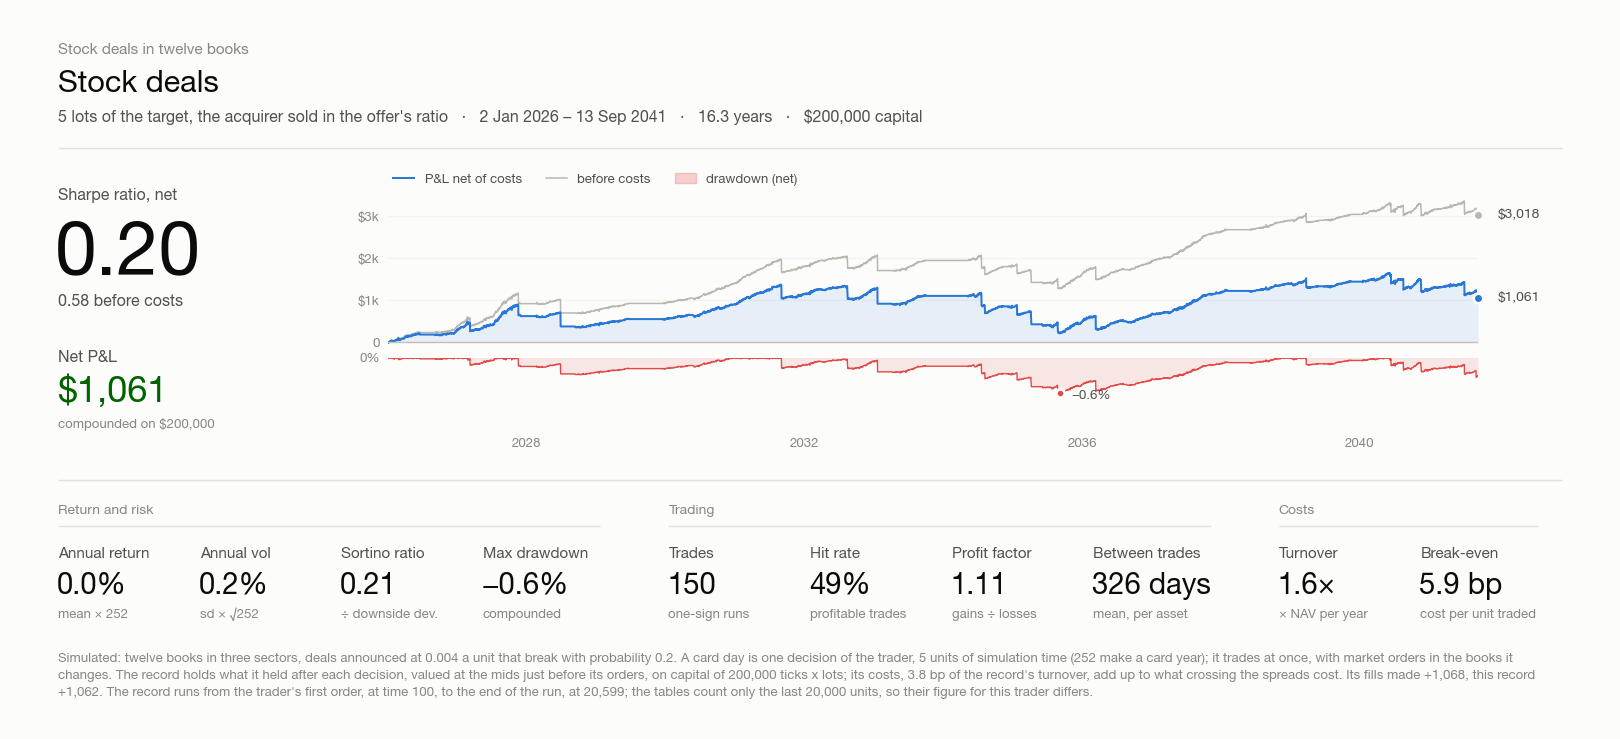

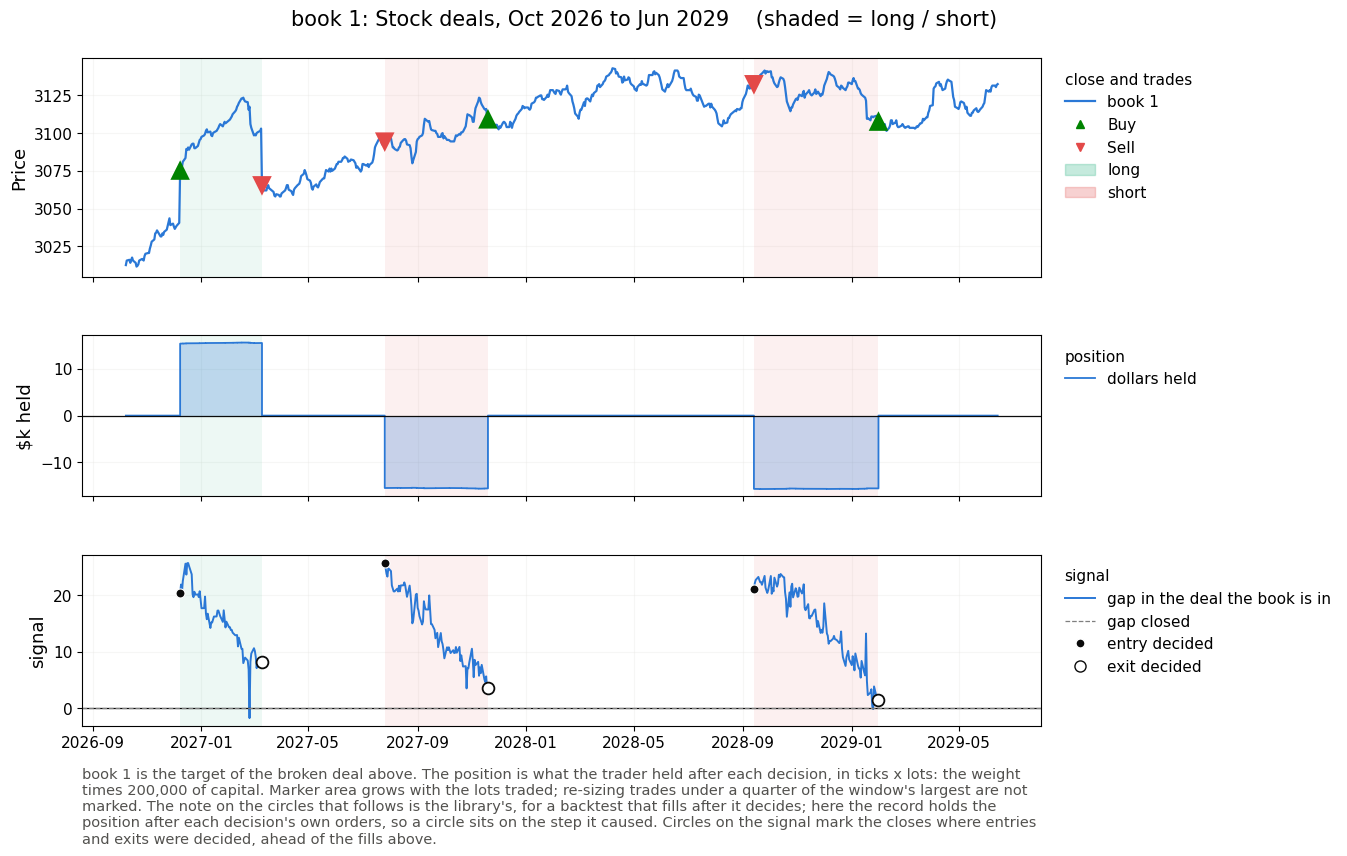

Stock deals in twelve books: its fills made +1,068 and the record +1,062; it holds at most 0.95 times the capital of 200,000, and more than it on 0.0% of days.
The dial table's figure for this run (breaks 0.20, seed 101), the last 20,000 units only: +892
The same run's 73 deals as deals: 75% made money, profit factor 1.22 (18 broke).


In [25]:
# The chart is of the target of the broken deal drawn above, if its position changes in the card's window (the chart
# library stops on a book that does not trade in it); failing that, of the book that trades most there.
in_window = deals_card_record.weights.iloc[deals_card_start : deals_card_end + 1]
trades_there = (in_window.diff().abs() > 0).sum()  # position changes in the card's window, by book
assert trades_there.max() > 0, "the trader makes no trade in the card's window"
deals_book = deals_broken.target
deals_asset = 'the target of the broken deal above'
if not trades_there[f'book {deals_book}']:
    deals_book = int(trades_there.idxmax().split()[1])
    deals_asset = 'the book that trades most in the card window'
    print(
        f"The target of the broken deal above does not trade in the card's window: the chart is of book {deals_book}."
    )
deals_in = [*deals_card_market.fair.ended, *deals_card_market.fair.deals]


def gap_in_the_deal_of(book):
    # A function of the card's Record: the gap, r x mid_A - mid_T, of the deal the book is in, as its target or as its
    # acquirer, at each decision; nan with none on. The last gap is carried forward one decision, since at the decision
    # that closes a deal none is on and its "exit decided" circle would have no signal.
    def gap(rec):
        times = np.array(rec.times)
        out = np.full(len(times), np.nan)
        for deal in deals_in:
            if book in (deal.target, deal.acquirer):
                stop = np.inf if deal.ended_at is None else deal.ended_at
                on = (times >= deal.announced) & (times < stop)
                out[on] = (
                    deal.ratio * rec.prices.iloc[:, deal.acquirer].to_numpy()[on]
                    - rec.prices.iloc[:, deal.target].to_numpy()[on]
                )
        closing = np.isnan(out[1:]) & ~np.isnan(out[:-1])
        out[1:][closing] = out[:-1][closing]
        return out

    return gap


# The trader's own signal is a row for each deal on: where exactly one is on, it is that deal's gap.
checked = wrong = 0
for i, (t, signal) in enumerate(zip(deals_card_record.times, deals_card_record.signals, strict=True)):
    on = [d for d in deals_in if d.announced <= t < (np.inf if d.ended_at is None else d.ended_at)]
    if signal is not None and len(on) == 1 and len(signal) == 1:
        gap = (
            on[0].ratio * deals_card_record.prices.iloc[i, on[0].acquirer]
            - deals_card_record.prices.iloc[i, on[0].target]
        )
        checked += 1
        wrong += abs(gap - signal[0]) > 1e-9
assert wrong == 0 and (checked > 0 or SMOKE), (
    f'the rebuilt gap differs from the trader\'s own on {wrong} of {checked} decisions'
)
print(f"The rebuilt gap equals the trader's own signal at all {checked} decisions with one deal on.\n")

deals_card = card(
    deals_card_trader,
    deals_card_fills,
    'Stock deals',
    f"{DEAL_SIZE} lots of the target, the acquirer sold in the offer's ratio",
    'Stock deals in twelve books',
    f'twelve books in three sectors, deals announced at {DEAL_RATE} a unit that break with probability {DEAL_CHOSEN}',
    'gap in the deal the book is in',
    [(0.0, 'C7', 'gap closed')],
    deals_book,
    signal=gap_in_the_deal_of(deals_book),
    capital=CAPITAL_DEALS,
    asset=deals_asset,
    start=deals_card_start,
    end=deals_card_end,
)
# The dial table's run of the same trader (a Witness trades as a DealTrader does), market, seed and burn.
deals_card_counted = deals_dial_frame[
    (deals_dial_frame.row == DEAL_ROW[DEAL_CHOSEN]) & (deals_dial_frame.seed == CARD_SEED)
].pnl.item()
print(
    f"The dial table's figure for this run (breaks {DEAL_CHOSEN:.2f}, seed {CARD_SEED}), the last {SPAN:,.0f} units "
    f'only: {deals_card_counted:+,.0f}'
)

# The deals of the same run, as deals.
held_deals = pd.DataFrame([(r.outcome, r.pnl) for r in deals_card_trader.outcomes], columns=['outcome', 'pnl'])
print(
    f'The same run\'s {len(held_deals)} deals as deals: {(held_deals.pnl > 0).mean():.0%} made money, profit factor '
    f'{held_deals.pnl[held_deals.pnl > 0].sum() / -held_deals.pnl[held_deals.pnl < 0].sum():.2f} '
    f'({(held_deals.outcome == "broken").sum()} broke).'
)

**The record agrees with the fills.** The card's fills made +1,068 and its record +1,062: within 6 ticks x lots, 0.6% of the fills' figure, the record being valued at the mids just before each decision's orders and the fills at the marks at the end. So the card is of the trader's real trades. The dial table's figure for the same run is +892, 170 below the record's (a plain difference): the record runs from the trader's first order, at time 100, to the end of the run, at 20,599, and includes the burn, while the tables count the last 20,000 units. Seed 101's +892 is also the lowest of the twelve seeds at this row (the distribution above gives +892 to +4,562), against the row's mean of +2,747 (se 346), so the card is of the weakest seed and not a typical one. The card is one run on one seed, and the dial's twelve are the evidence.

**The card holds 0.95 times its capital at most, and never more.** It holds more than the 200,000 on 0.0% of days, so its percentages are not leveraged. At the 150,000 of the other sections' cards the same peak would be 1.27 times the capital (0.95 x 200,000 over 150,000), above 1, which is why this card takes 200,000: with several deals on at once, 1.8 on average at 0.004 and up to 6 in the counts above, the trader holds more at once than one deal's worth.

**The scorecard's hit rate and profit factor are those of legs, and the deals' are higher.** The scorecard shows a net Sharpe of 0.20 (0.58 before costs), a net P&L of $1,061 on $200,000, a maximum drawdown of -0.6%, and a break-even cost of 5.9 bp against the 3.8 bp that this run's costs came to. Over its 150 one-sign runs its hit rate is 49% and its profit factor 1.11. The same run's 73 deals, taken as deals, made money 75% of the time with a profit factor of 1.22, and 18 of them broke. A leg is half of a hedge, so its sign is not the deal's, and the scorecard cannot show the small gains and the larger losses; the distribution above is where they show: 80.4% and 1.83 over the 966 deals of twelve seeds at 0.20, where the card's own run, one seed and the one with the lowest P&L of the twelve, has 75% and 1.22. The Sharpe and the drawdown are of one trader over one run of 16.3 years on the card's day count (a card day is 5 units), and say little beside the dial.

**In the chart, the position steps in at the first decision after an announcement, stays at one size through the deal and closes at its end.** Book 1, the target of the broken deal above, is long for that deal, and then short at the same size for two later deals in which it is the acquirer. The signal under it, the gap in the deal the book is in, falls toward 0 over each deal as the target's price rises toward the offer's: in the two later deals, which run their length, it has closed to a few ticks by the end, and in the deal that breaks it has not, and the price panel shows the target's price dropping before the long is closed. So the trader holds the target through the deal at a fixed size, collects the gap closing in the deals that complete, and takes the jump in the one that breaks.

### What This Section Cannot Show

- **Whether a premium of this size exists in a real market.** A break is a constant hazard, `priced` is a number given to the market that never learns, and a deal's whole effect on prices is the mix of the offer's worth and the target's own. The break-even says where this simulator's arithmetic puts it: a true chance of a break of about 0.31 against the price of 0.40, a premium of 5.3 ticks a lot pair at the deals' own 0.311 (60 x (0.40 - 0.311)), of which market orders at the spread take 5.00 and the rest, about 0.3, is what a lot pair loses before costs at a fair price. It is not an estimate of what merger arbitrage earns, or of how often a real deal breaks. The shape of many small gains and a few larger losses, with a skew of -1.57, is the shape this simulator's break builds in, and is not evidence about real mergers.
- **The break-even to better than the interval printed.** The share of deals that broke in a sample is not the nominal (0.415 at the control, 0.080 at the nominal 0.10), and the rows share their draws, so the dial's seven points carry one run of luck between them. The nominal break-even from a dial of twelve seeds is therefore no better known than the dial's own arithmetic says, an sd of 0.014, whatever the bootstrap's 0.010 says. The deals' `c / (c - b)` (0.311 and 0.308, bootstrap sd 0.003) is tighter and is the better place to read it, and the line's root against the counted share (0.316, bootstrap sd 0.004, 95% 0.307 to 0.324) agrees with it to within 0.008, most of which is a difference of unit: the counted share is that of every ended deal and leans 0.003 to 0.004 toward the broken against the deals with a kept record, which are the deals' unit (from 0.40 to 0.20 there are 971 ended and 966 with a record, and the five without one all broke), and the line's root against the share among the kept records is 0.312 (bootstrap sd 0.004, 95% 0.304 to 0.320). Both are in a share of deals broken, while the line's root of 0.310 is in the nominal `breaks` and holds the luck of the share. The deals' way assumes that a lot pair's completed and broken means are the same along the dial: the table holds that to 18.42 to 18.65 and -41.26 to -41.81, with the broken mean a little smaller at 0.10 (-39.79), where `c / (c - b)` is 0.317. Nothing about the shape between neighboring rows is separated from the arithmetic.
- **One size, one length, one premium and one level.** The break-even is for five lots of the target and moves with the size through the cost of a lot pair, 4.28, 5.00 and 6.22 ticks at 2, 5 and 10 lots. A deal's length (500 units) and premium (60 ticks) are one each, and what a trader makes would change with them; the level is 3,000, and at a level of tens of ticks `r` is far from 1 and the deals mean little. Five lots is also the size at which the hedge is five lots of the acquirer for five of the target in all but 2.6% of deals; at 10 lots 23.1% are not ten for ten, and the rounding would matter more.
- **The skew as a scorecard sees it.** The card's hit rate, profit factor and Sharpe are those of legs: 49% and 1.11 on the card, where the same run's deals have 75% and 1.22. They cannot show many small gains against a few large losses. Here a seed's total, which pools about 81 deals, hid them: no seed lost at 0.20 (+892 to +4,562), with 19.6% of the deals broken. The two risk figures do not show the skew either, and the one-unit risk-adjusted figure understates this trader's, 0.014 against 0.019 at 0.20, since the mids' bounce inflates the changes it is made of; on one reading, the reverse of a factor holder's.
- **Whether a late entry is a way to earn.** The late entry's gain over entering at the first decision, +744 (se 137, 8 of 8 seeds), is in the control, where the trade has no edge, and it is the mids' noise around their fair values: at fair values alone the same entries earn 0.28 less (se 0.11), 2.5 standard errors below 0, and by seed what the mids add to a late entry is positive on all eight (+1.03 to +2.26). A negative sign at fair values is what the model leads one to expect, since a deal still on at the later time has not broken and its target's fair value has drifted toward the offer since the first decision, which a late entry misses; the notebook does not measure that drift, so the reading is not tested.
- **How much of a broken deal's wider spread in the mixed market is the gap's wander.** The gap's sd is 2.38 times as large there, and the broken deals' sd 1.96 and 2.39 times as large at the two values; two ratios of the same size are not a decomposition. The mixed market is run at three values of the dial only, on eight seeds, and its differences from the sectors market (-118, +42 and +107, standard errors 283, 184 and 114) are paired by seed and not by deal: eight seeds do not separate a difference of a few hundred from nothing, and the mixed market has no break-even of its own beyond what three rows give.
- **What the pairs table says of reading the news, in general.** `NewsAwareTrader` is a quarantine of one window of decisions (2,012 units), and at this deal rate it gives up much of its trading: 85.9 entries a run against the blind trader's 138.4 at the fair price, a given book being the target of a deal about once in every three windows (37.5 deals a run, twelve books, 20,000 units). The table is about quarantines at this rate, with a reader that keeps out of targets only: that is the simulator's rule, since a deal moves the target's fair value and not the acquirer's here, and in a real market acquirers move too, so the rule that also keeps out of the acquirer is the one for a real market and is not a row here. Whether a smarter reader (one that re-baselines its window after a deal, trades the deal itself, or refits) would do better is not shown. On these eight seeds the finding is for the default quarantine at the fair price (-692, se 164, 0 of 8 seeds); the reader that stays out for the deal's life is not separated from the blind trader at either price on its own pairs (-119, se 217, and +429, se 256), and is ahead of it at 0.20 on every seed on the pairs of 0.40 held (+617, se 193, 8 of 8 seeds), which is a control and not a result a trader can reach. That lead is about the bet the reader does not hold, which the split of the P&L measures (+885, se 316, in the targets' books while the deals are on against a bet of 873 on the pairs held, and +693, se 295, against 694 on its own pairs; everywhere else -268, se 257, and -264, se 201, neither separated from 0), and that lead in the targets' books is how reading the news pays in this market; on a trader's own pairs, the comparison a trader there would face, the lead is not separated from 0 (+429, se 256), so whether reading the news pays a trader at this premium is not shown.
- **The pairs table has two values of the dial.** So it can say that what ignoring the news costs a pairs trader changes with the price of the risk, for the long quarantine on its own pairs (the shift of +780, se 278, 6 of 8 seeds) and for both readers on one set of pairs (+737, se 202, 7 of 8, and +824, se 200, 8 of 8), and not where; it gives no break-even and no line. The fall of a row between its two values of `breaks` on each trader's own pairs is not the cost of the bet alone: the blind row falls by 1,207 (se 178) against the bet's arithmetic of 694, 686 (se 194) of it in the targets' books while the deals are on, and the readers' rows fall too (-659 and -427, 2.2 and 2.4 standard errors from 0), everywhere but in the targets' books. Each trader chooses its pairs from the mids of its own world, and the pairs in common between a seed's two worlds are 3 to 6 of eight. With the pairs of 0.40 held in the market of 0.20 the blind trader's fall is 761 (se 186) and the readers' are -24 and +63, and the pairs of 0.40 do 446 (se 143), 635 (se 242) and 491 (se 166) better than the pairs the market of 0.20 chose, one comparison seen three times, since the traders of a seed share their pairs. Why the pairs chosen in the world of 0.20 are worse is not shown, and the rows on the other world's pairs are controls: a trader cannot choose its pairs in one world from another world's mids. The bet's `edge`, in ticks a lot, is the model's arithmetic, and the split by where the P&L was made is what measures it, only so far as the split goes: it is for the deals announced in the span and over by the run's end, from the lots held after each decision, at the decisions' mids and before the spread paid, so the spread paid, the jump at an announcement on the lots held before it and the deals still on at the end fall in 'everywhere else', which the notebook does not divide further. The net short lots of the same-pairs runs are printed, 72.8, so the bet on the pairs held is 873 by arithmetic, and the fall of 761 is 112 less than that, 0.6 of its standard error (186), with the targets' books while the deals are on 880 lower (se 193). The deal counts of the table are over the burn and the span, the P&L over the span.
- **Two markets.** The deal trader's tables are at an announcement rate of 0.004 and the pairs table's at 0.002, so what the deal trader makes where the pairs trader loses compares two markets. The pairs table's no-deals row is notebook 13's pairs row, the same runs, so it is not an independent check of it.
- **Costs.** The spread and the walk of the book against the mids are all there is: no fees, no queue position, no financing, and the book's orders are moved by an announcement or a break, so nobody collects the jump: the notebook cannot show what stale quotes would have paid, or the deal trader's edge if it could trade before the books moved.
- **Twelve seeds, eight where a table varies one thing, and one card.** A paired difference of a few standard errors or less is not separated from nothing by eight seeds; each table says how many seeds were positive. On these seeds that includes the trader's rate of 0.5 (+82, 1.3 standard errors), the reader with no quarantine at 0.20 (+429, 1.7) and its shift between the two values (+548, 1.5). The same-pairs lines of 3.2 to 4.1 standard errors (the reader's lead of +617 and the shifts of +737 and +824) are on pairs a trader cannot choose, and on each trader's own pairs the reader's lead is +429 (1.7 standard errors) and its shift +548 (1.5), so they are leads and not shown for a trader on its own pairs; the same-pairs test was made on seeds 1 to 8 before the first run, and the lots and the split printed for the pairs table were added after it. The card is one run on one seed, the lowest of the twelve at its row (+892 against a mean of +2,747, se 346), and its P&L is not the dial's mean.

## 3. A Factor That Trends

**The question.** Notebook 13's momentum was a control that lost: in these books a book's own part mean-reverts and the factors are random walks, so nothing a book did over the last 500 units goes on. Here the factors get a drift, and what rose tends to go on rising for a while. How large must the drift be before momentum pays what crossing the spreads costs? And what does its P&L look like when it does: how much of it is the factor, how much risk does the one-unit figure hide, and what does a trend do to the traders that take the factors out?

**The dial.** It is `trend` in `FactorValues`: the standard deviation of each trending factor's drift, in ticks a unit of time. A drift is an Ornstein-Uhlenbeck process around 0 with a half-life of 500 units, started from its stationary law and drawn from a stream of its own, so that the factors' shocks and the own parts' shocks are those of the same seed without it (in fair values alone: in a market the order flow follows the fair values, which the drift moves). The first factor, which every book loads on and which the floor pushes, never trends: the dial is `(0, s, s, s)` in the sectors market (a market factor and three sector factors) and `(0, s, s)` in the mixed one. A trend of 0 is exactly the market of notebooks 12 and 13 (the section's first code cell checks that, to the last digit of the fair values). The table that cell prints says what the dial means in the factor's own moves: how much of the variance of a move over the trader's look back is the drift's, and how strongly two successive such moves correlate.

**Here the only thing that can continue is a factor.** That is how this market is built, and not a finding: the books' own parts mean-revert (they must, or the books would have no relation to each other), the factors are random walks, and the drift is added to the factors alone. So momentum can pay here only by holding a factor, and what the section finds is the size of the drift that pays, and not which explanation of momentum is right; momentum in a book's residual has no room in this market. The first factor has no drift, so what a dollar-neutral trader can hold is the spread of the trending factors: in the sectors market, some sectors against others.

**The trader** is notebook 13's momentum, with its settings fixed along the dial: a book's score is its move over the last 100 decisions of 5 units (500 units, the drift's half-life), the trader rebalances every 100 decisions to 5 lots of the book with the largest weight, and its weights are the scores less their projection on the ones and on `factors` estimated factors. The dial's tables use `factors=0`, the dollar alone: the trader that holds the true factors' spread without knowing it, and the one that can pay. The table of factors taken out takes 1 and then 3 estimated factors out. Look back 100 and hold 100 were chosen on seeds 1 to 8, at a trend of 0.05 in the sectors market with the dollar alone, from 15 settings screened on the books-free route's P&L at fair values less a flat cost a lot (and checked in market runs for three of them); and then held fixed along the dial, in the mixed market and for every number of factors. Look back 50, a hold of 20 at look back 100, and rates of 0.05 or more lost to it by 4 to 29 standard errors; six settings, this one among them, formed a plateau, and the chosen one is notebook 13's and not the best of them (look back 200, hold 100, was a little better). Selection alone is worth about 3% of the proxy to the best of six equal settings, and the setting used, which is not the best, did not take it. What the setting does move is the break-even: look back 200 breaks even about 0.004 lower, on seeds 1 to 8, which is the size of the setting's effect on the headline number.

**Two routes to one number.** A market run of 20,000 units gives one window a seed of P&L, and a trend's factor part is the part of it that varies most from window to window: on seeds 1 to 8, which the method was built on, the eight first windows put the break-even at about half of where the long run puts it, because they happened to be lucky, and a trend's luck is shared by every dial value of the same seed. So the section has a second route, the **books-free route**: the same trader is given the fair values alone, on its own decision grid of 5 units with no order books, and holds its position between decisions. Its factor part is what it held of each factor (its position times the loadings) times the factors' moves, summed in blocks of 20,000 units from the same burn as the market runs, so that its first block is the market's window. It has no impact, no costs and no noise in the mids, and costs seconds a run for 200,000 units, so it can run the whole dial on many seeds and many blocks. It runs at a level so high that no fair value comes near the floor, and every run asserts that nothing was pushed up from it (as every market run does).

The **net P&L** along the dial combines them. A seed's net is the market's P&L less the books-free factor part of the same window, which leaves what the factor part did not make (costs, own parts, timing), plus the mean over all blocks and all books-free seeds of the books-free factor part at that trend less the same at a trend of 0. The factor part at a trend of 0 is 0 on average, because the trader decides before the factors move and a random walk's moves have no memory, so that mean difference is the long-run factor part, and taking it from the same seed and block at 0 takes out what the blocks have in common. The market part is run at five points of the sectors dial and interpolated linearly to the two between them. The break-even is where the line through the net's points first rises through 0, and its interval a bootstrap in which the market seeds and the books-free seeds are drawn apart (the market part has none of the factor part's noise left in it). What the books-free route claims is the expected factor part of this rule at these settings, in fair values; through the net, the market's mean P&L. It does not claim a cost, a risk figure, or anything for a trader whose factor part is mostly the noise of its estimates.

**What is run.**

1. *The dial in the sectors market.* Five values (0, 0.02, 0.03, 0.05, 0.1), momentum with the dollar alone, on the eight seeds of `FEW`: P&L (labeled one window a seed), the factor part, the rest, costs, and both risk figures.
2. *The books-free route,* at seven values (0.01 and 0.04 as well) on the twelve seeds, ten blocks a seed; and *the route against the market*: the market's factor part against the route's first block, a point a seed and dial value.
3. *More seeds for the route.* The route again at 0, 0.02 and 0.03, the values that bracket the break-even, on 24 more seeds (113 to 136). They have no market, decide no setting and cost next to nothing; they are used here because the long-run gain at the break-even's own points is what its precision rests on, and the cheap lever is more books-free data and not more market runs.
4. *The net P&L and its break-even,* with its figure.
5. *The mixed market.* The market at three values and the books-free route at seven, on `FEW`, with the break-even the same way, and the route again at 0, 0.03, 0.04 and 0.05 on the 24 more seeds, to see whether other seeds show the first windows that the eight did.
6. *Taking factors out.* Momentum with 1 and with 3 estimated factors taken out: in the sectors market 3 at 0 and 1 and 3 at 0.05, in the mixed market 1 and 3 at 0.05 (the dollar alone is from the two dial tables).
7. *The mirror.* Reversal over the same look back and hold, with the dollar alone taken out.
8. *Traders that take every factor out.* Eight pairs and stat-arb on PCA residuals, at 0 and 0.05.

It ends with the scorecard and signal chart of momentum with the dollar alone at a trend of 0.05, on seed 101, and with what the section cannot show.

Every comparison of market runs is paired by seed, and every table of them says how many seeds were positive. A table's standard error is over the seeds. Notebook 13 reports on the same seeds: a row here with notebook 13's trader, market and burn (the pairs at a trend of 0 in the last table) is the same run and gives the same number, which the section checks; a row at another burn is the same seeds over another window.

**What the section finds.** In the sectors market momentum with the dollar alone breaks even at a trend of 0.0269 ticks of drift a unit of time (5% to 95% of the resamples, 0.0251 to 0.0289): a drift that is 22.5% of the variance of a factor's move over the look back, and makes two successive moves correlate 0.15. Over 20,000 units it makes -4,094 (se 309) with no trend and +7,359 (se 516) at 0.05, and nearly all of that rise is the factor part: the trader holds about the same amount of the factors whether they trend or not (an `exposure` of 18.67 at 0 and 20.04 at 0.05), and the trend decides whether that pays. The market's own windows, one a seed, agree with the net to within their standard errors, and put the break-even at 0.0292 with a standard deviation of 0.0051 against the net's 0.0012; in the mixed market, which breaks even at 0.0364 (0.0352 to 0.0374), the eight windows at 0.05 made -298 (se 454) where the net makes +2,155 (se 159), because those windows were low (the route's first block 2,538 below its seed's other blocks, 3.46 times the standard error from all the blocks, the larger of the two the cell prints and the one to lean on, and 5.59 times the paired one over the eight seeds; on 24 other seeds the route's first block is 379 below the others at 0.05 (se 390), not as much as one standard error, so the shortfall is not shown on other seeds), where in the sectors market the market's own eight windows were -215, -573, -616 and -339 against their seeds' other blocks at 0.01 to 0.04, +88 at 0.05 and +3,323 at 0.1 (on the dial's twelve seeds the route's first block was above its seed's other blocks by 234 to 3,687 at those values), none as much as two standard errors from 0 by either of the two the cell prints, and the first block is not above the others on 24 more seeds. Taking one estimated factor out beside the dollar keeps 62.3% of the factor part in the sectors market and 104.4% in the mixed, and that first estimated factor is, to the figures printed, the direction the dollar takes out already (a cosine of 1.00 with the vector of ones in the sectors market and 0.97 in the mixed); taking three out keeps 1.8% and 3.7% and loses on every seed (-4,574, se 230, and -4,113, se 183, at 0.05), as does reversal, the mirror (-11,289, se 1,250); and a trend of 0.05 changes pairs by -77 (se 151) and the residuals by -224 (se 269), which eight seeds do not tell from nothing. These are means of eight market seeds (twelve to 36 for the route's factor part) of one simulated market, with settings chosen beforehand on seeds 1 to 8; where the fresh seeds differ from what those led one to expect, a break-even a little higher and a first estimated factor that takes out less, the cells say so.

In [26]:
from lob.crosssection import MomentumTrader, ReversalTrader
from lob.statarb import ResidualTrader

# The dial is the standard deviation of each trending factor's drift, in ticks a unit of time; the drift wanders
# around 0 with a half-life of 500 units. The first factor, the market's, never trends: (0, s, s, s) in the sectors
# market (a market factor and three sector factors) and (0, s, s) in the mixed one.
TREND_DIAL = (0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.1)  # the books-free route runs every point
TREND_MARKET_AT = (0.0, 0.02, 0.03, 0.05, 0.1)  # the sectors market is run at these, the mixed one at three
TREND_MIXED_AT = (0.0, 0.03, 0.05)
TREND_HALF_LIFE = 500.0
TREND_LOOK, TREND_HOLD = 100, 100  # the trader's look back and hold, in decisions of 5 units: notebook 13's momentum
TREND_FREE_LEVEL = 1e6  # the books-free route's level, so high that no fair value comes near the floor (it reads moves)
TREND_RESAMPLES = 2_000


def trend_of(name, s):
    # The dial's s on every factor but the first.
    return (0.0,) + (float(s),) * (LOADINGS[name].shape[1] - 1)


def trend_trending(name, s, **settings):
    # The fair values of market `name` with the dial at s, as a function with no arguments.
    return market_of(name, trend=trend_of(name, s), trend_half_life=TREND_HALF_LIFE, **settings)


def trend_momentum(factors=0):
    # Notebook 13's momentum: a book's score is its move over the last 100 decisions of 5 units, rebalanced every 100
    # decisions to 5 lots of the largest weight, neutral to the dollar and to `factors` estimated factors.
    return partial(
        MomentumTrader,
        lookback=TREND_LOOK,
        hold=TREND_HOLD,
        skip=0,
        rate=1.0,
        factors=factors,
        size=5.0,
        interval=EVERY,
    )


def trend_reversal():
    # Its mirror: the same look back and hold, buying what fell, with the dollar alone taken out.
    return partial(ReversalTrader, lookback=TREND_LOOK, hold=TREND_HOLD, rate=1.0, factors=0, size=5.0, interval=EVERY)


def trend_residuals():
    # Notebook 13's stat-arb on PCA residuals, with the settings found in notebook 12.
    return partial(
        ResidualTrader, factors=3, interval=EVERY, size=5.0, window=400, open_at=1.5, close_long=0.0, close_short=0.0
    )


# The burn is the longest warm-up of the section's traders and 400 units more, as notebook 13's is (a trader of 3
# factors needs 501 decisions of mids); the pairs choose from 2,000 decisions, and have the burn of notebook 13.
TREND_BURN = burn_for(
    'trend burn',
    max(
        make().warm_up
        for make in (trend_momentum(0), trend_momentum(1), trend_momentum(3), trend_reversal(), trend_residuals())
    )
    + 400.0,
    trend_momentum(1),
    trend_momentum(3),
    trend_reversal(),
    trend_residuals(),
)
TREND_PAIRS_BURN = PAIRS_BURN
# The books-free route's long run, in blocks of one span after the burn. Its seeds may be many, since it costs next to
# nothing: those of EXTRA decide nothing and have no market (in a smoke copy they are 3 to 5, not 1 and 2).
TREND_FREE = length('books-free run', 200_000.0, least=10 * SPAN)
TREND_BLOCKS = int(round(TREND_FREE / SPAN))
TREND_EXTRA = range(3, 6) if SMOKE else MORE
assert not set(TREND_EXTRA) & set(SEEDS), 'the books-free route has seeds that the market runs also have'


def trend_seen(market, trader):
    # What a market run says of itself, for the tables: the trend it had (on its last factor), and the factors the
    # trader took out.
    return {'trend': float(market.fair.trend[-1]), 'factors': float(getattr(trader, 'factors', np.nan))}


def trend_free_run(make_fair, make_trader, seed, burn, span, blocks):
    # The books-free route: the trader is given the fair values on a grid of EVERY units, with no order books, and
    # decides from them as it does from mids; it holds what it holds between decisions. Its factor part in each block of
    # `span` units, the first from the end of `burn` (so the first block is the market's window), is its position
    # times the loadings times the factors' moves, a step at a time. No impact, no costs, no noise in the mids.
    assert not SMOKE or seed <= 8, f'seed {seed} in a smoke run'
    started = time.time()
    fair = make_fair()
    fair.reseed(seed)
    trader = make_trader()
    trader.attach(fair.n)
    first, per = int(round(burn / EVERY)), int(round(span / EVERY))
    steps = first + blocks * per
    held, factors = np.zeros((steps + 1, fair.n)), np.zeros((steps + 1, fair.k))
    for i in range(1, steps + 1):
        fair.advance_to(i * EVERY)
        for move in trader.decide(fair.values()):
            trader.position += move
        held[i], factors[i] = trader.position, fair.factors
    part = ((held[:-1] @ fair.loadings) * np.diff(factors, axis=0)).sum(axis=1)  # held after decision i, to i + 1
    lots = np.abs(np.diff(held, axis=0, prepend=0)).sum(axis=1)  # lots traded at decision i
    blocked = [x[first : first + blocks * per].reshape(blocks, per).sum(axis=1) for x in (part, lots)]
    return {'factor_part': blocked[0], 'lots': blocked[1], 'pushed': float(fair.pushed), 'secs': time.time() - started}


def trend_free_rows(name, trends, seeds, make_trader=None, burn=None):
    # Every trend and seed through the books-free route, in parallel: a line a block (trend, seed, block, factor_part,
    # lots) and a line a run (trend, seed, pushed, secs). Stops if any run pushed a fair value up from the floor.
    make_trader = trend_momentum(0) if make_trader is None else make_trader
    burn = TREND_BURN if burn is None else burn
    jobs = [(s, seed) for s in trends for seed in seeds]
    runs = Parallel(n_jobs=-1)(
        delayed(trend_free_run)(
            trend_trending(name, s, level=TREND_FREE_LEVEL), make_trader, seed, burn, SPAN, TREND_BLOCKS
        )
        for s, seed in jobs
    )
    lines = [
        {'trend': s, 'seed': seed, 'block': b, 'factor_part': run['factor_part'][b], 'lots': run['lots'][b]}
        for (s, seed), run in zip(jobs, runs, strict=True)
        for b in range(TREND_BLOCKS)
    ]
    done = pd.DataFrame(
        [
            {'trend': s, 'seed': seed, **{k: run[k] for k in ('pushed', 'secs')}}
            for (s, seed), run in zip(jobs, runs, strict=True)
        ]
    )
    assert (done.pushed == 0).all(), f'a books-free run pushed a fair value up from the floor: {done[done.pushed > 0]}'
    return pd.DataFrame(lines), done


def pnl_by_trend(frame):
    return frame.pivot(index='seed', columns='trend', values='pnl')  # a row a seed, a column a trend


def trend_present_se(x):
    return se_of(x.dropna()) if x.notna().sum() > 1 else np.nan


def trend_free_table(blocks):
    # What the books-free blocks say, a line a trend: the factor part a block (the mean over seeds of each seed's mean
    # over its blocks, with the standard error over the seeds), the sd of one block, the gain over trend 0 (blocks
    # paired with the same seed's and block's at 0), how far the first block (the market's window) lies above the
    # other blocks of its seed, and the lots a block.
    wide = blocks.pivot_table(index=['seed', 'block'], columns='trend', values='factor_part')
    level = wide.groupby('seed').mean()
    gain = wide.sub(wide[0.0], axis=0).groupby('seed').mean()
    first = wide.xs(0, level='block') - wide.drop(0, level='block').groupby('seed').mean()
    lots = blocks.pivot_table(index=['seed', 'block'], columns='trend', values='lots').groupby('seed').mean()
    return pd.DataFrame(
        {
            'seeds': level.count(),
            'factor_part': level.mean(),
            'factor_part_se': level.apply(trend_present_se),
            'sd_block': wide.std(),
            'gain': gain.mean(),
            'gain_se': gain.apply(trend_present_se),
            'first_less_rest': first.mean(),
            'first_less_rest_se': first.apply(trend_present_se),
            'lots': lots.mean(),
        }
    )


def trend_free_text(table):
    show = {
        'seeds': '{:.0f}'.format,
        'factor_part': '{:+,.0f}'.format,
        'factor_part_se': '{:,.0f}'.format,
        'sd_block': '{:,.0f}'.format,
        'gain': '{:+,.0f}'.format,
        'gain_se': '{:,.0f}'.format,
        'first_less_rest': '{:+,.0f}'.format,
        'first_less_rest_se': '{:,.0f}'.format,
        'lots': '{:,.0f}'.format,
    }
    return table.to_string(formatters=show)


def trend_first_table(blocks):
    # How the first block (the market's window) lies against the other blocks of its seed, a line a trend, with two
    # standard errors of the mean over seeds: the paired one (the spread over the seeds of the first block less the
    # mean of its seed's other blocks, as above), and the one that the sd of a single block gives if every block were
    # an independent draw of that sd, sd x sqrt((1 + 1 / (B - 1)) / n) for n seeds of B blocks, each seed's first block
    # less the mean of its other B - 1. Eight seeds' own spread can be small by chance: the second does not rest on it.
    table = trend_free_table(blocks)
    by_sd = table.sd_block * np.sqrt((1 + 1 / (blocks.block.nunique() - 1)) / table.seeds)
    return pd.DataFrame(
        {
            'seeds': table.seeds,
            'first_less_rest': table.first_less_rest,
            'paired_se': table.first_less_rest_se,
            'over_paired_se': table.first_less_rest / table.first_less_rest_se,
            'sd_block': table.sd_block,
            'sd_se': by_sd,
            'over_sd_se': table.first_less_rest / by_sd,
        }
    )


def trend_first_text(blocks):
    show = {
        'seeds': '{:.0f}'.format,
        'first_less_rest': '{:+,.0f}'.format,
        'paired_se': '{:,.0f}'.format,
        'over_paired_se': '{:+.2f}'.format,
        'sd_block': '{:,.0f}'.format,
        'sd_se': '{:,.0f}'.format,
        'over_sd_se': '{:+.2f}'.format,
    }
    return trend_first_table(blocks).to_string(formatters=show)


def trend_part_text(frame):
    # The factor part of a market's runs a row, the mean over the seeds and its standard error over them.
    part = frame.groupby('row', sort=False).factor_part
    out = pd.DataFrame({'factor_part': part.mean(), 'factor_part_se': part.apply(se_of)})
    return out.to_string(formatters={'factor_part': '{:+,.0f}'.format, 'factor_part_se': '{:,.0f}'.format})


def trend_one_window(table):
    # The market's P&L is one window of the span a seed: the column says so.
    return table.rename(columns={'pnl': 'pnl_a_window'})


TREND_WINDOW = {'pnl_a_window': '+,.0f'}
TREND_WINDOW_COLUMNS = ['pnl_a_window', 'se', 'positive', 'factor_part', 'rest', 'costs', 'lots', 'cost_a_lot']
TREND_WINDOW_COLUMNS += ['exposure', 'deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']


def trend_summed(frame, pairs, *columns):
    # pairs: {label: (one, other)}. A line a label: the sum of two rows, seed by seed (mean and its standard error over
    # the seeds), for pnl and each column.
    lines = {}
    for label, (one, other) in pairs.items():
        a = frame[frame.row == one].set_index('seed')
        b = frame[frame.row == other].set_index('seed')
        assert set(a.index) == set(b.index), f'{one!r} and {other!r} are not on the same seeds'
        lines[label] = {}
        for column in ('pnl', *columns):
            both = a[column] + b[column].loc[a.index]
            lines[label].update({column: both.mean(), f'{column}_se': se_of(both)})
    return pd.DataFrame.from_dict(lines, orient='index')


class TrendBreak(NamedTuple):
    point: float  # where the line through the dial's points first rises through 0
    sd: float  # the standard deviation, and the 5th and 95th percentiles, of that over the resamples that cross
    low: float
    high: float
    share: float  # the share of the resamples that cross at all


def trend_crossing(xs, ys):
    i, share = first_rise(ys)
    return float('nan') if i < 0 else float(xs[i] + share * (xs[i + 1] - xs[i]))


def trend_crossings(xs, rows):
    # `crossing` of each row of a matrix, leaving out the points where it has no value.
    xs = np.asarray(xs)
    return np.array([trend_crossing(xs[~np.isnan(row)], row[~np.isnan(row)]) for row in rows])


def trend_summary(point, resamples):
    got = resamples[~np.isnan(resamples)]
    if len(got) < 2:
        return TrendBreak(point, np.nan, np.nan, np.nan, 0.0)
    return TrendBreak(
        point, float(got.std(ddof=1)), *(float(np.percentile(got, p)) for p in (5, 95)), len(got) / len(resamples)
    )


def trend_net_of(market, free):
    # The net P&L along the dial. `market` is a row a market seed, a column a trend: that seed's P&L over one window.
    # `free` is the books-free blocks. For each market seed, the market's P&L less the books-free factor part of the
    # same seed and window (the first block) is what the factor part did not make: costs, own parts and timing. Added
    # to it is the books-free factor part's gain over trend 0, the mean over all blocks and all the books-free seeds.
    # The factor part at trend 0 is 0 on average (the trader decides before the factors move, and a random walk's
    # moves have no memory), so that gain is the long-run factor part, and the net is the market's mean P&L with its
    # one window of luck taken out. The first term is interpolated between the dial's market points for those with no
    # market run. A resample draws the market seeds and the books-free seeds each with replacement, apart: the first
    # term has none of the factor part's noise left in it.
    window = free[free.block == 0].pivot(index='seed', columns='trend', values='factor_part')
    resid = market - window.loc[market.index, market.columns]
    assert not resid.isna().any().any(), 'a market run has no books-free window'
    nodes = sorted(resid.columns)
    at = pd.DataFrame(np.nan, index=resid.index, columns=list(TREND_DIAL))
    for s in TREND_DIAL:
        if s in nodes:
            at[s] = resid[s]
        elif nodes[0] < s < nodes[-1]:
            lo, hi = max(n for n in nodes if n < s), min(n for n in nodes if n > s)
            at[s] = resid[lo] + (s - lo) / (hi - lo) * (resid[hi] - resid[lo])
    wide = free.pivot_table(index=['seed', 'block'], columns='trend', values='factor_part')
    gain = wide.sub(wide[0.0], axis=0).groupby('seed').mean().reindex(columns=list(TREND_DIAL))
    assert set(market.index) <= set(gain.index), 'a market seed has no books-free runs'
    estimate = at.mean() + gain.mean()
    resampler = np.random.default_rng(12345)  # not a seed of a market: the bootstrap's own stream
    m, f = len(at), len(gain)
    parts, gains, flat = at.to_numpy(), gain.to_numpy(), market.to_numpy()
    have = ~np.isnan(gains)
    nets, alone = [], []
    for _ in range(TREND_RESAMPLES):
        drawn = np.bincount(resampler.integers(0, m, m), minlength=m)  # how many times each market seed was drawn
        made = np.bincount(resampler.integers(0, f, f), minlength=f)
        with np.errstate(invalid='ignore', divide='ignore'):
            nets.append(
                (drawn[:, None] * parts).sum(axis=0) / m
                + np.nansum(made[:, None] * gains, axis=0) / (made[:, None] * have).sum(axis=0)
            )
        alone.append((drawn[:, None] * flat).sum(axis=0) / m)
    nets = pd.DataFrame(nets, columns=list(TREND_DIAL))
    table = pd.DataFrame(
        {
            'market': market.mean().reindex(TREND_DIAL),
            'market_se': market.apply(se_of).reindex(TREND_DIAL),
            'resid': at.mean(),
            'resid_se': at.apply(trend_present_se),
            'gain': gain.mean(),
            'gain_se': gain.apply(trend_present_se),
            'gain_seeds': gain.count(),
            'net': estimate,
            'net_se': nets.std(),
            'net_low': nets.quantile(0.05),
            'net_high': nets.quantile(0.95),
        }
    )
    net = trend_summary(
        trend_crossing(*(np.array(TREND_DIAL)[estimate.notna()], estimate.dropna().to_numpy())),
        trend_crossings(TREND_DIAL, nets.to_numpy()),
    )
    own = trend_summary(
        trend_crossing(market.columns.to_numpy(), market.mean().to_numpy()),
        trend_crossings(market.columns, np.array(alone)),
    )
    return {'table': table, 'net': net, 'alone': own}


def trend_net_text(out):
    # The net table as text; a value that does not exist (the market where it was not run) is left blank.
    show = {
        'market': '{:+,.0f}'.format,
        'market_se': '{:,.0f}'.format,
        'resid': '{:+,.0f}'.format,
        'resid_se': '{:,.0f}'.format,
        'gain': '{:+,.0f}'.format,
        'gain_se': '{:,.0f}'.format,
        'gain_seeds': '{:.0f}'.format,
        'net': '{:+,.0f}'.format,
        'net_se': '{:,.0f}'.format,
        'net_low': '{:+,.0f}'.format,
        'net_high': '{:+,.0f}'.format,
    }
    return out['table'].rename_axis('trend').to_string(formatters=show, na_rep='')


def trend_break_text(label, found):
    if np.isnan(found.point):
        return f'{label}: no crossing'
    return (
        f'{label}: {found.point:.4f}; over the resamples sd {found.sd:.4f}, 5% to 95% {found.low:.4f} to '
        f'{found.high:.4f}, and {found.share:.1%} of them cross'
    )


# What a trend is worth in the factor's own moves (closed forms of the drift, an Ornstein-Uhlenbeck process, over the
# trader's look back): the share of the variance of a factor's move over the look back that is the drift's, and how
# strongly two successive such moves correlate.
TREND_VOLATILITY = float(
    FactorValues(LOADINGS['sectors']).volatility[0]
)  # ticks a square root of a unit, as a factor moves
TREND_LOOK_UNITS = TREND_LOOK * EVERY


def trend_drift_moves(s):
    rate = math.log(2) / TREND_HALF_LIFE
    gone = 1 - math.exp(-rate * TREND_LOOK_UNITS)
    cov = s * s * gone * gone / rate**2  # of two successive moves, from the drift
    own = s * s * 2 * (TREND_LOOK_UNITS / rate - gone / rate**2)  # the drift's part of the variance of one move
    return own / (TREND_VOLATILITY**2 * TREND_LOOK_UNITS + own), cov / (TREND_VOLATILITY**2 * TREND_LOOK_UNITS + own)


trend_calibration = pd.DataFrame(
    [trend_drift_moves(s) for s in TREND_DIAL],
    columns=['drift_share', 'serial_correlation'],
    index=pd.Index(TREND_DIAL, name='trend'),
)
print(
    f'A factor moves {TREND_VOLATILITY:g} tick a root unit. Over a look back of {TREND_LOOK_UNITS:,.0f} units, with a'
)
print(
    f'drift of half-life {TREND_HALF_LIFE:,.0f} units and standard deviation s, the drift is a share of the variance of'
)
print('its move and successive moves correlate as below (closed forms of the model; the first factor has no trend):')
print(trend_calibration.to_string(float_format=lambda x: f'{x:.3f}'))


def no_trend_is_no_trend(name):
    # A trend of (0, 0, 0, 0) is no trend at all: the fair values are those of the market that has none.
    plain, zero = FactorValues(LOADINGS[name]), trend_trending(name, 0.0)()
    for fair in (plain, zero):
        fair.reseed(CARD_SEED)
        fair.advance_to(5_000.0)
    assert np.array_equal(plain.values(), zero.values()) and np.array_equal(plain.factors, zero.factors), name


for each in LOADINGS:
    no_trend_is_no_trend(each)
print(f'Trend 0 is the market without one, in both markets. The burn is {TREND_BURN:,.0f} units, and')
print(f'{TREND_PAIRS_BURN:,.0f} for the pairs; a books-free run is {TREND_BLOCKS} blocks of {SPAN:,.0f} units, on')
print(f'{len(SEEDS)} seeds and, for some trends, {len(TREND_EXTRA)} more.')

A factor moves 1 tick a root unit. Over a look back of 500 units, with a
drift of half-life 500 units and standard deviation s, the drift is a share of the variance of
its move and successive moves correlate as below (closed forms of the model; the first factor has no trend):
       drift_share  serial_correlation
trend                                 
0.00         0.000               0.000
0.01         0.039               0.025
0.02         0.139               0.090
0.03         0.266               0.172
0.04         0.391               0.253
0.05         0.501               0.324
0.10         0.801               0.518


Trend 0 is the market without one, in both markets. The burn is 2,925 units, and
10,465 for the pairs; a books-free run is 10 blocks of 20,000 units, on
12 seeds and, for some trends, 24 more.


### The Dial in the Sectors Market

Momentum with the dollar alone taken out (the trader of the introduction), in the sectors market, at five values of the dial, every row on the eight seeds of `FEW` with one burn and one span. **The table is one window a seed.** Each row's P&L, `pnl_a_window`, is the mean over the seeds of one window of 20,000 units, so a row is a sample of the long run and not the long run: the net table further down is where the break-even is. `factor_part` is what the position held of the true factors times their moves, and `rest` is everything else in the P&L: the spread paid (`costs`), the books' own parts, what its orders made or lost by trading at mids off their fair values, and the marks. `lots` is the lots traded and `cost_a_lot` what one costs. `exposure` is the root of the mean, over time, of the squares of what the trader holds of the factors, added over the factors, in lots. `deviation` is the standard deviation of the P&L's change in a unit of time, `deviation_long` that of its change over 100 units divided by the root of 100, and each `risk_adjusted` is the mean change in a unit over its deviation. A small table under the first gives the factor part with its standard error over the seeds. A second table takes each row less the row with no trend, seed by seed.

In [27]:
# Momentum with the dollar alone taken out, in the sectors market, at five values of the dial: every row on the seeds
# of FEW, with one burn and one span. A row's P&L is one window of the span on each seed.
rows = {f'trend {s:g}': (trend_trending('sectors', s), trend_momentum(0)) for s in TREND_MARKET_AT}
trend_t1_frame = run_rows(rows, FEW, TREND_BURN, extra=trend_seen)
assert (trend_t1_frame.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
assert (trend_t1_frame.trend == trend_t1_frame.row.str.removeprefix('trend ').astype(float)).all(), 'trend of a row'
trend_t1 = table_of(trend_t1_frame)
print(f'Momentum in the sectors market, the mean over {len(FEW)} seeds of one window of {SPAN:,.0f} units a seed:')
print(shown(trend_one_window(trend_t1), keep=TREND_WINDOW_COLUMNS, **TREND_WINDOW))
print('\nThe factor part of that, the mean and its standard error over the seeds:')
print(trend_part_text(trend_t1_frame))

# Paired by seed against the row without a trend: what the dial changes.
along = paired_table(
    trend_t1_frame,
    {f'trend {s:g} less 0': (f'trend {s:g}', 'trend 0') for s in TREND_MARKET_AT[1:]},
    'factor_part',
    'rest',
    'costs',
)
print('\nEach row less trend 0, seed by seed:')
print(shown_paired(along, 'factor_part', 'rest', 'costs'))
print()
ran(trend_t1_frame)

Momentum in the sectors market, the mean over 8 seeds of one window of 20,000 units a seed:
           pnl_a_window    se positive factor_part   rest costs  lots cost_a_lot exposure deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                                
trend 0          -3,649 1,406   2 of 8        +421 -4,070 2,105 1,692       1.24    18.67      9.65          18.94        -0.019             -0.010
trend 0.02       -2,116 1,266   2 of 8      +1,657 -3,773 2,019 1,648       1.23    19.04      9.76          19.73        -0.011             -0.005
trend 0.03         +175 1,293   5 of 8      +3,807 -3,632 1,999 1,617       1.24    19.46      9.93          20.54         0.001              0.000
trend 0.05       +7,613 1,384   8 of 8     +10,783 -3,171 1,793 1,465       1.22    20.04     10.17          22.28         0.037              0.017
trend 0.1       +30,

**The control row loses, as notebook 13's momentum did.** With no trend momentum makes -3,649 (se 1,406, 2 of 8 seeds positive). A book's own part reverts, so what it did over the last 500 units does not go on, and the trader pays the spreads for a trade that its books' parts work against: of a rest of -4,070, 2,105 is costs, and reversal, which takes the other side of the same trade in the mirror table below, has a rest of -244. The factor part is +421 (se 1,138), 0.4 of its standard error from 0 (a plain ratio), small against how far one window's factor part scatters at this trend (a standard deviation of 2,604 a block in the books-free table below) and close to what the route makes in the same windows (+444 in the table after it). The factor part has no reason to be anything but about 0: the trader decides before the factors move, and a random walk's moves do not continue.

**One window a seed turns positive at 0.03, and is positive on every seed from 0.05 on.** The mean P&L is -2,116 (se 1,266, 2 of 8 seeds positive) at 0.02, +175 (se 1,293, 5 of 8) at 0.03 and +7,613 (se 1,384, 8 of 8) at 0.05. So 0.03 is the first dial value with a positive mean, and that mean is smaller than its standard error, and 0.05 is the first with every seed positive. A mean of eight windows is only as good as its standard error, 1,266 to 1,384 at these values, so this column puts the start of paying between 0.02 and 0.05 and no closer; the break-even is not read from it but from the net table below.

**The spread across windows is mostly the factor part's.** The factor part's standard error over the eight seeds is 1,138 at 0, 1,007 at 0.02, 1,087 at 0.03, 1,213 at 0.05 and 2,063 at 0.1, against the P&L's 1,406, 1,266, 1,293, 1,384 and 2,249, so most of what makes a mean of eight windows uncertain is the factor part. Paired with trend 0, seed by seed, it is 478, 600, 947 and 1,687 at 0.02 to 0.1, smaller at every value: the pairing takes out what a seed's window has at every trend.

**What the dial changes is the factor part.** Less trend 0, seed by seed, the P&L rises by +1,533 (se 447, 7 of 8 seeds positive) at 0.02, +3,824 (se 613, 8 of 8) at 0.03, +11,262 (se 1,018, 8 of 8) at 0.05 and +33,690 (se 1,893, 8 of 8) at 0.1. The factor part is +10,362 (se 947) of the 11,262 at 0.05 and +31,980 (se 1,687) of the 33,690 at 0.1. The rest rises a little, by +900 (se 166) at 0.05 and +1,709 (se 308) at 0.1, and costs fall, by 312 (se 50) and 582 (se 77), which is a part of that rise, since the costs are in the rest. The rise in the rest is more than five times its standard error at both values and small beside the factor part's. A trend adds a factor to hold, and changes little else of what the trader makes.

**Lots and costs.** The trader trades fewer lots as the trend grows: 1,692 at 0, 1,465 at 0.05 and 1,259 at 0.1, with costs of 2,105, 1,793 and 1,523. A lot costs about the same at every point (1.24 at 0, 1.22 at 0.05, 1.21 at 0.1), and about what it costs the section's other traders in the tables below (1.16 to 1.28), so costs fall because there are fewer lots, and not because each is cheaper. Positions that continue from one hold to the next need less rebalancing, which fits this and which the notebook does not test. So a part of the dial's effect on P&L is a change in how the trader trades (the costs, 312 at 0.05 and 582 at 0.1), and the larger part, the factor part, is not a change in how it trades.

**Risk is larger over 100 units than the one-unit figure says, and the trend widens the gap.** `deviation` is 9.65 at 0, 10.17 at 0.05 and 11.16 at 0.1; `deviation_long` is 18.94, 22.28 and 29.57, which is 1.96, 2.19 and 2.65 times as much (ratios of the printed figures). A position that holds a trending factor continues, so its risk over 100 units grows faster than the root of 100 times its risk over one. At trend 0, where no factor continues, the ratio is already 1.96, so some of the gap is not the drift's, and the notebook does not say what it is. By the one-unit figure the trader makes 0.037 a unit of risk at 0.05 and 0.134 at 0.1, and by the 100-unit figure 0.017 and 0.051, so the one-unit figure is 2.2 and 2.6 times the 100-unit one (ratios of `risk_adjusted` to `risk_adjusted_long`). So the one-unit figure flatters a trader that holds a trending factor, and the 100-unit one is the one to set beside another trader's; it too flatters a drift that lasts 500 units (see what the section cannot show). `exposure` is 20.04 lots at 0.05, against 18.67 at 0 and 22.03 at 0.1: the trader holds about the same amount of the factors along the dial, and what the trend changes is what it earns for them.

### The Books-Free Route

The same trader given the fair values alone, at every dial value on the twelve seeds of `SEEDS`: the factor part over ten blocks of 20,000 units a seed, which a market window of one block cannot give. Its columns: `factor_part` is the route's factor part of a block, the mean over seeds of each seed's mean over blocks, with its standard error over the seeds; `sd_block` is the standard deviation of one block's factor part over seeds and blocks; `gain` is the factor part less the same seed's and block's at trend 0, averaged; `first_less_rest` is how far the first block, the market's window, lies above the mean of the same seed's other blocks; `lots` is the lots traded in a block. Two more tables give `first_less_rest` again, on the twelve seeds and on the eight seeds the market runs on, each over two standard errors: the paired one, from the spread across the seeds of the first block less the mean of its seed's other blocks, and one from the standard deviation of a block over all the blocks at that trend.

In [28]:
# The books-free route at every point of the dial, on the twelve seeds: the same trader given the fair values alone,
# BLOCKS blocks of one span after the burn, the first of them the market's window.
trend_t1b_blocks, trend_t1b_runs = trend_free_rows('sectors', TREND_DIAL, SEEDS)
assert trend_t1b_blocks.groupby(['trend', 'seed']).size().eq(TREND_BLOCKS).all(), 'every run has its blocks'
trend_t1b = trend_free_table(trend_t1b_blocks)
print(f'The books-free factor part in the sectors market, a block of {SPAN:,.0f} units, {TREND_BLOCKS} blocks a seed:')
print(trend_free_text(trend_t1b))
# The first block is the market's window. How far it lies from the other blocks of its seed, on all the seeds of the
# dial and on those the market itself runs on (FEW), with a second standard error from the spread of one block alone.
print(
    f"\nThe first block (the market's window) less the other {TREND_BLOCKS - 1} blocks of its seed: the mean over the "
    'seeds, its paired standard error over them (paired_se), and the same mean over the standard error that the sd of '
    'one block gives for that many seeds (sd_se = sd_block x the root of (1 + 1 / (blocks - 1)) over the seeds), '
    'beside the paired one. sd_block is the standard deviation of one block over all the blocks at that trend.'
)
print(f'\nOn the {len(SEEDS)} seeds of the dial:')
print(trend_first_text(trend_t1b_blocks))
print(f"\nOn the market's own {len(FEW)} seeds:")
print(trend_first_text(trend_t1b_blocks[trend_t1b_blocks.seed.isin(FEW)]))
gains = trend_t1b.gain.loc[list(TREND_DIAL[1:])]
with np.errstate(invalid='ignore'):
    slope = np.polyfit(np.log(TREND_DIAL[1:]), np.log(gains.to_numpy()), 1)[0] if (gains > 0).all() else float('nan')
print(f'\nThe gain over trend 0 along the dial, on a log-log scale, has slope {slope:.2f} (2 would be a square law).')
ran(trend_t1b_runs)
print(f'Most pushed up from the floor: {trend_t1b_runs.pushed.max():.0f}.')

The books-free factor part in the sectors market, a block of 20,000 units, 10 blocks a seed:
      seeds factor_part factor_part_se sd_block    gain gain_se first_less_rest first_less_rest_se  lots
trend                                                                                                   
0.00     12         +90            169    2,604      +0       0            +480                947 1,708
0.01     12        +553            157    2,620    +463      97            +234                903 1,698
0.02     12      +2,027            202    2,826  +1,936     190            +267                956 1,662
0.03     12      +4,285            267    3,192  +4,195     284            +460              1,022 1,607
0.04     12      +7,186            347    3,735  +7,096     377            +838              1,165 1,546
0.05     12     +10,423            442    4,296 +10,332     471          +1,200              1,270 1,494
0.10     12     +28,696            759    7,847 +28,606     783    

**At trend 0 the factor part is 0 within its standard error, which is why the gain over trend 0 is the long-run factor part.** It is +90 (se 169) on the twelve seeds (+34, se 118, on all 36 in the table of more seeds below), as it must be: the trader decides before the factors move, and a random walk's moves do not continue. So the factor part's gain over trend 0, taken from the same seed and block, is the long-run factor part of the trend, and is exactly 0 at trend 0. The pairing does not always shrink the standard error. `gain_se` is below `factor_part_se` at 0.01 (97 against 157), about equal at 0.02 (190 against 202) and a little above it from 0.03 on (284 against 267 at 0.03, 783 against 759 at 0.1), so it helps where the trend is small and not where it is large. Seeds 1 to 8 had led one to expect more from it at 0.02 and 0.03.

**The gain along the dial.** It is +463 (se 97) at 0.01, +1,936 (se 190) at 0.02, +4,195 (se 284) at 0.03, +7,096 (se 377) at 0.04, +10,332 (se 471) at 0.05 and +28,606 (se 783) at 0.1, each a mean of twelve seeds of ten blocks. On a log-log scale its slope is 1.80, and a square law would be 2: the gain rises a little more slowly than the square of the trend. The notebook does not say why. One reason that fits is that the trader's size is fixed (5 lots of the largest weight), so a stronger drift pays it only through its being on the right side more often, and that share cannot pass 1.

**One window and the long run.** The standard deviation of one block's factor part, `sd_block`, is 2,826 at 0.02 and 7,847 at 0.1, against gains of 1,936 and 28,606. At 0.02, which is where the break-even lies, one window's factor part scatters by more than the whole gain, and at 0.03 by three quarters of it (3,192 against 4,195); only at 0.1 is it about a quarter of it. So one window a seed is a poor guide to the factor part near the break-even, which is why the long run needs many blocks, ten a seed here, and 36 seeds at 0.02 and 0.03 in the next table.

**The market's windows were not shown to be lucky on these seeds.** `first_less_rest`, how far the first block (the market's window) lies above the other blocks of its seed, is on the dial's twelve seeds +480 (se 947) at 0, +267 (se 956) at 0.02, +460 (se 1,022) at 0.03, +1,200 (se 1,270) at 0.05 and +3,687 (se 2,061) at 0.1. It is positive at every value and under two standard errors at every one (the largest, at 0.1, is 1.8 times its own), so no value there is shown different from 0. The market runs on eight of the twelve seeds, and the windows it ran are the first blocks of those eight, so they are the ones to set beside seeds 1 to 8's: on them `first_less_rest` is +350 (se 1,379) at 0, below 0 from 0.01 to 0.04 (-215, -573, -616 and -339), +88 at 0.05 and +3,323 at 0.1, and none is as much as two standard errors from 0 (the largest, at 0.1, is 1.4 times its own). On seeds 1 to 8 the first windows sat above their seeds' other blocks by 1,430 to 5,903 at 0 to 0.1, enough for the market's own P&L to put the break-even at about half of the long run's; the market's windows here are at -616 to +3,323 at the same values. The twelve seeds' figures include four seeds that the market did not run, which is why seeds 1 to 8's are set against the market's own eight. The values are for the same windows at every dial value, which share their drift, so they are one finding and not seven. The mixed market's windows, in its own table below, were not like these.

**Two standard errors, and which to lean on.** The tables give each value over two. `paired_se` is the standard deviation across the seeds of the first block less the mean of its seed's other nine, over the root of the number of seeds, so it uses only these seeds' own spread. `sd_se` is the standard deviation of one block over all the blocks at that trend, times the root of 1 + 1/9, over the root of the number of seeds. It is what the difference would have if a seed's blocks were draws of one spread, which seeds that are draws of one process lead one to expect, and it rests on every block (120 for the twelve seeds, 80 for the eight) and not on twelve or eight differences. On the twelve seeds the two agree to within about a fifth (947 and 793 at 0, 2,061 and 2,388 at 0.1), and on the market's eight to within about three tenths (1,379 and 972 at 0, 2,408 and 3,016 at 0.1), the paired one the larger from 0 to 0.02 and the smaller from 0.03 up on the eight, so no value here is two standard errors from 0 by either. Where they differ, lean on the larger. A standard deviation from eight or twelve numbers is itself rough and can fall below the true one by chance, and every ratio over it is then too large; the one from all the blocks does not depend on those draws alone, though it assumes that a seed's blocks are alike. The mixed market, below, is where the two differ most.

**Lots.** The route trades 1,708 lots a block at 0, 1,662 at 0.02, 1,607 at 0.03, 1,494 at 0.05 and 1,315 at 0.1, against the market's 1,692, 1,648, 1,617, 1,465 and 1,259 in the dial table. They fall together along the dial, and the largest gap, 56 lots at 0.1, is about 4% of the route's. The route has twelve seeds and the table eight, so this is not a paired comparison; it says that the route makes about the trades of the market's trader, and is not another trader.

**Nothing was pushed up from the floor.** The most any of the 84 runs pushed a fair value up from it is 0. The level was raised so that no fair value comes near the floor, and every market run had `pushed` 0 as well (each cell asserts it), so neither route's factor part contains a push of the first factor.

### The Route Against the Market

Does the books-free route give the market's factor part? In the same seed and window both see the same factors, and they differ in the books: the market's mids lag the fair values, its orders are rounded to lots and its own impact moves the mids, so the route is the rule in fair values with no noise. The net P&L further down rests on the two agreeing window by window, and not only on average, because it takes the one's window out of the other's and puts the long run in.

The market's factor part and the books-free route's first block, the mean over 8 seeds:
       market    free  gap gap_se sd_gap correlation gap_share
trend                                                         
0.00     +421    +444  -24    187    530       0.991          
0.02   +1,657  +1,516 +140    323    912       0.966     +9.3%
0.03   +3,807  +3,768  +38    250    707       0.979     +1.0%
0.05  +10,783 +10,586 +197    364  1,029       0.965     +1.9%
0.10  +32,401 +31,956 +446    289    817       0.993     +1.4%


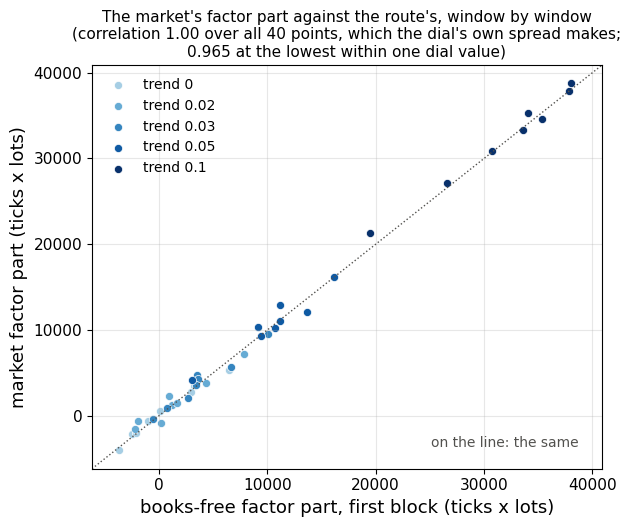

In [29]:
# Does the books-free route give the market's factor part? Both for the same seed and the same window, at each of the
# sectors market's dial points: the market's factor part (what score_holdings says its position made of the factors)
# against the books-free route's first block.
first_block = trend_t1b_blocks[trend_t1b_blocks.block == 0].set_index(['trend', 'seed']).factor_part
checked = trend_t1_frame.assign(
    free=[first_block[(t, s)] for t, s in zip(trend_t1_frame.trend, trend_t1_frame.seed, strict=True)]
)
checked['gap'] = checked.factor_part - checked.free
trend_agree = checked.groupby('trend').agg(
    market=('factor_part', 'mean'),
    free=('free', 'mean'),
    gap=('gap', 'mean'),
    gap_se=('gap', se_of),
    sd_gap=('gap', 'std'),
)
trend_agree['correlation'] = checked.groupby('trend').apply(lambda d: d.factor_part.corr(d.free), include_groups=False)
# as a share of the route's, where there is a trend
trend_agree['gap_share'] = (trend_agree.gap / trend_agree.free.abs()).where(trend_agree.index > 0)
print(f'The market\'s factor part and the books-free route\'s first block, the mean over {len(FEW)} seeds:')
print(
    trend_agree.to_string(
        formatters={
            'market': '{:+,.0f}'.format,
            'free': '{:+,.0f}'.format,
            'gap': '{:+,.0f}'.format,
            'gap_se': '{:,.0f}'.format,
            'sd_gap': '{:,.0f}'.format,
            'correlation': '{:.3f}'.format,
            'gap_share': '{:+.1%}'.format,
        },
        na_rep='',
    )
)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
shades = plt.get_cmap('Blues')(np.linspace(0.35, 1.0, len(TREND_MARKET_AT)))  # the dial runs from light to dark
for shade, s in zip(shades, TREND_MARKET_AT, strict=True):
    part = checked[checked.trend == s]
    ax.scatter(part.free, part.factor_part, color=shade, s=34, edgecolor='white', lw=0.5, label=f'trend {s:g}')
low, high = min(checked.free.min(), checked.factor_part.min()), max(checked.free.max(), checked.factor_part.max())
pad = 0.05 * (high - low)
ax.plot([low - pad, high + pad], [low - pad, high + pad], color=GRAY, lw=1, ls=':')
ax.text(high, low, 'on the line: the same', color=GRAY, ha='right', va='bottom', fontsize=10)
ax.set_xlim(low - pad, high + pad)
ax.set_ylim(low - pad, high + pad)
ax.set_xlabel('books-free factor part, first block (ticks x lots)')
ax.set_ylabel('market factor part (ticks x lots)')
drawn = checked.free.corr(checked.factor_part)  # the correlation of the points on the figure, all of them
ax.set_title(
    "The market's factor part against the route's, window by window\n"
    f"(correlation {drawn:.2f} over all {len(checked)} points, which the dial's own spread makes;\n"
    f'{trend_agree.correlation.min():.3f} at the lowest within one dial value)',
    fontsize=11,
)
ax.legend(frameon=False, fontsize=10, loc='upper left')
fig.tight_layout()
plt.show()

**The market's factor part is the route's, to between 1.0% and 9.3% of it at the values with a trend, and the gap has no fixed sign.** `gap`, the market's factor part less the route's first block, is -24 (se 187) at 0, +140 (se 323) at 0.02, +38 (se 250) at 0.03, +197 (se 364) at 0.05 and +446 (se 289) at 0.1; as a share of the route's, +9.3%, +1.0%, +1.9% and +1.4% at the four values with a trend. None is as much as two standard errors from 0 (the largest, at 0.1, is 1.5 times its own). The market is above the route at all four, but it was below it at every point on seeds 1 to 8, so neither a shortfall nor a surplus of the market's factor part is shown here; the larger share at 0.02 is a gap of 140 (se 323) on a small factor part (the route's is +1,516 there). The correlation between the two is 0.991 at 0 and 0.966, 0.979, 0.965 and 0.993 above it, the lowest being 0.965 at 0.05. The figure's title gives both: the correlation over all 40 points together, 1.00, which the dial's own spread makes (the points run from factor parts near 0 at the low trends to the route's mean of +31,956 and the market's of +32,401 at 0.1, so most of the spread it measures is the dial's), and the lowest within one dial value, 0.965; the correlations within a dial value, printed above, are the ones that say how well the route matches a window. `sd_gap`, from 530 to 1,029, is the scatter of the gap from seed to seed. It is the noise that the net's residual carries, and its bootstrap includes it.

**The figure shows the same.** The points, one a seed and dial value, lie along the dotted line of equality and spread out along it as the trend grows: the light ones at 0 and 0.02 sit at the low end, the dark ones at 0.1 run to the top right. Their distance from the line is what `sd_gap` says, and it does not grow as fast as the factor part does. So the market's factor part is the route's a window at a time, and not only on average. That is why swapping one for the other in the net is not a change of subject: the net takes the route's first block out of the market's P&L and puts the route's long run in, and both are the same position times the same factors' moves. What the swap leaves in the residual is what only the market has: the mids' lag behind the fair values, the lot rounding and the trader's own impact.

### More Seeds for the Route

At 0, 0.02 and 0.03, the control and the two values that bracketed the break-even on seeds 1 to 8, the route is run on 24 more seeds with no market. They are seeds 113 to 136, which none of the notebook's settings were chosen on and which the market does not use; they are here because a standard error falls with the root of the seeds and these seeds cost seconds, where a market run costs half a minute and more.

In [30]:
# More seeds for the books-free route at the three points that bracket the break-even: no trader's orders and no
# books, so a run costs a few seconds and the seeds of EXTRA are free. They decide nothing and report on nothing but the
# long-run factor part, which sets how well the break-even is known.
trend_t1c_blocks, trend_t1c_runs = trend_free_rows('sectors', (0.0, 0.02, 0.03), TREND_EXTRA)
assert not set(trend_t1c_blocks.seed) & set(SEEDS), 'the extra seeds are also seeds of the dial'
trend_free_blocks = pd.concat([trend_t1b_blocks, trend_t1c_blocks], ignore_index=True)  # the books-free seeds, all
near = trend_t1b_blocks[trend_t1b_blocks.trend.isin((0.0, 0.02, 0.03))]
by_seeds = {
    f'the {len(SEEDS)} seeds of the dial': trend_free_table(near),
    f'{len(TREND_EXTRA)} more seeds': trend_free_table(trend_t1c_blocks),
    f'all {len(SEEDS) + len(TREND_EXTRA)}': trend_free_table(
        trend_free_blocks[trend_free_blocks.trend.isin((0.0, 0.02, 0.03))]
    ),
}
trend_t1c = pd.concat(
    {
        name: table[['seeds', 'factor_part', 'factor_part_se', 'sd_block', 'gain', 'gain_se']]
        for name, table in by_seeds.items()
    }
)
print(f'The books-free factor part at the trends that bracket the break-even, a block of {SPAN:,.0f} units:')
print(
    trend_t1c.to_string(
        formatters={
            'seeds': '{:.0f}'.format,
            'factor_part': '{:+,.0f}'.format,
            'factor_part_se': '{:,.0f}'.format,
            'sd_block': '{:,.0f}'.format,
            'gain': '{:+,.0f}'.format,
            'gain_se': '{:,.0f}'.format,
        }
    )
)

# The first block less the other blocks of its seed, at these trends, on each set of seeds: with the standard error
# that the sd of one block gives (see the table of the route above), beside the paired one.
print(
    f"\nThe first block (the market's window) less the other {TREND_BLOCKS - 1} blocks of its seed, with the paired "
    'standard error over the seeds and the one that the sd of one block gives (sd_se):'
)
for name, blocks in {
    f'the {len(SEEDS)} seeds of the dial': near,
    f'{len(TREND_EXTRA)} more seeds': trend_t1c_blocks,
    f'all {len(SEEDS) + len(TREND_EXTRA)}': trend_free_blocks[trend_free_blocks.trend.isin((0.0, 0.02, 0.03))],
}.items():
    print(f'\n{name}:')
    print(trend_first_text(blocks))
print()
ran(trend_t1c_runs)
print(f'Most pushed up from the floor: {trend_t1c_runs.pushed.max():.0f}.')

The books-free factor part at the trends that bracket the break-even, a block of 20,000 units:
                               seeds factor_part factor_part_se sd_block   gain gain_se
                         trend                                                         
the 12 seeds of the dial 0.00     12         +90            169    2,604     +0       0
                         0.02     12      +2,027            202    2,826 +1,936     190
                         0.03     12      +4,285            267    3,192 +4,195     284
24 more seeds            0.00     24          +5            157    2,716     +0       0
                         0.02     24      +2,057            155    3,050 +2,052     107
                         0.03     24      +4,411            177    3,532 +4,406     158
all 36                   0.00     36         +34            118    2,676     +0       0
                         0.02     36      +2,047            122    2,973 +2,013      94
                         

**The 24 more seeds agree with the dial's twelve, and the standard error halves.** The gain at 0.02 is +1,936 (se 190) on the dial's twelve seeds, +2,052 (se 107) on the 24 more and +2,013 (se 94) on all 36; at 0.03 it is +4,195 (se 284), +4,406 (se 158) and +4,335 (se 140). The 24 differ from the twelve by 116 at 0.02 and 211 at 0.03, each less than the larger of the two standard errors (190 and 284), so the long-run gain here is a property of the model and not of these twelve seeds. The standard error on all 36 is about half of the twelve's, 94 against 190 and 140 against 284 (the 24 alone have 107 and 158).

**The control row is still 0 on three times the seeds.** The factor part at trend 0 is +34 (se 118) on all 36, from +90 (se 169) on the twelve and +5 (se 157) on the 24 more.

**The first block is not above the others on 24 more seeds, or on all 36.** `first_less_rest`, the first block less the mean of its seed's other nine, is -606 (se 477) at 0, -539 (se 583) at 0.02 and -469 (se 727) at 0.03 on the 24 more seeds, and -244 (se 448), -271 (se 499) and -159 (se 589) on all 36. None is as much as 1.3 times its paired standard error, nor as much as 1.1 times the one from all the blocks (1.04 at most). The blocks of a seed are draws of one process, so by construction the first has no reason to differ from the others on average, and over 36 seeds it does not. The dial's twelve seeds, at +480, +267 and +460, are no more than 0.61 of a standard error from 0 as well (0.51, 0.28 and 0.45 of the paired one, 0.61, 0.31 and 0.47 of the one from all the blocks), so none of the three sets of seeds shows the first block different from the others. The two standard errors agree to within about a quarter on every line here (477 and 584, 583 and 656, 727 and 760 on the 24 seeds), so either can be read.

### The Net P&L and Its Break-Even

The market's P&L less its own window's books-free factor part, plus the books-free factor part's long-run gain over trend 0, at each point of the dial (the market's part interpolated to 0.01 and 0.04), and the trend at which the line through it first rises through 0, with the same made from the dial's twelve books-free seeds alone and from the market's one window a seed alone. In the table, `market` is the market's P&L, one window a seed, with its standard error over the seeds (it has a value only where the market was run); `resid` is that P&L less the books-free factor part of the same window, interpolated to the values with no market run; `gain` is the books-free route's long-run gain over trend 0, with its standard error over the books-free seeds and how many there were; `net` is `resid` plus `gain`, with the standard error, and the 5th and 95th percentiles, of 2,000 resamples in which the market seeds and the books-free seeds are drawn apart.

Net P&L of momentum in the sectors market over 20,000 units; market: one window a seed, 8 seeds:
       market market_se  resid resid_se    gain gain_se gain_seeds     net net_se net_low net_high
trend                                                                                             
0.00   -3,649     1,406 -4,094      333      +0       0         36  -4,094    309  -4,651   -3,633
0.01                    -3,863      259    +463      97         12  -3,401    259  -3,865   -3,012
0.02   -2,116     1,266 -3,633      270  +2,013      94         36  -1,619    266  -2,064   -1,198
0.03     +175     1,293 -3,593      284  +4,335     140         36    +742    294    +257   +1,228
0.04                    -3,284      243  +7,096     377         12  +3,812    431  +3,112   +4,522
0.05   +7,613     1,384 -2,974      255 +10,332     471         12  +7,359    516  +6,513   +8,204
0.10  +30,040     2,249 -1,915      356 +28,606     783         12 +26,691    834 +25,305  +28,086

Break-even,

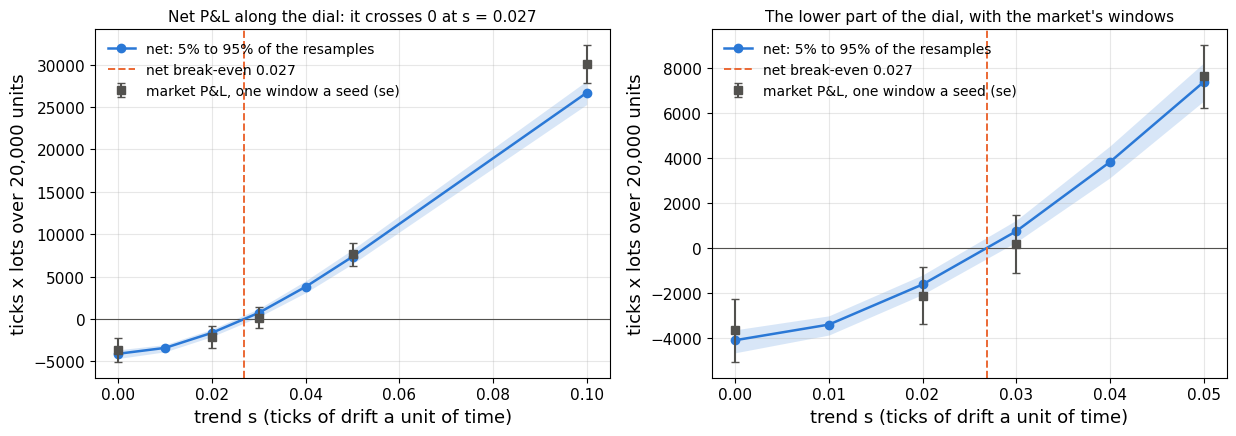

In [31]:
# The net P&L along the dial: the market's P&L less its own window's books-free factor part, plus the books-free
# factor part's long-run gain over trend 0, at each point of the dial (the market's part interpolated to 0.01 and 0.04).
trend_net = trend_net_of(pnl_by_trend(trend_t1_frame), trend_free_blocks)
trend_net_few = trend_net_of(pnl_by_trend(trend_t1_frame), trend_t1b_blocks)  # the same with the dial's seeds only
print(f'Net P&L of momentum in the sectors market over {SPAN:,.0f} units; market: one window a seed, {len(FEW)} seeds:')
print(trend_net_text(trend_net))
print()
print(trend_break_text('Break-even, net, all the books-free seeds', trend_net['net']))
print(trend_break_text(f'Break-even, net, the books-free seeds of the dial ({len(SEEDS)})', trend_net_few['net']))
print(trend_break_text('Break-even, the market\'s one window a seed alone', trend_net['alone']))
point = trend_net['net'].point
if not np.isnan(point):
    share, correlation = trend_drift_moves(point)
    print(f'At the net break-even the drift is {share:.1%} of the variance of a move over the look back, and two')
    print(f'successive moves correlate {correlation:.2f}.')

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
table = trend_net['table']
for ax, last in zip(axes, (max(TREND_DIAL), 0.05), strict=True):
    shown_at = table[table.index <= last]
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.fill_between(shown_at.index, shown_at.net_low, shown_at.net_high, color=BLUE, alpha=0.18, lw=0)
    ax.plot(shown_at.index, shown_at.net, color=BLUE, marker='o', lw=1.8, label='net: 5% to 95% of the resamples')
    ax.errorbar(
        shown_at.index,
        shown_at.market,
        yerr=shown_at.market_se,
        fmt='s',
        color=GRAY,
        capsize=3,
        label='market P&L, one window a seed (se)',
    )
    if not np.isnan(point) and point <= last:
        ax.axvline(point, color=ORANGE, ls='--', lw=1.4, label=f'net break-even {point:.3f}')
    ax.set_xlabel('trend s (ticks of drift a unit of time)')
    ax.set_ylabel(f'ticks x lots over {SPAN:,.0f} units')
    ax.legend(frameon=False, fontsize=10, loc='upper left')
# A title says only what the figure shows: where the net line crosses 0 (the number printed above), and what the
# second panel adds, which is the lower part of the dial, closer, with the market's windows on it.
first_title = 'Net P&L along the dial: no crossing of 0'
if not np.isnan(point):
    first_title = f'Net P&L along the dial: it crosses 0 at s = {point:.3f}'
axes[0].set_title(first_title, fontsize=11)
axes[1].set_title("The lower part of the dial, with the market's windows", fontsize=11)
fig.tight_layout()
plt.show()

**The break-even is 0.0269, and that is the figure to quote.** Net of costs, momentum with the dollar alone in the sectors market breaks even at a trend of 0.0269 ticks of drift a unit of time. The resamples' standard deviation is 0.0012, their 5th to 95th percentile 0.0251 to 0.0289, and every one of the 2,000 crosses. The line through the net first rises through 0 between 0.02, where the net is -1,619 (se 266), and 0.03, where it is +742 (se 294), so the crossing is interpolated within a step of the dial, between two points that were run. Of the three ways the cell computes it, this one, the net with all 36 books-free seeds at the two points that bracket it, rests on the most data about the part of the P&L that varies most, and it is a long-run break-even: its factor part is the route's long run in fair values, and the rest of the P&L is the market's own, from its eight windows. It is where the mean P&L over many windows is estimated to cross 0, and not where the eight windows that were run did. It is a mean of eight market seeds and, for the factor part, twelve to 36 books-free seeds of one simulated market, with settings chosen beforehand on seeds 1 to 8. The interval is the seeds' sampling spread. It does not hold how far the line bends between 0.02 and 0.03, nor the settings. The break-even is a little higher than seeds 1 to 8 led one to expect.

**The extra seeds narrowed it a little, and the market part now sets its precision.** With the dial's twelve books-free seeds alone the break-even is 0.0274 (sd 0.0015, 5% to 95% 0.0250 to 0.0301); with all of them it is 0.0269 (sd 0.0012, 0.0251 to 0.0289), a point 0.0005 lower and an interval 0.0038 wide instead of 0.0051. At 0.02 and 0.03 `resid_se`, 270 and 284, is larger than `gain_se`, 94 and 140, and `net_se`, 266 and 294, is about `resid_se`: the eight windows of the market part set the precision, where on the twelve seeds `gain_se` (190 and 284) was 0.7 of `resid_se` at 0.02 and equal to it at 0.03 (plain ratios). More books-free data would now buy little; the lever left is more market seeds. At 0.05 and 0.1, where the gain has twelve seeds, `gain_se` (471 and 783) is the larger.

**One window a seed does not mislead on these seeds, beyond its standard error.** The market's windows alone put the break-even at 0.0292 (sd 0.0051, 5% to 95% 0.0198 to 0.0347, 99.9% of the resamples cross), 0.0023 above the net's, with a standard deviation over four times as large; its interval holds the net's. The market's P&L is -2,116 (se 1,266) against a net of -1,619 at 0.02, +175 (se 1,293) against +742 at 0.03, +7,613 (se 1,384) against +7,359 at 0.05 and +30,040 (se 2,249) against +26,691 at 0.1: below the net at the first two and above it at the last two, by under half of the market's standard error at 0.02, 0.03 and 0.05 and by 1.5 times it at 0.1. The gaps are about what the net's construction gives, since it takes the route's first block out of the market's P&L and puts the long run in: the market's P&L is below the net by 497 and 567 at 0.02 and 0.03 and above it by 254 and 3,349 at 0.05 and 0.1 (plain differences), where the books-free table above has the first blocks of these eight seeds below their seeds' other blocks by 573 and 616 at 0.02 and 0.03 and above them by 88 and 3,323 at 0.05 and 0.1. That is the other way from seeds 1 to 8, where the windows put the break-even at about half of the long run's because the first windows were lucky, and the books-free table above says that these eight windows were not shown to be: at 0.1, where they sit highest, they are 1.4 times the paired standard error above the others and 1.1 times the one from all the blocks. A window a seed can be lucky in either direction, so the market column is a mean of eight windows and is not to be read as the long-run P&L. The net, whose band is narrower than the squares' bars at every point where there is a square, is what to read.

**What `resid` is.** It is what the trader makes apart from the factor part of its own window: -4,094 (se 333) at 0, and then -3,633 at 0.02, -3,593 at 0.03, -2,974 at 0.05 and -1,915 at 0.1. It holds the costs (2,105 at 0 and 1,793 at 0.05 in the dial table), what the books' own parts do against a trade that follows them, and timing, and it is the price the factor part has to pay. It rises along the dial, by 1,120 at 0.05 and 2,179 at 0.1 above its level at 0 (differences of the printed figures; the dial table's paired rest, which takes the market's own factor part and not the route's, rises by 900 and 1,709), but it moves by only 40 between 0.02 and 0.03, where the gain moves by 2,322, so the crossing is set by the gain. The net at 0, with no gain, is -4,094 (se 309): the long-run loss of momentum with no trend, against -3,649 (se 1,406) for the window.

**What the break-even means.** At 0.0269 the drift is 22.5% of the variance of a factor's move over the look back of 500 units, and two successive such moves correlate 0.15. So at the drift that pays here most of what a factor does over 500 units is still its random walk, and a correlation of 0.15 between one 500-unit move and the next is enough to pay what crossing the spreads costs this trader. It is for this trader's look back, hold, size and costs and no other, in a market where a factor's drift is the only thing that can continue (see what the section cannot show).

**The figure.** In both panels the net (the blue line, with the band of the 5th to 95th percentile of the resamples) crosses 0 at the dashed line, 0.027, and the market's windows (gray squares, with their standard errors) scatter about it. The squares are below the line at 0.02 and 0.03 and above it at 0.05 and 0.1, and each bar overlaps the band. The left panel is titled with the net's crossing, 0.027, and the right, titled for the lower part of the dial, shows the same line from 0 to 0.05 with the market's windows. The band is narrower than the bars at every point where there is a square, which is what the books-free route buys: the line is located more tightly than eight windows can locate it.

### The Mixed Market

The mixed market has three factors with loadings in no order, so no set of books is a sector: the trend is `(0, s, s)`, on the two factors after the first, and the first factor never trends. Momentum with the dollar alone holds a mix of them. The market is run at three values of the dial and the books-free route at all seven, on the seeds of FEW; the net and its interval are made as in the sectors market, with the market part interpolated between its three points and no market part at 0.1 (so no net there). The cell also prints the factor part's standard error, what the trader holds of each true factor, and the first block less the others with the two standard errors of the books-free route's table. It ends with the books-free route again on 24 more seeds (113 to 136, the sectors market's extra seeds) at 0, 0.03, 0.04 and 0.05, with no market and no trader's orders: the factor part, the gain over trend 0 and the first block less the others on the market's eight seeds, on the 24 and on all 32. That part was added to the cell after the first run showed the mixed market's first windows low, to see whether other seeds show what the first eight did; it decides nothing.

In [32]:
# The mixed market (three factors, loadings in no order): the trend is (0, s, s). The market at three points of the
# dial, the books-free route at all seven, both on the seeds of FEW.


def trend_held(market, trader, burn, span):
    # What the trader holds of each true factor, separately, at its decisions in the span: its position after each
    # decision times the market's loadings (fixed here), a column a factor, and the root mean square of that over the
    # decisions; and the three together (the root of the mean over the decisions of the sum of the squares). From the
    # record the trader keeps. The table's `exposure` is the same kind of figure, sampled once a unit.
    times = np.array([h[0] for h in trader.history])
    held = np.array([h[2] for h in trader.history], dtype=float)[(times >= burn) & (times < burn + span)]
    of_factor = held @ market.fair.loadings
    rms = np.sqrt((of_factor**2).mean(axis=0))
    held_all = float(np.sqrt((of_factor**2).sum(axis=1).mean()))
    return {**trend_seen(market, trader), **{f'held_{j}': float(x) for j, x in enumerate(rms)}, 'held_all': held_all}


# The momentum rows keep a record of their decisions, for trend_held: a record changes nothing a trader does or scores.
rows = {f'trend {s:g}': (trend_trending('mixed', s), partial(trend_momentum(0), record=True)) for s in TREND_MIXED_AT}
trend_t3_frame = run_rows(rows, FEW, TREND_BURN, extra=partial(trend_held, burn=TREND_BURN, span=SPAN))
assert (trend_t3_frame.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
trend_t3 = table_of(trend_t3_frame)
print(f'Momentum in the mixed market, the mean over {len(FEW)} seeds of one window of {SPAN:,.0f} units a seed:')
print(shown(trend_one_window(trend_t3), keep=TREND_WINDOW_COLUMNS, **TREND_WINDOW))
print('\nThe factor part of that, the mean and its standard error over the seeds:')
print(trend_part_text(trend_t3_frame))
along = paired_table(
    trend_t3_frame,
    {f'trend {s:g} less 0': (f'trend {s:g}', 'trend 0') for s in TREND_MIXED_AT[1:]},
    'factor_part',
    'rest',
    'costs',
)
print('\nEach row less trend 0, seed by seed:')
print(shown_paired(along, 'factor_part', 'rest', 'costs'))

# What the trader holds of each true factor (the market factor, then the two others), at its decisions in the span.
held_columns = [c for c in trend_t3_frame.columns if c.startswith('held_')]
trend_t3_held = trend_t3_frame.groupby('row', sort=False)[held_columns].mean()
trend_t3_held['exposure'] = trend_t3.exposure
print(
    '\nWhat the trader holds of each true factor (its position times the loadings: held_0 the market factor, held_1 '
    'and held_2 the two others), the root mean square over its decisions in the span, in lots of the factor, the mean '
    f'over the {len(FEW)} seeds; held_all the three together, and exposure that column of the table above, sampled '
    'once a unit:'
)
print(trend_t3_held.to_string(float_format='{:.2f}'.format))

trend_t3_blocks, trend_t3_runs = trend_free_rows('mixed', TREND_DIAL, FEW)
trend_t3_free = trend_free_table(trend_t3_blocks)
print(f'\nThe books-free factor part in the mixed market, a block of {SPAN:,.0f} units, {TREND_BLOCKS} blocks a seed:')
print(trend_free_text(trend_t3_free))
print(
    f"\nThe first block (the market's window) less the other {TREND_BLOCKS - 1} blocks of its seed, with the paired "
    'standard error over the seeds and the one that the sd of one block gives (sd_se), on the seeds the market runs '
    'on (the books-free route in this market runs on those alone):'
)
print(trend_first_text(trend_t3_blocks))
sectors_free = trend_free_table(
    trend_t1b_blocks[trend_t1b_blocks.seed.isin(FEW)]
)  # the sectors market on the same seeds
print('\nThe mixed market\'s gain over trend 0 as a share of the sectors market\'s, on the same seeds:')
print(
    (trend_t3_free.gain / sectors_free.gain)
    .loc[list(TREND_DIAL[1:])]
    .to_frame('share')
    .T.to_string(float_format='{:.2f}'.format)
)

trend_t3_net = trend_net_of(pnl_by_trend(trend_t3_frame), trend_t3_blocks)
print(f'\nNet P&L over {SPAN:,.0f} units; the market is one window a seed, and only three points of the dial have one:')
print(trend_net_text(trend_t3_net))
print()
print(trend_break_text('Break-even, net', trend_t3_net['net']))
print(trend_break_text('Break-even, the market\'s one window a seed alone', trend_t3_net['alone']))

# More seeds for the books-free route in the mixed market, at the values that matter for the first window and for the
# crossing: no market and no trader's orders, so a run costs a few seconds. They decide nothing and report on nothing
# but whether the first block lies below the other blocks on other seeds, and on the long-run gain at 0.03 and 0.04.
TREND_MIXED_MORE = (0.0, 0.03, 0.04, 0.05)
trend_t3_more_blocks, trend_t3_more_runs = trend_free_rows('mixed', TREND_MIXED_MORE, TREND_EXTRA)
assert not set(trend_t3_more_blocks.seed) & set(FEW), 'the extra seeds are also seeds of the market'
trend_t3_own_blocks = trend_t3_blocks[trend_t3_blocks.trend.isin(TREND_MIXED_MORE)]
mixed_by_seeds = {
    f"the market's own {len(FEW)} seeds": trend_t3_own_blocks,
    f'{len(TREND_EXTRA)} more seeds': trend_t3_more_blocks,
    f'all {len(FEW) + len(TREND_EXTRA)}': pd.concat([trend_t3_own_blocks, trend_t3_more_blocks], ignore_index=True),
}
print(
    f'\nThe books-free factor part in the mixed market on more seeds, a block of {SPAN:,.0f} units, {TREND_BLOCKS} '
    'blocks a seed:'
)
print(
    pd.concat(
        {
            name: trend_free_table(blocks)[['seeds', 'factor_part', 'factor_part_se', 'sd_block', 'gain', 'gain_se']]
            for name, blocks in mixed_by_seeds.items()
        }
    ).to_string(
        formatters={
            'seeds': '{:.0f}'.format,
            'factor_part': '{:+,.0f}'.format,
            'factor_part_se': '{:,.0f}'.format,
            'sd_block': '{:,.0f}'.format,
            'gain': '{:+,.0f}'.format,
            'gain_se': '{:,.0f}'.format,
        }
    )
)
print(
    f"\nThe first block (the market's window) less the other {TREND_BLOCKS - 1} blocks of its seed in the mixed "
    'market, with the paired standard error over the seeds and the one that the sd of one block gives (sd_se):'
)
for name, blocks in mixed_by_seeds.items():
    print(f'\n{name}:')
    print(trend_first_text(blocks))
print()
ran(trend_t3_more_runs)
print(f'Most pushed up from the floor: {trend_t3_more_runs.pushed.max():.0f}.')
print()
ran(trend_t3_frame, trend_t3_runs)

Momentum in the mixed market, the mean over 8 seeds of one window of 20,000 units a seed:
           pnl_a_window  se positive factor_part   rest costs  lots cost_a_lot exposure deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                              
trend 0          -3,857 518   0 of 8        -711 -3,146 1,616 1,380       1.17    10.32      6.90          11.42        -0.028             -0.017
trend 0.03       -2,824 401   0 of 8         +89 -2,913 1,538 1,323       1.16    10.26      6.80          11.45        -0.021             -0.012
trend 0.05         -298 454   3 of 8      +2,331 -2,629 1,397 1,208       1.16    10.27      6.72          11.78        -0.002             -0.001

The factor part of that, the mean and its standard error over the seeds:
           factor_part factor_part_se
row                                  
trend 0           -711        


The books-free factor part in the mixed market, a block of 20,000 units, 10 blocks a seed:
      seeds factor_part factor_part_se sd_block    gain gain_se first_less_rest first_less_rest_se  lots
trend                                                                                                   
0.00      8        -169            134    1,419      +0       0            -438                594 1,375
0.01      8        +120            141    1,515    +289      28          -1,034                547 1,358
0.02      8        +825            143    1,613    +994      29          -1,471                461 1,324
0.03      8      +1,990            149    1,688  +2,159      54          -1,924                408 1,271
0.04      8      +3,374            160    1,818  +3,543      69          -2,327                462 1,215
0.05      8      +4,943            151    1,967  +5,112      86          -2,538                454 1,156
0.10      8     +13,523            190    3,178 +13,692     213     


The books-free factor part in the mixed market on more seeds, a block of 20,000 units, 10 blocks a seed:
                               seeds factor_part factor_part_se sd_block   gain gain_se
                         trend                                                         
the market's own 8 seeds 0.00      8        -169            134    1,419     +0       0
                         0.03      8      +1,990            149    1,688 +2,159      54
                         0.04      8      +3,374            160    1,818 +3,543      69
                         0.05      8      +4,943            151    1,967 +5,112      86
24 more seeds            0.00     24        -150             88    1,358     +0       0
                         0.03     24      +2,021            102    1,707 +2,171      81
                         0.04     24      +3,403            123    1,946 +3,552     116
                         0.05     24      +4,972            144    2,180 +5,122     148
all 32        

**In its own window the mixed market is not shown to pay at 0.05, though the net says it does.** The market's P&L is -3,857 (se 518, 0 of 8 seeds positive) at 0, -2,824 (se 401, 0 of 8) at 0.03 and -298 (se 454, 3 of 8) at 0.05, where the sectors market's is +7,613 on 8 of 8. The factor part is -711 (se 515), +89 (se 397) and +2,331 (se 428), about the P&L's own standard errors (518, 401 and 454), and the rest -3,146, -2,913 and -2,629. Less trend 0, seed by seed, the P&L rises by +1,033 (se 313, 7 of 8) at 0.03 and +3,559 (se 537, 8 of 8) at 0.05, of which the factor part is +800 (se 323) and +3,042 (se 547), the rest +233 (se 84) and +517 (se 99), and costs fall by 78 (se 29) and 219 (se 28). The net at 0.05 is +2,155 (se 159, 5% to 95% 1,894 to 2,425), 2,453 above the market's -298 (a difference of the two printed figures). These are two things. The window mean is what these eight windows made, and the net is the market's mean P&L over the long run, with the factor part of fair values, so they need not agree within a window's noise. The gap is the windows' luck: the route's first block, which is the market's window, lies below its seed's other blocks at every value, by 2,538 at 0.05. That is 5.59 times the paired standard error over the eight seeds (454) and 3.46 times the one from all eighty blocks (733), and the two differ here, the one from all the blocks being the larger from 0.01 up. Lean on the larger, for the reason given with the books-free route: the spread of eight differences can fall below the true one by chance, here to three fifths of what the blocks give at 0.05 (454 against 733, a plain ratio), and every ratio over it is then too large. By the larger the windows are still low by more than three standard errors at 0.03, 0.04 and 0.05 (3.06, 3.44 and 3.46) and by 2.45 and 2.65 at 0.02 and 0.1, and by 1.83 at 0.01, where the paired one gives 1.89. The same eight windows serve every dial value, so these are one finding and not seven, among the many comparisons the notebook makes and corrects none for. In the sectors market the market's own eight windows were not shown to be lucky, and here they are low, by about the size of the gap. Whether that is more than these eight seeds' luck is what the 24 more seeds below test.

**On 24 other seeds the first block is not shown low, and the gain at the crossing is the same.** The route's first block less the other nine, on 24 seeds that no market run of the trend section uses (113 to 136), is +2 (se 235) at 0, -144 (se 298) at 0.03, -256 (se 346) at 0.04 and -379 (se 390) at 0.05, which is 0.01, 0.48, 0.74 and 0.97 times the paired standard error (0.01, 0.39, 0.61 and 0.81 times the one from all the blocks). None is as much as one standard error from 0, though three of the four are below 0 and a shortfall of a few hundred is not ruled out. The eight's -2,538 at 0.05 is 2,159 below the 24's -379, which is 3.6 times the standard error of that difference by the paired standard errors (454 and 390) and 2.5 times by the ones from all the blocks (733 and 469), each the root of the sum of the two squared standard errors (plain calculations). On all 32 seeds, which include the eight, the first block is below the others by 589 (se 279), 774 (se 324) and 919 (se 353) at 0.03, 0.04 and 0.05, 2.1, 2.4 and 2.6 times the paired standard error and 1.9, 2.2 and 2.3 times the one from all the blocks; that is mostly the eight, which were looked at because they were low and so lean the 32 toward the gap, and the 24 are the figure to weigh. The sectors market's 24 more seeds, in the cell on the route's more seeds above, give -606 (se 477), -539 (se 583) and -469 (se 727) at 0, 0.02 and 0.03, none as much as 1.3 standard errors from 0. So the low first windows are not shown on other seeds in either market: the eight are the odd ones, by more than two standard errors of their difference from the 24, and nothing in the model makes a first block differ from the others (the drift starts from its stationary law, and the blocks begin after the burn). An independent check outside this notebook found most of the shortfall on these eight seeds in the drift's part of the factor part, which the notebook does not print. So the reading is that these eight seeds' windows were unfavorable to momentum in the first block, and not that the first windows of the two markets differ. It does not move the break-even: the net takes the market's window less the route's first block of the same window, so that window's luck cancels, and its gain is the ten-block mean, which on the 24 more seeds is the eight's to within its standard error: +2,171 (se 81) against +2,159 (se 54) at 0.03, +3,552 (se 116) against +3,543 (se 69) at 0.04 and +5,122 (se 148) against +5,112 (se 86) at 0.05, and on all 32 +2,168 (se 62), +3,550 (se 88) and +5,119 (se 112). The gains at 0.03 and 0.04, the two points that bracket the crossing, differ by 9 and 7 between the 32 and the eight (plain differences), against 1,447 between the net's two points (+523 less -924); the cell does not fit the break-even again with the 32, so the printed 0.0364 is still from the eight.

**The mixed trader holds a little over half the factors the sectors trader does, and its risk hardly rises with the trend.** At trend 0 its `exposure` is 10.32 against the sectors market's 18.67, its `deviation_long` 11.42 against 18.94, and its `deviation` 6.90 against 9.65. Along its dial `exposure` stays at 10.32, 10.26 and 10.27, and `deviation_long` goes from 11.42 to 11.45 and 11.78, where the sectors market's goes from 18.94 to 22.28 at 0.05. The loadings on the first factor are 1 plus or minus a fifth, so a dollar-neutral position is not neutral to it, and momentum holds some of a factor that never trends, which is risk with nothing behind it. The table of what the trader holds of each factor says how much of the 10.32 that is: the market factor, which never trends, is held at 3.13, 3.03 and 2.99 lots (root mean square over its decisions) along the dial, and the other two at 5.97 and 7.78, 6.02 and 7.72, and 6.07 and 7.72, with the three together 10.32, 10.26 and 10.27, the table's `exposure`. So the factor with nothing behind it is the smallest of the three and does not grow with the trend. Per unit of 100-unit risk the trader makes -0.017, -0.012 and -0.001 along the dial, against the sectors market's -0.010, 0.000 and +0.017 at the same values.

**The mixed market's gain is about half of the sectors market's.** On the same eight seeds the route's gain over trend 0 in the mixed market is 0.68 of the sectors market's at 0.01, 0.52 at 0.02, 0.51 at 0.03, 0.50 at 0.04, 0.49 at 0.05 and 0.47 at 0.1. So a trend is worth about half as much here. Two things differ from the sectors market, the loadings are in no order and only two factors trend, and the notebook does not separate them. The share is a little under half at the top of the dial, and more at 0.01, where the gain is smallest (+289, se 28).

**The mixed market's break-even is 0.0364, larger than the sectors market's 0.0269 by 0.0095.** The net's 5% to 95% is 0.0352 to 0.0374, with a resample standard deviation of 0.0006, and every resample crosses. The market's own windows alone have no crossing, as all three of them are below 0. Its crossing lies between 0.03, where the net is -924 (se 124) and the market was run, and 0.04, where it is +523 (se 95) and the market part is interpolated between the runs at 0.03 and 0.05 (`resid` -3,083 and -2,957, nearly flat), so the crossing rests on that line more than the sectors market's does. The interval is narrower than the sectors market's, and not wider as eight books-free seeds and three market points led one to expect. The mixed market's windows scatter less, with a standard error of 401 to 518 against 1,266 to 1,406, and so do its blocks (`sd_block` 1,419 to 1,967 up to 0.05, against 2,604 to 4,296), so `resid_se` and `gain_se` are smaller (77 to 153 and 28 to 86 up to 0.05, against 243 to 333 and 94 to 471), though the sectors market's `gain_se` has more seeds behind it. The interval does not hold the line's error between market points. It is also a little higher than seeds 1 to 8 led one to expect, as the sectors market's is. It is not a second measurement of the sectors market's number: the loadings differ.

### Taking Factors Out

Momentum with 1 and with 3 estimated factors taken out as well as the dollar, at the same look back and hold; the rows with the dollar alone are those of the two dial tables, on the same seeds. A trader neutral to the dollar and to `factors` estimated factors holds weights with no exposure to those factors. With the dollar alone it holds whatever the true factors give; with three, as many as the sectors market has beyond the first (and one more than the mixed market has), it holds none, and what is left of its factor part is the error in its estimates. `kept` is the factor part a row makes as a share of the dollar-alone row's at the same trend and market; it is blank at a trend of 0, where there is none to keep. The cell also prints what the first estimated factor is, from each trader's last estimate: the cosine of its eigenportfolio with the vector of ones and with each true factor, and the books' exposures to it, which is what the trader projects its weights off: their cosine with the vector of ones, the size of their tilt (the exposures less their mean) against their own size, and the cosine of that tilt with each true factor's loadings less their mean.

In [33]:
# Taking factors out. Momentum with 1 and with 3 estimated factors taken out, as well as the dollar, at the same look
# back and hold. The rows with the dollar alone are those of the two dial tables, on the same seeds.
rows = {
    'sectors, f3, trend 0': (trend_trending('sectors', 0.0), trend_momentum(3)),
    'sectors, f1, trend 0.05': (trend_trending('sectors', 0.05), trend_momentum(1)),
    'sectors, f3, trend 0.05': (trend_trending('sectors', 0.05), trend_momentum(3)),
    'mixed, f1, trend 0.05': (trend_trending('mixed', 0.05), trend_momentum(1)),
    'mixed, f3, trend 0.05': (trend_trending('mixed', 0.05), trend_momentum(3)),
}


def trend_first_factor(market, trader):
    # trend_seen's columns and, for a trader with one estimated factor, what that factor is at the run's end: the
    # absolute cosine of the trader's first eigenportfolio (the lots of each book that estimate_factors gave it at its
    # last estimate, which the trader keeps) with the vector of ones and with each column of the market's true
    # loadings (cos_0 the market factor, cos_1 and on the others). It reads the trader and changes nothing in it.
    seen = trend_seen(market, trader)
    if trader.factors != 1:
        return seen
    eigen = trader._eigen[:, 0]
    loadings = market.fair.mean_loadings

    def cosine(vector):
        return float(abs(eigen @ vector) / (np.linalg.norm(eigen) * np.linalg.norm(vector)))

    true_factors = {f'cos_{j}': cosine(column) for j, column in enumerate(loadings.T)}
    # The books' exposures to that factor, which the trader projects its weights off (not the eigenportfolio's
    # lots): their absolute cosine with the vector of ones, the size of their tilt (the exposures less their mean)
    # against their own size, and the absolute cosine of that tilt with each true factor's loadings less their mean.
    exposures = trader._betas[0]
    tilt = exposures - exposures.mean()

    def cosine_of(a, b):
        return float(abs(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b)))

    tilts = {
        f'tilt_cos_{j}': cosine_of(tilt, column - column.mean()) if column.std() > 0 else float('nan')
        for j, column in enumerate(loadings.T)
    }
    exposed = {
        'exposure_cos_ones': cosine_of(exposures, np.ones(len(exposures))),
        'tilt_size': float(np.linalg.norm(tilt) / np.linalg.norm(exposures)),
    }
    return {**seen, 'cos_ones': cosine(np.ones(len(eigen))), **true_factors, **exposed, **tilts}


trend_t4_new = run_rows(rows, FEW, TREND_BURN, extra=trend_first_factor)
assert (trend_t4_new.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
dollar = pd.concat(
    [
        trend_t1_frame[trend_t1_frame.row.isin(['trend 0', 'trend 0.05'])].assign(market='sectors'),
        trend_t3_frame[trend_t3_frame.row == 'trend 0.05'].assign(market='mixed'),
    ]
)
dollar['row'] = dollar.market + ', f0, ' + dollar.row
trend_t4_frame = pd.concat([dollar.drop(columns='market'), trend_t4_new], ignore_index=True)
order = [
    'sectors, f0, trend 0',
    'sectors, f3, trend 0',
    'sectors, f0, trend 0.05',
    'sectors, f1, trend 0.05',
    'sectors, f3, trend 0.05',
    'mixed, f0, trend 0.05',
    'mixed, f1, trend 0.05',
    'mixed, f3, trend 0.05',
]
assert set(trend_t4_frame.row) == set(order), 'the rows of the table'
trend_t4 = table_of(trend_t4_frame).loc[order]
# Of the factor part the dollar alone makes in the same market at a trend of 0.05, the share the row keeps (at a
# trend of 0 there is none to keep).
trend_t4['kept'] = [
    f'{trend_t4.factor_part[r] / trend_t4.factor_part[r.replace("f1", "f0").replace("f3", "f0")]:.1%}'
    if r.endswith('trend 0.05')
    else ''
    for r in order
]
print(
    f'Momentum with the dollar alone (f0), 1 factor (f1) and 3 factors (f3) taken out, the mean over {len(FEW)} seeds'
)
print(f'of one window of {SPAN:,.0f} units a seed:')
print(shown(trend_one_window(trend_t4), keep=[*TREND_WINDOW_COLUMNS, 'kept'], kept='>6', **TREND_WINDOW))
pairs = {
    'sectors, f1 less f0, trend 0.05': ('sectors, f1, trend 0.05', 'sectors, f0, trend 0.05'),
    'sectors, f3 less f0, trend 0.05': ('sectors, f3, trend 0.05', 'sectors, f0, trend 0.05'),
    'mixed, f1 less f0, trend 0.05': ('mixed, f1, trend 0.05', 'mixed, f0, trend 0.05'),
    'mixed, f3 less f0, trend 0.05': ('mixed, f3, trend 0.05', 'mixed, f0, trend 0.05'),
    'sectors, f3, trend 0.05 less 0': ('sectors, f3, trend 0.05', 'sectors, f3, trend 0'),
}
print('\nPaired by seed:')
print(shown_paired(paired_table(trend_t4_frame, pairs, 'factor_part', 'rest', 'costs'), 'factor_part', 'rest', 'costs'))

# What the one factor the f1 rows take out is: how close its first eigenportfolio lies to the ones and to each true
# factor.
cosines = ['cos_ones', *(c for c in trend_t4_new.columns if c.startswith('cos_') and c != 'cos_ones')]
trend_t4_first = trend_t4_new[trend_t4_new.row.str.contains(', f1,')].groupby('row', sort=False)[cosines].mean()
print(
    '\nThe one estimated factor of the f1 rows, at the end of each run: the absolute cosine of the first '
    'eigenportfolio of the trader with the vector of ones (cos_ones) and with each true factor (cos_0 the market '
    f'factor, cos_1 and on the others; a blank where the market has no such factor), the mean over the {len(FEW)} '
    'seeds:'
)
print(trend_t4_first.to_string(float_format='{:.2f}'.format, na_rep=''))
exposure_columns = ['exposure_cos_ones', 'tilt_size', *(c for c in trend_t4_new.columns if c.startswith('tilt_cos_'))]
exposed_rows = trend_t4_new[trend_t4_new.row.str.contains(', f1,')]
trend_t4_exposure = exposed_rows.groupby('row', sort=False)[exposure_columns].mean()
print(
    "\nThe books' exposures to that factor, at the end of each run (what the trader projects its weights off): the "
    'absolute cosine of the exposures with the vector of ones (exposure_cos_ones), the size of their tilt, the '
    'exposures less their mean, against their own size (tilt_size), and the absolute cosine of that tilt with each '
    "true factor's loadings less their mean (tilt_cos_0 the market factor, whose loadings have no spread in the "
    f'sectors market, and so on), the mean over the {len(FEW)} seeds:'
)
print(trend_t4_exposure.to_string(float_format='{:.2f}'.format, na_rep=''))
print()
ran(trend_t4_new)

Momentum with the dollar alone (f0), 1 factor (f1) and 3 factors (f3) taken out, the mean over 8 seeds
of one window of 20,000 units a seed:
                        pnl_a_window    se positive factor_part   rest costs  lots cost_a_lot exposure deviation deviation_long risk_adjusted risk_adjusted_long    kept
row                                                                                                                                                                     
sectors, f0, trend 0          -3,649 1,406   2 of 8        +421 -4,070 2,105 1,692       1.24    18.67      9.65          18.94        -0.019             -0.010        
sectors, f3, trend 0          -5,061   148   0 of 8         -52 -5,009 2,167 1,706       1.27     1.71      7.39           5.92        -0.034             -0.043        
sectors, f0, trend 0.05       +7,613 1,384   8 of 8     +10,783 -3,171 1,793 1,465       1.22    20.04     10.17          22.28         0.037              0.017  100.0%
sectors, f1, t

**One estimated factor still takes out part of the factor part in the sectors market, and none in the mixed market.** At 0.05 in the sectors market the trader neutral to one factor keeps 62.3% of the dollar-alone trader's factor part (+6,714 against +10,783; paired, -4,069, se 1,101) and makes +3,576 (se 836, 8 of 8 seeds positive) against +7,613, a paired difference of -4,037 (se 1,167, positive on 1 of 8). It still pays, but at less than half the P&L. In the mixed market the same trader keeps 104.4% (+2,434 against +2,331; paired, +103, se 361), with P&L -157 (se 673) against -298 and a paired difference of +141 (se 512, 4 of 8): nothing is taken out that eight seeds can see, and its exposure is 10.13 against 10.27. Seeds 1 to 8 had led one to expect the first estimated factor to take out about half of the factor part in the sectors market (more than the 37.7% here) and some of it in the mixed market (none here).

**What the first estimated factor is.** The table of cosines under the paired table gives it: the absolute cosine of its eigenportfolio with the vector of ones is 1.00 in the sectors market and 0.97 in the mixed, and with the market factor itself 1.00 and 0.97; with each of the three sector factors it is 0.57 to 0.58, and with the mixed market's other two factors 0.12 and 0.09 (means over the eight seeds, at the end of each run). So it is, to the figures printed, the direction the dollar already takes out, and the table does not say why it takes out 37.7% of the factor part in the sectors market. What the trader projects out is the books' exposures to the factor and not its eigenportfolio's weights, and the table under the table of cosines prints those, at the end of each run, as means over the eight seeds. In the sectors market the exposures have an absolute cosine of 1.00 with the vector of ones, and their tilt (the exposures less their mean) is 0.08 of their own size, so they are the ones with a small tilt; that tilt has an absolute cosine of 0.57, 0.45 and 0.43 with the loadings of the three sector factors less their mean (the market factor's loadings have no spread there), so it lies partly along the sector factors, and the table does not say how much of it is the estimates' own noise. In the mixed market the cosine with the ones is 0.97, the tilt is 0.24 of the exposures' size, and its cosine with the market factor's loadings less their mean is 0.95, against 0.40 and 0.20 for the two factors that trend: the exposures are the market factor's own, the ones with the spread of its loadings. `neutralize` projects the weights off the row of ones and the rows of the exposures by least squares, so it removes the direction of an exposure row whatever that row's size: where the exposures are the ones with a small tilt, the projection takes out the tilt's direction whole, however small the tilt is, and in the sectors market a tilt toward the sector factors is a sector contrast, which is what momentum holds. That fits the 37.7% taken out in the sectors market, but the notebook does not print how much of the factor part lies along the tilt, so the 37.7% is not accounted for by it: what is shown is that the exposures are what that reason needs. In the mixed market the direction taken out is the market factor's own, which never trends, so taking it out would be expected to leave the factor part as it is, and it does (104.4%, paired +103, se 361).

**Three factors give the factor part up, and the trader loses on every seed at every trend run.** In the sectors market the trader neutral to three keeps 1.8% of the factor part at 0.05 (+193 against +10,783) and makes -4,574 (se 230, 0 of 8 seeds positive); at 0 it makes -5,061 (se 148, 0 of 8). In the mixed market it keeps 3.7% (+86 against +2,331) and makes -4,113 (se 183, 0 of 8). Against the dollar alone, paired, it is -12,187 (se 1,404, 0 of 8) lower in the sectors market and -3,815 (se 440, 0 of 8) lower in the mixed, of which -10,591 (se 1,159) and -2,245 (se 411) is the factor part, and -1,596 (se 333) and -1,570 (se 132) is the rest, which includes costs that are 292 (se 58) and 527 (se 39) higher. What it holds is momentum in the books' own parts, which revert, so at trend 0 it loses as the dollar-alone trader does, and by 1,412 more (the difference of the two rows' means, on the same seeds). The small positive factor part it has left is what the estimates fail to take out; the notebook does not print a standard error for it.

**A trend helps the trader that takes every factor out only a little, and it still loses.** At 0.05 less 0 in the sectors market, the three-factor trader's P&L is +487 (se 185) better, positive on 8 of 8 seeds, of which the factor part is +245 (se 140), the rest +242 (se 111), and costs fall by 82 (se 35). That is small beside the +11,262 (se 1,018) the dollar-alone trader gains between the same two trends, and it leaves the trader at -4,574, a loser on every seed.

**Taking factors out takes the risk out with the P&L.** In the sectors market at 0.05 `exposure` is 20.04 lots for the dollar alone, 16.56 for one factor and 1.70 for three; `deviation_long` is 22.28, 18.68 and 5.99; and `risk_adjusted_long` is +0.017, +0.010 and -0.038. The P&L goes from +7,613 to +3,576 to -4,574 with them. In the mixed market `exposure` is 10.27, 10.13 and 1.83, `deviation_long` 11.78, 11.68 and 6.00, and `risk_adjusted_long` -0.001, -0.001 and -0.034. So the factor part is both what pays here and what the risk is: the trader that holds it makes it and carries its risk, and the one that has none of it makes nothing from it and still carries 5.99, which with an exposure of 1.70 is mostly not the factors' risk.

### The Mirror

Reversal over the same look back and hold with the dollar alone taken out is minus momentum's position, book by book, whenever the two see the same mids. Its factor part is therefore minus momentum's, and its P&L is minus momentum's before costs, less its own costs.

In [34]:
# The mirror: reversal over the same look back and hold, with the dollar alone taken out, buys what momentum sells. At
# the same seeds its positions are minus momentum's, so what the factors made of the one they take from the other.
rows = {
    'reversal, sectors, trend 0': (trend_trending('sectors', 0.0), trend_reversal()),
    'reversal, sectors, trend 0.05': (trend_trending('sectors', 0.05), trend_reversal()),
    'reversal, mixed, trend 0.05': (trend_trending('mixed', 0.05), trend_reversal()),
}
trend_t5_frame = run_rows(rows, FEW, TREND_BURN, extra=trend_seen)
assert (trend_t5_frame.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
trend_t5 = table_of(trend_t5_frame)
print(f'Reversal in a market with a trend, the mean over {len(FEW)} seeds of one window of {SPAN:,.0f} units a seed:')
print(shown(trend_one_window(trend_t5), keep=TREND_WINDOW_COLUMNS, **TREND_WINDOW))

# Reversal and momentum (the dollar alone) added, a seed at a time: the factor parts cancel, the before-cost P&Ls
# would cancel if the mirror were exact, and what is left of the P&Ls is what both paid to trade.
both = pd.concat([trend_t4_frame[trend_t4_frame.row.str.contains('f0')], trend_t5_frame], ignore_index=True)
trend_t5_sums = trend_summed(
    both,
    {
        'sectors, trend 0': ('sectors, f0, trend 0', 'reversal, sectors, trend 0'),
        'sectors, trend 0.05': ('sectors, f0, trend 0.05', 'reversal, sectors, trend 0.05'),
        'mixed, trend 0.05': ('mixed, f0, trend 0.05', 'reversal, mixed, trend 0.05'),
    },
    'factor_part',
    'before_costs',
    'costs',
)
print('\nMomentum and reversal added, seed by seed (mean and its standard error over the seeds):')
print(
    trend_t5_sums.to_string(
        formatters={c: ('{:,.0f}'.format if c.endswith('_se') else '{:+,.0f}'.format) for c in trend_t5_sums.columns}
    )
)
print()
ran(trend_t5_frame)

Reversal in a market with a trend, the mean over 8 seeds of one window of 20,000 units a seed:
                              pnl_a_window    se positive factor_part rest costs  lots cost_a_lot exposure deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                                                 
reversal, sectors, trend 0            -756 1,317   3 of 8        -513 -244 2,169 1,696       1.28    18.84      9.74          18.99        -0.004             -0.002
reversal, sectors, trend 0.05      -11,289 1,250   0 of 8     -10,974 -315 1,836 1,483       1.24    20.18     10.20          22.05        -0.055             -0.026
reversal, mixed, trend 0.05         -2,619   403   0 of 8      -2,339 -280 1,415 1,200       1.18    10.28      6.73          11.75        -0.020             -0.011

Momentum and reversal added, seed by seed (mean and its standard error over the

**Reversal loses what momentum's factor part makes.** In the sectors market at 0.05 it makes -11,289 (se 1,250, 0 of 8 seeds positive), of which the factor part is -10,974 against momentum's +10,783, and the rest -315. In the mixed market at 0.05 it makes -2,619 (se 403, 0 of 8), with a factor part of -2,339 against momentum's +2,331 and a rest of -280. At trend 0, where the factors have no drift to give it, its factor part is -513 and it makes -756 (se 1,317, 3 of 8), which is not shown to differ from 0. Its rest there is -244 against momentum's -4,070. The two pay about the same costs (2,169 and 2,105), so about 3,800 of the difference is before costs: the books' own parts reverting and the mids' bounce, which a trade that follows them loses and one that goes against them gains. That is not an edge for reversal, whose P&L after costs is the -756. Its risk is about the same as momentum's: `exposure` 20.18 against 20.04 and `deviation_long` 22.05 against 22.28 at 0.05, 0.7% and 1.0% apart (plain ratios), with a `risk_adjusted_long` of -0.026 against +0.017.

**Added together the two traders make about minus their costs.** In the sectors market at trend 0 the factor parts sum to -92 (se 157), the before-cost P&Ls to -131 (se 182) and the P&Ls to -4,406 (se 207), with costs of +4,274 (se 142); at 0.05 they are -191 (se 173), -47 (se 139), -3,676 (se 182) and +3,629 (se 102). In the mixed market at 0.05 they are -8 (se 88), -105 (se 76), -2,917 (se 108) and +2,812 (se 45). The factor parts cancel to within about one standard error or less, and the before-cost P&Ls are within 1.4 standard errors of 0 (the mixed market's, -105 on 76, is the largest): the mirror holds to what the two do not see alike, the mids not being the fair values and each trader's own impact. The P&Ls sum to about minus the two traders' costs, -4,406 against -4,274, -3,676 against -3,629 and -2,917 against -2,812. Reversal with the dollar alone is the other side of the same trade: about the same risk, and the factor part with its sign turned. In this market no trader is paid for the factor part without carrying the risk that comes with it.

### Traders That Take Every Factor Out

Eight pairs by distance and stat-arb on PCA residuals, notebook 13's, at trend 0 and 0.05 in the sectors market. They hold weights with no exposure to any factor, estimated or true: pairs hold a book against another of its sector, and the residuals' s-score trades what is left after three principal components. A trend should give them nothing to hold. Eight seeds cannot tell a loss of a few percent from nothing, and this table does not try to. The pairs have notebook 13's burn and the residuals the section's, so the two traders are scored over different windows of the market: only a trader's own difference between the two trends is paired, and the table does not compare one trader with the other.

In [35]:
# The traders that take every factor out: eight pairs by distance and stat-arb on PCA residuals, notebook 13's, at trend
# 0 and 0.05 in the sectors market. The pairs choose from 2,000 decisions and have notebook 13's burn, the residuals the
# section's.
pairs_rows = {f'pairs, trend {s:g}': (trend_trending('sectors', s), pairs_by()) for s in (0.0, 0.05)}
residual_rows = {f'residuals, trend {s:g}': (trend_trending('sectors', s), trend_residuals()) for s in (0.0, 0.05)}
trend_t6_frame = pd.concat(
    [
        run_rows(pairs_rows, FEW, TREND_PAIRS_BURN, extra=trend_seen),
        run_rows(residual_rows, FEW, TREND_BURN, extra=trend_seen),
    ],
    ignore_index=True,
)
assert (trend_t6_frame.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
trend_t6 = table_of(trend_t6_frame)
TREND_NEUTRAL = ['pnl', 'se', 'positive', 'factor_part', 'rest', 'costs', 'lots', 'cost_a_lot', 'exposure']
TREND_NEUTRAL += ['deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']
print(f'Traders neutral to every factor, sectors market, the mean over {len(FEW)} seeds of {SPAN:,.0f} units a seed:')
print(shown(trend_t6, keep=TREND_NEUTRAL))
along = paired_table(
    trend_t6_frame,
    {
        'pairs, trend 0.05 less 0': ('pairs, trend 0.05', 'pairs, trend 0'),
        'residuals, trend 0.05 less 0': ('residuals, trend 0.05', 'residuals, trend 0'),
    },
    'factor_part',
    'rest',
    'costs',
)
print('\nEach trader at trend 0.05 less its own at trend 0, seed by seed:')
print(shown_paired(along, 'factor_part', 'rest', 'costs'))


# The pairs row at trend 0 is notebook 13's pairs row in the sectors market: the same trader, market and burn, and
# so, on the same seeds, the same runs. Its table is on all the seeds of SEEDS: the rest of them are run here for the
# check alone (a smoke copy has none), and the table above keeps the seeds of FEW.
trend_t6_more = pd.DataFrame({'secs': []})  # the seeds of SEEDS that FEW lacks, run for the check alone
rest = [seed for seed in SEEDS if seed not in FEW]
if rest:
    trend_t6_more = run_rows(
        {'pairs, trend 0': (trend_trending('sectors', 0.0), pairs_by())}, rest, TREND_PAIRS_BURN, extra=trend_seen
    )
    assert (trend_t6_more.pushed == 0).all(), 'a market run pushed a fair value up from the floor'
    every = pd.concat([trend_t6_frame[trend_t6_frame.row == 'pairs, trend 0'], trend_t6_more])
    mine = every.pnl.mean(), se_of(every.pnl), int((every.pnl > 0).sum()), len(every)
    saved = notebook_13_row('pairs by distance, 8 (notebook 12)')
    if SMOKE:
        print(
            f'\nThe pairs row at trend 0, all {mine[3]} seeds: {mine[0]:+,.0f} (se {mine[1]:.0f}); not compared with '
            "notebook 13's saved table in a smoke copy."
        )
    elif saved is None:
        print(
            f'\nNotebook 13 has no saved table to check the pairs row against: here {mine[0]:+,.0f} (se {mine[1]:.0f}).'
        )
    else:
        print(
            f'\nThe pairs row at trend 0, all {mine[3]} seeds: {mine[0]:+,.0f} (se {mine[1]:.0f}, {mine[2]} positive);'
        )
        print(f"notebook 13's saved table: {saved[0]:+,.0f} (se {saved[1]:.0f}, {saved[2]} positive of {saved[3]}).")
        assert mine[3] == saved[3] and abs(mine[0] - saved[0]) <= 0.5 and abs(mine[1] - saved[1]) <= 0.5, (
            "the pairs row at trend 0 is not notebook 13's row: the same trader, market, burn and seeds"
        )
    ran(trend_t6_more, label='For the check: ')
print()
ran(trend_t6_frame)

Traders neutral to every factor, sectors market, the mean over 8 seeds of 20,000 units a seed:
                         pnl  se positive factor_part   rest costs  lots cost_a_lot exposure deviation deviation_long risk_adjusted risk_adjusted_long
row                                                                                                                                                   
pairs, trend 0        +5,703 118   8 of 8          +0 +5,703 2,841 2,397       1.19     0.92      4.12           3.29         0.069              0.087
pairs, trend 0.05     +5,626 125   8 of 8         +18 +5,608 2,872 2,387       1.20     0.89      4.11           3.08         0.068              0.092
residuals, trend 0    +4,034 178   8 of 8         +76 +3,958 4,948 4,252       1.16     1.60      6.08           4.73         0.033              0.043
residuals, trend 0.05 +3,809 276   8 of 8        -124 +3,934 4,971 4,266       1.17     1.70      6.48           5.02         0.029              0.038


The pairs row at trend 0, all 12 seeds: +5,706 (se 81, 12 positive);
notebook 13's saved table: +5,706 (se 81, 12 positive of 12).
For the check: 4 runs, 2.8 core-minutes.

32 runs, 21.2 core-minutes.


**A trend of 0.05 does not detectably change what the traders that take every factor out make.** Pairs make +5,703 (se 118, 8 of 8 seeds positive) at 0 and +5,626 (se 125, 8 of 8) at 0.05, a paired difference of -77 (se 151, positive on 5 of 8). The residuals make +4,034 (se 178, 8 of 8) and +3,809 (se 276, 8 of 8), a difference of -224 (se 269, positive on 3 of 8). Both differences are negative and under one standard error from 0 (0.5 and 0.8 of it). Their standard errors, 151 and 269, are 2.6% of the pairs' P&L and 6.7% of the residuals': eight seeds cannot tell a loss of a few percent from nothing, and this table does not. So it finds no effect, and does not say there is none. The two traders are scored over different windows of the market (the pairs from notebook 13's burn, the residuals from the section's), so each is compared only with its own row at the other trend, and the table does not compare one trader with the other.

**The factors give them almost nothing to hold, with or without a trend.** The factor part is +0 at 0 and +18 at 0.05 for the pairs, and +76 and -124 for the residuals, against P&L of 5,626 to 5,703 and 3,809 to 4,034; their `exposure` is 0.92 and 0.89 lots for the pairs and 1.60 and 1.70 for the residuals, against 20.04 for momentum with the dollar alone at 0.05. The paired difference in the factor part is +18 (se 54) for the pairs and -200 (se 155) for the residuals, neither as much as two standard errors from 0, and the rest differs by -95 (se 140) and -24 (se 171), costs by +31 (se 84) and +23 (se 144). So the trend does not reach these traders through the factors, and shows no sign of reaching them through the books' own parts. The table does not print a standard error for the factor part itself, so whether each level is within its standard error of 0 is not shown.

**The pairs row at trend 0 is notebook 13's row.** On all twelve seeds it is +5,706 (se 81, 12 positive), and notebook 13's saved table has +5,706 (se 81, 12 of 12). The two are the same runs, with the same trader, market, burn and seeds, and agree to the tick; that is a check that this section runs the trader it says it does and not a replication. The table above keeps the first eight seeds, where the row is +5,703 (se 118).

### In a Backtest's Terms

The scorecard and signal chart of momentum with the dollar alone taken out (look back 100, hold 100, 5 lots of the largest weight, deciding every 5 units), in the sectors market with the three sector factors trending at 0.05, on seed 101, which played no part in choosing any setting. As in notebooks 10 to 13 the record has one row a decision: what the trader held after it, valued at the mids just before its orders, with costs that add up to what crossing the spreads cost. The card runs from the trader's first order to the end of the run, and the tables count only the last 20,000 units after the burn, so a card's figure differs from its table's. The signal chart shows the book whose lots change most often, with that book's raw score and a line at a score of 0. The trader holds its weights, the scores less their mean, so it can be long a book whose score is under 0. The capital is 150,000, as in notebook 13; the cell prints the most the trader holds as a multiple of it, since above 1 the card is leveraged.

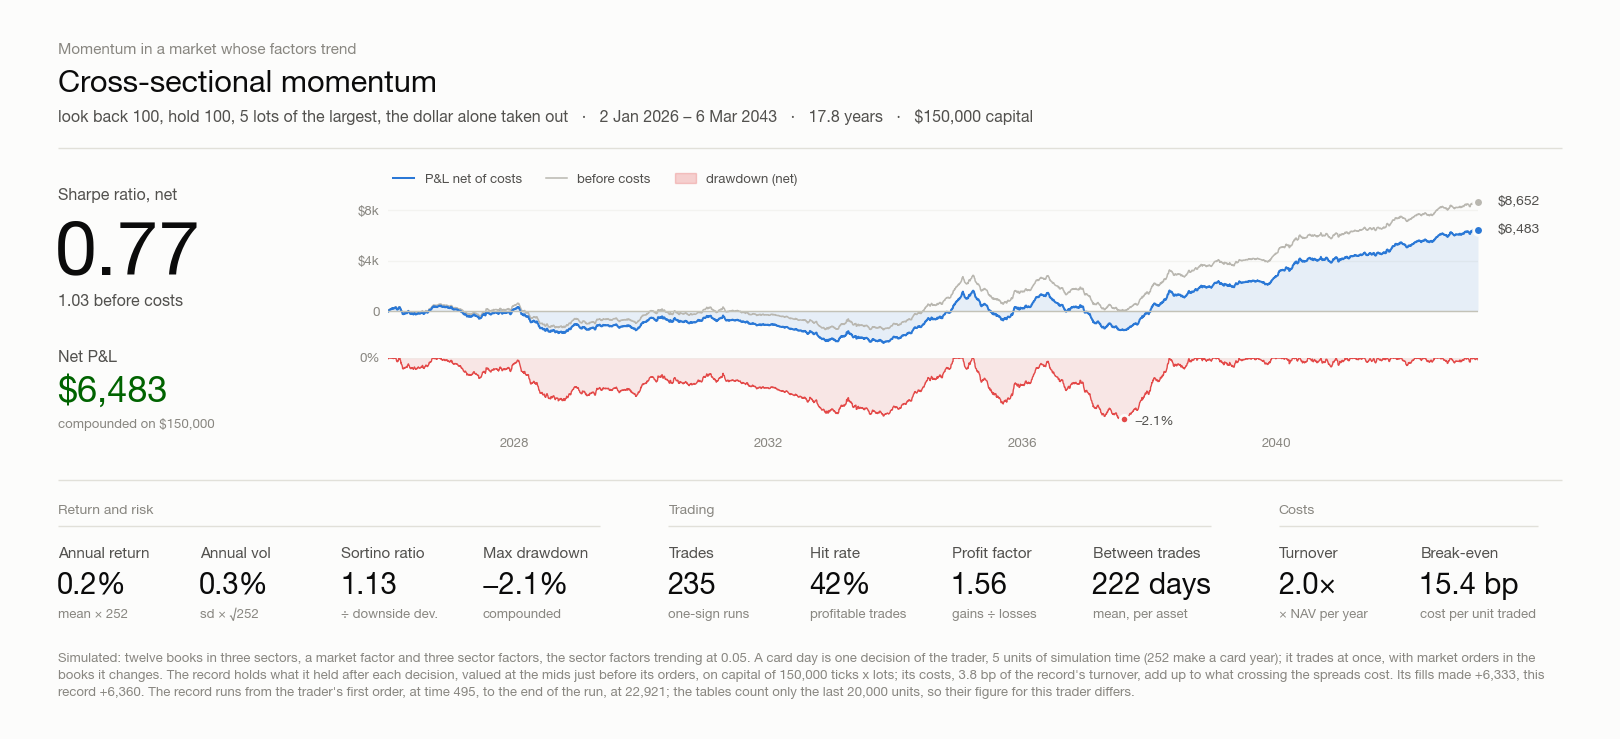

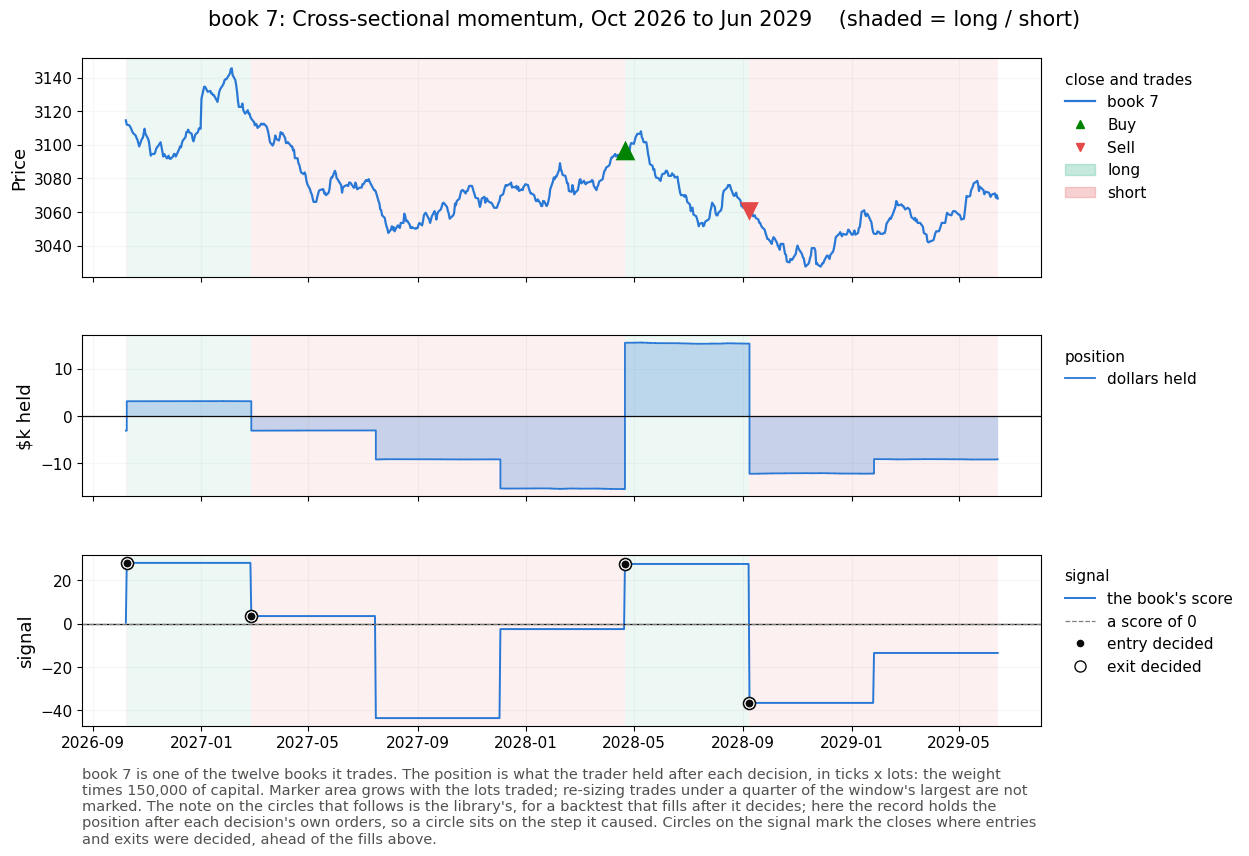

Momentum in a market whose factors trend: its fills made +6,333 and the record +6,360; it holds at most 0.84 times the capital of 150,000, and more than it on 0.0% of days.
The table's figure for this run, the last 20,000 units: +6,460. The chart is of book 7.


In [36]:
# Momentum with the dollar alone taken out, in the sectors market with the three sector factors trending at 0.05: one
# run of the card's seed with the record on, to the end of the burn and the span.
trend_trader, trend_fills, trend_market = recorded(trend_trending('sectors', 0.05), trend_momentum(0), TREND_BURN)
assert trend_market.fair.pushed == 0, 'the card run pushed a fair value up from the floor'
trend_book = most_changed(trend_trader)  # the book whose lots change most often
trend_card = card(
    trend_trader,
    trend_fills,
    'Cross-sectional momentum',
    'look back 100, hold 100, 5 lots of the largest, the dollar alone taken out',
    'Momentum in a market whose factors trend',
    'twelve books in three sectors, a market factor and three sector factors, the sector factors trending at 0.05',
    "the book's score",
    [(0.0, 'C7', 'a score of 0')],
    trend_book,
    relation=trend_book,
    capital=CAPITAL,
    per_unit=5,
)
trend_card_counted = trend_t1_frame[
    (trend_t1_frame.row == 'trend 0.05') & (trend_t1_frame.seed == CARD_SEED)
].pnl.item()
print(
    f"The table's figure for this run, the last {SPAN:,.0f} units: {trend_card_counted:+,.0f}. "
    f'The chart is of book {trend_book}.'
)

**The record agrees with the fills to 27, and the table's figure for this run is 100 above the card's.** The fills made +6,333 and the record +6,360. The record stops at the trader's last decision and the run does not, and the difference is what the position's value did in the units after it; the notebook does not measure that, and a position that holds about 20 lots of the factors (the table's `exposure`, 20.04), which move a tick a root unit, can move that much in the 5 units of one decision. Notebook 13's cards, whose traders held little of the factors, were within 1 to 8 of their fills (section 4's from 2 to 8, section 5's within 1, section 6's 4). The table's figure for this seed and trader, +6,460, counts only the last 20,000 units after the burn, where the card runs from the trader's first order, at time 495, to the end of the run, at 22,921, so the two differ by 100 (the table's less the record's). The scorecard's headline, a net P&L of $6,483, is compounded on the capital, as its label says, and so is not the record's sum. Seed 101's +6,460 is below the table's mean for 0.05, +7,613 (se 1,384), by 1,153, under one standard error of the mean, and below the net's +7,359 (se 516) by 899: one seed of the eight.

**The card is not leveraged, and its figures are those of a trend follower.** The most the trader holds is 0.84 times the capital of 150,000, and it holds more than the capital on 0.0% of days. The net Sharpe is 0.77 (1.03 before costs, which holds the mids' bounce and is not an edge), the Sortino 1.13, the maximum drawdown -2.1%, the annual return 0.2% and the annual volatility 0.3%. A card day is one decision of 5 units and 252 make a card year, so the Sharpe is on that convention and is for comparing cards; the percentages are of a capital that is large against what the trader makes, and are not comparable with a card of another capital. The trader makes 235 trades, 42% of them profitable, with a profit factor of 1.56 and 222 days between trades: it is right on fewer than half and gains more on the right ones than it loses on the wrong, which is what following a drift looks like. Its turnover is 2.0 times the capital a year, the spreads cost it 3.8 bp of that, and the cost at which the card would break even is 15.4 bp. In the card's calendar the net line is below its start for most of the first twelve years, rallies once in the mid-2030s and gives that back (the drawdown is the give-back), and makes most of its gain in the last five or so years. The gains come in long swings with a factor's drift, and the losses in the pauses between them.

**In the chart the score is a slow one, re-read every 100 decisions.** The chart is of book 7, the book whose lots change most often, over 700 decisions: seven holds, each of 100 decisions or 500 units, the length of the drift's half-life. The book's score is a step that changes only at a rebalance, and so is its position. The trader is long book 7 at the first and the fifth hold, when its score is highest in the window, and short in the other five, though the score is about 0 or above in the second and fourth: it holds the scores less their mean over the books, so a book is long or short by its rank among them and not by its own sign. Only two of the position's changes, the swings from short to long and back in 2028, are large enough to be marked as trades; the others are under a quarter of the largest and are not. So the signal is slow, on the scale of the drift's half-life. That suits a trend, which a rule that reads 500 units and holds 500 can ride, and suits the costs, since it pays the spread at about seven rebalances in the window and not at each of the 700 decisions.

### What This Section Cannot Show

- **That momentum pays in a market like a real one.** Here the only thing that can continue is a factor's drift, and that is how the market is built: a book's own part mean-reverts, as it must for any relation between the books to exist, and the factors are random walks. So the section can say how large a drift pays, 0.0269 in the sectors market, where it is 22.5% of the variance of a factor's move over the look back and two successive moves correlate 0.15, and not whether markets have one, nor which explanation of momentum is right. A momentum that comes from the books' own parts, from news that spreads slowly or from investors who herd, has no room here, and no row of this section tests it. What a dollar-neutral trader can hold is the spread of the trending factors, because the first factor never trends; a drift in the market factor, which every book loads on, is not in this dial.
- **A break-even for other settings or other drifts.** There is one look back and hold, a drift whose half-life (500 units) is the look back's length, 5 lots of the largest weight, and market orders that pay the spread and nothing else (no fees, no borrow, no financing). The look back 200 neighbor broke even a little lower on seeds 1 to 8, about 0.004, and a different half-life would move both the best look back and the break-even. The mixed market, with the same trader, breaks even at 0.0364 against the sectors market's 0.0269, so the figure also depends on the market (its loadings, and which factors trend). It belongs to this trader in this market, and the trends of the dial are in ticks a unit of time, as the index's and the deals' dials are in other units: the three break-evens are not on one scale.
- **The long run from windows.** The market's P&L column is one window of 20,000 units a seed, and a window's factor part varies a good deal from one window to the next (`sd_block` is 2,826 at 0.02 and 7,847 at 0.1 in the sectors market), so a mean of eight windows can sit far from the long-run mean in either direction. Seeds 1 to 8's windows sat above it, and on these seeds the mixed market's sat below it. In the mixed market the windows sat below the other blocks of their seeds, by 1,471 (se 461) at 0.02 to 3,135 (se 787) at 0.1, 3.19 to 5.59 times the paired standard error at 0.02 to 0.1 and 2.45 to 3.46 times the one from all the blocks, so that its window at 0.05 made -298 (se 454) against a net of +2,155 (se 159). On 24 other seeds, run after the eight showed it, the mixed market's route has its first block less the other nine at +2 (se 235), -144 (se 298), -256 (se 346) and -379 (se 390) at 0, 0.03, 0.04 and 0.05, none as much as one standard error from 0, against the eight's -2,538 at 0.05, 2,159 lower, which is 3.6 times the standard error of that difference by the paired standard errors and 2.5 by the ones from all the blocks (plain calculations). Nothing in the model makes a first block differ from the others, so it reads as these eight seeds' luck and not a difference between the markets, though a shortfall of a few hundred is not ruled out on other seeds, and the 32 seeds together, which include the eight, still put it 919 below (se 353) at 0.05. In the sectors market the windows were not separated from the other blocks in either direction: the market's own eight were -573 (se 1,212) at 0.02 and +3,323 (se 2,408) at 0.1, and the route's first block on the dial's twelve seeds +267 (se 956) and +3,687 (se 2,061), under two standard errors at every value by the paired standard error and by the one from all the blocks (at most 1.38 and 1.10 for the eight, at 0.1, and 1.79 and 1.54 for the twelve), and on 24 more seeds the first block sat below the others (-539, se 583, at 0.02), not separated from them either. The two standard errors are two estimates of one spread, the first from eight differences and the second from all eighty blocks, and where they differ the larger is the one to lean on, because a spread taken from so few numbers can fall below the true one by chance and every ratio over it is then too large; the mixed market is where they differ most. That these windows were not shown to be lucky in the sectors market says nothing about other seeds, and the windows of seeds 1 to 8, which were lucky, are why the market's own column is not read for the long run. The net takes the factor part from the books-free route's blocks, and its break-even is a long-run one: its factor part is the route's long run in fair values, and the rest is the market's, from its eight windows. It is an estimate with an interval from bootstrap resamples of the seeds, and the market's part of it, eight seeds of one window, now sets its width: `resid_se` is 270 and 284 at 0.02 and 0.03, against 94 and 140 for `gain_se`.
- **What the books-free route claims.** It is the same rule fed the fair values on a grid of exactly 5 units, with no order books: no impact, no costs, no noise in the mids, and a position held between decisions. It gives the expected factor part of this rule at these settings and, through the net, the market's mean P&L. In this run it matched the market's factor part for the dollar-alone trader, window by window, to 1.0% to 9.3% of it at the values with a trend and a correlation of 0.965 or more, with a gap that was positive here and negative on seeds 1 to 8 and nowhere as much as two standard errors from 0, so no shortfall of either is shown. It cannot give P&L, costs, the rest or any risk figure by itself. It is a check on the dollar-alone trader and nothing else: for a trader that takes factors out, whose factor part is mostly the error of its estimates from noisy mids, the route gave a small fraction of the market's factor part on seeds 1 to 8, where it was tried, so the tables of factors taken out and of the mirror are market runs and the route is not used for them. It cannot say anything about deals or an index, and it is run at a level so high that no fair value comes near the floor, which the market runs, at the notebook's level, are asserted not to reach.
- **That the factor part is what the trader "chose".** It is what its position held of the true factors, times their moves, summed over the span. A trader with `factors=0` does not know it holds the factors' spread; the weights are the scores less their mean, and the factor part is what that happens to hold in this market.
- **Why one estimated factor takes out what it does.** At 0.05 the trader neutral to one factor keeps 62.3% of the dollar-alone trader's factor part in the sectors market and 104.4% in the mixed. The notebook prints what the first estimated factor is and what the trader projects out. Its eigenportfolio's cosine with the vector of ones is 1.00 in the sectors market and 0.97 in the mixed, and 1.00 and 0.97 with the market factor, so to those figures it is the direction the dollar already takes out. What the trader projects out is the books' exposures to that factor, and those are printed too: in the sectors market they have a cosine of 1.00 with the vector of ones and a tilt of 0.08 of their size, whose cosines with the three sector factors' loadings less their mean are 0.57, 0.45 and 0.43; in the mixed market a cosine of 0.97 with the ones, a tilt of 0.24 of their size and a cosine of 0.95 of that tilt with the market factor's loadings less their mean. The library's `neutralize` removes the direction of an exposure row whatever its size, so a small tilt in an exposure row of nearly ones is taken out whole, which fits the 37.7% in the sectors market and nothing in the mixed; the notebook does not print how much of the factor part lies along the tilt, so it does not show that this is what took the 37.7% out, or why it differs from the about half that seeds 1 to 8 gave in the sectors market. The three-factor trader's small factor part (+193 and +86) is not tested against 0, as its standard error is not printed.
- **The traders that take the factors out, beyond "no effect found".** The table of the traders that take every factor out has eight seeds. A trend of 0.05 changes the pairs by -77 (se 151) and the residuals by -224 (se 269); those standard errors are 2.6% and 6.7% of the P&L at no trend, and a change of a few percent would not be told from nothing by it. The table does not say there is no effect, only that none was large enough to see.
- **Risk beyond 100 units.** The 100-unit deviation still flatters a position that continues over 500 units, the length of the drift's half-life: its figure is below the one over the horizon of the drift. It is 1.96 times the one-unit figure at trend 0, 2.19 times at 0.05 and 2.65 times at 0.1, and the notebook does not say what makes it 1.96 where no factor continues. A 500-unit horizon has only 40 stretches in a span of 20,000 units, too few to measure it, and no deviation shows a skew.
- **The mixed market's break-even** rests on eight books-free seeds and three market points, where the sectors market's rests on more books-free seeds at the values that bracket it, which led one to expect it to be less precise. It is not: its interval, 0.0352 to 0.0374, is narrower than the sectors market's, 0.0251 to 0.0289, because the mixed market's windows and blocks scatter less. Its crossing lies between 0.03, where the market was run, and 0.04, where the market part is interpolated between 0.03 and 0.05, and the interval does not hold how far that line is from the market's own P&L at 0.04. It is not a second measurement of the same number, as the loadings differ.
- **The card.** It is one run of one trader on seed 101: a net Sharpe of 0.77 and a maximum drawdown of -2.1% are what that path gave, whose P&L in the table's window, +6,460, is below the mean of the eight seeds, +7,613 (se 1,384). The card's years are the card's convention, 252 decisions of 5 units to a year, and not the market's.
- **Seeds 1 to 8.** Every setting of the section, the trader's and the dial's, was chosen on seeds 1 to 8 and held fixed. The notebook's numbers are on seeds 101 and up, and the books-free route's extra seeds, 113 to 136, decided nothing. Where the fresh seeds differ from what seeds 1 to 8 led one to expect, the text says so: a break-even a little higher in both markets, a gap between the market's and the route's factor part with the other sign, a first estimated factor that takes out less in the sectors market and nothing in the mixed one, and first windows that were not shown to be lucky in the sectors market and were low in the mixed, which 24 other seeds did not repeat (-379, se 390, at 0.05). None was predicted and none has been replicated on other seeds, so none is a finding beyond these seeds.

## 4. Conclusions

The cell below prints, for each section, what the conclusions rest on, from the frames and tables the sections left: the control, the rows of the dial, the break-even and its interval, and the comparisons the section turns on. It ends with the core-minutes the runs took. The conclusions quote these figures and a few from the sections' tables, which is where they come from; a figure that is a ratio, a difference or a product of printed figures says so.

In [37]:
# The headline figures of the three sections, from the frames and tables they left: for each section the control, the
# rows of its dial, the break-even and its interval, and the comparisons it rests on. The conclusions quote these
# printed figures and no others. Last, how long the runs took.
print(
    f'Seeds {SEEDS[0]} to {SEEDS[-1]} ({FEW[0]} to {FEW[-1]} where a table varies one thing); ticks x lots after costs.'
)


def plus(x, digits=2):
    # A signed figure, or 'n/a' for a mean over nothing (a row with no broken deal has no broken lot pair).
    return 'n/a' if np.isnan(x) else f'{x:+,.{digits}f}'


# ---------------------------------------------------------------------------------------------------------------------
print(f'\nSection 1, an index book (sectors market, one basket, burn {INDEX_BURN:,.0f}, span {SPAN:,.0f} units)')
for convention in WEIGHTS:
    along = ', '.join(f"{p} {index_i1_table.loc[row_name(convention, p), 'premium']:.1f}" for p in DIAL)
    print(f"- {convention} index, the premium's sd with no trader, in ticks of a basket, by dial point: {along}.")
for convention in WEIGHTS:
    r = index_i2_table.loc[row_name(convention, 'strict')]
    print(
        f'- {convention} index, the strict control (no premium, no impact): {said(r)}; before costs '
        f'{r.before_costs:+,.0f}, costs {r.costs:,.0f}, {r.entries:.1f} entries at {r.cost_an_entry:.1f} an entry.'
    )
for convention in WEIGHTS:
    print(f'- {convention} index along the dial (the premium measured, P&L, entries, cost an entry, deviation_long):')
    for p in LINE:
        r = index_i2_table.loc[row_name(convention, p)]
        print(
            f"    index_volatility {DIAL[p]['index_volatility']:g}, premium {r.premium:.1f}: {said(r)}; "
            f'{r.entries:.1f} entries, {r.cost_an_entry:.1f} an entry, deviation_long {r.deviation_long:.2f}.'
        )
r = index_i2_table.loc[row_name('sum', LINE[0])]
print(
    f'- Sum index, break-even: at its lowest dial point (index_volatility {VOL[0]:g}, premium {r.premium:.1f}): '
    f'{said(r)}.'
)
rows_sum = [index_i2_table.loc[row_name('sum', p)] for p in LINE]
stays = [i for i in range(len(LINE)) if all(x.positive == len(FEW) for x in rows_sum[i:])]
if stays:
    print(
        f'  Every seed positive from index_volatility {VOL[stays[0]]:g} on (premium {rows_sum[stays[0]].premium:.1f}).'
    )
else:
    print('  No dial point from which every seed is positive.')
if index_break_even:
    b = index_break_even
    print(
        f"- 1/12 index, break-even: premium sd {b['premium']:.1f} ticks of a basket (index_volatility "
        f"{b['volatility']:.2f}), 5% to 95% {b['low']:.1f} to {b['high']:.1f}, between the dial points "
        f"{b['between'][0]} and {b['between'][1]}."
    )
else:
    print('- 1/12 index, break-even: its mean P&L does not cross 0 on the dial.')
for p in (LINE[0], CHOSEN, LINE[-1]):
    d = index_i2_paired.loc[f'1/12 less sum, {p}']
    print(
        f"- 1/12 less sum at index_volatility {DIAL[p]['index_volatility']:g}: {said(d)}; before costs "
        f'{d.before_costs:+,.0f} (se {d.before_costs_se:.0f}), costs {d.costs:+,.0f}, entries {d.entries:+.1f}.'
    )
for p in UNHEDGED_POINTS:
    d = index_i4_paired.loc[f'unhedged less hedged, {p}']
    h, u = index_i4_table.loc[f'hedged, {p}'], index_i4_table.loc[f'unhedged, {p}']
    print(
        f'- Unhedged less hedged, sum index at {p}: {said(d)}; before costs {d.before_costs:+,.0f} '
        f'(se {d.before_costs_se:.0f}), costs {d.costs:+,.0f}, factor part {d.factor_part:+,.0f} '
        f'(se {d.factor_part_se:.0f}). deviation_long {u.deviation_long:.2f} against {h.deviation_long:.2f}, '
        f'risk_adjusted_long {u.risk_adjusted_long:+.3f} against {h.risk_adjusted_long:+.3f}; the unhedged row has an '
        f'se of {u.se:.0f} against {h.se:.0f}.'
    )
print(
    f"- The full replication in the sampled hedge's window (burn {SAMPLED_BURN:,.0f}): "
    f'{said(index_i5_table.loc[FULL])}.'
)
for name in SAMPLES:
    d, r = index_i5_paired.loc[f'{name} less {FULL}'], index_i5_table.loc[name]
    print(
        f'- {name} less the full replication: {said(d)}; before costs {d.before_costs:+,.0f} '
        f'(se {d.before_costs_se:.0f}), costs {d.costs:+,.0f}, entries {d.entries:+.1f}; deviation_long '
        f'{d.deviation_long:+.2f}; the true factors leave {r.left_norm:.2f} lots on average.'
    )
for label in ('sum: 3 baskets less 1', '1/12 less sum, 3 baskets'):
    d = index_i6_paired.loc[label]
    print(
        f'- {label}: {said(d)}; before costs {d.before_costs:+,.0f}, costs {d.costs:+,.0f}, entries {d.entries:+.1f}.'
    )
print(
    f"- The card (seed {CARD_SEED}): fills {index_card['fills']:+,.0f}, record {index_card['record']:+,.0f}, the most "
    f"it holds {index_card['peak']:.2f} times the capital, above it on {index_card['above_one']:.1%} of days; the "
    f"table's figure for the same run {index_card_counted:+,.0f}."
)
for label, d in index_i7_both.iterrows():
    print(
        f'- {label}: {said(d)}; before costs {d.before_costs:+,.0f} (se {d.before_costs_se:.0f}), costs '
        f'{d.costs:+,.0f}, entries {d.entries:+.1f}.'
    )
for name in (FULL, 'legs 3'):
    print(f'- {name}, {OFF}: {said(index_i7_table.loc[f"{name}, {OFF}"])}.')
for label, d in index_i8_paired.iterrows():
    print(
        f"- {label}, index_volatility {DIAL[SURPRISE]['index_volatility']:g}: {said(d)}; before costs "
        f'{d.before_costs:+,.0f} (se {d.before_costs_se:.0f}), costs {d.costs:+,.0f}, entries {d.entries:+.1f}.'
    )

# ---------------------------------------------------------------------------------------------------------------------
print(
    f'\nSection 2, deals (sectors market, announcements at {DEAL_RATE} a unit, burn {DEAL_BURN:,.0f}, '
    f'span {SPAN:,.0f} units)'
)
dial, lots = deals_dial_table, deals_dial_pairs
r = dial.loc[DEAL_CONTROL]
print(
    f'- The control, breaks {DEAL_PRICED:.2f} (the price is the true chance), {len(SEEDS)} seeds: {said(r)}; share of '
    f'ended deals that broke {r.share:.3f}; before costs {r.before_costs:+,.0f}, costs {r.costs:,.0f}, '
    f"{r.cost_a_lot:.2f} a lot; a lot pair {lots.loc[DEAL_CONTROL, 'pair']:+.2f}."
)
print('- Along the dial (the share that broke, counted; P&L; a lot pair; its completed and broken means; c / (c - b)):')
for b in DEAL_DIAL[1:]:
    r, q = dial.loc[DEAL_ROW[b]], lots.loc[DEAL_ROW[b]]
    print(
        f'    breaks {b:.2f}: {r.share:.3f} broke; {said(r)}; before costs {r.before_costs:+,.0f}, costs '
        f'{r.costs:,.0f}; {q.pair:+.2f} (se {q.pair_se:.2f}), completed {plus(q.comp)}, broken {plus(q.brk)}, '
        f"c / (c - b) {'n/a' if np.isnan(q.be) else f'{q.be:.3f}'}."
    )
e = deals_break_even
print(
    f"- Break-even from the line through the seven means: breaks {e['line']:.3f} (bootstrap sd {e['line_sd']:.3f}, "
    f"95% {e['low']:.3f} to {e['high']:.3f}); the dial's own arithmetic gives its root an sd of "
    f"{e['arithmetic_sd']:.3f} over {len(SEEDS)} fresh seeds."
)
print(
    '- Break-even from the deals, c / (c - b): '
    + ', '.join(f'{x:.3f} (bootstrap sd {sd:.3f}) at breaks {b:.2f}' for b, (x, sd) in e['records'].items())
    + '.'
)
s = deals_shape
print(
    f"- What a deal makes at breaks {DEAL_CHOSEN:.2f}, {s['deals']:,.0f} deals: completed "
    f"{s['completed, mean']:+.2f} (sd {s['completed, sd']:.2f}), broken {s['broken, mean']:+.2f} "
    f"(sd {s['broken, sd']:.2f}, worst {s['broken, worst']:+.2f}), {s['share broken']:.1%} broken; skew "
    f"{s['a lot pair, skew']:+.2f}, hit rate {s['hit rate, of deals']:.1%}, profit factor "
    f"{s['profit factor, of deals']:.2f}, worst deal {s['worst deal, ticks x lots']:+,.0f}; a seed's P&L between "
    f"{s['worst seed, P&L']:+,.0f} and {s['best seed, P&L']:+,.0f}."
)
for m in ('sectors', 'mixed'):
    r = deals_mixed_table.loc[f'{m} {DEAL_ROW[DEAL_CHOSEN]}']
    print(f'- The {m} market at breaks {DEAL_CHOSEN:.2f}, {len(FEW)} seeds: {said(r)}.')
wander = deals_wander.loc['std']
print(f"- How far the gap wanders over a deal, mixed over sectors: {wander['mixed'] / wander['sectors']:.2f} times.")
late, fair_late = deals_late_ones, pd.Series(deals_late_gains)
print(
    f'- Late entry (entry 24) in the control, on the {len(late)} deals entered late: a lot pair '
    f'{late.more.mean():+.2f} '
    f'(se {se_of(late.more):.2f}) more than entering at the first decision, and {fair_late.mean():+.2f} '
    f'(se {se_of(fair_late):.2f}) at fair values alone.'
)
for b in PAIRS_DIAL:
    blind_row, reader_0, reader_q = three_of(b)
    print(
        f'- Pairs, deals announced at {PAIRS_DEAL_RATE} a unit, breaks {b:.2f}, {len(FEW)} seeds, burn '
        f'{DEAL_PAIRS_BURN:,.0f}: blind {said(deals_pairs_table.loc[blind_row])}; the reader out for the deal '
        f'{said(paired(deals_pairs_frame, reader_0, blind_row))} less blind; the reader out until the step has left '
        f'its window {said(paired(deals_pairs_frame, reader_q, blind_row))} less blind.'
    )
r = deals_pairs_table.loc['no deals']
print(
    f"- Pairs with no deals, {len(FEW)} seeds: {said(r)}; less blind at breaks {PAIRS_DIAL[0]:.2f} "
    f"{said(paired(deals_pairs_frame, 'no deals', three_of(PAIRS_DIAL[0])[0]))}."
)
print(
    f"- The card (seed {CARD_SEED}, capital {CAPITAL_DEALS:,.0f}): fills {deals_card['fills']:+,.0f}, record "
    f"{deals_card['record']:+,.0f}, the most it holds {deals_card['peak']:.2f} times the capital, above it on "
    f"{deals_card['above_one']:.1%} of days."
)
x = deals_share_line
print(
    f"- Break-even from the line through the seven means against the counted share of ended deals that broke: "
    f"{x['line']:.3f} (bootstrap sd {x['sd']:.3f}, 95% {x['low']:.3f} to {x['high']:.3f}); against the nominal "
    f"breaks, {deals_break_even['line']:.3f}."
)
for w, same_row, own_f, own_c in zip(WHO, SAME_THREE, own_fair, own_cheap, strict=True):
    print(
        f'- Pairs, {w}, on the pairs of breaks {FAIR_B:.2f} in the market of breaks {CHEAP_B:.2f}: '
        f'{said(deals_same_table.loc[same_row])}; less its own row at breaks {FAIR_B:.2f} '
        f'{said(paired(both_worlds, same_row, own_f))}; less its own row at breaks {CHEAP_B:.2f}, on the pairs it '
        f'chose there, {said(paired(both_worlds, same_row, own_c))}.'
    )
for w, same_row in zip(WHO[1:], SAME_THREE[1:], strict=True):
    print(
        f'- Pairs, the {w} less the blind trader, on the pairs of breaks {FAIR_B:.2f} in the market of breaks '
        f'{CHEAP_B:.2f}: {said(paired(both_worlds, same_row, SAME_THREE[0]))}.'
    )

# ---------------------------------------------------------------------------------------------------------------------
print(
    f'\nSection 3, a factor that trends (momentum, dollar alone taken out; burn {TREND_BURN:,.0f}, '
    f'span {SPAN:,.0f} units)'
)
r = trend_t1.loc['trend 0']
print(
    f'- The control, trend 0, sectors market, one window a seed on {len(FEW)} seeds: {said(r)}; factor part '
    f'{r.factor_part:+,.0f}, rest {r.rest:+,.0f}, costs {r.costs:,.0f}.'
)
print("- Along the dial, sectors market (market: one window a seed; resid: that less the route's factor part of it):")
for s, r in trend_net['table'].iterrows():
    market = f'market {r.market:+,.0f} (se {r.market_se:.0f}), ' if not np.isnan(r.market) else ''
    print(
        f'    trend {s:g}: {market}resid {r.resid:+,.0f}, long-run factor part {r.gain:+,.0f} (se {r.gain_se:.0f}, '
        f'{r.gain_seeds:.0f} seeds), net {r.net:+,.0f} (se {r.net_se:.0f}).'
    )
for label, found in (
    ('Break-even, sectors market, net, all the books-free seeds', trend_net['net']),
    (f'Break-even, sectors market, net, the books-free seeds of the dial ({len(SEEDS)})', trend_net_few['net']),
    ("Break-even, sectors market, the market's one window a seed alone", trend_net['alone']),
):
    print(f'- {trend_break_text(label, found)}.')
if not np.isnan(trend_net['net'].point):
    share, correlation = trend_drift_moves(trend_net['net'].point)
    print(
        f'  At the net break-even the drift is {share:.1%} of the variance of a move over the look back; successive '
        f'moves correlate {correlation:.2f}.'
    )
print(f"- {trend_break_text('Break-even, mixed market, net', trend_t3_net['net'])}.")
print(f"- {trend_break_text('Break-even, mixed market, the market alone', trend_t3_net['alone'])}.")
first = trend_t1b.first_less_rest.loc[list(TREND_DIAL[1:])]
print(
    f"- On the dial's {len(SEEDS)} seeds, the route's first block less the other blocks of its seed (positive: lucky): "
    + ', '.join(f'trend {s:g} {x:+,.0f}' for s, x in first.items())
    + '.'
)
print(
    "- The market's factor part less the route's first block, as a share of the route's: "
    + ', '.join(f'trend {s:g} {x:+.1%}' for s, x in trend_agree.gap_share.dropna().items())
    + '.'
)
for name, r in trend_t4.iterrows():
    if name.endswith('trend 0.05'):
        print(
            f"- {name}: {said(r)}; factor part {r.factor_part:+,.0f}, kept {r.kept.strip() or 'n/a'}, "
            f'deviation_long {r.deviation_long:.2f}.'
        )
for name, r in trend_t5_sums.iterrows():
    print(
        f'- Momentum and reversal added, {name}: P&L {r.pnl:+,.0f} (se {r.pnl_se:.0f}), factor parts '
        f'{r.factor_part:+,.0f}, before costs {r.before_costs:+,.0f}, costs {r.costs:+,.0f}.'
    )
for trader in ('pairs', 'residuals'):
    d = paired(trend_t6_frame, f'{trader}, trend 0.05', f'{trader}, trend 0')
    print(
        f"- {trader}: trend 0 {said(trend_t6.loc[f'{trader}, trend 0'])}; trend 0.05 "
        f"{said(trend_t6.loc[f'{trader}, trend 0.05'])}; 0.05 less 0 {said(d)}."
    )
print(
    f"- The card (seed {CARD_SEED}): fills {trend_card['fills']:+,.0f}, record {trend_card['record']:+,.0f}, the most "
    f"it holds {trend_card['peak']:.2f} times the capital, above it on {trend_card['above_one']:.1%} of days; the "
    f"table's figure for the same run {trend_card_counted:+,.0f}."
)
for label, blocks in (
    (f"the sectors market's own {len(FEW)} seeds", trend_t1b_blocks[trend_t1b_blocks.seed.isin(FEW)]),
    (f"the mixed market's {len(FEW)} seeds", trend_t3_blocks),
):
    first_less = trend_first_table(blocks).loc[list(TREND_DIAL[1:])]
    print(
        f"- The market's window less the other blocks of its seed, {label}: "
        + '; '.join(
            f'trend {s:g} {r.first_less_rest:+,.0f}, paired se {r.paired_se:,.0f} ({r.over_paired_se:+.1f} se), '
            f'one block sd {r.sd_block:,.0f} gives se {r.sd_se:,.0f} ({r.over_sd_se:+.1f} se)'
            for s, r in first_less.iterrows()
        )
        + '.'
    )

# ---------------------------------------------------------------------------------------------------------------------
# Core-minutes of the runs that have a frame, each on one core. Not in them: the cards' three recorded runs, and the
# runs in fair values alone (the deals' counts, the wander of the gap and the late entries' check).
RUNS = {
    'index': {
        'the premium, measured': [index_i1_frame],
        'the dial': [index_i2_frame],
        'the hedge': [index_i4_new],
        'a sampled hedge': [index_i5_frame],
        'size and rate': [index_i6_new],
    },
    'deals': {
        'the dial': [deals_dial_frame],
        'the settings': [deals_settings_frame[deals_settings_frame.row != BASE]],
        'the mixed market': [deals_mixed_frame],
        'late entry': [deals_late_frame],
        'pairs and deals': [deals_nodeals_frame, deals_readers_frame],
    },
    'trend': {
        'the dial': [trend_t1_frame],
        'the books-free route': [trend_t1b_runs, trend_t1c_runs],
        'the mixed market': [trend_t3_frame, trend_t3_runs],
        'taking factors out': [trend_t4_new],
        'the mirror': [trend_t5_frame],
        'traders that take every factor out': [trend_t6_frame, trend_t6_more],
    },
}
print()
total = 0.0
for section, tables in RUNS.items():
    minutes = {name: sum(f.secs.sum() for f in frames) / 60 for name, frames in tables.items()}
    runs = sum(len(f) for frames in tables.values() for f in frames)
    total += sum(minutes.values())
    print(
        f'Core-minutes, {section}: {sum(minutes.values()):.0f} in {runs} runs ('
        + ', '.join(f'{name} {x:.1f}' for name, x in minutes.items())
        + ').'
    )
print(f'Core-minutes in all: {total:.0f}.')
# The runs added after the first run of the notebook, on the lines above's terms: one core each.
ADDED = {
    "the sample's edge with the own parts' shocks off": [index_i7_frame],
    'the surprise at the top of the dial, on other seeds': [index_i8_frame],
    'the same pairs in the other world': [deals_same_frame],
    'bare markets, the own parts and the spreads': [own_frame],
    "the mixed market's route on more seeds": [trend_t3_more_runs],
}
added = {name: sum(f.secs.sum() for f in frames) / 60 for name, frames in ADDED.items()}
print(
    f'Core-minutes, runs added after the first run: {sum(added.values()):.0f} in '
    f'{sum(len(f) for frames in ADDED.values() for f in frames)} runs ('
    + ', '.join(f'{name} {x:.1f}' for name, x in added.items())
    + f'); {total + sum(added.values()):.0f} with the above.'
)

Seeds 101 to 112 (101 to 108 where a table varies one thing); ticks x lots after costs.

Section 1, an index book (sectors market, one basket, burn 2,100, span 20,000 units)
- sum index, the premium's sd with no trader, in ticks of a basket, by dial point: strict 0.0, 0 14.7, 0.2 20.2, 0.4 32.0, 0.5 37.5, 0.8 58.1, 1.6 113.0.
- 1/12 index, the premium's sd with no trader, in ticks of a basket, by dial point: strict 0.0, 0 14.7, 0.2 19.6, 0.4 30.9, 0.5 38.4, 0.8 57.7, 1.6 112.6.
- sum index, the strict control (no premium, no impact): -2,100 (se 47, 0 of 8 seeds positive); before costs +4,333, costs 6,433, 142.4 entries at 45.2 an entry.
- 1/12 index, the strict control (no premium, no impact): -6,395 (se 130, 0 of 8 seeds positive); before costs +4,708, costs 11,102, 152.2 entries at 72.9 an entry.
- sum index along the dial (the premium measured, P&L, entries, cost an entry, deviation_long):
    index_volatility 0, premium 14.7: +7 (se 24, 5 of 8 seeds positive); 61.2 entries, 43.8 an

**Index: how large the premium must be, and what the index leg's cost does.** The question was how large the premium's swings must be before the rule pays what crossing the index book and the twelve books costs. In the sum convention the premium that the order flow's own orders make with the dial at 0, a standard deviation of 14.7 ticks of a basket, already pays it to within its noise: +7 (se 24, 5 of 8 seeds positive), so the sum index breaks even about there. Every seed is positive from 20.2 (+467, se 42), and the trade makes +1,214 (se 48) at 32.0, the chosen point, and +6,186 (se 223) at 113.0. How far below 14.7 it would still pay is not shown, since the dial has no such point with the books' impact on: at the 84 ticks of P&L a tick of premium that its first two points give, two standard errors are about 0.6 of a tick of premium, so the figure is 14.7 give or take about that on a straight line. The same position through the 1/12 index, an entry of which costs 71.4 at the chosen point against 40.6, and whose own orders push the premium twelve times as far (by arithmetic from the settings), pays only from a premium of 32.5 ticks of a basket (31.6 to 33.4, 5% to 95%): -118 (se 42, 1 of 8 seeds positive) at 30.9 and +427 (se 44, 8 of 8) at 38.4. Paired by seed the 1/12 is 1,331 (se 80, 0 of 8 seeds positive) below the sum at the chosen point, with 1,533 (se 79) more in costs. So the book that the index leg is traded in moves the break-even by a factor of about 2.2 (32.5 over 14.7), and the figure belongs to that convention and to this simulator's books, not to an index. With no premium and no impact the strict controls lose on every seed, -2,100 (se 47) and -6,395 (se 130), though they make +4,333 and +4,708 before costs: that is the bounce of the index book's mid, which is why before costs is not read as an edge here or in the other sections. These are means of eight seeds of one simulated market, with the settings (a window of 400, an entry of 2, a rate of 1, one basket) chosen beforehand on seeds 1 to 8 at 0.4 in the sum convention. The chosen row made +1,214 here against +1,145 there, so no loss to selection shows. The sum's break-even is not bracketed, and the 1/12's interval holds the seeds' spread and the premium's measurement error, not how the line bends between its two points. One figure went against what seeds 1 to 8 led one to expect: at 1.6 the 1/12 made 791 less (se 259) before costs than the sum in the same position on the dial's eight seeds, where on seeds 1 to 8 the two made about the same. That was noticed for being large, and eight other seeds, run after the first run showed it, give +243 (se 246) and the sixteen together -274 (se 218), so the gap before costs is not a finding. The gap after costs is in all sixteen (-1,525, se 169, 0 of 16 seeds positive), and the dearer book's costs, 1,251 (se 69) higher, are most of it. Nothing here rests on it.

**Index: what the legs are worth.** The questions were whether the twelve legs pay for themselves, whether fewer would do, and whether more baskets pay more. Without the legs the trader makes +1,109 (se 196, 8 of 8 seeds positive) more at the chosen point and +1,184 (se 435, 6 of 8) more at 1.6. Its costs are 930 (se 107) and 842 (se 56) lower, and before costs the two differ by +180 (se 210) and +342 (se 444): the legs added nothing that eight seeds can see before costs, though a gain of a few hundred is not ruled out. What they buy is risk. The risk over 100 units is 6.91 against 1.92 at the chosen point, the P&L per unit of it 0.017 against 0.032, and the standard error of the mean P&L 205 against 48. A hedge from the three books that best explain the index, one in each sector, beats the full replication by +567 (se 77, 8 of 8 seeds positive). The gain is made before costs (+740, se 147) on as many entries (-0.2, se 1.6), and costs are 173 (se 82) higher, so it is a different trade and not a cheaper hedge, and its risk over 100 units is higher (2.66 against 2.00). Why it pays is the books' own parts: with their shocks off (`own_volatility` 0, which leaves the own part that the order flow makes: a standard deviation of 1.2 ticks of a lot against 4.8) the sample is 90 behind the full replication (se 50, 1.8 standard errors, so not separated from 0; 3 of 8 seeds positive) where with them on it is ahead by 567, and most of its extra risk goes with them (+0.15, se 0.08, with them off). On seeds 1 to 8 the edge went too, and the cell that runs it here was added to repeat that check on these seeds, not because of anything the first run showed. It is a property of this market's own parts and not a result about sampling an index, and since taking the shocks out changes the order flow as well as the fair values, and leaves the part the order flow makes, it does not show that they are the whole reason. In fair values with no trader the full replication's spread has the premium's standard deviation, 32.0 ticks of a basket, and the sample's is larger, 44.1, by the own parts its lots leave in it; with the shocks off the premium is 31.8, the full replication's spread 31.8 and the sample's 32.1, within 0.3 of the full replication's. Read as a premium, a spread of 44.1 is priced by the dial at 683 more than one of 32.0 (a plain interpolation between its rows at 37.5 and 58.1), of the order of the sample's +567, which is a reading of the spread's size and not a decomposition. Two books or one cannot cancel the factors (the true factors leave 6.12 and 8.49 lots) and make -95 (se 427) and -144 (se 474), which eight seeds do not separate from 0. They are 1,291 (se 403) and 1,340 (se 476) below the full replication, positive on 1 of 8 seeds each, and across their seeds their P&L follows the factor part (correlations +0.95 and +0.98), though not every seed's sign. Three baskets make +2,693 (se 101) against +1,214: 2.2 times the P&L for three times the size, since before costs they scale 3.0 times and costs 3.6 times, and the risk over 100 units 2.85 times (5.48 against 1.92). Trading less does not help. A rate of 0.25 at three baskets lowers costs by 1,183 (se 280) and gives up 1,785 (se 461) before costs, a paired -602 (se 225, 2 of 8 seeds positive), and an entry of 1 with a rate of 0.25 at one basket is 1,413 (se 114, 0 of 8) below the chosen setting. Three baskets of the 1/12 index lose 6,318 (se 513), 9,012 (se 532) below the sum at the same size, where three times the one-basket gap would be 3,993: a different trade, on 57.1 entries against 41.1, in which by arithmetic from the settings an entry's own orders move the premium by 21.6 ticks of a basket, 0.70 of its standard deviation (against 0.23 at one basket and 0.06 and 0.02 for the sum index at three baskets and one); the notebook does not measure how much of the loss that is. All of it is eight seeds at one point of the dial, with samples sized to hold one index lot, no size above three baskets and one rate.

**Deals: where the trade breaks even, and what its P&L looks like.** The question was how far the true chance of a break must fall below the price, 0.40, before the deal trader pays its costs, and what its P&L looks like when it does. At a fair price it loses: -2,379 (se 348, 0 of 12 seeds positive), of which 1,984 is costs and -395 is before costs, on a share of ended deals that broke of 0.415. It crosses 0 near a true chance of 0.30 (+271, se 275, 7 of 12 seeds positive), and from 0.25 every seed is positive: +1,652 (se 329) at 0.25, +2,747 (se 346) at 0.20 and +7,370 (se 214) at 0.00. The line through the seven means puts the break-even at 0.310 (bootstrap sd 0.010, 95% 0.290 to 0.331), the same line against the counted share of ended deals that broke at 0.316 (bootstrap sd 0.004, 95% 0.307 to 0.324), and the deals' own completed and broken lot pairs, c / (c - b), at 0.311 and 0.308 (bootstrap sd 0.003 each). The counted share is not quite the deals' own unit: from 0.40 to 0.20 it leans 0.003 to 0.004 toward the broken against the deals with a kept record (0.3048 against 0.3012 at the 0.30 row, where 971 deals ended and 966 have a record, and the five without one all broke), and the line's root against the share among the kept records is 0.312 (bootstrap sd 0.004, 95% 0.304 to 0.320), so in the deals' own unit the ways agree to within 0.004 (0.312, 0.311 and 0.308). The deals' way is the tighter because which deals happened to break drops out of the ratio, and the line in the nominal `breaks` carries that luck: the dial's own arithmetic gives its root an sd of 0.014 over twelve fresh seeds, and that is the spread to read it with, while the line against the counted share, from which that luck is taken out, has the 0.004. At the break-even the edge, 60 x (0.40 - 0.311) at the deals' own figure, is 5.3 ticks a lot pair, of which 5.00 is the cost of the lot pair and the rest, about 0.3, is what a lot pair loses before costs at a fair price (the 0.30 row's printed means at a share of 0.40 make -5.34 a lot pair, which is -5.00 of cost and -0.34 before costs), and the price of a break must exceed the true chance by about 0.09 (0.40 less 0.311) to pay for the lot pair, of which 0.083 (5.00 over 60) is the four spreads. What the trade makes is many small gains and a few larger losses. At 0.20, over 966 deals, a completed deal makes +18.57 a lot pair (sd 3.22) and a broken one, 19.6% of deals, loses 41.72 (sd 8.52, worst -69.20), which is 2.2 completed deals; the skew is -1.57, the hit rate 80.4%, the profit factor 1.83 and the worst deal -346 ticks x lots. A seed's total (+892 to +4,562, pooling about 81 deals) shows none of that, and neither do the two risk figures. The mixed market gives the sectors market's dial to within noise (paired differences of -118, +42 and +107, se 283, 184 and 114), with a broken deal's loss twice as spread (an sd 1.96 and 2.39 times as large, ratios of printed sds), as the gap between the two books' fair values wanders 2.38 times as far there. Entering late in the control makes 744 more than entering at the first decision (se 137, 8 of 8 seeds; -1,380 against -2,124), but that is the mids' noise: at fair values the same entries earn 0.28 a lot pair less (se 0.11), and what the mids add to a late entry is positive on all eight seeds (+1.81 a lot pair, se 0.13). These are twelve seeds of one simulated market, with settings chosen beforehand and not for their P&L. The break-even is for five lots of the target, a deal of 500 units and a premium of 60, and it moves with the size through the cost of a lot pair alone (by -0.012 at 2 lots and +0.020 at 10). The shape of many gains and a few losses is built in by the simulator's break, and is not evidence about real mergers.

**Deals: a pairs trader, and the news.** The questions were what deals do to a pairs trader, and whether reading the news helps. At a fair price deals take 3,659 (se 344, 8 of 8 seeds positive) from the pairs trader that does not read them: +2,044 (se 272) against +5,703 (se 118) with none, which is about 64% of its P&L (3,659 over 5,703), on about half the entries (138.4 against 272.4) and more than twice the risk over 100 units. At a fair price there is no bet to lose, so the loss is not a premium given up, and the notebook shows the loss and not its mechanism. A reader that keeps out of a deal's target until the step has left its window makes 692 less than the blind trader at the fair price (se 164, 0 of 8 seeds positive), and one that is out for the deal's life 119 less (se 217, 4 of 8), which is nothing eight seeds can separate. Where the true chance is 0.20 the readers are +88 (se 295, 3 of 8) and +429 (se 256, 5 of 8) against the blind trader, and neither is separated from it. So on each trader's own pairs reading the news bought nothing that can be told from nothing, and at the fair price the default quarantine, the longer of the two, cost 692. The blind trader makes 1,207 (se 178) less at 0.20 than at 0.40, on every one of the eight seeds, against 694 for the bet its short positions in the targets make by arithmetic; by the split of its P&L by where it was made, 686 (se 194) of the fall is in the targets' books while the deals are on, about the bet, and 521 (se 125) is everywhere else. The readers make less too (659, se 301, and 427, se 180), though they hold none of a target while its deal is on, and their falls are made everywhere else (671, se 298, and 427, se 180), the targets' books while the deals are on changing by a few ticks (+12, se 5, and +0, se 0). Each trader chooses its pairs from the mids of its own world, and a seed's two worlds have 3 to 6 of eight pairs in common, so the fall is not the cost of the bet alone. With the pairs of 0.40 held in the market of 0.20, the blind trader's fall is 761 (se 186, 0 of 8 seeds positive), which is 112 less than the bet's arithmetic on the 72.8 net short lots it holds on those pairs, 873 (0.6 of the fall's standard error; plain difference and ratio), and the targets' books while the deals are on are 880 lower (se 193) and everywhere else 119 higher (se 185), so that the fall is about the size of the bet. The readers' are -24 (se 115) and +63 (se 40), so their falls on their own pairs were the pairs. The pairs of 0.40 do better in the market of 0.20 than the pairs its own mids gave, by 446 (se 143), 635 (se 242) and 491 (se 166) for the three traders, on 7 of 8 seeds each: one comparison seen three times, since a seed's traders share their pairs. The shifts of reader less blind across the dial, on each trader's own pairs, are +548 (se 367, 5 of 8) and +780 (se 278, 6 of 8), of the size of the bet, and only the second is separated from 0, by 2.8 standard errors; on one set of pairs they are +737 (se 202, 7 of 8) and +824 (se 200, 8 of 8), 3.6 and 4.1 standard errors and 136 and 49 below the bet's arithmetic of 873 (plain differences), so that what ignoring the news costs depends on whether the gap is fairly priced survives holding the pairs fixed, for both readers: a reader avoids a bet that the blind trader bears. On the same pairs the reader out for the deal's life is ahead of the blind trader at 0.20 on every seed (+617, se 193, 8 of 8), and the default reader is not (+132, se 205, 4 of 8). The reader's lead is about the bet it does not hold, and the split measures that: its lead in the targets' books while the deals are on is +885 (se 316, 6 of 8) on the pairs held, against 873 by arithmetic, and +693 (se 295, 7 of 8) on the blind trader's own pairs, against 694, and everywhere else it is 268 behind (se 257, 4 of 8) and 264 behind (se 201, 2 of 8), neither separated from 0, which with the targets' books makes +617 and +429. On its own pairs +429 is 265 below the bet's arithmetic of 694, about its standard error, and on the pairs held +617 is 256 below 873, 1.3 times its standard error (plain differences and ratio). Avoiding an overpriced bet is how reading the news pays in this market, and that is not a reason to discount the lead. The reason is the comparison a trader would face: on each world's own pairs the lead is +429 (se 256), 1.7 standard errors from 0, which eight seeds do not separate, and the 3.2 standard errors on the pairs held are on another world's pairs, which a trader cannot choose; the part in the targets' books alone is 2.3 standard errors from 0 on its own pairs (+693, se 295, a plain ratio), but it is the bet, and everywhere else the reader is behind (by 264, se 201), which eight seeds do not separate from 0. The same-pairs test was made on seeds 1 to 8 before the first run, and the lots held in the same-pairs runs and the split by where the P&L was made, in both pairs cells, were added after that run; there the reader with no quarantine was ahead of the blind trader on the same pairs (+645, se 275, 7 of 8) and on its own (+732, se 267, 7 of 8), and here it is ahead on the same pairs and not separated on its own. So it is a lead and not a finding that reading the news pays a trader: reading the news is shown to be worth about the bet where the pairs are held, and whether it pays a trader on its own pairs at this premium is not shown. These are eight seeds at two values of the dial, so there is no line and no break-even, and the readers keep out of targets only (this simulator's rule, since a deal does not move the acquirer), one for the deal's life and one for a quarantine of 2,012 units, at half the deal trader's announcement rate. The table is about quarantines at this rate and not about reading the news in general, and it is not a comparison with the deal trader.

**Trend: where momentum breaks even.** The question was how large a factor's drift must be before momentum, with the dollar alone taken out, pays what crossing the spreads costs. In the sectors market the net P&L crosses 0 at a trend of 0.0269 ticks of drift a unit of time (resample sd 0.0012, 5% to 95% 0.0251 to 0.0289, all 2,000 resamples cross), between 0.02 (-1,619, se 266) and 0.03 (+742, se 294). There the drift is 22.5% of the variance of a factor's move over the look back and two successive moves correlate 0.15, so most of what a factor does over 500 units is still its random walk. The net is -4,094 (se 309) with no trend, +7,359 (se 516) at 0.05 and +26,691 (se 834) at 0.1. It is a long-run break-even: the factor part is the route's long run in fair values, and the rest is the market's, from its eight windows. The factor part is taken from the books-free route, on 36 seeds at the two points that bracket the crossing, because one window's factor part scatters by more than the gain near the break-even (a block's sd is 2,826 against a gain of 1,936 at 0.02). The market's own windows, one a seed, put it at 0.0292 (sd 0.0051, 0.0198 to 0.0347), an interval that holds the net's figure and is too loose to read it from. The mixed market breaks even at 0.0364 (0.0352 to 0.0374), with the gain of a trend about half the sectors market's (0.47 to 0.52 of it from 0.02 up). There the eight windows at 0.05 made -298 (se 454, 3 of 8 seeds positive) where the net makes +2,155 (se 159), because the route's first block, which is the market's window, sat 2,538 below its seed's other blocks, 3.46 times the standard error from all the blocks (733), the larger of the two and the one to lean on, and 5.59 times the paired one (454). On 24 other seeds, run after the eight showed it, the first block less the other nine is +2 (se 235), -144 (se 298), -256 (se 346) and -379 (se 390) at 0, 0.03, 0.04 and 0.05, none as much as one standard error from 0, and the eight's -2,538 at 0.05 is 2,159 below the 24's, 3.6 and 2.5 times the standard error of that difference (plain calculations, by the paired standard errors and by the ones from all the blocks). Nothing in the model makes a first block differ from the others, so the shortfall reads as these eight seeds' luck, though one of a few hundred is not ruled out on other seeds, and the gain that sets the crossing is the same on the 24 to within its standard error (+2,171 and +3,552 at 0.03 and 0.04, against the eight's +2,159 and +3,543). In the sectors market the first windows were not shown to be lucky: on the dial's twelve seeds the route's first block sat above its seed's other blocks by 234 to 3,687 at the values with a trend, and the market's own eight windows were -215, -573, -616 and -339 at 0.01 to 0.04, +88 at 0.05 and +3,323 at 0.1, none as much as two standard errors from 0 by either of the two the cell prints. These are eight market seeds and twelve to 36 books-free seeds of one market, for one look back, hold, size and half-life (500 units) chosen beforehand on seeds 1 to 8, where a look back of 200 broke even about 0.004 lower: the break-even is this trader's and not momentum's. The interval is the seeds' sampling spread, and holds neither how far the line bends between 0.02 and 0.03 nor the settings. Both break-evens are a little higher than seeds 1 to 8 led one to expect.

**Trend: the factor part, neutral weights and the mirror.** The questions were how much of the P&L is the factor, how much risk the one-unit figure hides, and what a trend does to the traders that take the factors out. At 0.05 the paired P&L rises +11,262 (se 1,018, 8 of 8 seeds positive) over trend 0, of which the factor part is +10,362 (se 947), while the trader holds about the same factors along the dial (an exposure of 18.67 at 0 and 20.04 at 0.05): the trend decides whether holding them pays. The factor part is also the risk. The risk over 100 units is 1.96, 2.19 and 2.65 times the one-unit risk at 0, 0.05 and 0.1, so the one-unit figure flatters (0.037 against 0.017 per unit of risk at 0.05), and the 100-unit figure still flatters a drift that lasts 500 units. Weights neutral to three estimated factors give the factor part up: the trader keeps 1.8% and 3.7% of it and loses on every seed (-4,574, se 230, and -4,113, se 183), and a trend of 0.05 adds only +487 (se 185) to it. With one estimated factor taken out as well as the dollar the trader keeps 62.3% of the factor part in the sectors market (+3,576, se 836, 8 of 8 seeds positive) and 104.4% in the mixed market. Reversal, the mirror, makes -11,289 (se 1,250, 0 of 8 seeds positive) at 0.05, with a factor part of -10,974 against momentum's +10,783. The two added together make -3,676 (se 182), with a factor part of -191 (se 173) and a P&L before costs of -47 (se 139), so the sum is about minus their costs: no trader here is paid for the factor part without carrying its risk. A trend of 0.05 changes pairs by -77 (se 151, 5 of 8 seeds positive) and residuals by -224 (se 269, 3 of 8), which eight seeds do not tell from nothing; but those standard errors are 2.6% and 6.7% of the P&L, so a change of a few percent could not have been seen. The pairs row at trend 0 is notebook 13's row, the same runs (+5,706, se 81), and not a replication. These are eight seeds of one market with one half-life. The first estimated factor is, to the figures printed, the direction the dollar already takes out (a cosine of its eigenportfolio with the vector of ones of 1.00 in the sectors market and 0.97 in the mixed), so one estimated factor is not shown to be a factor the trader's weights hold, and the notebook does not show why it takes out 37.7% of the factor part in the sectors market and nothing in the mixed, though it prints what is projected out, the books' exposures to it and not its weights: in the sectors market they have a cosine of 1.00 with the vector of ones and a tilt of 0.08 of their size, whose cosines with the three sector factors' loadings less their mean are 0.57, 0.45 and 0.43, and in the mixed market a cosine of 0.97, a tilt of 0.24 of their size and a cosine of 0.95 of that tilt with the market factor's loadings less their mean. `neutralize` removes the direction of an exposure row whatever its size, so a small tilt in a row of nearly ones is taken out whole, which fits the sectors market's 37.7% (the tilt lies partly along the sector factors, which are what trends) and the mixed market's nothing (the tilt is the market factor's own, which never trends); the notebook does not print how much of the factor part lies along the tilt, so it does not show that this is the reason.

**What the three have in common, and where they differ.** Each section asked how far its dial must be turned before the trade pays its costs, and what its P&L looks like when it does. The answer to the first had one form. Each trade loses where the dial says there is nothing to find (the strict controls, a true chance of 0.40, a trend of 0) and pays once it is turned some way from there, and how far depends in part on what the trade costs. The same index position breaks even at a premium of about 14.7 ticks of a basket through one book and 32.5 through the other, an entry costing 40.6 and 71.4 and the trader's own orders pushing the premium twelve times as far in the second (by arithmetic from the settings). The deal trader's edge at its break-even, 60 x (0.40 - 0.311), is 5.3 ticks a lot pair, of which 5.00 is the cost of the lot pair and the rest, about 0.3, is what a lot pair loses before costs at a fair price. At no trend 2,105 of momentum's rest of -4,070 is costs, and the remainder is what the books' own parts and timing do against a trade that follows them. The three dials are in ticks of a basket, a probability and ticks of drift a unit of time, and each break-even belongs to its trader's size and costs, so none says that one trade is easier than another. The answer to the second differed. The index and the deals pay on every seed once they pay (every seed positive from a premium of 20.2 for the sum index and 38.4 for the 1/12, and from a true chance of 0.25 for the deals), though the deals' steadiness is in the total, and a broken deal loses 2.2 completed ones. Momentum rides a factor. In the sectors market one window a seed is positive on 5 of 8 seeds at 0.03 (+175, se 1,293) and on 8 of 8 at 0.05, and in the mixed market on 3 of 8 at 0.05 (-298, se 454) where the net is +2,155 (se 159). The control is not nothing in any of the three: the order flow's own premium of 14.7 ticks at the dial's 0, and +4,333 before costs at the sum index's strict control; a counted share of broken deals of 0.415 against the price of 0.40, and a late entry that makes 744 more than the first decision's, a lot pair 1.54 more in the mids and 0.28 less at fair values; and a window a seed at no trend of -3,649 (se 1,406) against a net of -4,094 (se 309). In all three before costs holds the mids' bounce.

**The settings' seeds and these.** Every setting was chosen on seeds 1 to 8 and the tables report seeds 101 to 112. Several printed figures sat where seeds 1 to 8 led one to expect. The chosen index row is +1,214 against +1,145, within what the two standard errors (48 and 38) allow. The 1/12 index's break-even is 32.5 (31.6 to 33.4) against 33.0 (32.0 to 34.0). The sum index at the dial's lowest point is +7 (se 24, 5 of 8 seeds positive) against -30 (se 58, 3 of 8), both within noise of 0. The three-book sample's gain is +567 (se 77) against +532 (se 68), and it goes when the own parts' shocks are taken out (-90, se 50, 3 of 8 seeds), as it did on seeds 1 to 8. The deals' c / (c - b) is 0.311 and 0.308 against 0.305 to 0.309, and the break-even from the line 0.310 against 0.305 forecast with an sd of 0.014. Others did not. The 1/12 less the sum before costs at 1.6 was -791 (se 259) on the dial's eight seeds, where about 0 was expected; it is +243 (se 246) on eight other seeds, run because of it after the first run, and -274 (se 218) on the sixteen, so a difference noticed for being large shrank on new seeds and is not a finding, while the gap after costs holds on all sixteen (-1,525, se 169). The deals' standard errors at 0.30 and 0.35 are 275 and 284 against a forecast of 320 to 385, though 346, 329 and 348 at 0.20, 0.25 and 0.40 are inside it. The reader with no quarantine is +429 (se 256, 5 of 8 seeds) against the blind trader at 0.20 on its own pairs, where seeds 1 to 8 had +732 (se 267, 7 of 8), and +617 (se 193, 8 of 8) on the pairs of 0.40 held, where seeds 1 to 8 had +645 (se 275, 7 of 8). A late entry's lot pair at fair values is 0.28 less (se 0.11) than the first decision's, 2.5 standard errors below 0, where seeds 1 to 8 had +0.00 (se 0.10), though by the model's arithmetic a deal still on at the later time has drifted toward the offer, which a late entry misses, so a negative sign is what the model leads one to expect and the +0.00 was the less expected figure; the two differ by 1.9 times the standard error of their difference (0.15, the root of the two squared standard errors; plain ratio), which is not as much as two. The trend's break-evens are a little higher than expected (0.0269 against about 0.025, and 0.0364 against 0.0337). The sectors market's first windows were not shown to be lucky (the market's own eight were -616 to +3,323 against their seeds' other blocks at 0 to 0.1, none as much as two standard errors from 0, where seeds 1 to 8's were 1,430 to 5,903 above at the same values), and the mixed market's were low by up to 3.46 times the standard error from all the blocks (5.59 times the paired one), which 24 other seeds did not repeat (-379, se 390, at 0.05, against the eight's -2,538). The market's factor part against the route's is positive here and was negative on seeds 1 to 8, none as much as two standard errors from 0. The first estimated factor takes out 37.7% in the sectors market where about half was expected, and nothing in the mixed market where some was. Two checks made on seeds 1 to 8 before the first run were repeated on these seeds and agree: the sample's edge goes with the own parts' shocks, and with the pairs held the blind trader's fall across the dial is about the size of its bet (761, against 873 as the bet's arithmetic on the printed lots, and 880 in the targets' books while the deals are on) and the readers' is the pairs. None of the figures that differed was predicted, and apart from the 1/12's gap at 1.6, which eight other seeds did not repeat, none has been repeated on other seeds, so none is a finding beyond these seeds. The notebook makes many paired comparisons and corrects none of them for how many, so one difference of two to three standard errors is a lead and not a result. The reader's +617, 3.2 standard errors on a set of pairs held for the purpose, was set up beforehand on seeds 1 to 8 and is a lead because those pairs are another world's and a trader's own pairs do not separate it. A row that is a row of notebook 13 is the same run and not a replication.

### Limitations

**What the model leaves out.** These are properties of the market of `lob/statarb.py` that all three sections inherit, and each limits what a finding can be said of.

- **One index of all the books, and no sector indexes.** Section 1's index is the thirteenth book and is made of all twelve, with one premium of its own. A real index market has indexes of sectors and of subsets as well, and futures, ETFs and baskets each with their own liquidity, so a trader there has many relations of an index to its books where this one has one, and the relation here holds the market factor in the index against the factor in the books. The sampled hedges are samples of the books against the one index, not sector indexes.
- **Stock deals only, and a deal's whole effect is on the target.** An acquirer offers its own shares and the offer's worth moves with the acquirer's price. There are no cash deals, no bidding contests, no revised offers, no regulatory news that moves the odds in the middle of a deal, and a deal breaks at a constant hazard that does not depend on anything the books show. A completed target goes on as a book of its own, where a real target ceases to exist. And acquirers do not move at an announcement: a deal moves the target's fair value and not the acquirer's, where in a real market the acquirer's price moves too. The news reader's rule (keep out of the target) is the simulator's, and the rule for a real market, which also keeps out of the acquirer, is not tested.
- **A trend only in the factors, none in the books' own parts.** The factors have a drift and the own parts revert, so momentum here can only be a bet on a factor, and the section can say how large a drift pays and not whether markets have one or which explanation of momentum is right. The market factor, which every book loads on, never trends, so a dollar-neutral trader holds only the spread of the trending factors. The drift's half-life is 500 units, the length of the trader's look back, and no other half-life is run.
- **One kind of market, one trader at a time, market orders only.** Twelve books (thirteen with the index) with two tables of loadings, fair values that are exogenous and independent of the traders, a trader alone in its market and paying what crossing the spreads costs. There are no fees, no borrow, no financing, no queue position and no passive orders, and a passive order could move every break-even, which are set by what crossing the spreads costs. The order flow is known exactly from the model.
- **Fixed settings along each dial.** A trader's settings were chosen on seeds 1 to 8 at one point of the dial and held. A trader retuned along the dial might break even elsewhere, and the break-evens are those of these traders and no others.

**What each section cannot show.** In short; each section's own list, above, is the full statement.

- *Section 1.* That index arbitrage pays in any real market; where the break-even is in one (it is the cost structure of this simulator's books and of one convention for the index book's liquidity); a bracketed break-even for the sum index (14.7 is the dial's lowest point with the books' impact on, +7 (se 24) there, so its break-even is about that, give or take about 0.6 of a tick at two standard errors on a straight line, how the line runs below it is not shown, and the strict control is another market); that the premium is what the rule trades (the strict control, with no premium, makes +4,333 before costs, and the 1/12 makes +965 (se 136) more than the sum before costs at `index_volatility` 0, which the tables cannot divide between the mids' bounce and the trader's own push, though the push's arithmetic is printed, 7.2 ticks of a basket for an entry of one basket, so before costs is not the premium's share); why the 1/12 made 791 (se 259) less before costs than the sum at 1.6 on the dial's eight seeds, a gap that seeds 1 to 8 did not lead one to expect and that eight other seeds do not show (+243, se 246; -274, se 218, on the sixteen), so it is not a finding and the notebook does not say why the dial's eight showed it; that a sampled hedge is as good in general, or that its edge is anything but a property of this market's own parts (it goes with their shocks, -90, se 50, with the shocks off against +567, se 77, on, though taking the shocks out changes the order flow as well as the fair values, and the order flow still makes an own part in each book, a standard deviation of 1.2 ticks of a lot against 4.8; in fair values the sample's spread has a standard deviation of 44.1 ticks of a basket against the full replication's 32.0 with the shocks on and 32.1 against 31.8 with them off, and the dial prices the larger spread at the order of the edge, which is a reading and not a decomposition); whether the factor part decides every seed's sign for the samples of two books and one (their P&L follows it across seeds, +0.95 and +0.98, but not on every seed), whose means (-95 and -144) are 0.22 and 0.30 of a standard error from 0; that eight seeds settle the hedge's worth (the before-cost differences, +180 (se 210) and +342 (se 444), do not exclude a gain from the legs of a few hundred); and anything about the mixed market, other windows, other half-lives of the premium, sizes above three baskets or a rate other than 0.25.
- *Section 2.* Whether a premium of this size exists in a real market; the break-even to better than the interval printed (the share of broken deals in a sample is common to every row of the dial and it is the largest error: the dial's own arithmetic puts the line's root at an sd of 0.014 over twelve seeds, against the bootstrap's 0.010; the line against the counted share, 0.316 with a bootstrap sd of 0.004, has that luck taken out and is in the share of deals that broke and not in the nominal `breaks`, though the counted share leans 0.003 to 0.004 toward the broken from 0.40 to 0.20 against the deals with a kept record, which are the unit of the deals' own figures, and the line against that share is 0.312, bootstrap sd 0.004); other sizes, deal lengths, premiums or levels (the break-even moves by -0.012 at 2 lots and +0.020 at 10 through the cost of a lot pair alone); the skew as a scorecard sees it (the card's hit rate and profit factor are those of legs, and the two risk figures do not show it either); whether a late entry is a way to earn (its 744 (se 137) more than entering at the first decision is the mids' noise, what the mids add to a late entry is positive on all eight seeds, and at fair values the same entries earn 0.28 less (se 0.11), 2.5 standard errors below 0, a sign that the drift toward the offer of a deal still on leads one to expect by the model's arithmetic and that the notebook does not measure); how much of a broken deal's wider spread in the mixed market is the gap's wander (the ratios 2.38, 1.96 and 2.39 are of one size, which is not a decomposition); what the pairs table says of reading the news in general, or a break-even or a line for it (it has two values of the dial); how much of the blind trader's fall of 1,207 (se 178) between the two values is the bet (the arithmetic gives 694, and 686, se 194, of the fall is in the targets' books while the deals are on) and how much is the pairs (with the pairs of 0.40 held its fall is 761, se 186, which is 112 below 873, the bet's arithmetic on the 72.8 net short lots those runs hold, with the targets' books while the deals are on 880 lower, se 193, and those pairs do 446, se 143, better in the market of 0.20 than the pairs it chose, made everywhere else (+640, se 158, against -194, se 153, in the targets' books while the deals are on), in one market only; the split is at the decisions' mids, before the spread paid, and divides the rest no further); what reading the news is worth (the reader out for the deal's life is ahead of the blind trader at 0.20 on the pairs of 0.40 held, +617, se 193, 8 of 8 seeds, a lead of about the bet it does not hold (+885, se 316, in the targets' books while the deals are on against a bet of 873, and -268, se 257, everywhere else, not separated from 0), which is how reading the news pays in this market, on pairs a trader cannot choose, and not separated on its own pairs, +429, se 256 (+693, se 295, in the targets' books against 694, and -264, se 201, elsewhere), so that whether reading the news pays a trader at this premium is not shown; the default reader is separated on neither); and a comparison of the deal trader's tables with the pairs table's, which are two deal rates.
- *Section 3.* That momentum pays in a market like a real one; a break-even for other settings or other drifts; the long run from the market's windows (they are one window a seed: those of the sectors market, the market's own eight, were between 616 below and 3,323 above their seeds' other blocks at 0.01 to 0.1 (+234 to +3,687 for the route's first block on the dial's twelve seeds), none beyond two standard errors from 0 by either of the two the cell prints (the paired one over the seeds and the one from all the blocks, of which the larger is the one to lean on), and those of the mixed market below them, by 2,538 at 0.05 (5.59 times the paired standard error, 454, and 3.46 times the one from all the blocks, 733), which the notebook does not explain and 24 other seeds do not repeat (-379, se 390, at 0.05, from the others; nothing in the model makes a first block differ from the others, though a shortfall of a few hundred is not ruled out); the net takes the factor part from the books-free route, whose claim is the expected factor part of this rule in fair values and nothing about costs, the rest or risk); a standard error for the factor part of the traders that take factors out (the dial tables print it for momentum with the dollar alone, but none is printed for the three-factor traders' +193 and +86 or for the pairs and the residuals, so it is not shown whether those differ from 0); why taking one estimated factor out removes 37.7% of the factor part in the sectors market and none in the mixed (the first estimated factor is, to the figures printed, the direction the dollar already takes out, a cosine of 1.00 and 0.97 with the vector of ones; what is projected out is the books' exposures to it, which are printed, ones with a tilt of 0.08 and 0.24 of their size, the tilt lying partly along the sector factors in the sectors market and along the market factor in the mixed, and `neutralize` takes out the direction of an exposure row however small its tilt, which fits and is a likely reason, but the notebook does not print how much of the factor part lies along the tilt, so it is not shown); the traders that take the factors out beyond "no effect found" (the standard errors of their change, 151 and 269, are 2.6% and 6.7% of their P&L); risk beyond 100 units, which still flatters a position that continues for as long as the drift's half-life; and a mixed market break-even beyond what its interval holds, the seeds' spread: the market was run at 0.03 and 0.05 and not at 0.04, where the crossing lies between, so how far the line bends there is not in it.

**What is not comparable across the sections.**

- *Seeds 101 to 112 are notebook 13's reporting seeds.* They are held out (no setting was chosen on them) but this notebook's rows are not independent of notebook 13's: a row with notebook 13's trader, market and burn is the same run and must give the same number (this notebook asserts it for the pairs rows), and is not a replication. A row at another burn is the same seeds over another window.
- *Burns and windows differ by table.* The index's burn is 2,100 units, the sampled hedge's 10,100, the deal trader's 600, the pairs rows' notebook 13's, 10,465, and the trend's 2,925. Rows are paired by seed within a table only.
- *Thirteen books against twelve.* The index market's seed is not the twelve-book market's seed beyond the shocks (the index book's order flow draws from the stream the books' do), so a row of section 1 is not a row of notebook 12 or 13 with an index added.
- *P&L in ticks times lots.* One basket of the sum index is twelve books' worth in its index leg and thirteen legs in all; the deal trader holds two legs a deal and several deals at once; momentum holds all twelve books; the pairs hold a few lots of eight pairs. No P&L level of one section belongs beside another's, and the cards' capitals differ (150,000 for the index and the trend, 200,000 for the deals), so a card's percentages are not comparable across sections, though its P&L in ticks times lots and its Sharpe are.
- *`lots`, `gross`, `cost_a_lot` and `entries` of the index rows.* A lot of the sum index is twelve times a book's notional and a lot of the 1/12 index is one book's. The index rows quote what an entry or a basket costs, never what a lot does, and never beside another section's cost a lot.
- *Risk-adjusted P&L.* The one-unit figure flatters a trader that holds a factor, shortchanges a neutral one, and understates the deal trader, so the one-unit figures of the three sections are not one scale. `risk_adjusted_long` is the one for a statement across rows, and it too flatters a position that continues for longer than its 100 units, as a drift of 500 units does; no deviation shows the deal trader's skew.
- *"Before costs" is not an edge in any section.* It holds what the mids' bounce around their fair values pays a trader that enters when a mid is off, and its own impact on the mid it is marked at: the strict control of section 1 and the late entries of section 2 show it.
- *Three break-evens in three units.* Ticks of a basket of premium, a probability of a break, ticks of drift a unit of time. Each belongs to its trader's size and costs: the index's to the convention, the deals' to five lots of the target, the trend's to a look back of 100 decisions.
- *Two deal rates.* The deal trader's tables are at one rate of announcements and the pairs table's at half of it. What the deal trader makes where the pairs trader loses compares two markets.
- *Words that change meaning.* `rate` is announcements a unit of time in `Deals` and the share of the gap closed at a decision in a trader; `entry` is a z-score for the index trader and ticks of gap for the deal trader; `size` is baskets for the sum index, twelfths of a basket for the 1/12, lots of the largest book for a sample, lots of the target for the deal trader and lots of the largest weight for momentum.

**The statistics.** Twelve seeds where a table has them and eight where a table varies one thing, and a standard error over so few is itself uncertain. Every comparison is paired by seed within a table, and a table says how many seeds were positive, but a difference of a few standard errors on eight seeds is not a test. The intervals printed are bootstraps over the seeds drawn, which do not include what the dial's spacing, the settings and the simulator's design contribute, and they are not of one coverage: section 1's and section 3's are the 5th to the 95th percentile of the resamples, and section 2's the 2.5th to the 97.5th, so for the same spread the deals' is the wider. The trend's break-even is found from eight market seeds and twelve to 36 books-free seeds drawn apart. None of the settings is selected on these seeds; the sections say what selection on seeds 1 to 8 could have added. The notebook makes many paired comparisons and corrects none for how many, so one difference of two to three standard errors (the 1/12's before-cost gap at 1.6, which eight other seeds did not repeat, a late entry at fair values, the mixed market's windows) is a lead and not a result. The reader's +617, 3.2 standard errors on a set of pairs held for the purpose, was set up beforehand on seeds 1 to 8 and is a lead because those pairs are another world's and a trader's own pairs do not separate it. Where the fresh seeds differed from what seeds 1 to 8 led one to expect, none of it was predicted and, but for the 1/12's gap at 1.6, none has been repeated on other seeds; two checks made on seeds 1 to 8 before the first run (the sample's edge without the own parts' shocks, the same pairs in the other world) were repeated on these seeds and agree.